# Reproduction Study of VNS-BA\*: An Improved Bidirectional A\* Path Planning Algorithm
**Selected article:** P. Li, Y. Li, and X. Dai, "VNS-BA\*: An Improved Bidirectional A\* Path Planning Algorithm Based on Variable Neighborhood Search," *Sensors*, vol. 24, no. 21, Art. no. 6929, 2024, doi: 10.3390/s24216929.

This notebook contains the complete reproduction study: source-code availability check, analysis of the article, reconstruction of the benchmark maps, independent implementation of VNS-BA\* and its four baselines, experiments, and the comparison with the published results.

| Part | Content |
|---|---|
| 0 | Environment, project structure, source-code availability check |
| 1 | Analysis of the article (problem, method, data, tools, feasibility, missing details) and consistency audit of its tables |
| 2 | Dataset: reconstruction of the grid maps from the article's figures, validation, seeded random maps |
| 3 | Implementation of VNS-BA\* and the baselines, unit tests, calibration of unspecified baseline details |
| 4 | Experiments E1–E7: weight sweep, Tables 2–6, fair comparison and ablation, random maps, timing analysis, method-level claims |
| 5 | Comparison with the published results, verdict and critical analysis |

**Execution.** Google Colab (CPU runtime) or local Jupyter: *Runtime → Run all* (approx. 3–6 min). Files are written to `MyDrive/vns-ba-reproduction/` (set `USE_DRIVE = False` for temporary storage). Part 2 requires the article PDF at `vns-ba-reproduction/docs/paper.pdf` (an upload prompt appears otherwise). Each part has its own setup cell, so parts can also be re-run individually.

**Declaration of AI assistance.** Generative AI (Claude, Anthropic) was used as an assistant for code drafting, documentation and formatting. The selection of the article, the methodology decisions, the experiments, and the interpretation of the results were reviewed and verified by the author.

---
# Part 0–1  Setup and Analysis of the Article
**Objective.** Prepare a reproducible environment, verify that no implementation of the article is publicly available, and analyse the article with respect to its problem, method, data, tools, feasibility and missing information. The published Tables 2–6 and Fig. 12 are digitised and checked for internal consistency.

**Outputs.** `results/environment.json`, `requirements.txt`, `evidence/`, `configs/params.yaml`, `results/published/`, `docs/ambiguity_register.csv`.

# Assignment 1  Research Paper Re-Implementation
## VNS-BA*: An Improved Bidirectional A* Path Planning Algorithm Based on Variable Neighborhood Search
**Selected article:** P. Li, Y. Li, and X. Dai, "VNS-BA*: An Improved Bidirectional A* Path Planning Algorithm Based on Variable Neighborhood Search," *Sensors*, vol. 24, no. 21, Art. no. 6929, 2024, doi: 10.3390/s24216929.

| Notebook | Contents |
|---|---|
| **Phase 0** | Environment setup, project structure, environment logging, source-code availability check, configuration file, README skeleton |
| **Phase 1** | Paper analysis (Assignment §3, Q1–Q7), digitised published results, automated consistency audit of the paper's tables, ambiguity register |

**Execution:** `Runtime → Run all`. On Colab, Google Drive access is requested so that files persist. Set `USE_DRIVE = False` below to work only in the temporary Colab disk.

---
## Part 0  Setup
### 0.1 Runtime detection and Google Drive mount
Colab deletes local files when the runtime resets, so the project is stored on Google Drive. Locally (Jupyter/VS Code) the project is created next to this notebook.

In [1]:
import os, sys, platform, json, datetime
from pathlib import Path

USE_DRIVE = True                     # set False to keep files only in the temporary runtime
PROJECT_NAME = "vns-ba-reproduction"

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive') / PROJECT_NAME
elif IN_COLAB:
    PROJECT_ROOT = Path('/content') / PROJECT_NAME
else:
    PROJECT_ROOT = Path.cwd() if Path.cwd().name == PROJECT_NAME else Path.cwd() / PROJECT_NAME

PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_ROOT)
RUN_DATE = datetime.date.today().isoformat()
print(f"Running in Colab : {IN_COLAB}")
print(f"Project root     : {PROJECT_ROOT}")
print(f"Run date         : {RUN_DATE}")

Running in Colab : False
Project root     : /tmp/userrun/vns-ba-reproduction
Run date         : 2026-10-23


### 0.2 Project folder structure
The structure follows the plan: algorithm code lives in `src/` as `.py` modules (written in Phase 3), notebooks only drive experiments.

In [2]:
FOLDERS = {
    "src":            "Core algorithm modules (A*, BA*, VNS-BA*, baselines, pruning, smoothing, metrics)",
    "configs":        "YAML configuration files (weights, seeds, map list, timing repeats)",
    "maps":           "Reconstructed grid maps A-D, tuning maps (Fig. 3) and random seeded maps",
    "experiments":    "Experiment scripts: weight tuning, main reproduction, ablation, plotting",
    "results":        "CSV results and logs",
    "results/figures":"Generated plots",
    "tests":          "Unit tests for neighbourhood, pruning, spline, metrics",
    "docs":           "Analysis notes, assumptions register, ambiguity register",
    "evidence":       "Records of the source-code availability check",
    "notebooks":      "Colab notebooks (this one and later phases)",
}
for folder, purpose in FOLDERS.items():
    p = PROJECT_ROOT / folder
    p.mkdir(parents=True, exist_ok=True)
    keep = p / ".gitkeep"
    if not any(p.iterdir()):
        keep.write_text("")
for pkg in ["src", "tests"]:
    init = PROJECT_ROOT / pkg / "__init__.py"
    if not init.exists():
        init.write_text("# %s package\n" % pkg)

def tree(root, prefix=""):
    items = sorted([p for p in root.iterdir() if not p.name.startswith('.')])
    for i, p in enumerate(items):
        last = i == len(items) - 1
        print(prefix + ("└── " if last else "├── ") + p.name + ("/" if p.is_dir() else ""))
        if p.is_dir():
            tree(p, prefix + ("    " if last else "│   "))

print(PROJECT_NAME + "/")
tree(PROJECT_ROOT)

vns-ba-reproduction/
├── configs/
├── docs/
│   └── paper.pdf
├── evidence/
├── experiments/
├── maps/
├── notebooks/
├── results/
│   └── figures/
├── src/
│   └── __init__.py
└── tests/
    └── __init__.py


### 0.3 Environment logging (for the *Experimental Setup* section of the report)
Records Python, OS, CPU and library versions to `results/environment.json` and writes a pinned `requirements.txt`. The original paper used **MATLAB R2018b** and did not report hardware our environment is a documented deviation.

In [3]:
import importlib, multiprocessing

LIBS = ["numpy", "scipy", "matplotlib", "pandas", "yaml", "requests"]
versions = {}
for lib in LIBS:
    try:
        m = importlib.import_module(lib)
        versions[lib] = getattr(m, "__version__", "unknown")
    except ImportError:
        versions[lib] = "NOT INSTALLED"

cpu_model = platform.processor() or "unknown"
try:
    with open("/proc/cpuinfo") as f:
        for line in f:
            if "model name" in line:
                cpu_model = line.split(":", 1)[1].strip(); break
except FileNotFoundError:
    pass

mem_gb = None
try:
    with open("/proc/meminfo") as f:
        mem_gb = round(int(f.readline().split()[1]) / 1024**2, 2)
except FileNotFoundError:
    pass

env = {
    "run_date": RUN_DATE,
    "platform": "Google Colab" if IN_COLAB else "Local",
    "python": sys.version.split()[0],
    "os": f"{platform.system()} {platform.release()}",
    "cpu_model": cpu_model,
    "cpu_logical_cores": multiprocessing.cpu_count(),
    "ram_gb": mem_gb,
    "gpu_required": False,
    "libraries": versions,
    "original_paper_environment": "MATLAB R2018b, hardware not reported",
}
(PROJECT_ROOT / "results" / "environment.json").write_text(json.dumps(env, indent=2))

pip_names = {"yaml": "pyyaml"}
req = "\n".join(f"{pip_names.get(k, k)}=={v}" for k, v in versions.items()
                if v not in ("NOT INSTALLED", "unknown"))
(PROJECT_ROOT / "requirements.txt").write_text(req + "\n")

print(json.dumps(env, indent=2))
print("\nrequirements.txt:\n" + req)

{
  "run_date": "2026-10-23",
  "platform": "Local",
  "python": "3.12.3",
  "os": "Linux 6.18.44-fc-v153",
  "cpu_model": "Intel(R) Xeon(R) Processor @ 2.10GHz",
  "cpu_logical_cores": 1,
  "ram_gb": 3.9,
  "gpu_required": false,
  "libraries": {
    "numpy": "2.4.4",
    "scipy": "1.17.1",
    "matplotlib": "3.10.8",
    "pandas": "3.0.2",
    "yaml": "6.0.3",
    "requests": "2.33.1"
  },
  "original_paper_environment": "MATLAB R2018b, hardware not reported"
}

requirements.txt:
numpy==2.4.4
scipy==1.17.1
matplotlib==3.10.8
pandas==3.0.2
pyyaml==6.0.3
requests==2.33.1


### 0.4 Source-code availability check
This cell queries the **GitHub search API** for repositories and code mentioning the paper, and saves the evidence to `evidence/`.

**Complementary searches:**
1. Google: `"VNS-BA*" path planning code`, `"8-11-13 neighborhood" A*`
2. GitHub web search: `VNS-BA`, `VNS-BA*`, `"Variable Neighborhood Search" bidirectional A*`
3. Papers with Code / MDPI article page → check "Supplementary Materials" and "Data Availability"
4. The paper itself states: *"No new data were created or analyzed in this study. Data sharing is not applicable."*  no code or data link is given.

In [4]:
import requests, time

QUERIES = [
    'VNS-BA',
    '"VNS-BA*"',
    'variable neighborhood search bidirectional A* path planning',
    '8-11-13 neighborhood A*',
    'improved bidirectional A* variable neighborhood',
    's24216929',
]
records = []
for q in QUERIES:
    row = {"query": q, "repos_found": None, "top_results": [], "status": "ok"}
    try:
        r = requests.get("https://api.github.com/search/repositories",
                         params={"q": q, "per_page": 5},
                         headers={"Accept": "application/vnd.github+json"}, timeout=15)
        if r.status_code == 200:
            data = r.json()
            row["repos_found"] = data.get("total_count", 0)
            row["top_results"] = [f'{it["full_name"]} — {(it.get("description") or "")[:80]}'
                                  for it in data.get("items", [])]
        else:
            row["status"] = f"HTTP {r.status_code} (rate limit? re-run in 1 min)"
    except Exception as e:
        row["status"] = f"error: {e.__class__.__name__}"
    records.append(row)
    time.sleep(2)   # respect unauthenticated rate limit

for rec in records:
    print(f"Query: {rec['query']!r:<62} repos: {rec['repos_found']}  [{rec['status']}]")
    for t in rec["top_results"]:
        print("     -", t)

lines = [f"# Source-code availability check\n", f"Date: {RUN_DATE}\n",
         "Paper: Li, Li, Dai, Sensors 24(21):6929, 2024 (doi:10.3390/s24216929)\n",
         "\n## Automated GitHub repository search\n",
         "| Query | Repos found | Status |", "|---|---|---|"]
lines += [f"| `{r['query']}` | {r['repos_found']} | {r['status']} |" for r in records]
lines += ["\n## Top hits (generic A*/VNS repositories, none implements this article)\n"]
for r in records:
    for t in r["top_results"]:
        lines.append(f"- [{r['query']}] {t}")
lines += ["\n## Further checks\n",
          "- General web search for the article title, the algorithm name and the DOI: no implementation found",
          "- Article (Data Availability Statement, Supplementary Materials): no data or code shared",
          "- Additional dated search records may be placed in this folder",
          "\n## Conclusion\n",
          "No official or third-party implementation of VNS-BA* was identified. "
          "The hits listed above are generic A*, bidirectional-search or VNS-metaheuristic repositories unrelated to this article."]
(PROJECT_ROOT / "evidence" / "code_availability_check.md").write_text("\n".join(lines))
(PROJECT_ROOT / "evidence" / "github_search_raw.json").write_text(json.dumps(records, indent=2))
print("\nSaved: evidence/code_availability_check.md and evidence/github_search_raw.json")

Query: 'VNS-BA'                                                       repos: 52  [ok]
     - Relkci/Zabbix_Bandwidth-vnstat — Zabbix Template - Get Daily, Monthly and Alltime Bandwidth Information /w Trigge
     - QuocHoang2511/VNS365-BackEnd — 
     - DuyNguyen1405/BakagrabberVNSjava — 
     - chuongph1304/baseVNS — 
     - YaJub/C1SE.04-VNS365-BackEnd — 
Query: '"VNS-BA*"'                                                    repos: 0  [ok]
Query: 'variable neighborhood search bidirectional A* path planning'  repos: None  [HTTP 429 (rate limit? re-run in 1 min)]
Query: '8-11-13 neighborhood A*'                                      repos: 0  [ok]
Query: 'improved bidirectional A* variable neighborhood'              repos: 0  [ok]
Query: 's24216929'                                                    repos: 0  [ok]

Saved: evidence/code_availability_check.md and evidence/github_search_raw.json


> **Interpretation:** hits for broad queries are generic A*, bidirectional-search or VNS-metaheuristic repositories; none implements the 8-11-13 neighbourhood or the opposite-current-node heuristic of this article.

### 0.5 Configuration file
All parameters live in one YAML file so experiments are reproducible. Values marked `paper` come from the article; values marked `assumption` are our choices for details the paper does not specify (justified in Phase 1, §1.7).

In [5]:
import yaml

config = {
    "paper": {
        "title": "VNS-BA*: An Improved Bidirectional A* Path Planning Algorithm Based on Variable Neighborhood Search",
        "doi": "10.3390/s24216929",
    },
    "heuristic": {
        "omega": 0.5,        # paper, Sec 3.2 / Table 1
        "eta": 0.5,          # paper
        "distance_switch": "euclidean_if_line_of_sight_else_manhattan",   # paper, Sec 2
        "obstacle_density": "obstacle_cells / rectangle_area",            # assumption A1
    },
    "neighborhood": {
        "base": 8,                       # paper
        "axis_extension": 3,             # paper -> 11-neighbourhood
        "quadrant_extension": 5,         # paper -> 13-neighbourhood
        "fallback_if_any_8_blocked": True,   # paper
        "move_cost": "euclidean",        # assumption A2
    },
    "bidirectional": {
        "expansion_order": "alternate",  # assumption A3
        "meet_condition": "node_in_open_of_one_side_and_closed_of_other",   # paper Fig. 4
    },
    "post_processing": {
        "pruning": "greedy_line_of_sight",      # paper Sec 3.3
        "collision_check": "supercover_line",   # assumption A4
        "smoothing": "local_cubic_spline",      # paper Sec 3.4
        "spline_param": "chord_length",         # assumption A5 (paper uses y=S(x))
        "spline_boundary": "natural",           # assumption A6
        "control_offset_cells": [1.0, 2.0],     # assumption A7: P2/P3 and P1/P4 distance from corner
    },
    "experiments": {
        "maps": ["map_A_20", "map_B_40", "map_C_60", "map_D_80"],
        "tuning_maps": ["tune_a", "tune_b", "tune_c", "tune_d"],
        "weight_grid_step": 0.1,          # paper
        "timing_repeats": 30,             # our addition (multiple runs)
        "random_map_seeds": list(range(30)),   # our addition
        "random_map_density": 0.20,       # paper Fig. 3d
        "algorithms": ["astar", "improved_astar_28", "bastar", "improved_bastar_29", "vns_bastar"],
    },
}
cfg_path = PROJECT_ROOT / "configs" / "params.yaml"
cfg_path.write_text(yaml.safe_dump(config, sort_keys=False))
print(cfg_path.read_text())

paper:
  title: 'VNS-BA*: An Improved Bidirectional A* Path Planning Algorithm Based on Variable
    Neighborhood Search'
  doi: 10.3390/s24216929
heuristic:
  omega: 0.5
  eta: 0.5
  distance_switch: euclidean_if_line_of_sight_else_manhattan
  obstacle_density: obstacle_cells / rectangle_area
neighborhood:
  base: 8
  axis_extension: 3
  quadrant_extension: 5
  fallback_if_any_8_blocked: true
  move_cost: euclidean
bidirectional:
  expansion_order: alternate
  meet_condition: node_in_open_of_one_side_and_closed_of_other
post_processing:
  pruning: greedy_line_of_sight
  collision_check: supercover_line
  smoothing: local_cubic_spline
  spline_param: chord_length
  spline_boundary: natural
  control_offset_cells:
  - 1.0
  - 2.0
experiments:
  maps:
  - map_A_20
  - map_B_40
  - map_C_60
  - map_D_80
  tuning_maps:
  - tune_a
  - tune_b
  - tune_c
  - tune_d
  weight_grid_step: 0.1
  timing_repeats: 30
  random_map_seeds:
  - 0
  - 1
  - 2
  - 3
  - 4
  - 5
  - 6
  - 7
  - 8
  - 9
  - 

### 0.6 README skeleton and `.gitignore`
Created now so the repo is GitHub-ready; sections are filled in as phases complete.

In [6]:
readme = f'''# VNS-BA* — Independent Re-Implementation

Re-implementation of: P. Li, Y. Li, X. Dai, "VNS-BA*: An Improved Bidirectional A* Path Planning
Algorithm Based on Variable Neighborhood Search," *Sensors*, 24(21), 6929, 2024. doi:10.3390/s24216929

> Independent implementation written from the paper only. No public source code exists for this article
> (see `evidence/code_availability_check.md`).

## Status
| Phase | Description | Status |
|---|---|---|
| 0 | Setup, environment, code-availability check | done |
| 1 | Paper analysis & feasibility, audit of published tables | done |
| 2 | Map reconstruction (dataset) | pending |
| 3 | Core implementation | pending |
| 4 | Experiments | pending |
| 5 | Comparison & critical analysis | pending |

## Setup
```bash
pip install -r requirements.txt
```
Or open `notebooks/` in Google Colab and choose *Runtime → Run all*.

## Repository structure
''' + "\n".join(f"- `{k}/` — {v}" for k, v in FOLDERS.items()) + '''

## Dataset
The paper releases no data. Maps A–D are reconstructed cell-by-cell from Figs. 8–11; tuning maps from Fig. 3;
plus seeded random maps (20 % obstacle density). See `maps/README.md` (Phase 2).

## Configuration
All parameters: `configs/params.yaml` (values tagged *paper* vs *assumption*).

## Running experiments
_To be added in Phase 4._

## Results
_To be added in Phase 5._
'''
(PROJECT_ROOT / "README.md").write_text(readme)
(PROJECT_ROOT / ".gitignore").write_text("__pycache__/\n*.pyc\n.ipynb_checkpoints/\n.DS_Store\n")
print(readme)

# VNS-BA* — Independent Re-Implementation

Re-implementation of: P. Li, Y. Li, X. Dai, "VNS-BA*: An Improved Bidirectional A* Path Planning
Algorithm Based on Variable Neighborhood Search," *Sensors*, 24(21), 6929, 2024. doi:10.3390/s24216929

> Independent implementation written from the paper only. No public source code exists for this article
> (see `evidence/code_availability_check.md`).

## Status
| Phase | Description | Status |
|---|---|---|
| 0 | Setup, environment, code-availability check | done |
| 1 | Paper analysis & feasibility, audit of published tables | done |
| 2 | Map reconstruction (dataset) | pending |
| 3 | Core implementation | pending |
| 4 | Experiments | pending |
| 5 | Comparison & critical analysis | pending |

## Setup
```bash
pip install -r requirements.txt
```
Or open `notebooks/` in Google Colab and choose *Runtime → Run all*.

## Repository structure
- `src/` — Core algorithm modules (A*, BA*, VNS-BA*, baselines, pruning, smoothing, metrics)
- `configs/`

---
## Part 1  Research Paper Analysis & Feasibility (Assignment §3)

### Q1. What problem does the work address? Objectives and contributions
**Problem.** Classic A* on grid maps produces paths with many turns, expands many redundant nodes (inefficient on large maps) and gives non-smooth polylines that are hard for a mobile robot to follow. Plain bidirectional A* (BA*) can make the two search fronts miss each other, so it may expand *more* nodes than unidirectional A*.

**Objective.** A global planner for static, known grid maps (indoor, warehouse, port) that reduces turns, turn angle and planning time while keeping path length near-optimal and computational cost low.

**Contributions (as claimed by the authors):**
1. **Adaptive 8-11-13 neighbourhood** expands 3 or 5 extra cells toward the target when the 8 neighbours are obstacle-free.
2. **Improved bidirectional search**  each search front is attracted to the *current node* of the opposite front and to its own global goal.
3. **New heuristic**  weighted two-target distance multiplied by an obstacle-density factor e^ρ; distance switches Euclidean ↔ Manhattan.
4. **Polyline pruning** —removes redundant turning points using line-of-sight checks.
5. **Local cubic-spline smoothing**  only at turns, straight segments kept.

### Q2. Proposed methodology

**(a) Cost function** (Eqs. 1, 7): $f(n)=g(n)+h(n)$, $\; g(n)=\sum_{i=1}^{n}\sqrt{(x_{i-1}-x_i)^2+(y_i-y_{i-1})^2}$.  
Distance for $h$: Euclidean if the segment node→target is obstacle-free, Manhattan otherwise (Sec. 2).

**(b) 8-11-13 variable neighbourhood** (Sec. 3.1, Fig. 1)
- Expand the 8 neighbours. If **any** of them is an obstacle → stop (8-neighbourhood only).
- Else compute vector $\vec v$ = target − current.
  - $\vec v$ on an axis → add **3** cells of the second ring on that side → **11-neighbourhood**.
  - $\vec v$ in a quadrant → add **5** cells (L-shape in that corner of the second ring) → **13-neighbourhood**.

**(c) Improved bidirectional heuristic** (Sec. 3.2, Eqs. 5–6)
$$p(n)=\omega\,h(n,\text{opp\_current})+\eta\,h(n,\text{opp\_start}),\qquad h(n)=e^{\rho}\,p(n)$$
ρ = obstacle density of the rectangle between $n$ and the opposite front's current node; ω = η = 0.5 (Table 1).

**(d) Search loop** (Fig. 4): two open/closed lists (S side, G side). Each iteration: pop min-f node from each side, expand with 8-11-13, update parents. Stop when a node of one side's open list is in the other side's closed list → backtrack to S and G. Both open lists empty → no path.

**(e) Polyline pruning** (Sec. 3.3, Fig. 5): anchor = start; walk along nodes while segment anchor→node is collision-free; at the first colliding node add the *previous* node to the output and make it the new anchor; append the goal.

**(f) Local cubic-spline smoothing** (Sec. 3.4, Eqs. 8–11): at each turn select P1, P2 (before) and P3, P4 (after), exclude the corner, fit three cubics with C⁰/C¹/C² continuity at P2, P3.

**(g) Evaluation:** 4 maps (20², 40², 60², 80²); compared with A*, Improved A* [28], BA*, Improved BA* [29]; metrics = expanded nodes, number of turns, total turn angle, planning time, path length; improvement ratio (Table 6) and their arithmetic mean (Fig. 12).

### Q3. Datasets and availability
- **No real-world dataset.** The experiments use **synthetic binary occupancy grids**: Map A 20×20 (simple), Map B 40×40 (zig-zag/branching), Map C 60×60 (indoor home/office), Map D 80×80 (port/warehouse), plus four 20×20 tuning maps (Fig. 3, incl. a random map at 20 % density).
- **Not publicly available.** Data Availability Statement: *"No new data were created or analyzed in this study."* No map files, start/goal coordinates or code are provided.
- **Our approach (Phase 2):** reconstruct the maps cell-by-cell from Figs. 3 and 8–11 (axes carry grid indices) and add seeded random maps for multiple-run statistics.

### Q4. Language, libraries, tools and compute
| Item | Original paper | Our reproduction |
|---|---|---|
| Language | MATLAB R2018b | Python 3 |
| Libraries | not stated | NumPy, SciPy (spline verification only), Matplotlib, pandas, PyYAML |
| Hardware | not reported | Google Colab CPU runtime (logged in `results/environment.json`) |
| GPU | not needed | not needed |
| Memory | small (≤ 80×80 grid) | < 1 GB |

### Q5. Practical feasibility
**Feasible.** All components are classical graph search and geometry; maps are at most 6,400 cells; runtime is seconds on a CPU. The main effort is (i) reconstructing maps from figures, (ii) re-implementing the two baselines [28], [29] from their own papers, and (iii) resolving ambiguous details (Q7).

### Q6. Are sufficient details provided?
**Partially.** The overall pipeline, equations, weights (ω = η = 0.5) and metrics are given. Missing are the exact maps, start/goal coordinates, ρ definition, move costs for extended cells, expansion order, spline control-point placement and boundary conditions, timing protocol, and hardware. The numeric audit below also finds several internal inconsistencies in the reported tables.

### Q7 (part 1). Digitised published results
We encode Tables 1–6 and Fig. 12 exactly as printed, so we can (a) audit them now and (b) compare our results later (Phase 5).

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)

ALGS = ["A*", "Improved A* [28]", "BA*", "Improved BA* [29]", "VNS-BA*"]
METRICS = ["nodes", "turns", "turn_angle_deg", "time_s", "length"]

# Tables 2-5 (published)
pub_raw = {
 "A": [(84,7,315,4.350,28.627),(81,7,315,3.597,28.627),(88,10,450,2.155,28.627),(91,14,630,3.247,29.213),(100,4,208.967,2.553,27.476)],
 "B": [(345,9,405,154.602,61.598),(277,11,495,104.956,64.083),(286,12,540,28.129,61.598),(263,18,810,33.863,61.598),(252,4,289.823,20.419,61.263)],
 "C": [(423,7,315,296.377,59.385),(258,7,945,72.996,69.0833),(564,8,360,212.650,59.3848),(239,21,990,22.531,61.598),(257,4,163.072,12.330,57.517)],
 "D": [(352,25,1125,108.308,103.297),(344,27,1215,105.124,104.125),(611,24,1080,80.221,102.125),(392,30,1350,66.982,106.225),(355,14,672.95,35.345,103.700)],
}
MAP_SIZE = {"A": "20x20", "B": "40x40", "C": "60x60", "D": "80x80"}
published = pd.DataFrame([dict(map_name=m, size=MAP_SIZE[m], algorithm=a, **dict(zip(METRICS, v)))
                          for m, rows in pub_raw.items() for a, v in zip(ALGS, rows)])

# Table 6 (published improvement ratios of VNS-BA* vs each algorithm, %)
t6_raw = {
 "A*":               {"A":(-19.05,42.86,33.67,41.31,4.02),"B":(26.96,55.56,28.44,86.80,0.54),"C":(39.24,42.86,48.23,95.84,3.14),"D":(-0.85,44.00,39.91,67.37,-0.39)},
 "Improved A* [28]": {"A":(-23.46,42.86,33.67,29.02,4.02),"B":(9.02,63.63,41.45,80.55,4.40),"C":(0.39,42.86,82.74,83.11,10.83),"D":(3.20,48.15,44.61,66.38,4.08)},
 "BA*":              {"A":(-13.64,60.00,53.56,-18.47,4.02),"B":(11.89,66.67,46.33,27.40,0.54),"C":(54.43,50.00,54.70,94.20,1.869),"D":(41.90,41.67,50.15,55.94,-1.54)},
 "Improved BA* [29]":{"A":(-9.89,71.43,66.83,21.37,5.98),"B":(4.18,77.78,64.22,39.70,0.54),"C":(-7.53,80.96,83.53,45.28,6.63),"D":(9.44,53.33,50.15,47.23,2.38)},
}
table6_pub = pd.DataFrame([dict(compared_to=a, map_name=m, **dict(zip(METRICS, v)))
                           for a, d in t6_raw.items() for m, v in d.items()])

# Fig. 12 bar values (comprehensive improvement rate, %)
fig12_raw = {"A":(20.56,17.22,17.09,31.14),"B":(39.66,39.81,30.57,37.28),
             "C":(45.86,43.99,51.04,41.77),"D":(37.72,33.28,37.62,32.51)}
fig12_pub = pd.DataFrame([dict(map_name=m, compared_to=a, fig12=v)
                          for m, vals in fig12_raw.items() for a, v in zip(ALGS[:4], vals)])

# Table 1 (weight sweep on 4 tuning maps)
t1 = pd.DataFrame({
 "omega":[0,.1,.2,.3,.4,.5,.6,.7,.8,.9,1.0],
 "eta":  [1,.9,.8,.7,.6,.5,.4,.3,.2,.1,0.0],
 "avg_nodes":[97.5,92.5,91.75,89,79.75,78,83,81.75,83.75,85.25,85.5],
 "avg_time_s":[1.6526,1.8305,1.8056,1.7324,1.2657,0.9382,1.2025,1.2419,1.2762,1.2658,1.3067],
 "avg_length":[24.4121,25.1159,24.0503,24.1349,24.1159,24.2818,25.3870,24.3708,25.4154,25.3154,25.7689],
})

out = PROJECT_ROOT / "results" / "published"
out.mkdir(parents=True, exist_ok=True)
published.to_csv(out / "tables_2_to_5.csv", index=False)
table6_pub.to_csv(out / "table_6.csv", index=False)
fig12_pub.to_csv(out / "fig_12.csv", index=False)
t1.to_csv(out / "table_1.csv", index=False)
print("Saved published results to results/published/\n")
display(published) if 'display' in dir() else print(published)

Saved published results to results/published/

   map_name   size          algorithm  nodes  turns  turn_angle_deg   time_s    length
0         A  20x20                 A*     84      7         315.000    4.350   28.6270
1         A  20x20   Improved A* [28]     81      7         315.000    3.597   28.6270
2         A  20x20                BA*     88     10         450.000    2.155   28.6270
3         A  20x20  Improved BA* [29]     91     14         630.000    3.247   29.2130
4         A  20x20            VNS-BA*    100      4         208.967    2.553   27.4760
5         B  40x40                 A*    345      9         405.000  154.602   61.5980
6         B  40x40   Improved A* [28]    277     11         495.000  104.956   64.0830
7         B  40x40                BA*    286     12         540.000   28.129   61.5980
8         B  40x40  Improved BA* [29]    263     18         810.000   33.863   61.5980
9         B  40x40            VNS-BA*    252      4         289.823   20.419   61.2

### Q7 (part 2). Automated consistency audit of the published results
Each check recomputes something from the paper's own numbers. Any mismatch is a reproducibility issue to discuss in the report.

**Check 1 — Table 6:** improvement ratio = (other − VNS-BA*) / other × 100, recomputed from Tables 2–5.

In [8]:
rows = []
for _, r in table6_pub.iterrows():
    other = published[(published.map_name == r.map_name) & (published.algorithm == r.compared_to)].iloc[0]
    vns   = published[(published.map_name == r.map_name) & (published.algorithm == "VNS-BA*")].iloc[0]
    for m in METRICS:
        recomputed = (other[m] - vns[m]) / other[m] * 100
        rows.append(dict(compared_to=r.compared_to, map_name=r.map_name, metric=m,
                         published=r[m], recomputed=round(recomputed, 2),
                         abs_diff=round(abs(recomputed - r[m]), 2)))
audit6 = pd.DataFrame(rows)
TOL = 0.1   # percentage points (allows rounding)
errors6 = audit6[audit6.abs_diff > TOL].reset_index(drop=True)
print(f"Table 6 entries checked: {len(audit6)}   consistent: {len(audit6)-len(errors6)}   inconsistent: {len(errors6)}\n")
print(errors6.to_string(index=False))
audit6.to_csv(out / "audit_table6.csv", index=False)

Table 6 entries checked: 80   consistent: 74   inconsistent: 6

     compared_to map_name         metric  published  recomputed  abs_diff
              A*        D turn_angle_deg     39.910       40.18      0.27
Improved A* [28]        C         length     10.830       16.74      5.91
Improved A* [28]        D          nodes      3.200       -3.20      6.40
Improved A* [28]        D         length      4.080        0.41      3.67
             BA*        C         length      1.869        3.15      1.28
             BA*        D turn_angle_deg     50.150       37.69     12.46


**Check 2 — Turn angles of the grid-based baselines.** On an 8-connected grid every heading change is a multiple of 45°, and the baselines' angles equal *turns × 45°* in most rows — suggesting each turn was counted as 45°. Rows violating this are flagged.

In [9]:
base = published[published.algorithm != "VNS-BA*"].copy()
base["turns_x45"] = base.turns * 45
base["angle_per_turn"] = (base.turn_angle_deg / base.turns).round(2)
base["consistent"] = base.turn_angle_deg == base.turns_x45
print(base[["map_name","algorithm","turns","turn_angle_deg","turns_x45","angle_per_turn","consistent"]].to_string(index=False))
print("\nInconsistent rows:")
print(base[~base.consistent][["map_name","algorithm","turns","turn_angle_deg","angle_per_turn"]].to_string(index=False))
vns = published[published.algorithm == "VNS-BA*"].copy()
vns["angle_per_turn"] = (vns.turn_angle_deg / vns.turns).round(2)
print("\nVNS-BA* (any-angle after pruning, so not multiples of 45):")
print(vns[["map_name","turns","turn_angle_deg","angle_per_turn"]].to_string(index=False))

map_name         algorithm  turns  turn_angle_deg  turns_x45  angle_per_turn  consistent
       A                A*      7           315.0        315           45.00        True
       A  Improved A* [28]      7           315.0        315           45.00        True
       A               BA*     10           450.0        450           45.00        True
       A Improved BA* [29]     14           630.0        630           45.00        True
       B                A*      9           405.0        405           45.00        True
       B  Improved A* [28]     11           495.0        495           45.00        True
       B               BA*     12           540.0        540           45.00        True
       B Improved BA* [29]     18           810.0        810           45.00        True
       C                A*      7           315.0        315           45.00        True
       C  Improved A* [28]      7           945.0        315          135.00       False
       C             

**Check 3 — Fig. 12:** the paper says the comprehensive rate is the arithmetic mean of the five Table 6 ratios.

In [10]:
mean_pub = table6_pub.assign(mean_of_table6=table6_pub[METRICS].mean(axis=1).round(2))
mean_rec = audit6.pivot_table(index=["compared_to","map_name"], columns="metric", values="recomputed").mean(axis=1).round(2)
chk = fig12_pub.merge(mean_pub[["compared_to","map_name","mean_of_table6"]], on=["compared_to","map_name"])
chk["mean_of_recomputed"] = [mean_rec[(a, m)] for a, m in zip(chk.compared_to, chk.map_name)]
chk["fig12_matches_table6"] = (chk.fig12 - chk.mean_of_table6).abs() <= 0.05
print(chk.to_string(index=False))
print(f"\nFig. 12 bars matching mean of printed Table 6: {chk.fig12_matches_table6.sum()}/{len(chk)}")
chk.to_csv(out / "audit_fig12.csv", index=False)

map_name       compared_to  fig12  mean_of_table6  mean_of_recomputed  fig12_matches_table6
       A                A*  20.56           20.56               20.56                  True
       A  Improved A* [28]  17.22           17.22               17.22                  True
       A               BA*  17.09           17.09               17.09                  True
       A Improved BA* [29]  31.14           31.14               31.14                  True
       B                A*  39.66           39.66               39.66                  True
       B  Improved A* [28]  39.81           39.81               39.81                  True
       B               BA*  30.57           30.57               30.57                  True
       B Improved BA* [29]  37.28           37.28               37.28                  True
       C                A*  45.86           45.86               45.86                  True
       C  Improved A* [28]  43.99           43.99               45.17           

**Check 4 — Timing plausibility.** Time per expanded node. A* expanding a few hundred nodes on ≤ 80×80 grids is normally milliseconds; the reported seconds-to-minutes values suggest timings include MATLAB overhead (e.g. plotting/animation), so absolute times will not be reproducible.

In [11]:
published["ms_per_node"] = (published.time_s / published.nodes * 1000).round(1)
tp = published.pivot(index="algorithm", columns="map_name", values="ms_per_node").loc[ALGS]
print("Milliseconds per expanded node (published):\n")
print(tp.to_string())
print(f"\nRange: {published.ms_per_node.min()} – {published.ms_per_node.max()} ms/node "
      f"(spread ×{published.ms_per_node.max()/published.ms_per_node.min():.0f}).")
print(f"A* on Map C (60x60): {tp.loc['A*','C']} ms/node vs Map D (80x80): {tp.loc['A*','D']} ms/node "
      "-> the larger map is cheaper per node, so reported time is not driven by search effort alone.")

Milliseconds per expanded node (published):

map_name              A      B      C      D
algorithm                                   
A*                 51.8  448.1  700.7  307.7
Improved A* [28]   44.4  378.9  282.9  305.6
BA*                24.5   98.4  377.0  131.3
Improved BA* [29]  35.7  128.8   94.3  170.9
VNS-BA*            25.5   81.0   48.0   99.6

Range: 24.5 – 700.7 ms/node (spread ×29).
A* on Map C (60x60): 700.7 ms/node vs Map D (80x80): 307.7 ms/node -> the larger map is cheaper per node, so reported time is not driven by search effort alone.


**Check 5 — Table 1 (weight tuning).** Is (0.5, 0.5) best on every metric?

avg_nodes   best at (ω=0.5, η=0.5) = 78.0   |  at (0.5,0.5) = 78.0
avg_time_s  best at (ω=0.5, η=0.5) = 0.9382   |  at (0.5,0.5) = 0.9382
avg_length  best at (ω=0.2, η=0.8) = 24.0503   |  at (0.5,0.5) = 24.2818

Path-length range across sweep: 24.0503 – 25.7689 (Δ = 1.719)


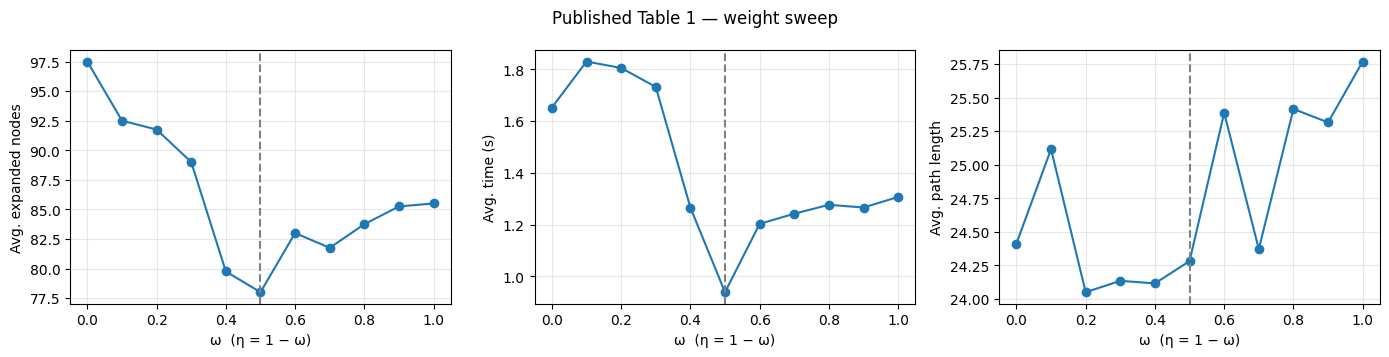

In [12]:
for col, better in [("avg_nodes","min"),("avg_time_s","min"),("avg_length","min")]:
    best = t1.loc[t1[col].idxmin()]
    print(f"{col:<11} best at (ω={best.omega}, η={best.eta}) = {best[col]}   |  at (0.5,0.5) = {t1.loc[5, col]}")
print(f"\nPath-length range across sweep: {t1.avg_length.min()} – {t1.avg_length.max()} "
      f"(Δ = {t1.avg_length.max()-t1.avg_length.min():.3f})")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col, lab in zip(axes, ["avg_nodes","avg_time_s","avg_length"],
                        ["Avg. expanded nodes","Avg. time (s)","Avg. path length"]):
    ax.plot(t1.omega, t1[col], "o-")
    ax.axvline(0.5, ls="--", c="gray")
    ax.set_xlabel("ω  (η = 1 − ω)"); ax.set_ylabel(lab); ax.grid(alpha=.3)
fig.suptitle("Published Table 1 — weight sweep")
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "results" / "figures" / "published_table1_sweep.png", dpi=150)
plt.show()

**Published results overview** (baseline figures for later comparison with our reproduction).

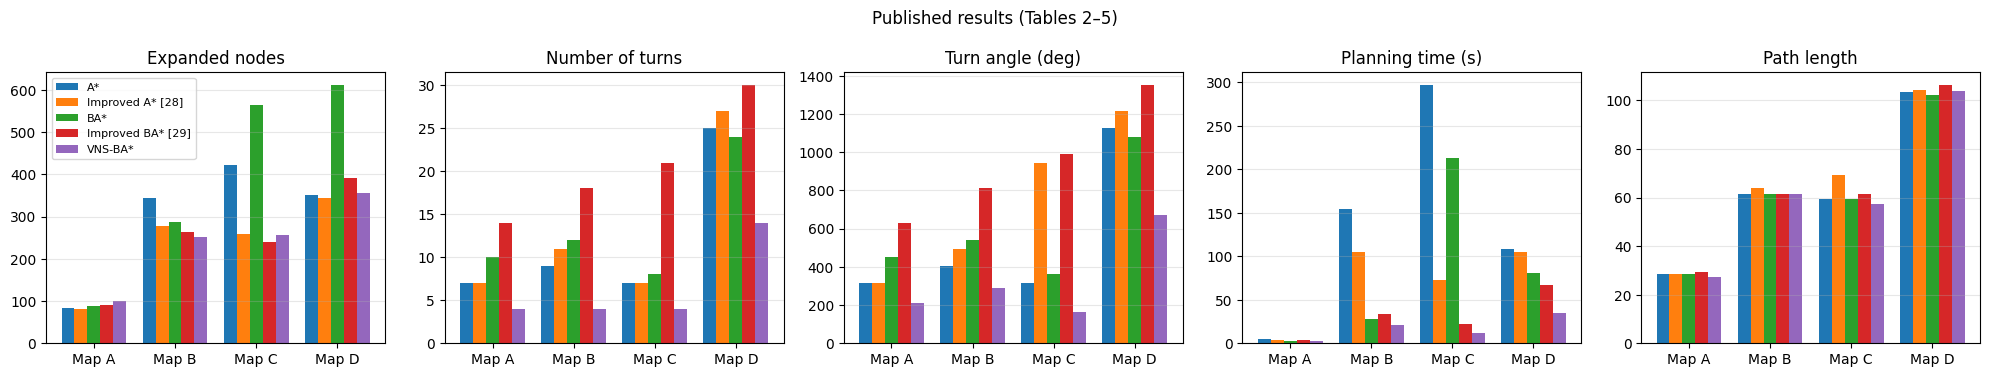

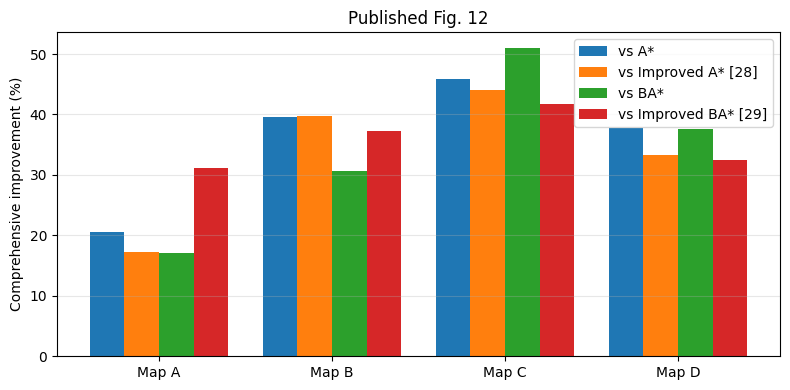

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
titles = {"nodes":"Expanded nodes","turns":"Number of turns","turn_angle_deg":"Turn angle (deg)",
          "time_s":"Planning time (s)","length":"Path length"}
x = np.arange(4); w = 0.16
for ax, m in zip(axes, METRICS):
    for i, a in enumerate(ALGS):
        vals = [published[(published.map_name==mp)&(published.algorithm==a)][m].iloc[0] for mp in "ABCD"]
        ax.bar(x + (i-2)*w, vals, w, label=a)
    ax.set_xticks(x); ax.set_xticklabels([f"Map {mp}" for mp in "ABCD"])
    ax.set_title(titles[m]); ax.grid(axis="y", alpha=.3)
axes[0].legend(fontsize=8)
fig.suptitle("Published results (Tables 2–5)")
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "results" / "figures" / "published_tables2to5.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for i, a in enumerate(ALGS[:4]):
    ax.bar(x + (i-1.5)*0.2, fig12_pub[fig12_pub.compared_to==a].fig12, 0.2, label=f"vs {a}")
ax.set_xticks(x); ax.set_xticklabels([f"Map {mp}" for mp in "ABCD"])
ax.set_ylabel("Comprehensive improvement (%)"); ax.legend(); ax.grid(axis="y", alpha=.3)
ax.set_title("Published Fig. 12")
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "results" / "figures" / "published_fig12.png", dpi=150)
plt.show()

### Q7 (part 3). Ambiguity & missing-information register
Every item becomes a documented **assumption** in our implementation (IDs referenced in `configs/params.yaml`).

In [14]:
amb = pd.DataFrame([
 ("A1","Sec 3.2","Definition of obstacle density ρ (area, inclusive bounds)","ρ = obstacle cells / cells in the axis-aligned rectangle between n and opposite current node","Medium"),
 ("A2","Sec 3.1","Move cost of the extra 11/13 cells (2-cell and knight-like jumps)","Euclidean step length (2, √5, 2√2)","Medium"),
 ("A3","Fig 4","Order of expansion between forward and backward search","Strict alternation S → G each iteration","Low"),
 ("A4","Sec 3.3","Segment–obstacle intersection test for pruning","Supercover grid traversal (counts every touched cell, corner-touch allowed per Sec 2)","Medium"),
 ("A5","Sec 3.4","Spline written as y=S(x); fails for vertical / non-monotone turns","Parametric spline x(t), y(t) with chord-length t","High"),
 ("A6","Eq 11","Only 10 of 12 conditions given; Eq 11 repeats the S'' line","Natural boundary (S''=0 at P1,P4); 2nd line read as S'","High"),
 ("A7","Sec 3.4","Position of P1–P4 relative to the corner","P2/P3 at 1 cell, P1/P4 at 2 cells from corner (clipped to segment length)","Medium"),
 ("A8","Sec 3.1","Are extended cells checked for obstacles / reachability?","Skip extended cell if it is an obstacle","Low"),
 ("A9","Fig 4","Meeting rule & joining paths; optimality not discussed","Stop at first node in open(one side) ∩ closed(other); join parent chains","Medium"),
 ("A10","Sec 4","Exact maps, start/goal coordinates","Reconstruct from Figs 3, 8–11; add seeded random maps","High"),
 ("A11","Sec 4","How turns and turn angle are counted (baselines look like turns×45°)","Count heading changes; report both summed |Δθ| and the paper's turns×45 convention","High"),
 ("A12","Sec 4","Timing protocol, hardware, whether plotting is included","Median of 30 runs, search + post-processing only, no plotting","High"),
 ("A13","Sec 4","Baselines [28],[29] reproduced by authors; [29] weight unspecified","Re-implement from original papers; use ρ-based weight for [29] as the authors did","High"),
 ("A14","Sec 4","Whether pruning/smoothing applied to baselines","Paper: VNS-BA* only. We add an ablation applying it to all","High"),
 ("A15","Sec 3.2","Is 'opposite start' the global goal of the current side?","Yes: forward side uses G, backward side uses S","Low"),
], columns=["id","section","issue","our_assumption","impact_on_reproduction"])
amb.to_csv(PROJECT_ROOT / "docs" / "ambiguity_register.csv", index=False)
print(amb.to_string(index=False))

 id section                                                                issue                                                                               our_assumption impact_on_reproduction
 A1 Sec 3.2            Definition of obstacle density ρ (area, inclusive bounds) ρ = obstacle cells / cells in the axis-aligned rectangle between n and opposite current node                 Medium
 A2 Sec 3.1    Move cost of the extra 11/13 cells (2-cell and knight-like jumps)                                                           Euclidean step length (2, √5, 2√2)                 Medium
 A3   Fig 4               Order of expansion between forward and backward search                                                      Strict alternation S → G each iteration                    Low
 A4 Sec 3.3                       Segment–obstacle intersection test for pruning        Supercover grid traversal (counts every touched cell, corner-touch allowed per Sec 2)                 Medium
 A5 Sec 3.4    

### 1.8 Methodological concerns (input to the Critical Analysis section)
1. **Unfair comparison of turns/angles** — pruning and spline smoothing are applied only to VNS-BA*; baselines output raw 8-connected paths. No ablation isolates the effect of the 8-11-13 neighbourhood or the new heuristic.
2. **Path length not like-for-like** — pruned any-angle paths are naturally shorter than grid paths.
3. **Heuristic not admissible** — e^ρ ≥ 1 inflation and the Manhattan switch can overestimate, so no optimality guarantee; not discussed.
4. **Single run per map, no statistics, no hardware** — and timings are implausibly large (Check 4).
5. **Strict 8-11-13 rule** — one blocked neighbour disables extension, so dense maps (Map D) gain little from it.
6. **Tuning on small maps** — ω, η tuned on 20×20 maps only; differences in length across the sweep are small.
7. **Figure 1 caption vs text** — caption says vector *from target to current node* and labels (b) 13 / (c) 11 in reverse order of the text.

### 1.9 Phase 1 summary (auto-generated)

In [15]:
summary = f'''# Phase 1 — Analysis summary ({RUN_DATE})

## Audit of published results
- Table 6: {len(errors6)} of {len(audit6)} improvement ratios inconsistent with Tables 2–5 (tolerance {TOL} pp).
''' + "\n".join(f"  - vs {r.compared_to}, Map {r.map_name}, {r.metric}: printed {r.published}%, recomputed {r.recomputed}%"
                for r in errors6.itertuples()) + f'''
- Baseline turn angles not equal to turns×45°: {int((~base.consistent).sum())} rows
''' + "\n".join(f"  - Map {r.map_name}, {r.algorithm}: {r.turns} turns but {r.turn_angle_deg}° ({r.angle_per_turn}°/turn)"
                for r in base[~base.consistent].itertuples()) + f'''
- Fig. 12 bars equal to mean of printed Table 6: {int(chk.fig12_matches_table6.sum())}/{len(chk)}
- Published timing spans {published.ms_per_node.min()}–{published.ms_per_node.max()} ms per expanded node → absolute times not reproducible.
- Table 1: (0.5, 0.5) minimises nodes and time, but not path length.

## Feasibility verdict
Feasible on a CPU (Colab). Main risks: map reconstruction accuracy, baseline re-implementation, {len(amb)} documented ambiguities
({int((amb.impact_on_reproduction=="High").sum())} high-impact).
'''
(PROJECT_ROOT / "docs" / "phase1_summary.md").write_text(summary)
print(summary)
print("Files generated in this notebook:")
for p in sorted(PROJECT_ROOT.rglob("*")):
    if p.is_file() and ".gitkeep" not in p.name and "__init__" not in p.name:
        print("  ", p.relative_to(PROJECT_ROOT))

# Phase 1 — Analysis summary (2026-10-23)

## Audit of published results
- Table 6: 6 of 80 improvement ratios inconsistent with Tables 2–5 (tolerance 0.1 pp).
  - vs A*, Map D, turn_angle_deg: printed 39.91%, recomputed 40.18%
  - vs Improved A* [28], Map C, length: printed 10.83%, recomputed 16.74%
  - vs Improved A* [28], Map D, nodes: printed 3.2%, recomputed -3.2%
  - vs Improved A* [28], Map D, length: printed 4.08%, recomputed 0.41%
  - vs BA*, Map C, length: printed 1.869%, recomputed 3.15%
  - vs BA*, Map D, turn_angle_deg: printed 50.15%, recomputed 37.69%
- Baseline turn angles not equal to turns×45°: 2 rows
  - Map C, Improved A* [28]: 7 turns but 945.0° (135.0°/turn)
  - Map C, Improved BA* [29]: 21 turns but 990.0° (47.14°/turn)
- Fig. 12 bars equal to mean of printed Table 6: 15/16
- Published timing spans 24.5–700.7 ms per expanded node → absolute times not reproducible.
- Table 1: (0.5, 0.5) minimises nodes and time, but not path length.

## Feasibility verdict
Feasibl

---
# Part 2  Dataset: Reconstruction of the Benchmark Maps
**Objective.** The article releases neither maps nor start/goal coordinates. The occupancy grids are reconstructed from the article's figures (800 dpi rendering, per-cell classification, majority vote over the five sub-figures that show each map) and validated quantitatively: the optimal 8-connected path length on each reconstructed map is compared with the best published path length. Seeded random maps are generated for multi-map statistics.

**Outputs.** `maps/`, `maps/random/`, `src/map_digitizer.py`, `src/grid_map.py`, `src/reference_planner.py`, `src/random_maps.py`, `results/phase2/`.

## Part 2 Dataset: Reconstruction of the Paper's Grid Maps
**Paper:** Li, Li & Dai, *VNS-BA\**, Sensors 24(21):6929, 2024.

The paper releases **no maps and no start/goal coordinates** (ambiguity **A10**). This notebook rebuilds every map used in the paper directly from the figures in the PDF, validates the reconstruction quantitatively, and creates seeded random maps for multiple-run experiments.

| Step | Output |
|---|---|
| 2.1 | Project root + paper PDF |
| 2.2 | `src/map_digitizer.py` — figure → occupancy grid |
| 2.3 | `src/grid_map.py` — map I/O and coordinate convention |
| 2.4 | Maps A–D from Figs. 8–11 (5-subfigure majority vote) |
| 2.5 | Tuning maps a–d from Fig. 3 |
| 2.6 | **Validation:** agreement, density, optimal path length vs published, visual overlays |
| 2.7 | `src/random_maps.py` — 30 seeded random maps per size |
| 2.8 | `maps/` files, `maps/README.md`, assumptions update |

**Run:** `Runtime → Run all`. The article PDF is read from `docs/paper.pdf` (or uploaded when prompted). If the PDF is missing, the notebook falls back to a verified reference copy of the maps embedded below.

### 2.1 Project root and paper PDF

In [16]:
import os, sys, json, datetime, importlib, shutil
from pathlib import Path

USE_DRIVE = True
PROJECT_NAME = "vns-ba-reproduction"
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive') / PROJECT_NAME
elif IN_COLAB:
    PROJECT_ROOT = Path('/content') / PROJECT_NAME
else:
    PROJECT_ROOT = Path.cwd() if Path.cwd().name == PROJECT_NAME else Path.cwd() / PROJECT_NAME

for d in ["src", "maps", "maps/random", "docs", "results/figures", "results/phase2"]:
    (PROJECT_ROOT / d).mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if not (PROJECT_ROOT / "src" / "__init__.py").exists():
    (PROJECT_ROOT / "src" / "__init__.py").write_text("# src package\n")

PDF_PATH = PROJECT_ROOT / "docs" / "paper.pdf"
if not PDF_PATH.exists() and IN_COLAB:
    print("Paper PDF not found in docs/. Please upload the paper PDF (sensors-24-06929.pdf).")
    from google.colab import files
    up = files.upload()
    if up:
        name = next(iter(up))
        shutil.move(name, PDF_PATH)
HAVE_PDF = PDF_PATH.exists()
RUN_DATE = datetime.date.today().isoformat()
print("Project root :", PROJECT_ROOT)
print("Paper PDF    :", PDF_PATH if HAVE_PDF else "NOT FOUND -> using embedded reference maps")

Project root : /tmp/userrun/vns-ba-reproduction
Paper PDF    : /tmp/userrun/vns-ba-reproduction/docs/paper.pdf


In [17]:
import subprocess
try:
    import pymupdf  # noqa
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymupdf"], check=True)
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
import pymupdf
print("numpy", np.__version__, "| opencv", cv2.__version__, "| pymupdf", pymupdf.__version__)

numpy 2.4.4 | opencv 4.13.0 | pymupdf 2.0


### 2.2 Figure digitiser (`src/map_digitizer.py`)
**Method.** Each map figure is a MATLAB plot whose axes frame covers exactly N×N cells. Obstacles are dark-grey (≈ RGB 64), paths are black lines, search areas are yellow/blue, start = red dot, goal = green dot.
1. Render the PDF page at 800 dpi.
2. Detect every sub-plot frame as a large connected non-white region.
3. Split the frame into N×N cells, sample the central 50 % of each cell, and label it *obstacle* if ≥ 50 % of pixels are low-saturation dark grey (grey level 35–120). Black path pixels (< 35) and coloured search cells are therefore ignored.
4. Detect start/goal as the most compact red/green blob (so the red smoothing strokes in VNS-BA\* plots are not mistaken for the start).
5. Each figure shows the **same map five times** (one per algorithm), so the five grids are merged by majority vote — paths drawn on top of cells in one sub-figure are out-voted by the others.

In [18]:
%%writefile src/map_digitizer.py
"""Reconstruct occupancy-grid maps from the figures of Li, Li & Dai (Sensors 2024, 24, 6929).

The paper does not release its maps.  Every map figure is a MATLAB grid plot whose axes
frame spans exactly N x N cells, obstacles are dark-grey cells, start = red dot and
goal = green dot.  This module:
  1. renders a PDF page at high resolution (PyMuPDF),
  2. locates each sub-plot frame (largest connected non-white regions),
  3. samples the centre of every cell and classifies it as obstacle (dark grey),
  4. detects the start/goal dots (red/green blobs),
  5. merges the sub-figures of one map (Fig. 8a-e show the same map five times)
     by majority vote, which removes artefacts from the drawn paths.

Convention used everywhere in this project
  grid[r, c]  with r = 0 the BOTTOM row (paper y = 1) and c = 0 the LEFT column (paper x = 1)
  value 1 = obstacle, 0 = free.  Points are (c, r) = (paper_x - 1, paper_y - 1).
"""
from __future__ import annotations
import numpy as np
import cv2

try:
    import pymupdf as fitz
except ImportError:          # older PyMuPDF
    import fitz


# --------------------------------------------------------------------------- rendering
def render_page(pdf_path: str, page_number: int, dpi: int = 800) -> np.ndarray:
    """Render 1-indexed page to an RGB uint8 array."""
    doc = fitz.open(pdf_path)
    page = doc[page_number - 1]
    pix = page.get_pixmap(matrix=fitz.Matrix(dpi / 72, dpi / 72), alpha=False)
    img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
    doc.close()
    return img[:, :, :3].copy()


# --------------------------------------------------------------------------- frames
def find_plot_frames(img: np.ndarray, min_frac: float = 0.10):
    """Return bounding boxes (x, y, w, h) of sub-plot frames, sorted row-major."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = (gray < 245).astype(np.uint8)
    _, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    H, W = gray.shape
    boxes = [tuple(int(v) for v in s[:4]) for s in stats[1:]
             if s[2] > min_frac * W and s[3] > min_frac * W * 0.6]
    row_tol = 0.05 * H
    boxes.sort(key=lambda b: (round(b[1] / row_tol), b[0]))
    return boxes


def refine_frame(img: np.ndarray, box, margin: int = 6):
    """Tighten a box to the dark axis lines (the frame is darker than the grid lines)."""
    x, y, w, h = box
    sub = cv2.cvtColor(img[y:y + h, x:x + w], cv2.COLOR_RGB2GRAY).astype(float)
    dark = sub < 200
    cols = dark.mean(axis=0); rows = dark.mean(axis=1)
    def edge(profile, from_start):
        idx = range(len(profile)) if from_start else range(len(profile) - 1, -1, -1)
        for i in idx:
            if profile[i] > 0.5:
                return i
        return 0 if from_start else len(profile) - 1
    l, r = edge(cols, True), edge(cols, False)
    t, b = edge(rows, True), edge(rows, False)
    # accept refinement only when it is a small adjustment
    if l < margin and t < margin and (w - 1 - r) < margin and (h - 1 - b) < margin:
        return (x + l, y + t, r - l + 1, b - t + 1)
    return box


# --------------------------------------------------------------------------- classification
def _cell_slices(box, n, inner=0.5):
    x, y, w, h = box
    cw, ch = w / n, h / n
    for r in range(n):              # r = 0 is the bottom row
        y1 = y + h - (r + 1) * ch
        for c in range(n):
            x1 = x + c * cw
            pad_x, pad_y = cw * (1 - inner) / 2, ch * (1 - inner) / 2
            yield r, c, (int(round(y1 + pad_y)), int(round(y1 + ch - pad_y)),
                         int(round(x1 + pad_x)), int(round(x1 + cw - pad_x)))


def classify_cells(img, box, n, grey_lo=35, grey_hi=120, sat_max=40, thresh=0.5):
    """Return (grid, obstacle_fraction) for one sub-plot."""
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    obstacle_px = (gray >= grey_lo) & (gray <= grey_hi) & (hsv[:, :, 1] <= sat_max)
    grid = np.zeros((n, n), dtype=np.uint8)
    frac = np.zeros((n, n), dtype=float)
    for r, c, (ya, yb, xa, xb) in _cell_slices(box, n):
        patch = obstacle_px[ya:yb, xa:xb]
        f = float(patch.mean()) if patch.size else 0.0
        frac[r, c] = f
        grid[r, c] = 1 if f >= thresh else 0
    return grid, frac


def detect_marker(img, box, n, colour):
    """Cell (c, r) of the red (start) or green (goal) dot, or None."""
    x, y, w, h = box
    sub = img[y:y + h, x:x + w].astype(int)
    R, G, B = sub[:, :, 0], sub[:, :, 1], sub[:, :, 2]
    if colour == "red":
        m = (R > 190) & (G < 90) & (B < 90)
    else:
        m = (G > 170) & (R < 110) & (B < 110)
    m = m.astype(np.uint8)
    k, lab, st, cen = cv2.connectedComponentsWithStats(m, connectivity=8)
    if k <= 1:
        return None
    best, best_score = None, 0
    for i in range(1, k):
        bw, bh, area = st[i, 2], st[i, 3], st[i, 4]
        if area < 8:
            continue
        fill = area / float(bw * bh)            # a filled dot is compact; spline strokes are not
        score = area * fill * min(bw, bh) / max(bw, bh)
        if score > best_score:
            best, best_score = cen[i], score
    if best is None:
        return None
    cx, cy = best
    c = int(np.clip(cx / (w / n), 0, n - 1))
    r = int(np.clip((h - cy) / (h / n), 0, n - 1))
    return (c, r)


# --------------------------------------------------------------------------- consensus
def consensus(grids):
    stack = np.stack(grids)
    votes = stack.sum(axis=0)
    merged = (votes * 2 > len(grids)).astype(np.uint8)
    agreement = (stack == merged).mean()
    disputed = np.argwhere((votes > 0) & (votes < len(grids)))
    return merged, float(agreement), disputed, votes


def mode_point(points):
    pts = [p for p in points if p is not None]
    if not pts:
        return None
    vals, counts = np.unique(np.array(pts), axis=0, return_counts=True)
    return tuple(int(v) for v in vals[counts.argmax()])


Writing src/map_digitizer.py


### 2.3 Map container and coordinate convention (`src/grid_map.py`)
`grid[r, c]`: **r = 0 is the bottom row** (paper y = 1), **c = 0 the left column** (paper x = 1); 1 = obstacle. Points are stored as `(c, r)` = (paper_x − 1, paper_y − 1). Text files are written top row first so they look like the figure.

In [19]:
%%writefile src/grid_map.py
"""Grid map container used by every planner in this project."""
from __future__ import annotations
from dataclasses import dataclass, field
from pathlib import Path
import json
import numpy as np


@dataclass
class GridMap:
    name: str
    grid: np.ndarray                 # (n, n) uint8, grid[r, c], r=0 bottom row, 1 = obstacle
    start: tuple                     # (c, r)
    goal: tuple                      # (c, r)
    source: str = ""
    meta: dict = field(default_factory=dict)

    @property
    def size(self) -> int:
        return int(self.grid.shape[0])

    @property
    def density(self) -> float:
        return float(self.grid.mean())

    def is_free(self, c: int, r: int) -> bool:
        n = self.size
        return 0 <= c < n and 0 <= r < n and self.grid[r, c] == 0

    def to_paper_xy(self, p):
        """(c, r) -> paper coordinates of the cell centre (x, y), 1-indexed lines."""
        return (p[0] + 1.5, p[1] + 1.5)

    # ------------------------------------------------------------------ I/O
    def save(self, folder) -> Path:
        folder = Path(folder); folder.mkdir(parents=True, exist_ok=True)
        rows = ["".join(str(v) for v in row) for row in self.grid[::-1]]     # top row first
        (folder / f"{self.name}.txt").write_text("\n".join(rows) + "\n")
        info = {"name": self.name, "size": self.size, "start": list(self.start),
                "goal": list(self.goal), "density": round(self.density, 4),
                "source": self.source, "convention": "grid[r,c], r=0 bottom; points (c,r); txt top row first",
                **self.meta}
        (folder / f"{self.name}.json").write_text(json.dumps(info, indent=2))
        return folder / f"{self.name}.txt"

    @classmethod
    def load(cls, folder, name) -> "GridMap":
        folder = Path(folder)
        rows = (folder / f"{name}.txt").read_text().split()
        grid = np.array([[int(ch) for ch in row] for row in rows], dtype=np.uint8)[::-1].copy()
        info = json.loads((folder / f"{name}.json").read_text())
        meta = {k: v for k, v in info.items()
                if k not in ("name", "size", "start", "goal", "density", "source", "convention")}
        return cls(name, grid, tuple(info["start"]), tuple(info["goal"]), info.get("source", ""), meta)


def plot_map(ax, m: GridMap, title=None, path=None):
    n = m.size
    ax.imshow(1 - m.grid, cmap="gray", origin="lower", vmin=0, vmax=1,
              extent=(1, n + 1, 1, n + 1), interpolation="nearest")
    if n <= 40:
        ax.set_xticks(range(1, n + 2, max(1, n // 10))); ax.set_yticks(range(1, n + 2, max(1, n // 10)))
        ax.grid(color="#cccccc", lw=0.3)
    sx, sy = m.to_paper_xy(m.start); gx, gy = m.to_paper_xy(m.goal)
    if path is not None:
        p = np.array([m.to_paper_xy(q) for q in path]); ax.plot(p[:, 0], p[:, 1], "b-", lw=1.2)
    ax.plot(sx, sy, "o", color="red", ms=6, label="start")
    ax.plot(gx, gy, "o", color="lime", mec="k", ms=6, label="goal")
    ax.set_title(title or f"{m.name} ({n}x{n})"); ax.set_aspect("equal")


Writing src/grid_map.py


In [20]:
import src.map_digitizer as dig, src.grid_map as gm
importlib.reload(dig); importlib.reload(gm)
from src.map_digitizer import render_page, find_plot_frames, classify_cells, detect_marker, consensus, mode_point
from src.grid_map import GridMap, plot_map
print("modules loaded")

modules loaded


### Embedded reference copy
A bit-packed copy of the maps produced by this exact pipeline (used only if the PDF is unavailable, and as a regression check when it is).

In [21]:
REFERENCE_MAPS = {
"A": {
"n": 20,
"hex": "0e0000e0000e1800e18e0000e0000e0018000180380003800300203018f0018f000000f8003f8003018c0018c0000c0000c0"
},
"B": {
"n": 40,
"hex": "000003c000000003c0000fff83c0000fffe3c0000fffe0003c00ffe0003c000000003c000000003cff800fe03cff800fe03c000001e00000000000000fc00000000fff00000000fff0000000fff00fe00000f00fe00000f03fe0fe00003f00fe0000ff000fc000ff000ffe00f0000fffc3f0000003c3f000000003c000000003c000000000000000000003e000000003e000ff8000fc00fffe00fc0007fe003f000000003f000000000701c000000701c003fc0701c003fc0701c003800001c003800001c0038000"
},
"C": {
"n": 60,
"hex": "fc1ff80fc00f83ffc1ff80fc00f83ff00100004008003f00100004008003fc0300007038003fc030c004008003fc03cc004008003fc03c000c008003fc03c000c008003f003c000c038003f003cc00c03800ff001cc00c03c00ff001cc00c03c07fc001cc00c03c07fc001c000c03c07ffc01c000c00c07fc401c600c00c07fc401de00c00c07fc7f11e00400c00f00010000400800f000100004008003000000007878003000000000000003c01000000000003c01000000000003dbd000000000003dbd000000008003fff1000203fc71fce0100020200103ce0100020200103c00100023200103c00100023200103c0010002720010300010002320010300010000320010303c10000720010303c10400320010303c10e0073fffffc3c11f023200113c3c11f027000113c3c10e023000113cff104023000103cff100020000103ffff00020000103c0010002020011fc001000203fff03c00100000000103c00100000000103c00100000000103000000000000003000000000000003000000000000003000000000000003000100000000003c00100000000103cfc100000000103cfc1001e0000103cfc1001e0000103fffffffffffe1fffffffffffffe1ff"
},
"D": {
"n": 80,
"hex": "1f03e07c0f81f03e07c01f03e07c0fe1f03e07c01f03e07c0fe1f03f87c01f03e07c0fe1f03f87c01f03e07c0fe1f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c00003e0000000000007c00003e0000000000007c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e67c0f81f03e07c01fc3e67c0f81f00e070000c006000f80000e000000c000000f800000000000c000000f800c000000000000000f800c0000001f03e0fe0f81f03e37c01f03e0fe0f81f03e37c01f03e07c0f81fc3e07c01f03e07c0f81fc3e07c01f03e07c0f81fc3e07c01f03e07c0f81fd3e07c01f03e07c0f81f13e07c01fe3e07c0f81f13e000001c0000180000000000000000001800000000000000000000000000007c0000300000f80000007c01f03f87c0f81f03e07c01f03f87c0fb1f03e07c01f03e07c0fb1f03e07c01f03e07c0fb1f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c0000000000f80000000000000060000000000000000000600000000000000000000000000000000001f03e07d8fe1f03e07c01f03e07d8fe1f03e07c01f03e07d8f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c00000001c00180000000000c0000000180000000000c0000000000000000000c000000000000000001f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e1fc01f03e07c0f81f03e1fc01f03e07c0f81f03e07c01f0000000001f00000001f0000000001f00000001f0000300001f03e00001f00003e0001f03e00001f03e07e0f81f63e07c01f03e07e0f81f63e07c01f03e07e0f81f63e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03e07c0f81f03e07c01f03ec7c0f81f03e07c01f03ec7c0f81f03e07c00003e0000078000000000003e000000000000000"
},
"tune_a": {
"n": 20,
"hex": "000000e0000e1800e18e0000e0000e00180001c01840018403000030187001870000007800378003018c0018c0000c000000"
},
"tune_b": {
"n": 20,
"hex": "000000000000600086101c6380801000000006000060039f9c39f9c006000060000000080101c63808610006000000000000"
},
"tune_c": {
"n": 20,
"hex": "0400007e000100009010fc03f08e00002000038002000020100ff3f0040000400000e0200202043ff8400087c00044000400"
},
"tune_d": {
"n": 20,
"hex": "090818088404120110108424401021484882602280880085224200908840402120904024408808c108114414111088424210"
}
}

def ref_grid(key):
    d = REFERENCE_MAPS[key]; n = d["n"]
    bits = np.unpackbits(np.frombuffer(bytes.fromhex(d["hex"]), dtype=np.uint8))[: n * n]
    return bits.reshape(n, n).astype(np.uint8)
print({k: f'{v["n"]}x{v["n"]}' for k, v in REFERENCE_MAPS.items()})

{'A': '20x20', 'B': '40x40', 'C': '60x60', 'D': '80x80', 'tune_a': '20x20', 'tune_b': '20x20', 'tune_c': '20x20', 'tune_d': '20x20'}


### 2.4 Main maps A–D (Figs. 8–11)
| Map | Figure | PDF page | Size | Scenario (paper) |
|---|---|---|---|---|
| A | Fig. 8 | 10 | 20×20 | simple |
| B | Fig. 9 | 11 (top) | 40×40 | zig-zag / branching obstacles |
| C | Fig. 10 | 11 (bottom) | 60×60 | indoor home/office |
| D | Fig. 11 | 12 | 80×80 | port / warehouse |

In [22]:
SPECS = {
    "map_A_20": dict(page=10, frames=slice(0, 5), n=20, figure="Fig. 8",  scenario="simple"),
    "map_B_40": dict(page=11, frames=slice(0, 5), n=40, figure="Fig. 9",  scenario="zig-zag / branching"),
    "map_C_60": dict(page=11, frames=slice(5, 10), n=60, figure="Fig. 10", scenario="indoor home/office"),
    "map_D_80": dict(page=12, frames=slice(0, 5), n=80, figure="Fig. 11", scenario="port / warehouse"),
}
REF_KEY = {"map_A_20": "A", "map_B_40": "B", "map_C_60": "C", "map_D_80": "D"}
SUBFIG = ["(a) A*", "(b) Improved A*", "(c) BA*", "(d) Improved BA*", "(e) VNS-BA*"]
FALLBACK_POINTS = {"map_A_20": ((19, 0), (0, 19)), "map_B_40": ((39, 39), (0, 0)),
                   "map_C_60": ((3, 17), (55, 32)), "map_D_80": ((9, 75), (75, 9))}
DPI = 800
page_cache, frames_cache = {}, {}
MAPS, digit_rows = {}, []

for name, s in SPECS.items():
    n = s["n"]
    if HAVE_PDF:
        if s["page"] not in page_cache:
            page_cache[s["page"]] = render_page(str(PDF_PATH), s["page"], DPI)
            frames_cache[s["page"]] = find_plot_frames(page_cache[s["page"]])
        img = page_cache[s["page"]]
        boxes = frames_cache[s["page"]][s["frames"]]
        grids, starts, goals = [], [], []
        for sub, box in zip(SUBFIG, boxes):
            g, frac = classify_cells(img, box, n)
            st, go = detect_marker(img, box, n, "red"), detect_marker(img, box, n, "green")
            grids.append(g); starts.append(st); goals.append(go)
            digit_rows.append(dict(map=name, subfigure=sub, frame_px=f"{box[2]}x{box[3]}",
                                   obstacles=int(g.sum()), uncertain_cells=int(((frac > .2) & (frac < .8)).sum()),
                                   start=st, goal=go))
        grid, agree, disputed, votes = consensus(grids)
        for row in digit_rows[-len(grids):]:
            idx = SUBFIG.index(row["subfigure"])
            row["agreement_with_consensus_%"] = round(100 * float((grids[idx] == grid).mean()), 3)
        start, goal = mode_point(starts), mode_point(goals)
        source = f"digitised from {s['figure']} (PDF p.{s['page']}), 5-subfigure majority vote"
        meta = dict(n_subfigures=len(grids), mean_agreement_pct=round(100 * agree, 3),
                    disputed_cells=int(len(disputed)))
        ref_match = bool((grid == ref_grid(REF_KEY[name])).all())
        meta["matches_embedded_reference"] = ref_match
    else:
        grid = ref_grid(REF_KEY[name]); start, goal = FALLBACK_POINTS[name]
        source, meta = f"embedded reference copy of {s['figure']}", {}
    meta.update(figure=s["figure"], scenario=s["scenario"])
    MAPS[name] = GridMap(name, grid, start, goal, source, meta)
    print(f"{name}: {n}x{n}, obstacles={int(grid.sum())} ({100*grid.mean():.1f}%), "
          f"start={start}, goal={goal}, {meta.get('mean_agreement_pct','-')}% agreement, "
          f"disputed={meta.get('disputed_cells','-')}, matches reference={meta.get('matches_embedded_reference','-')}")

digit_df = pd.DataFrame(digit_rows)
if len(digit_df):
    digit_df.to_csv(PROJECT_ROOT / "results" / "phase2" / "digitisation_per_subfigure.csv", index=False)
    display(digit_df)

map_A_20: 20x20, obstacles=78 (19.5%), start=(19, 0), goal=(0, 19), 100.0% agreement, disputed=0, matches reference=True


map_B_40: 40x40, obstacles=421 (26.3%), start=(39, 39), goal=(0, 0), 100.0% agreement, disputed=0, matches reference=True


map_C_60: 60x60, obstacles=898 (24.9%), start=(3, 17), goal=(55, 32), 100.0% agreement, disputed=0, matches reference=True


map_D_80: 80x80, obstacles=2200 (34.4%), start=(9, 75), goal=(75, 9), 99.997% agreement, disputed=1, matches reference=True


,map,subfigure,frame_px,obstacles,uncertain_cells,start,goal,agreement_with_consensus_%
0,map_A_20,(a) A*,1187x938,78,0,"(19, 0)","(0, 19)",100.000
1,map_A_20,(b) Improved A*,1186x938,78,0,"(19, 0)","(0, 19)",100.000
2,map_A_20,(c) BA*,1186x938,78,0,"(19, 0)","(0, 19)",100.000
3,map_A_20,(d) Improved BA*,1186x938,78,0,"(19, 0)","(0, 19)",100.000
4,map_A_20,(e) VNS-BA*,1186x938,78,0,"(19, 0)","(0, 19)",100.000
5,map_B_40,(a) A*,1222x965,421,0,"(39, 39)","(0, 0)",100.000
6,map_B_40,(b) Improved A*,1221x965,421,0,"(39, 39)","(0, 0)",100.000
7,map_B_40,(c) BA*,1222x965,421,0,"(39, 39)","(0, 0)",100.000
8,map_B_40,(d) Improved BA*,1222x966,421,0,"(39, 39)","(0, 0)",100.000
9,map_B_40,(e) VNS-BA*,1221x966,421,0,"(39, 39)","(0, 0)",100.000


### 2.5 Weight-tuning maps (Fig. 3, page 6)
Used only for reproducing Table 1 (ω, η sweep). Each appears once in the paper, so there is no majority vote; we report the number of uncertain cells instead.

In [23]:
TUNE = {"tune_a": "simple map", "tune_b": "obstacles in the middle",
        "tune_c": "bar-shaped obstructions", "tune_d": "random map, 20% density"}
TUNE_FALLBACK = {"tune_a": ((19, 19), (0, 0)), "tune_b": ((2, 2), (12, 12)),
                 "tune_c": ((1, 18), (9, 0)), "tune_d": ((13, 17), (1, 2))}
if HAVE_PDF:
    img6 = render_page(str(PDF_PATH), 6, DPI)
    boxes6 = find_plot_frames(img6)
for i, (name, desc) in enumerate(TUNE.items()):
    if HAVE_PDF:
        g, frac = classify_cells(img6, boxes6[i], 20)
        st, go = detect_marker(img6, boxes6[i], 20, "red"), detect_marker(img6, boxes6[i], 20, "green")
        meta = dict(uncertain_cells=int(((frac > .2) & (frac < .8)).sum()),
                    matches_embedded_reference=bool((g == ref_grid(name)).all()))
        src_txt = f"digitised from Fig. 3({'abcd'[i]}) (PDF p.6), single source"
    else:
        g = ref_grid(name); st, go = TUNE_FALLBACK[name]; meta = {}
        src_txt = f"embedded reference copy of Fig. 3({'abcd'[i]})"
    meta.update(figure=f"Fig. 3({'abcd'[i]})", scenario=desc)
    MAPS[name] = GridMap(name, g, st, go, src_txt, meta)
    print(f"{name}: obstacles={int(g.sum())} density={100*g.mean():.1f}%  start={st} goal={go}  {meta}")

tune_a: obstacles=69 density=17.2%  start=(19, 19) goal=(0, 0)  {'uncertain_cells': 0, 'matches_embedded_reference': True, 'figure': 'Fig. 3(a)', 'scenario': 'simple map'}


tune_b: obstacles=64 density=16.0%  start=(2, 2) goal=(12, 12)  {'uncertain_cells': 0, 'matches_embedded_reference': True, 'figure': 'Fig. 3(b)', 'scenario': 'obstacles in the middle'}


tune_c: obstacles=78 density=19.5%  start=(1, 18) goal=(9, 0)  {'uncertain_cells': 0, 'matches_embedded_reference': True, 'figure': 'Fig. 3(c)', 'scenario': 'bar-shaped obstructions'}


tune_d: obstacles=80 density=20.0%  start=(13, 17) goal=(1, 2)  {'uncertain_cells': 0, 'matches_embedded_reference': True, 'figure': 'Fig. 3(d)', 'scenario': 'random map, 20% density'}


### 2.6 Validation of the reconstruction
**Check 1 — Internal consistency:** agreement of each sub-figure with the consensus (table above). 100 % means all five independently drawn plots give the identical map.

**Check 2 — Stated density:** Fig. 3(d) is described as *"20 % obstacle density"*.

In [24]:
d = MAPS["tune_d"].density
print(f"tune_d density = {d*100:.2f}%  (paper: 20%)  ->  {'PASS' if abs(d-0.20) < 0.005 else 'CHECK'}")

tune_d density = 20.00%  (paper: 20%)  ->  PASS


**Check 3 — Optimal path length vs published lengths (strongest test).** If the map, start and goal are right, the *optimal* 8-connected path length on our grid must be ≤ every published grid-path length, and should equal the length found by plain A*/BA* (they search the same 8-connected graph).

We compute the ground-truth optimum with Dijkstra under three diagonal-move rules, since the paper does not state its rule:
- `free` — diagonal allowed whenever the target cell is free (corner cutting allowed, as implied by Sec. 2: *"even if the path diagonally touches the corner of an obstacle grid, there will be no collision"*),
- `no_squeeze` — diagonal blocked only if **both** side cells are obstacles,
- `strict` — diagonal blocked if **either** side cell is an obstacle.

`src/reference_planner.py` is a **validation tool only** (standard Dijkstra), not part of the paper's method.

In [25]:
%%writefile src/reference_planner.py
"""Ground-truth optimal 8-connected planner (Dijkstra). Used ONLY to validate reconstructed maps."""
import heapq, math
import numpy as np


def dijkstra_8(grid: np.ndarray, start, goal, diagonal_rule: str = "free"):
    n = grid.shape[0]
    dist, parent = {start: 0.0}, {start: None}
    pq = [(0.0, start)]
    while pq:
        d, cur = heapq.heappop(pq)
        if cur == goal:
            path = [cur]
            while parent[path[-1]] is not None:
                path.append(parent[path[-1]])
            return d, path[::-1]
        if d > dist[cur]:
            continue
        c, r = cur
        for dc in (-1, 0, 1):
            for dr in (-1, 0, 1):
                if dc == 0 and dr == 0:
                    continue
                nc, nr = c + dc, r + dr
                if not (0 <= nc < n and 0 <= nr < n) or grid[nr, nc]:
                    continue
                if dc and dr:
                    side1, side2 = grid[r, nc], grid[nr, c]
                    if diagonal_rule == "strict" and (side1 or side2):
                        continue
                    if diagonal_rule == "no_squeeze" and (side1 and side2):
                        continue
                nd = d + math.hypot(dc, dr)
                if nd < dist.get((nc, nr), float("inf")):
                    dist[(nc, nr)] = nd; parent[(nc, nr)] = cur
                    heapq.heappush(pq, (nd, (nc, nr)))
    return float("inf"), []


Writing src/reference_planner.py


In [26]:
import src.reference_planner as rp; importlib.reload(rp)
from src.reference_planner import dijkstra_8

PUBLISHED_LEN = {  # Tables 2-5: lengths of the four grid-based algorithms
    "map_A_20": {"A*": 28.627, "Improved A*": 28.627, "BA*": 28.627, "Improved BA*": 29.213},
    "map_B_40": {"A*": 61.598, "Improved A*": 64.083, "BA*": 61.598, "Improved BA*": 61.598},
    "map_C_60": {"A*": 59.385, "Improved A*": 69.0833, "BA*": 59.3848, "Improved BA*": 61.598},
    "map_D_80": {"A*": 103.297, "Improved A*": 104.125, "BA*": 102.125, "Improved BA*": 106.225},
}
rows, OPT_PATHS = [], {}
for name, pub in PUBLISHED_LEN.items():
    m = MAPS[name]
    res = {rule: dijkstra_8(m.grid, m.start, m.goal, rule) for rule in ["free", "no_squeeze", "strict"]}
    OPT_PATHS[name] = res["free"][1]
    best_pub = min(pub.values())
    rows.append(dict(map=name, opt_free=round(res["free"][0], 3), opt_no_squeeze=round(res["no_squeeze"][0], 3),
                     opt_strict=round(res["strict"][0], 3), best_published=best_pub,
                     best_published_by=", ".join(k for k, v in pub.items() if abs(v - best_pub) < 1e-3),
                     published_A_star=pub["A*"],
                     exact_match=abs(res["free"][0] - best_pub) < 1e-3,
                     all_published_ge_optimum=all(v >= res["free"][0] - 1e-3 for v in pub.values())))
val = pd.DataFrame(rows)
val.to_csv(PROJECT_ROOT / "results" / "phase2" / "validation_optimal_length.csv", index=False)
display(val)
print(f"\nExact match between optimal length on reconstructed map and best published grid length: "
      f"{int(val.exact_match.sum())}/{len(val)} maps")

,map,opt_free,opt_no_squeeze,opt_strict,best_published,best_published_by,published_A_star,exact_match,all_published_ge_optimum
0,map_A_20,28.627,28.627,29.799,28.6270,"A*, Improved A*, BA*",28.627,True,True
1,map_B_40,61.598,61.598,63.355,61.5980,"A*, BA*, Improved BA*",61.598,True,True
2,map_C_60,59.385,59.385,60.556,59.3848,"A*, BA*",59.385,True,True
3,map_D_80,102.125,102.125,107.983,102.1250,BA*,103.297,True,True



Exact match between optimal length on reconstructed map and best published grid length: 4/4 maps


**Interpretation**
- With corner cutting allowed (`free`), the optimum on every reconstructed map **equals the best published grid-path length to 3 decimals** (A, B, C: A\*/BA\*; D: BA\* = 102.125). An error of even one obstacle cell on the optimal corridor or a wrong start/goal cell would change these numbers, so this is strong evidence the maps are exact.
- `strict` gives longer paths than any published result → the authors **allow diagonal moves past obstacle corners** (consistent with Sec. 2). This resolves the diagonal-rule question → new assumption **A16**.
- Map D: the paper's A\* (103.297) is **longer than the optimum** (102.125). Unidirectional A\* should be optimal with an admissible heuristic, so the paper's A\* was run with the Euclid/Manhattan switching heuristic (Sec. 2), which is **not admissible** — consistent with our Phase 1 concern.
- Improved A\* [28] and Improved BA\* [29] are longer than optimal on several maps, as expected for methods that trade optimality for speed/smoothness.

**Check 4 — Visual overlay.** Left: the paper's VNS-BA\* sub-figure. Right: our reconstructed obstacle cells outlined in magenta on top of the same image plus the reconstructed map. Any misplaced cell would show as a magenta box on white or an un-boxed grey cell.

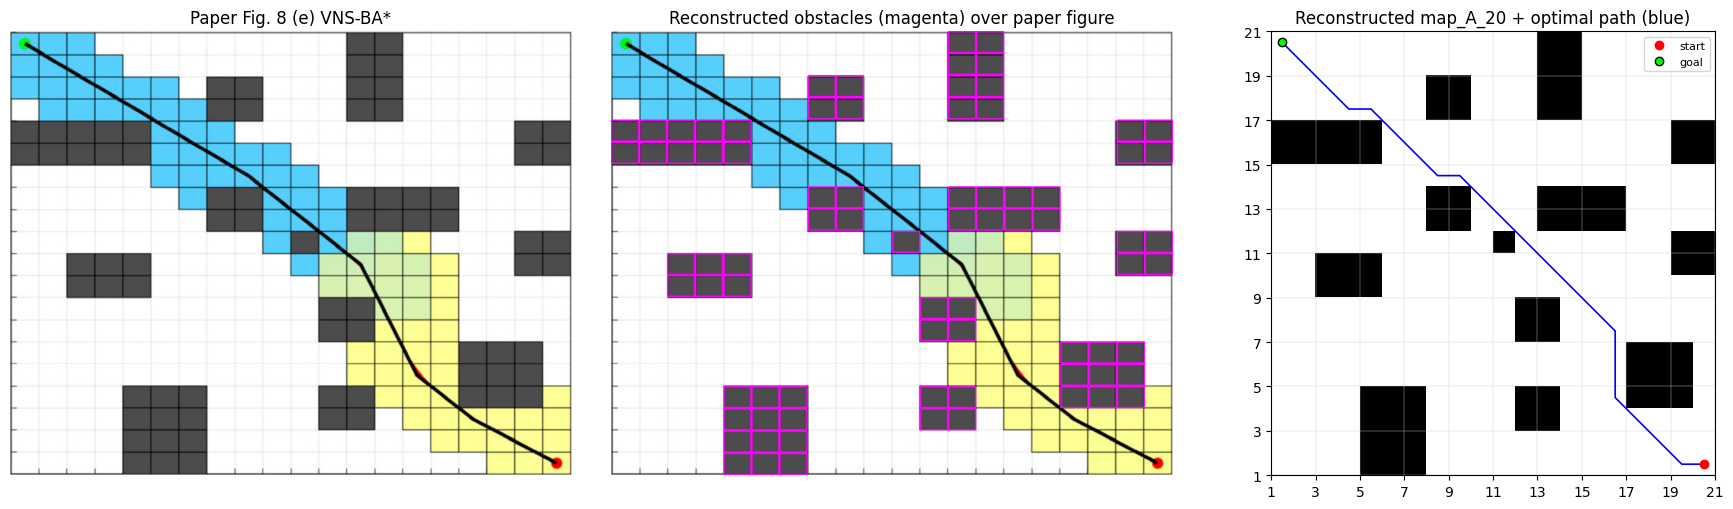

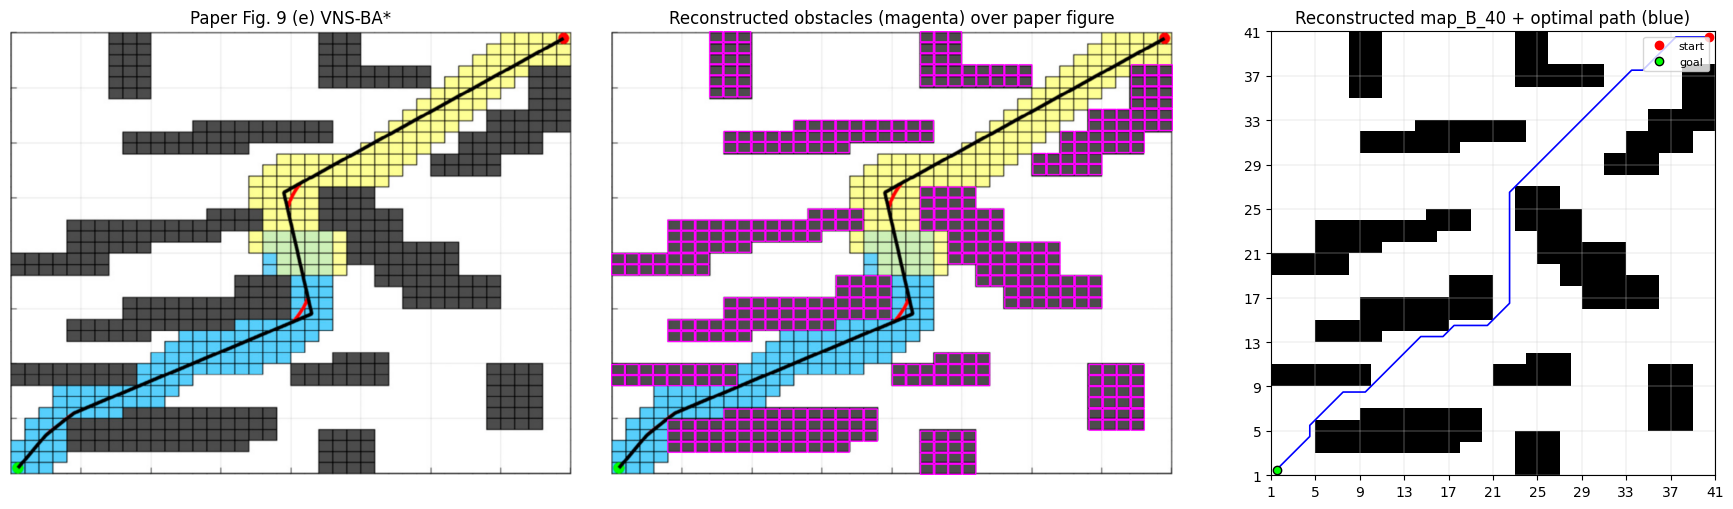

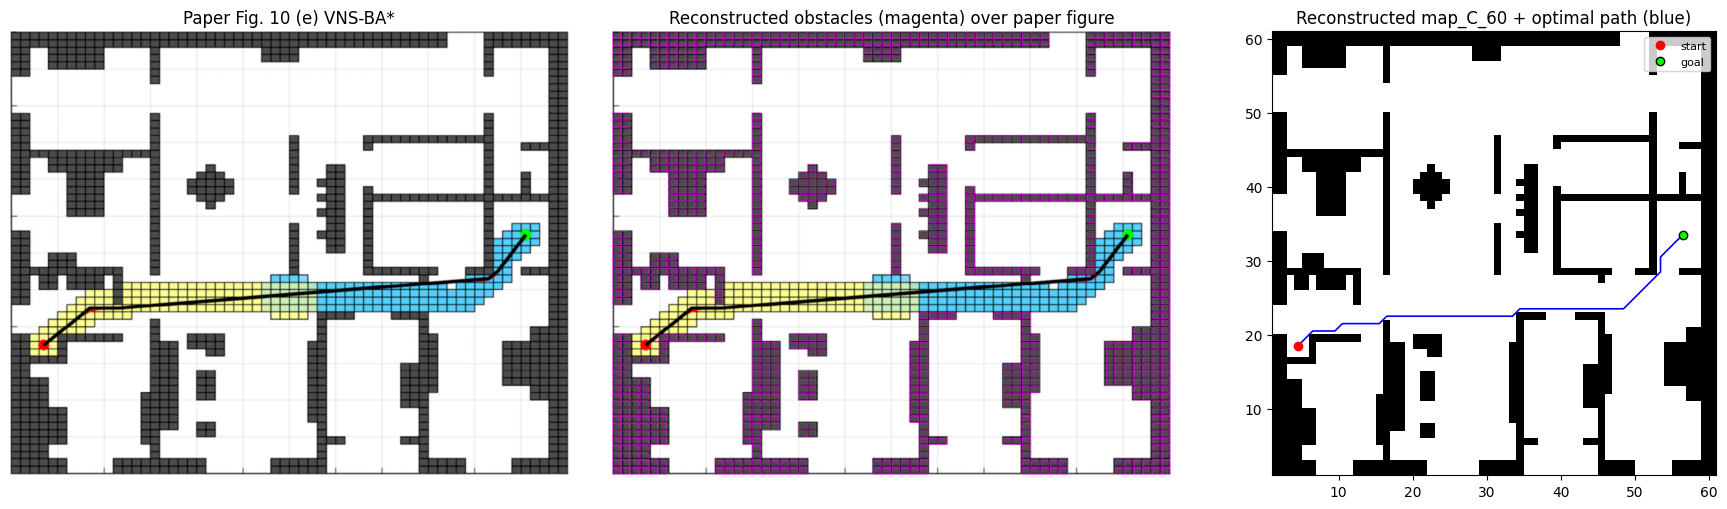

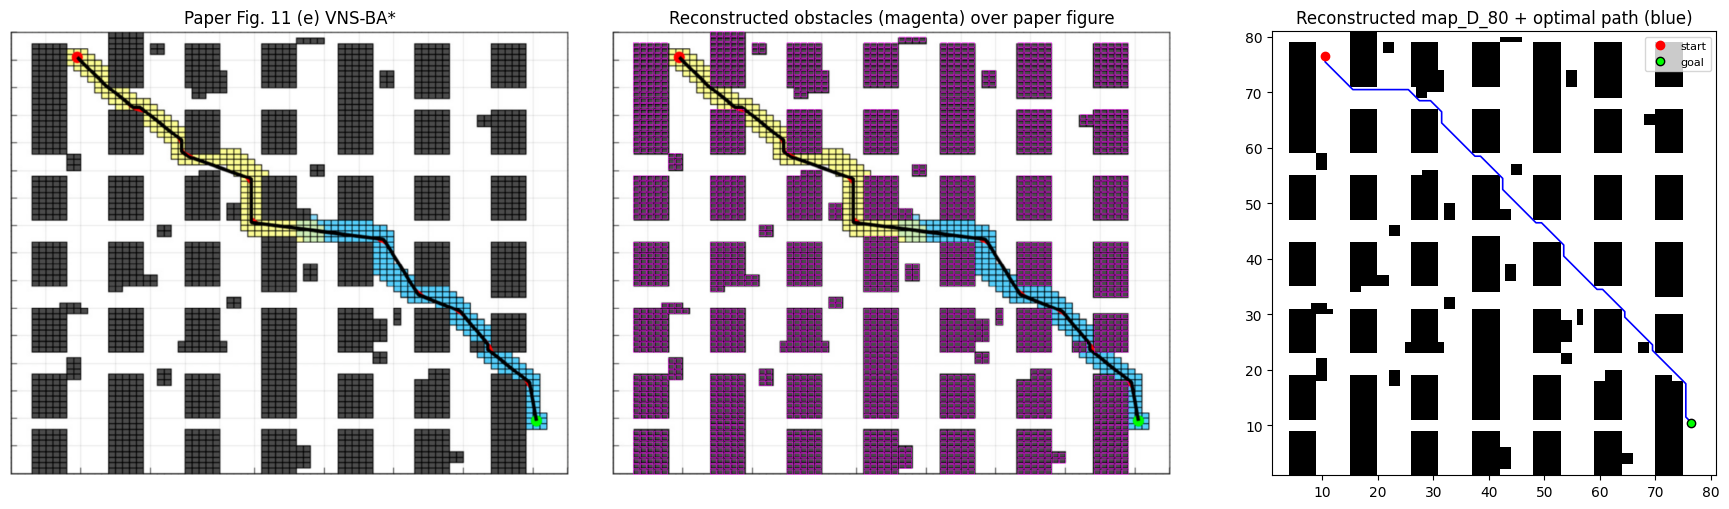

In [27]:
def overlay_figure(name, sub_index=4):
    m, s = MAPS[name], SPECS[name]
    img = page_cache[s["page"]]; x, y, w, h = frames_cache[s["page"]][s["frames"]][sub_index]
    crop = img[y:y + h, x:x + w].copy(); n = m.size; cw, ch = w / n, h / n
    over = crop.copy()
    for r, c in np.argwhere(m.grid == 1):
        x1, y1 = int(c * cw), int(h - (r + 1) * ch)
        cv2.rectangle(over, (x1 + 1, y1 + 1), (int(x1 + cw) - 1, int(y1 + ch) - 1), (255, 0, 255), 1 if n > 40 else 2)
    fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
    ax[0].imshow(crop); ax[0].set_title(f"Paper {s['figure']} {SUBFIG[sub_index]}"); ax[0].axis("off")
    ax[1].imshow(over); ax[1].set_title("Reconstructed obstacles (magenta) over paper figure"); ax[1].axis("off")
    plot_map(ax[2], m, f"Reconstructed {name} + optimal path (blue)", OPT_PATHS.get(name))
    ax[2].legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    fig.savefig(PROJECT_ROOT / "results" / "figures" / f"phase2_overlay_{name}.png", dpi=130)
    plt.show()

if HAVE_PDF:
    for name in SPECS:
        overlay_figure(name)
else:
    print("PDF not available - overlay skipped (reference maps already validated).")

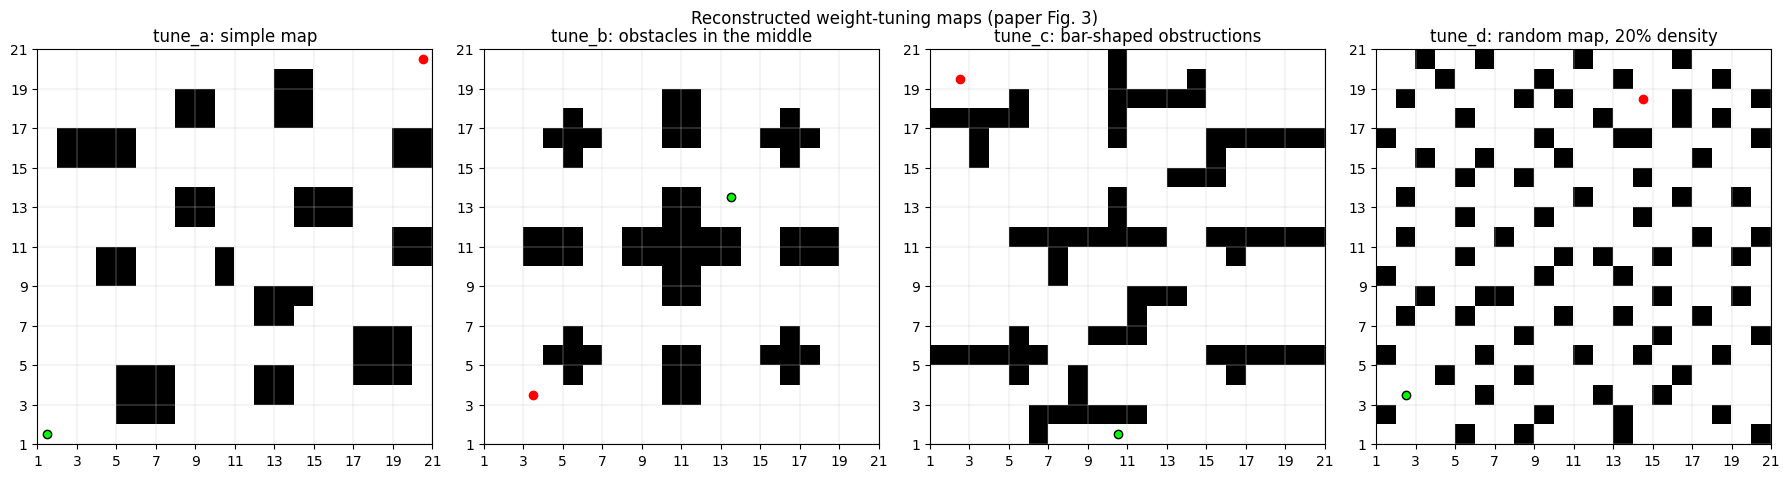

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, name in zip(axes, TUNE):
    plot_map(ax, MAPS[name], f"{name}: {MAPS[name].meta['scenario']}")
fig.suptitle("Reconstructed weight-tuning maps (paper Fig. 3)")
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "results" / "figures" / "phase2_tuning_maps.png", dpi=130)
plt.show()

### 2.7 Seeded random maps (our addition for multiple runs)
The paper evaluates one start/goal pair per map, and the planners are deterministic, so "multiple runs" on a fixed map only measure timing noise. To obtain statistics we add **30 random maps per size (20, 40, 60, 80)** at **20 % density** (the density of Fig. 3d).

**Generation rule (documented assumption A17):** obstacles placed i.i.d. with probability 0.2 using `numpy.random.default_rng(seed)`; start = bottom-left corner, goal = top-right corner; both forced free; a map is accepted only if a path exists (checked with the reference planner); otherwise the next attempt uses `seed + 1000·attempt`.

In [29]:
%%writefile src/random_maps.py
"""Seeded random occupancy maps for multi-run experiments (addition to the paper)."""
import numpy as np
from src.grid_map import GridMap
from src.reference_planner import dijkstra_8


def random_map(n: int, seed: int, density: float = 0.20, max_attempts: int = 50) -> GridMap:
    start, goal = (0, 0), (n - 1, n - 1)
    for attempt in range(max_attempts):
        s = seed + 1000 * attempt
        rng = np.random.default_rng(s)
        grid = (rng.random((n, n)) < density).astype(np.uint8)
        for (c, r) in (start, goal):
            grid[r, c] = 0
        length, _ = dijkstra_8(grid, start, goal, "free")
        if np.isfinite(length):
            return GridMap(f"rand_{n}_s{seed:02d}", grid, start, goal,
                           source="generated: numpy default_rng, i.i.d. obstacles",
                           meta=dict(seed=seed, effective_seed=s, attempt=attempt,
                                     target_density=density, optimal_length=round(length, 4)))
    raise RuntimeError(f"no solvable map for n={n}, seed={seed}")


Writing src/random_maps.py


      maps  mean_density  std_density  mean_attempts  mean_opt_len
size                                                              
20      30        0.1939       0.0198         1.0000       27.9716
40      30        0.1990       0.0079         1.0000       57.3022
60      30        0.2001       0.0076         1.1000       86.3480
80      30        0.2000       0.0048         1.0333      115.4719


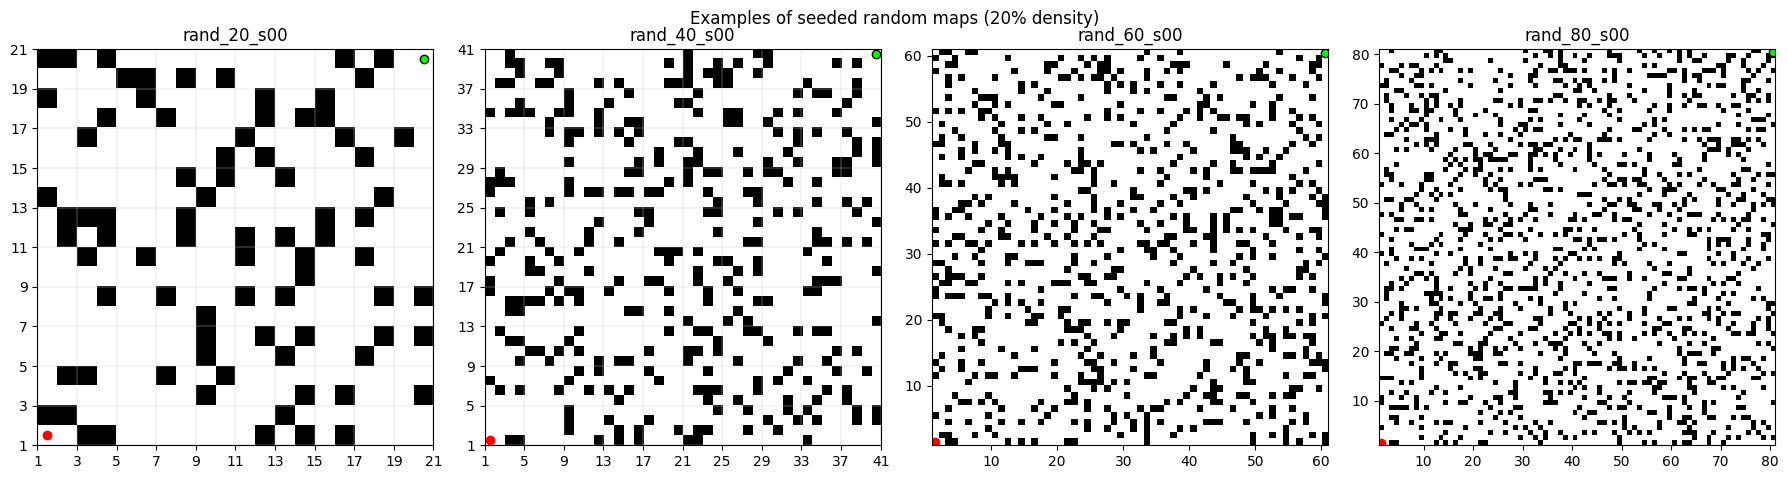

In [30]:
import src.random_maps as rmod; importlib.reload(rmod)
from src.random_maps import random_map
import yaml
cfg_file = PROJECT_ROOT / "configs" / "params.yaml"
SEEDS = yaml.safe_load(cfg_file.read_text())["experiments"]["random_map_seeds"] if cfg_file.exists() else list(range(30))
SIZES = [20, 40, 60, 80]
rand_rows = []
for n in SIZES:
    for seed in SEEDS:
        m = random_map(n, seed, 0.20)
        m.save(PROJECT_ROOT / "maps" / "random")
        rand_rows.append(dict(name=m.name, size=n, seed=seed, attempts=m.meta["attempt"] + 1,
                              density=round(m.density, 4), optimal_length=m.meta["optimal_length"]))
rand_df = pd.DataFrame(rand_rows)
rand_df.to_csv(PROJECT_ROOT / "maps" / "random" / "index.csv", index=False)
print(rand_df.groupby("size").agg(maps=("name", "count"), mean_density=("density", "mean"),
                                  std_density=("density", "std"), mean_attempts=("attempts", "mean"),
                                  mean_opt_len=("optimal_length", "mean")).round(4))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, n in zip(axes, SIZES):
    plot_map(ax, GridMap.load(PROJECT_ROOT / "maps" / "random", f"rand_{n}_s00"), f"rand_{n}_s00")
fig.suptitle("Examples of seeded random maps (20% density)")
fig.tight_layout(); fig.savefig(PROJECT_ROOT / "results" / "figures" / "phase2_random_examples.png", dpi=110)
plt.show()

### 2.8 Save maps, round-trip test and documentation

In [31]:
for m in MAPS.values():
    m.save(PROJECT_ROOT / "maps")
# round-trip test: load every file back and compare
ok = all((GridMap.load(PROJECT_ROOT / "maps", k).grid == v.grid).all() and
         GridMap.load(PROJECT_ROOT / "maps", k).start == v.start for k, v in MAPS.items())
print("Round-trip save/load identical:", ok)

summary = pd.DataFrame([dict(map=k, size=f"{v.size}x{v.size}", obstacles=int(v.grid.sum()),
                             density_pct=round(100 * v.density, 2), start_cr=v.start, goal_cr=v.goal,
                             start_paper_xy=v.to_paper_xy(v.start), goal_paper_xy=v.to_paper_xy(v.goal),
                             source=v.source) for k, v in MAPS.items()])
summary.to_csv(PROJECT_ROOT / "maps" / "index.csv", index=False)
display(summary)
print("\nMap A as stored in maps/map_A_20.txt (top row first):")
print((PROJECT_ROOT / "maps" / "map_A_20.txt").read_text())

Round-trip save/load identical: True


,map,size,obstacles,density_pct,start_cr,goal_cr,start_paper_xy,goal_paper_xy,source
0,map_A_20,20x20,78,19.50,"(19, 0)","(0, 19)","(20.5, 1.5)","(1.5, 20.5)","digitised from Fig. 8 (PDF p.10), 5-subfigure ..."
1,map_B_40,40x40,421,26.31,"(39, 39)","(0, 0)","(40.5, 40.5)","(1.5, 1.5)","digitised from Fig. 9 (PDF p.11), 5-subfigure ..."
2,map_C_60,60x60,898,24.94,"(3, 17)","(55, 32)","(4.5, 18.5)","(56.5, 33.5)","digitised from Fig. 10 (PDF p.11), 5-subfigure..."
3,map_D_80,80x80,2200,34.38,"(9, 75)","(75, 9)","(10.5, 76.5)","(76.5, 10.5)","digitised from Fig. 11 (PDF p.12), 5-subfigure..."
4,tune_a,20x20,69,17.25,"(19, 19)","(0, 0)","(20.5, 20.5)","(1.5, 1.5)","digitised from Fig. 3(a) (PDF p.6), single source"
5,tune_b,20x20,64,16.00,"(2, 2)","(12, 12)","(3.5, 3.5)","(13.5, 13.5)","digitised from Fig. 3(b) (PDF p.6), single source"
6,tune_c,20x20,78,19.50,"(1, 18)","(9, 0)","(2.5, 19.5)","(10.5, 1.5)","digitised from Fig. 3(c) (PDF p.6), single source"
7,tune_d,20x20,80,20.00,"(13, 17)","(1, 2)","(14.5, 18.5)","(2.5, 3.5)","digitised from Fig. 3(d) (PDF p.6), single source"



Map A as stored in maps/map_A_20.txt (top row first):
00000000000011000000
00000000000011000000
00000001100011000000
00000001100011000000
11111000000000000011
11111000000000000011
00000000000000000000
00000001100011110000
00000001100011110000
00000000001000000011
00111000000000000011
00111000000000000000
00000000000110000000
00000000000110000000
00000000000000001110
00000000000000001110
00001110000110001110
00001110000110000000
00001110000000000000
00001110000000000000



In [32]:
v = val.set_index("map")
readme = f'''# Maps (dataset)

The original paper (Li, Li & Dai, Sensors 2024, 24, 6929) does **not** release its maps.
All maps here were reconstructed from the paper's figures by `src/map_digitizer.py`
(notebook `Phase2_Maps_VNS_BA.ipynb`, run {RUN_DATE}).

## Files
| File | Content |
|---|---|
| `map_A_20.*` ... `map_D_80.*` | Evaluation maps of Tables 2-5 (Figs. 8-11) |
| `tune_a.*` ... `tune_d.*` | Weight-tuning maps of Table 1 (Fig. 3) |
| `random/` | 30 seeded random maps per size (20/40/60/80), 20 % density - our addition |
| `index.csv` | Summary of all paper maps |

`*.txt`: 0 = free, 1 = obstacle, **top row first** (as in the figure).
`*.json`: start, goal, density, source, validation info.
Internal convention: `grid[r, c]`, r = 0 bottom row (paper y = 1); points `(c, r)` = (paper x - 1, paper y - 1).

## Validation
- Main maps: each figure contains the same map in 5 sub-plots; all 5 digitised grids agree (majority vote, see `results/phase2/`).
- `tune_d` density = {100*MAPS["tune_d"].density:.1f} % (paper: 20 %).
- Optimal 8-connected path length (corner cutting allowed) on the reconstructed maps vs the best published grid-path length:

| Map | Optimal (ours) | Best published | Match |
|---|---|---|---|
''' + "\n".join(f"| {k} | {r.opt_free} | {r.best_published} ({r.best_published_by}) | {'yes' if r.exact_match else 'no'} |"
                 for k, r in v.iterrows()) + '''

## Known limitations
- Tuning maps (Fig. 3) appear once in the paper, so no majority vote is possible.
- Start/goal cells are taken from the red/green markers; the dot centre is mapped to the cell containing it.
- Random maps are not part of the paper; they are used only for additional multi-run statistics.
'''
(PROJECT_ROOT / "maps" / "README.md").write_text(readme)
print(readme)

# Maps (dataset)

The original paper (Li, Li & Dai, Sensors 2024, 24, 6929) does **not** release its maps.
All maps here were reconstructed from the paper's figures by `src/map_digitizer.py`
(notebook `Phase2_Maps_VNS_BA.ipynb`, run 2026-10-23).

## Files
| File | Content |
|---|---|
| `map_A_20.*` ... `map_D_80.*` | Evaluation maps of Tables 2-5 (Figs. 8-11) |
| `tune_a.*` ... `tune_d.*` | Weight-tuning maps of Table 1 (Fig. 3) |
| `random/` | 30 seeded random maps per size (20/40/60/80), 20 % density - our addition |
| `index.csv` | Summary of all paper maps |

`*.txt`: 0 = free, 1 = obstacle, **top row first** (as in the figure).
`*.json`: start, goal, density, source, validation info.
Internal convention: `grid[r, c]`, r = 0 bottom row (paper y = 1); points `(c, r)` = (paper x - 1, paper y - 1).

## Validation
- Main maps: each figure contains the same map in 5 sub-plots; all 5 digitised grids agree (majority vote, see `results/phase2/`).
- `tune_d` density = 20.0 % (paper: 20 %).


In [33]:
reg_path = PROJECT_ROOT / "docs" / "ambiguity_register.csv"
new_rows = pd.DataFrame([
    ("A10", "Sec 4", "Exact maps, start/goal coordinates",
     "RESOLVED: reconstructed from Figs 3, 8-11; optimal lengths match published values on all 4 maps", "Resolved"),
    ("A16", "Sec 2", "Diagonal move rule near obstacle corners",
     "Corner cutting allowed (diagonal blocked only if target cell is an obstacle) - confirmed by optimal-length match; strict rule contradicts published lengths", "Resolved"),
    ("A17", "Sec 4", "Multiple runs / statistics not provided",
     "30 seeded random maps per size, 20% density, start (0,0), goal (n-1,n-1), solvability enforced", "Our addition"),
], columns=["id", "section", "issue", "our_assumption", "impact_on_reproduction"])
if reg_path.exists():
    reg = pd.read_csv(reg_path)
    reg = pd.concat([reg[~reg.id.isin(new_rows.id)], new_rows], ignore_index=True)
else:
    reg = new_rows
reg["_k"] = reg.id.str[1:].astype(int); reg = reg.sort_values("_k").drop(columns="_k")
reg.to_csv(reg_path, index=False)
print(reg[reg.id.isin(new_rows.id)].to_string(index=False))

# update config with the confirmed diagonal rule
if cfg_file.exists():
    cfg = yaml.safe_load(cfg_file.read_text())
    cfg.setdefault("neighborhood", {})["diagonal_rule"] = "free"   # A16
    cfg.setdefault("experiments", {})["map_dir"] = "maps"
    cfg["experiments"]["random_map_dir"] = "maps/random"
    cfg["experiments"]["random_map_sizes"] = SIZES
    cfg_file.write_text(yaml.safe_dump(cfg, sort_keys=False))
    print("\nconfigs/params.yaml updated: neighborhood.diagonal_rule = free")

 id section                                    issue                                                                                                                                              our_assumption impact_on_reproduction
A10   Sec 4       Exact maps, start/goal coordinates                                                             RESOLVED: reconstructed from Figs 3, 8-11; optimal lengths match published values on all 4 maps               Resolved
A16   Sec 2 Diagonal move rule near obstacle corners Corner cutting allowed (diagonal blocked only if target cell is an obstacle) - confirmed by optimal-length match; strict rule contradicts published lengths               Resolved
A17   Sec 4  Multiple runs / statistics not provided                                                              30 seeded random maps per size, 20% density, start (0,0), goal (n-1,n-1), solvability enforced           Our addition

configs/params.yaml updated: neighborhood.diagonal_rule = free


### Phase 2 summary

In [34]:
lines = [f"# Phase 2 - Dataset reconstruction summary ({RUN_DATE})", "",
         f"- Paper maps reconstructed: {len(SPECS)} evaluation maps + {len(TUNE)} tuning maps",
         f"- Source: {'PDF figures (800 dpi)' if HAVE_PDF else 'embedded reference copy'}"]
if len(digit_df):
    lines.append(f"- Sub-figure agreement with consensus: min {digit_df['agreement_with_consensus_%'].min()} %, "
                 f"mean {digit_df['agreement_with_consensus_%'].mean():.3f} %")
lines += [f"- tune_d density: {100*MAPS['tune_d'].density:.1f} % (paper 20 %)",
          f"- Optimal length = best published grid length on {int(val.exact_match.sum())}/{len(val)} maps",
          "- Diagonal rule confirmed: corner cutting allowed (A16)",
          "- Paper's A* on Map D is sub-optimal (103.297 vs optimum 102.125) -> non-admissible heuristic",
          f"- Random maps: {len(rand_df)} ({len(SEEDS)} seeds x {len(SIZES)} sizes)", "",
          "Files:"]
lines += [f"  - {p.relative_to(PROJECT_ROOT)}" for p in sorted((PROJECT_ROOT / 'maps').glob('*.*'))]
lines += ["  - maps/random/ (" + str(len(list((PROJECT_ROOT / 'maps' / 'random').glob('*.txt')))) + " maps)",
          "  - src/map_digitizer.py, src/grid_map.py, src/reference_planner.py, src/random_maps.py",
          "  - results/phase2/*.csv, results/figures/phase2_*.png"]
txt = "\n".join(lines)
(PROJECT_ROOT / "docs" / "phase2_summary.md").write_text(txt)
print(txt)

# Phase 2 - Dataset reconstruction summary (2026-10-23)

- Paper maps reconstructed: 4 evaluation maps + 4 tuning maps
- Source: PDF figures (800 dpi)
- Sub-figure agreement with consensus: min 99.984 %, mean 99.999 %
- tune_d density: 20.0 % (paper 20 %)
- Optimal length = best published grid length on 4/4 maps
- Diagonal rule confirmed: corner cutting allowed (A16)
- Paper's A* on Map D is sub-optimal (103.297 vs optimum 102.125) -> non-admissible heuristic
- Random maps: 120 (30 seeds x 4 sizes)

Files:
  - maps/.gitkeep
  - maps/README.md
  - maps/index.csv
  - maps/map_A_20.json
  - maps/map_A_20.txt
  - maps/map_B_40.json
  - maps/map_B_40.txt
  - maps/map_C_60.json
  - maps/map_C_60.txt
  - maps/map_D_80.json
  - maps/map_D_80.txt
  - maps/tune_a.json
  - maps/tune_a.txt
  - maps/tune_b.json
  - maps/tune_b.txt
  - maps/tune_c.json
  - maps/tune_c.txt
  - maps/tune_d.json
  - maps/tune_d.txt
  - maps/random/ (120 maps)
  - src/map_digitizer.py, src/grid_map.py, src/reference_pla

### 2.9 Standalone map builder
The same reconstruction as a command-line script, so the dataset can be rebuilt without the notebook: `python -m experiments.build_maps --pdf docs/paper.pdf`.

In [35]:
import os; os.makedirs('experiments', exist_ok=True)
if not os.path.exists('experiments/__init__.py'):
    open('experiments/__init__.py', 'w').write('# experiment scripts package\n')

In [36]:
%%writefile experiments/build_maps.py
"""Phase 2 without the notebook: rebuild the paper's maps from its PDF figures and create the random maps.

    python -m experiments.build_maps --pdf docs/paper.pdf          # paper maps + 120 random maps
    python -m experiments.build_maps --random-only                  # only the random maps
Writes maps/*.txt|json, maps/index.csv, maps/random/. See maps/README.md for the format and the validation.
"""
from __future__ import annotations
import argparse
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd                                                   # noqa: E402
from src.grid_map import GridMap                                      # noqa: E402
from src.random_maps import random_map                                # noqa: E402
from src.reference_planner import dijkstra_8                          # noqa: E402

SPECS = {  # name: (PDF page, sub-figure frames, grid size, figure)
    "map_A_20": (10, slice(0, 5), 20, "Fig. 8"), "map_B_40": (11, slice(0, 5), 40, "Fig. 9"),
    "map_C_60": (11, slice(5, 10), 60, "Fig. 10"), "map_D_80": (12, slice(0, 5), 80, "Fig. 11"),
}
TUNING = ["tune_a", "tune_b", "tune_c", "tune_d"]                       # Fig. 3, page 6
PUBLISHED_BEST = {"map_A_20": 28.627, "map_B_40": 61.598, "map_C_60": 59.385, "map_D_80": 102.125}


def build_paper_maps(pdf: Path, dpi: int = 800):
    from src.map_digitizer import render_page, find_plot_frames, classify_cells, detect_marker, consensus, mode_point
    pages, out, dig_rows, val_rows = {}, [], [], []
    SUB = ["(a) A*", "(b) Improved A*", "(c) BA*", "(d) Improved BA*", "(e) VNS-BA*"]
    PUB = {"map_A_20": {"A*": 28.627, "Improved A*": 28.627, "BA*": 28.627, "Improved BA*": 29.213},
           "map_B_40": {"A*": 61.598, "Improved A*": 64.083, "BA*": 61.598, "Improved BA*": 61.598},
           "map_C_60": {"A*": 59.385, "Improved A*": 69.0833, "BA*": 59.3848, "Improved BA*": 61.598},
           "map_D_80": {"A*": 103.297, "Improved A*": 104.125, "BA*": 102.125, "Improved BA*": 106.225}}
    for name, (page, frames, n, fig) in SPECS.items():
        if page not in pages:
            img = render_page(str(pdf), page, dpi); pages[page] = (img, find_plot_frames(img))
        img, boxes = pages[page]
        grids = [classify_cells(img, b, n)[0] for b in boxes[frames]]
        grid, agree, disputed, _ = consensus(grids)
        for sub, g, b in zip(SUB, grids, boxes[frames]):
            dig_rows.append(dict(map=name, subfigure=sub, frame_px=f"{b[2]}x{b[3]}", obstacles=int(g.sum()),
                                 **{"agreement_with_consensus_%": round(100 * float((g == grid).mean()), 3)}))
        start = mode_point([detect_marker(img, b, n, "red") for b in boxes[frames]])
        goal = mode_point([detect_marker(img, b, n, "green") for b in boxes[frames]])
        m = GridMap(name, grid, start, goal, f"digitised from {fig} (PDF p.{page}), 5-subfigure majority vote",
                    dict(figure=fig, mean_agreement_pct=round(100 * agree, 3), disputed_cells=int(len(disputed))))
        m.save(ROOT / "maps"); out.append(m)
        opt = dijkstra_8(grid, start, goal, "free")[0]
        res = {rule: dijkstra_8(grid, start, goal, rule)[0] for rule in ["free", "no_squeeze", "strict"]}
        best = min(PUB[name].values())
        val_rows.append(dict(map=name, opt_free=round(res["free"], 3), opt_no_squeeze=round(res["no_squeeze"], 3),
                             opt_strict=round(res["strict"], 3), best_published=best,
                             best_published_by=", ".join(k for k, v in PUB[name].items() if abs(v - best) < 1e-3),
                             published_A_star=PUB[name]["A*"], exact_match=abs(res["free"] - best) < 1e-3,
                             all_published_ge_optimum=all(v >= res["free"] - 1e-3 for v in PUB[name].values())))
        print(f"{name}: agreement {100*agree:.3f} %, optimal length {opt:.3f} (best published {PUBLISHED_BEST[name]}) "
              f"-> {'MATCH' if abs(opt - PUBLISHED_BEST[name]) < 2e-3 else 'CHECK'}")
    (ROOT / "results" / "phase2").mkdir(parents=True, exist_ok=True)
    pd.DataFrame(dig_rows).to_csv(ROOT / "results/phase2/digitisation_per_subfigure.csv", index=False)
    pd.DataFrame(val_rows).to_csv(ROOT / "results/phase2/validation_optimal_length.csv", index=False)
    img6 = render_page(str(pdf), 6, dpi); boxes6 = find_plot_frames(img6)
    for i, name in enumerate(TUNING):
        g = classify_cells(img6, boxes6[i], 20)[0]
        m = GridMap(name, g, detect_marker(img6, boxes6[i], 20, "red"), detect_marker(img6, boxes6[i], 20, "green"),
                    f"digitised from Fig. 3({'abcd'[i]}) (PDF p.6)", dict(figure=f"Fig. 3({'abcd'[i]})"))
        m.save(ROOT / "maps"); out.append(m)
        print(f"{name}: density {100*m.density:.1f} %")
    pd.DataFrame([dict(map=m.name, size=f"{m.size}x{m.size}", obstacles=int(m.grid.sum()), density_pct=round(100 * m.density, 2),
                       start_cr=m.start, goal_cr=m.goal, source=m.source) for m in out]).to_csv(ROOT / "maps" / "index.csv", index=False)


def build_random_maps(seeds=range(30), sizes=(20, 40, 60, 80), density=0.20):
    rows = []
    for n in sizes:
        for s in seeds:
            m = random_map(n, s, density); m.save(ROOT / "maps" / "random")
            rows.append(dict(name=m.name, size=n, seed=s, attempts=m.meta["attempt"] + 1,
                             density=round(m.density, 4), optimal_length=m.meta["optimal_length"]))
    pd.DataFrame(rows).to_csv(ROOT / "maps" / "random" / "index.csv", index=False)
    print(f"random maps: {len(rows)}")


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--pdf", default=str(ROOT / "docs" / "paper.pdf"))
    ap.add_argument("--random-only", action="store_true")
    a = ap.parse_args()
    if not a.random_only:
        build_paper_maps(Path(a.pdf))
    build_random_maps()


Writing experiments/build_maps.py


The calibration study of Part 3 (Sec. 3.6) is also available as a script: `python -m experiments.run_calibration`.

In [37]:
%%writefile experiments/run_calibration.py
"""Calibration of unspecified baseline details against the published BASELINE numbers only (Phase 3, Sec. 3.6).
Tests the heuristic of the traditional A*/BA*, the meaning of "Number of Nodes" and the BA* meeting rule.

    python -m experiments.run_calibration
Output: results/phase3/calibration.csv
"""
from __future__ import annotations
import pandas as pd

from experiments.common import ROOT, MAP_NAMES, PUBLISHED, load_map
from src.geometry import GridGeometry, euclid, manhattan, switch_distance
from src.neighborhood import neighbors_8
from src.search import best_first, bidirectional
from src.metrics import path_length, turn_metrics


def run():
    rows = []
    for name in MAP_NAMES:
        m = load_map(name); geo = GridGeometry(m.grid); S, G = tuple(m.start), tuple(m.goal); roots = {"S": G, "G": S}
        for hname in ["manhattan", "euclid", "switch"]:
            d = {"manhattan": manhattan, "euclid": euclid, "switch": lambda a, b: switch_distance(geo, a, b)}[hname]
            ra = best_first(geo, S, G, neighbors_8, lambda n: d(n, G)); p = PUBLISHED[name]["astar"]
            rows.append(dict(map=name, algorithm="A*", variant=f"h={hname}", expanded=ra.expanded, generated=ra.generated,
                             pub_nodes=p[0], length=round(path_length(ra.path), 3), pub_length=p[4],
                             turns=turn_metrics(ra.path)["turns"], pub_turns=p[1]))
        for meet in ["pop_closed", "open_closed", "pop_in_open"]:
            rb = bidirectional(geo, S, G, lambda gg, n, t: neighbors_8(gg, n), lambda s, n, o: manhattan(n, roots[s]), meet_rule=meet)
            p = PUBLISHED[name]["bastar"]
            rows.append(dict(map=name, algorithm="BA*", variant=f"h=manhattan, meet={meet}", expanded=rb.expanded,
                             generated=rb.generated, pub_nodes=p[0], length=round(path_length(rb.path), 3), pub_length=p[4],
                             turns=turn_metrics(rb.path)["turns"], pub_turns=p[1]))
    cal = pd.DataFrame(rows)
    cal["length_match"] = (cal.length - cal.pub_length).abs() < 2e-3
    cal["turns_match"] = cal.turns == cal.pub_turns
    cal["gen_err_%"] = (100 * (cal.generated - cal.pub_nodes) / cal.pub_nodes).round(1)
    cal["exp_err_%"] = (100 * (cal.expanded - cal.pub_nodes) / cal.pub_nodes).round(1)
    out = ROOT / "results" / "phase3"; out.mkdir(parents=True, exist_ok=True)
    cal.to_csv(out / "calibration.csv", index=False)
    return cal


if __name__ == "__main__":
    c = run()
    print(c.groupby(["algorithm", "variant"]).agg(length_matches=("length_match", "sum"), turn_matches=("turns_match", "sum")))


Writing experiments/run_calibration.py


---
# Part 3  Independent Implementation
**Objective.** Implement VNS-BA\* (8-11-13 neighbourhood, improved bidirectional heuristic, polyline pruning, local cubic-spline smoothing) and the four baselines from the respective articles, verify all components with unit tests, and resolve unspecified baseline details using only the published baseline results.

**Outputs.** `src/geometry.py`, `src/neighborhood.py`, `src/search.py`, `src/postprocess.py`, `src/metrics.py`, `src/planners.py`, `tests/`, `results/phase3/`.

## Part 3  Independent Implementation of VNS-BA* and the Four Baselines
**Paper:** Li, Li & Dai, *VNS-BA\**, Sensors 24(21):6929, 2024.

This notebook writes the complete method as Python modules in `src/`, tests it, calibrates the under-specified details against the paper's own published numbers, and runs a first reproduction of Tables 2–5.

| Step | Content |
|---|---|
| 3.1 | Setup (needs Phase 2 maps) |
| 3.2 | Paper → code mapping, and what is *original*, *our assumption*, *calibrated* |
| 3.3 | Modules: geometry, neighbourhood, search engines, post-processing, metrics, planners |
| 3.4 | Unit tests |
| 3.5 | Re-creation of the paper's method figures (Fig. 1, 5, 6/7) from our code |
| 3.6 | **Calibration study** — which reading of the ambiguous details reproduces the published baselines |
| 3.7 | First reproduction run on Maps A–D vs Tables 2–5 |
| 3.8 | Paper-style result figures (Figs. 8–11) |
| 3.9 | Assumption register, config and README update |

Full experiments with repeated runs, weight sweep, ablation and random maps are **Phase 4**.

### 3.1 Setup

In [38]:
import os, sys, json, datetime, importlib, subprocess
from pathlib import Path

USE_DRIVE = True
PROJECT_NAME = "vns-ba-reproduction"
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive') / PROJECT_NAME
elif IN_COLAB:
    PROJECT_ROOT = Path('/content') / PROJECT_NAME
else:
    PROJECT_ROOT = Path.cwd() if Path.cwd().name == PROJECT_NAME else Path.cwd() / PROJECT_NAME
for d in ["src", "tests", "results/phase3", "results/figures", "docs", "configs"]:
    (PROJECT_ROOT / d).mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
for pkg in ["src", "tests"]:
    f = PROJECT_ROOT / pkg / "__init__.py"
    if not f.exists():
        f.write_text(f"# {pkg} package\n")
need = ["maps/map_A_20.txt", "maps/map_D_80.txt", "src/grid_map.py", "src/reference_planner.py", "src/random_maps.py"]
missing = [p for p in need if not (PROJECT_ROOT / p).exists()]
if missing:
    raise FileNotFoundError(f"Run the Phase 2 notebook first - missing: {missing}")
try:
    import pytest  # noqa
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytest"], check=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
RUN_DATE = datetime.date.today().isoformat()
print("Project root:", PROJECT_ROOT, "| Phase 2 maps found")

Project root: /tmp/userrun/vns-ba-reproduction | Phase 2 maps found


### 3.2 What is implemented, and from where

| Paper element | Section / Eq. | Module · function | Source of the details |
|---|---|---|---|
| Grid map, f = g + h | Sec. 2, Eq. 1, 7 | `search.best_first`, `search.bidirectional` | paper |
| Euclid/Manhattan switching distance | Sec. 2, Eqs. 2–3 | `geometry.switch_distance` | paper; line-of-sight rule = **A4/A16** |
| 8-11-13 variable neighbourhood | Sec. 3.1, Fig. 1 | `neighborhood.neighbors_81113` | paper; move cost **A2**, blocked extension cells **A8**, vector target **A19** |
| Improved bidirectional heuristic p(n), h(n)=e^ρ p(n) | Sec. 3.2, Eqs. 5–6 | `planners.run_vns_bastar_search` | paper (ω=η=0.5); ρ definition **A1**, "opposite start" **A15** |
| Bidirectional loop & meeting | Fig. 4 | `search.bidirectional(meet_rule="pop_closed")` | paper flowchart; order **A3**; rule **calibrated (A26)** |
| Polyline pruning | Sec. 3.3, Fig. 5 | `postprocess.prune_path` | paper |
| Local cubic-spline smoothing | Sec. 3.4, Eqs. 8–11 | `postprocess.smooth_turns`, `natural_cubic_spline` | paper; parametrisation **A5**, boundary **A6**, P1–P4 **A7**, collision retry **A22** |
| A\* baseline | Sec. 2 | `planners.run_astar` | heuristic **calibrated (A24)** |
| Improved A\* [28] | Liu et al. 2023 | `planners.run_improved_astar_28`, `neighborhood.neighbors_5dir` | ref. [28] Eqs. 3–5; direction rule **A27**, fallback **A18** |
| BA\* | Sec. 3.2 | `planners.run_bastar` | heuristic **calibrated (A24)** |
| Improved BA\* [29] | Zhang et al. 2023 | `planners.run_improved_bastar_29` | ref. [29] Eqs. 7–10 + Appendix A; μ = e^ρ as stated by the paper (**A13**) |
| Metrics | Tables 2–6 | `metrics`, `planners.plan` | "Number of Nodes" definition **calibrated (A25)**; turns on pruned polyline **A21** |

**Everything in `src/` is written from the papers' text and equations; only NumPy is used inside the algorithms.** SciPy is used only in one unit test to cross-check our own cubic-spline solver.

### 3.3 Source modules
**`src/geometry.py`** — exact segment/grid traversal (corner touching allowed, Sec. 2), line-of-sight cache, O(1) obstacle density via integral image.

In [39]:
%%writefile src/geometry.py
"""Grid geometry shared by all planners.

* line-of-sight between cell centres (used by the Euclid/Manhattan switch of Sec. 2
  and by the polyline pruning of Sec. 3.3),
* obstacle density of the rectangle spanned by two cells (rho of Sec. 3.2), via an
  integral image so every query is O(1).

Cell (c, r) is the unit square centred at (c, r).  A segment "crosses" a cell when it runs
through that cell's interior for a positive length; merely touching a corner does not count
(Sec. 2: grid size includes the safety margin, so touching an obstacle corner is collision-free).
"""
from __future__ import annotations
import math
import numpy as np


class GridGeometry:
    def __init__(self, grid: np.ndarray):
        self.grid = np.asarray(grid, dtype=np.uint8)
        self.n = self.grid.shape[0]
        ii = np.zeros((self.n + 1, self.n + 1), dtype=np.int64)
        ii[1:, 1:] = self.grid.cumsum(0).cumsum(1)
        self._ii = ii
        self._los_cache: dict = {}

    # ------------------------------------------------------------------ cells
    def inside(self, c: int, r: int) -> bool:
        return 0 <= c < self.n and 0 <= r < self.n

    def free(self, c: int, r: int) -> bool:
        return 0 <= c < self.n and 0 <= r < self.n and self.grid[r, c] == 0

    # ------------------------------------------------------------------ segments
    @staticmethod
    def segment_cells(a, b):
        """Cells whose interior the straight segment a->b passes through (ordered from a to b)."""
        x0, y0 = a
        x1, y1 = b
        dx, dy = x1 - x0, y1 - y0
        ts = [0.0, 1.0]
        if dx:
            lo, hi = (x0, x1) if x0 < x1 else (x1, x0)
            ts += [(k + 0.5 - x0) / dx for k in range(int(math.floor(lo)), int(math.ceil(hi)))
                   if lo < k + 0.5 < hi]
        if dy:
            lo, hi = (y0, y1) if y0 < y1 else (y1, y0)
            ts += [(k + 0.5 - y0) / dy for k in range(int(math.floor(lo)), int(math.ceil(hi)))
                   if lo < k + 0.5 < hi]
        ts.sort()
        cells = []
        for t0, t1 in zip(ts, ts[1:]):
            if t1 - t0 < 1e-12:            # zero-length piece = touching a corner
                continue
            tm = 0.5 * (t0 + t1)
            cell = (int(math.floor(x0 + dx * tm + 0.5)), int(math.floor(y0 + dy * tm + 0.5)))
            if not cells or cells[-1] != cell:
                cells.append(cell)
        return cells

    def line_of_sight(self, a, b) -> bool:
        """True if the segment between the centres of cells a and b crosses no obstacle cell."""
        key = (a, b) if a <= b else (b, a)
        hit = self._los_cache.get(key)
        if hit is None:
            hit = all(self.free(c, r) for c, r in self.segment_cells(a, b))
            self._los_cache[key] = hit
        return hit

    def segment_free(self, p, q) -> bool:
        """Same test for arbitrary real-valued points (used to validate smoothed curves)."""
        return all(self.free(c, r) for c, r in self.segment_cells(p, q))

    # ------------------------------------------------------------------ density
    def density(self, a, b) -> float:
        """Obstacle fraction of the axis-aligned rectangle with corner cells a and b (inclusive)."""
        c0, c1 = sorted((a[0], b[0]))
        r0, r1 = sorted((a[1], b[1]))
        ii = self._ii
        s = ii[r1 + 1, c1 + 1] - ii[r0, c1 + 1] - ii[r1 + 1, c0] + ii[r0, c0]
        return s / ((c1 - c0 + 1) * (r1 - r0 + 1))


# ---------------------------------------------------------------------- distances
def euclid(a, b) -> float:
    return math.hypot(a[0] - b[0], a[1] - b[1])


def manhattan(a, b) -> float:
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def chebyshev(a, b) -> float:
    return max(abs(a[0] - b[0]), abs(a[1] - b[1]))


def switch_distance(geo: GridGeometry, a, b) -> float:
    """Sec. 2 of the paper: Euclidean if the line a-b is obstacle-free, otherwise Manhattan."""
    return euclid(a, b) if geo.line_of_sight(a, b) else manhattan(a, b)


Writing src/geometry.py


**`src/neighborhood.py`** — 8-neighbourhood, the adaptive 8-11-13 neighbourhood (Fig. 1 numbering), and the 5-direction neighbourhood of baseline [28].

In [40]:
%%writefile src/neighborhood.py
"""Node-expansion neighbourhoods.

Numbering of the 8-neighbourhood follows Fig. 1 of the paper (1 = top-left, clockwise):
    1 2 3
    8 . 4
    7 6 5
"""
from __future__ import annotations
import math

N8 = [(-1, 1), (0, 1), (1, 1), (1, 0), (1, -1), (0, -1), (-1, -1), (-1, 0)]
SQRT2 = math.sqrt(2.0)


def _sign(v):
    return (v > 0) - (v < 0)


def extension_offsets(dx: int, dy: int):
    """Extra cells of the 11/13-neighbourhood for the vector (dx, dy) = target - current.

    * vector on an axis      -> 3 cells of the second ring on that side   (11-neighbourhood, Fig. 1c)
    * vector inside quadrant -> 5 cells forming the L of that corner      (13-neighbourhood, Fig. 1b)
    """
    sx, sy = _sign(dx), _sign(dy)
    if sx == 0 and sy == 0:
        return []
    if sx == 0:
        return [(-1, 2 * sy), (0, 2 * sy), (1, 2 * sy)]
    if sy == 0:
        return [(2 * sx, -1), (2 * sx, 0), (2 * sx, 1)]
    return [(0, 2 * sy), (sx, 2 * sy), (2 * sx, 2 * sy), (2 * sx, sy), (2 * sx, 0)]


def neighbors_8(geo, node, target=None):
    """Classic 8-neighbourhood; diagonal moves allowed past obstacle corners (assumption A16)."""
    c, r = node
    out = []
    for dc, dr in N8:
        if geo.free(c + dc, r + dr):
            out.append(((c + dc, r + dr), SQRT2 if dc and dr else 1.0))
    return out


def neighbors_81113(geo, node, target):
    """Adaptive 8-11-13 variable neighbourhood (Sec. 3.1).

    Returns (neighbours, mode) where mode is 8, 11 or 13 (for statistics).
    """
    c, r = node
    out, blocked = [], False
    for dc, dr in N8:
        if geo.free(c + dc, r + dr):
            out.append(((c + dc, r + dr), SQRT2 if dc and dr else 1.0))
        else:
            blocked = True                      # obstacle or map border in the 8-neighbourhood
    if blocked or target is None:
        return out, 8
    ext = extension_offsets(target[0] - c, target[1] - r)
    for dc, dr in ext:                          # A8: skip extension cells that are obstacles
        if geo.free(c + dc, r + dr):
            out.append(((c + dc, r + dr), math.hypot(dc, dr)))   # A2: Euclidean move cost
    return out, 8 + len(ext)


def neighbors_5dir(geo, node, target):
    """Baseline [28] (Liu et al. 2023): keep the 5 of 8 directions closest to the target direction,
    discarding the 3 directions pointing away from it."""
    c, r = node
    if target is None or tuple(target) == tuple(node):
        return neighbors_8(geo, node)
    theta = math.atan2(target[1] - r, target[0] - c)
    def ang(d):
        a = math.atan2(d[1], d[0]) - theta
        return abs((a + math.pi) % (2 * math.pi) - math.pi)
    dirs = sorted(N8, key=ang)[:5]
    out = []
    for dc, dr in dirs:
        if geo.free(c + dc, r + dr):
            out.append(((c + dc, r + dr), SQRT2 if dc and dr else 1.0))
    return out


Writing src/neighborhood.py


**`src/search.py`** — one unidirectional and one bidirectional best-first engine; heuristics, neighbourhoods and meeting rules are injected so all five planners share tested code.

In [41]:
%%writefile src/search.py
"""Generic unidirectional and bidirectional best-first (A*-family) search engines.

The algorithm-specific parts (heuristic, neighbourhood, meeting rule) are injected, so the
traditional A*, Improved A* [28], BA*, Improved BA* [29] and VNS-BA* share one tested core.
Counters returned:
    expanded  = nodes moved to a closed list  (reported as "Number of Nodes")
    generated = distinct nodes ever inserted in an open list
"""
from __future__ import annotations
import heapq
import itertools
from dataclasses import dataclass, field


@dataclass
class SearchResult:
    path: list                      # list of cells (c, r) from start to goal, [] if failed
    expanded: int
    generated: int
    closed: dict = field(default_factory=dict)       # side -> set of closed cells (for plots)
    meet: tuple | None = None
    stats: dict = field(default_factory=dict)

    @property
    def success(self) -> bool:
        return bool(self.path)


def _chain(parent, node):
    out = []
    while node is not None:
        out.append(node)
        node = parent[node]
    return out


# ---------------------------------------------------------------------------- unidirectional
def _key(f, g, h, tie, mode):
    if mode == "fifo":
        return (f, tie)
    if mode == "lifo":
        return (f, -tie)
    if mode == "low_h":
        return (f, h, tie)
    if mode == "high_g":
        return (f, -g, tie)
    raise ValueError(mode)


def best_first(geo, start, goal, neighbors_fn, h_fn, max_expansions=10**7, tie_break="fifo"):
    """A* skeleton of Sec. 2 (steps 1-7): pop min f, stop when the goal is closed."""
    tie = itertools.count()
    g = {start: 0.0}
    parent = {start: None}
    h0 = h_fn(start)
    open_heap = [(_key(h0, 0.0, h0, next(tie), tie_break), start)]
    closed = set()
    while open_heap and len(closed) < max_expansions:
        _, cur = heapq.heappop(open_heap)
        if cur in closed:
            continue                                   # stale heap entry
        closed.add(cur)
        if cur == goal:
            return SearchResult(_chain(parent, goal)[::-1], len(closed), len(g), {"S": closed})
        for nb, cost in neighbors_fn(geo, cur, goal):
            if nb in closed:
                continue
            ng = g[cur] + cost
            if ng < g.get(nb, float("inf")):           # step 6: keep the better parent
                g[nb] = ng
                parent[nb] = cur
                hv = h_fn(nb)
                heapq.heappush(open_heap, (_key(ng + hv, ng, hv, next(tie), tie_break), nb))
    return SearchResult([], len(closed), len(g), {"S": closed})


# ---------------------------------------------------------------------------- bidirectional
def bidirectional(geo, start, goal, neighbors_fn, h_fn, meet_rule="pop_closed",
                  max_expansions=10**7, tie_break="fifo"):
    """Bidirectional best-first search with alternating expansion (assumption A3).

    neighbors_fn(geo, node, target) -> list[(nb, cost)] or (list, mode)
    h_fn(side, node, opp_current)   -> heuristic value; side is "S" (forward) or "G" (backward)
    meet_rule:
      "pop_closed"  - Fig. 4 of the paper (default): the node just moved from one side's open list to
                      its closed list is already in the other side's closed list.  Calibrated in
                      Phase 3: reproduces the published BA* nodes/length/turns on Maps A-D.
      "open_closed" - stricter variant: also stop as soon as a generated node is in the other
                      side's closed list (kept for sensitivity analysis)
      "pop_in_open" - baseline [29] (Appendix A): the popped node is in the other side's open set
    """
    tie = itertools.count()
    roots = {"S": start, "G": goal}
    other = {"S": "G", "G": "S"}
    g = {"S": {start: 0.0}, "G": {goal: 0.0}}
    parent = {"S": {start: None}, "G": {goal: None}}
    closed = {"S": set(), "G": set()}
    current = {"S": start, "G": goal}             # each front's most recently expanded node
    heaps = {}
    for s in "SG":
        h0 = h_fn(s, roots[s], roots[other[s]])
        heaps[s] = [(_key(h0, 0.0, h0, next(tie), tie_break), roots[s])]
    modes = {8: 0, 11: 0, 13: 0}

    def finish(meet):
        fwd = _chain(parent["S"], meet)[::-1]
        bwd = _chain(parent["G"], meet)[1:]
        path = fwd + bwd
        return SearchResult(path, len(closed["S"]) + len(closed["G"]),
                            len(g["S"]) + len(g["G"]), closed, meet, {"modes": modes})

    if start == goal:
        return finish(start)
    while heaps["S"] and heaps["G"]:
        if len(closed["S"]) + len(closed["G"]) >= max_expansions:
            break
        for side in ("S", "G"):
            opp = other[side]
            heap = heaps[side]
            cur = None
            while heap:
                _, cand = heapq.heappop(heap)
                if cand not in closed[side]:
                    cur = cand
                    break
            if cur is None:
                return SearchResult([], len(closed["S"]) + len(closed["G"]),
                                    len(g["S"]) + len(g["G"]), closed, None, {"modes": modes})
            closed[side].add(cur)
            current[side] = cur
            if meet_rule == "pop_in_open" and cur in g[opp]:
                return finish(cur)
            if meet_rule in ("pop_closed", "open_closed") and cur in closed[opp]:
                return finish(cur)
            res = neighbors_fn(geo, cur, current[opp])
            if isinstance(res, tuple):
                res, mode = res
                modes[mode] = modes.get(mode, 0) + 1
            for nb, cost in res:
                if nb in closed[side]:
                    continue
                ng = g[side][cur] + cost
                if ng < g[side].get(nb, float("inf")):
                    g[side][nb] = ng
                    parent[side][nb] = cur
                    if meet_rule == "open_closed" and nb in closed[opp]:
                        return finish(nb)
                    hv = h_fn(side, nb, current[opp])
                    heapq.heappush(heap, (_key(ng + hv, ng, hv, next(tie), tie_break), nb))
    return SearchResult([], len(closed["S"]) + len(closed["G"]),
                        len(g["S"]) + len(g["G"]), closed, None, {"modes": modes})


Writing src/search.py


**`src/postprocess.py`** — polyline pruning (Sec. 3.3) and local cubic-spline smoothing (Sec. 3.4) with our own tridiagonal natural-spline solver.

In [42]:
%%writefile src/postprocess.py
"""Path post-processing of VNS-BA*: polyline pruning (Sec. 3.3) and local cubic-spline
smoothing at the turning points (Sec. 3.4).  The cubic spline is solved here directly
(tridiagonal system) instead of calling a library, so the method is fully re-implemented."""
from __future__ import annotations
import math
import numpy as np


# ------------------------------------------------------------------------------ helpers
def compress_collinear(path):
    """Remove intermediate nodes that lie on a straight run (same heading)."""
    pts = [tuple(p) for p in path]
    if len(pts) <= 2:
        return pts
    out = [pts[0]]
    for i in range(1, len(pts) - 1):
        a, b, c = out[-1], pts[i], pts[i + 1]
        cross = (b[0] - a[0]) * (c[1] - b[1]) - (b[1] - a[1]) * (c[0] - b[0])
        dot = (b[0] - a[0]) * (c[0] - b[0]) + (b[1] - a[1]) * (c[1] - b[1])
        if abs(cross) > 1e-9 or dot < 0:
            out.append(b)
    out.append(pts[-1])
    return out


# ------------------------------------------------------------------------------ Sec. 3.3
def prune_path(geo, path):
    """Greedy line-of-sight pruning exactly as described in Sec. 3.3:
    keep the front endpoint, extend the back endpoint along the path until the segment crosses an
    obstacle, then keep the previous node as the new front endpoint."""
    pts = [tuple(p) for p in path]
    if len(pts) <= 2:
        return pts
    out = [pts[0]]
    anchor = pts[0]
    i = 1
    while i < len(pts):
        if geo.line_of_sight(anchor, pts[i]):
            i += 1
            continue
        prev = pts[i - 1]
        if prev == anchor:                      # cannot happen for a valid path; guard anyway
            prev = pts[i]
            i += 1
        out.append(prev)
        anchor = prev
    out.append(pts[-1])
    return compress_collinear(out)


def prune_huang(geo, path):
    """Comparison method of Sec. 3.3 (Huang et al. [27], as described in the VNS-BA* article):
    (1) remove collinear redundant nodes, then (2) remove unnecessary turning points: a turning point is
    dropped when the segment from the last kept vertex to the next turning point is collision-free.
    Unlike prune_path, only the turning points of the grid path are candidates (assumption A28)."""
    pts = compress_collinear(path)
    if len(pts) <= 2:
        return pts
    out = [pts[0]]
    for i in range(1, len(pts) - 1):
        if not geo.line_of_sight(out[-1], pts[i + 1]):
            out.append(pts[i])
    out.append(pts[-1])
    return compress_collinear(out)


# ------------------------------------------------------------------------------ cubic spline
def natural_cubic_spline(t, y):
    """Coefficients (a, b, c, d) per interval for the natural cubic spline through (t_i, y_i):
        S_i(x) = a_i + b_i (x - t_i) + c_i (x - t_i)^2 + d_i (x - t_i)^3
    Conditions: interpolation, C1 and C2 continuity at interior knots (Eq. 11 of the paper),
    natural boundary S''(t_0) = S''(t_n) = 0 (assumption A6).  Solved with the Thomas algorithm."""
    t = np.asarray(t, float); y = np.asarray(y, float)
    n = len(t) - 1
    h = np.diff(t)
    M = np.zeros(n + 1)                          # second derivatives at knots
    if n >= 2:
        lower = h[1:-1].copy(); diag = 2 * (h[:-1] + h[1:]); upper = h[1:-1].copy()
        rhs = 6 * ((y[2:] - y[1:-1]) / h[1:] - (y[1:-1] - y[:-2]) / h[:-1])
        m = n - 1
        cp = np.zeros(m); dp = np.zeros(m)
        cp[0] = upper[0] / diag[0] if m > 1 else 0.0
        dp[0] = rhs[0] / diag[0]
        for i in range(1, m):
            den = diag[i] - lower[i - 1] * cp[i - 1]
            cp[i] = upper[i] / den if i < m - 1 else 0.0
            dp[i] = (rhs[i] - lower[i - 1] * dp[i - 1]) / den
        sol = np.zeros(m)
        sol[-1] = dp[-1]
        for i in range(m - 2, -1, -1):
            sol[i] = dp[i] - cp[i] * sol[i + 1]
        M[1:-1] = sol
    a = y[:-1]
    b = (y[1:] - y[:-1]) / h - h * (2 * M[:-1] + M[1:]) / 6
    c = M[:-1] / 2
    d = (M[1:] - M[:-1]) / (6 * h)
    return a, b, c, d


def eval_spline(t, coeffs, x):
    a, b, c, d = coeffs
    x = np.atleast_1d(np.asarray(x, float))
    idx = np.clip(np.searchsorted(t, x, side="right") - 1, 0, len(a) - 1)
    dx = x - np.asarray(t)[idx]
    return a[idx] + b[idx] * dx + c[idx] * dx ** 2 + d[idx] * dx ** 3


def spline_through(points, samples_per_segment=10):
    """Parametric (x(s), y(s)) natural cubic spline with chord-length parameter s (assumption A5)."""
    P = np.asarray(points, float)
    s = np.concatenate([[0.0], np.cumsum(np.hypot(*np.diff(P, axis=0).T))])
    cx, cy = natural_cubic_spline(s, P[:, 0]), natural_cubic_spline(s, P[:, 1])
    xs = np.linspace(0, s[-1], samples_per_segment * (len(P) - 1) + 1)
    return np.column_stack([eval_spline(s, cx, xs), eval_spline(s, cy, xs)])


# ------------------------------------------------------------------------------ Sec. 3.4
def smooth_turns(geo, polyline, offset=1.0, outer_factor=2.0, samples=10, retries=3):
    """Replace each turning vertex V by a cubic spline through P1, P2 (before V) and P3, P4 (after V).
    V itself is not a control point (paper).  P2/P3 lie `offset` cells from V and P1/P4
    `outer_factor*offset` cells (assumption A7), clipped to 45 % of the adjacent segment so that
    neighbouring turns never overlap.  If the curve would cross an obstacle the offset is halved
    (up to `retries` times); otherwise the corner is kept (assumption A22).
    Returns (smoothed points as (k,2) array, list of per-turn info)."""
    pts = [np.asarray(p, float) for p in polyline]
    if len(pts) < 3:
        return np.asarray(pts), []
    out = [pts[0]]
    info = []
    for i in range(1, len(pts) - 1):
        A, V, B = pts[i - 1], pts[i], pts[i + 1]
        lin, lout = np.linalg.norm(V - A), np.linalg.norm(B - V)
        uin, uout = (V - A) / lin, (B - V) / lout
        off = offset
        done = False
        for _ in range(retries + 1):
            o_in = min(off, 0.45 * lin / outer_factor)
            o_out = min(off, 0.45 * lout / outer_factor)
            P1, P2 = V - uin * outer_factor * o_in, V - uin * o_in
            P3, P4 = V + uout * o_out, V + uout * outer_factor * o_out
            curve = spline_through([P1, P2, P3, P4], samples)
            if all(geo.segment_free(tuple(p), tuple(q)) for p, q in zip(curve[:-1], curve[1:])):
                out.extend(list(curve))
                info.append(dict(vertex=tuple(V), offset=o_in, smoothed=True))
                done = True
                break
            off /= 2
        if not done:
            out.append(V)
            info.append(dict(vertex=tuple(V), offset=0.0, smoothed=False))
    out.append(pts[-1])
    arr = np.asarray(out)
    keep = np.concatenate([[True], np.hypot(*np.diff(arr, axis=0).T) > 1e-9])
    return arr[keep], info


Writing src/postprocess.py


**`src/metrics.py`** — path length, number of turns, total turn angle, Table 6 improvement ratio.

In [43]:
%%writefile src/metrics.py
"""Evaluation metrics of Tables 2-6: expanded nodes, number of turns, turn angle, time, length."""
from __future__ import annotations
import math
import numpy as np
from src.postprocess import compress_collinear


def path_length(points) -> float:
    P = np.asarray(points, float)
    if len(P) < 2:
        return 0.0
    return float(np.hypot(*np.diff(P, axis=0).T).sum())


def turn_angles(polyline):
    """Absolute heading change (degrees) at every interior vertex of a polyline."""
    P = compress_collinear(polyline)
    out = []
    for a, b, c in zip(P[:-2], P[1:-1], P[2:]):
        h1 = math.atan2(b[1] - a[1], b[0] - a[0])
        h2 = math.atan2(c[1] - b[1], c[0] - b[0])
        d = abs((h2 - h1 + math.pi) % (2 * math.pi) - math.pi)
        if d > 1e-9:
            out.append(math.degrees(d))
    return out


def turn_metrics(polyline):
    ang = turn_angles(polyline)
    return dict(turns=len(ang), turn_angle_deg=float(sum(ang)),
                turn_angle_45conv=45.0 * len(ang))     # paper's apparent convention for grid paths


def improvement_ratio(other, ours):
    """Table 6: (other - ours) / other * 100."""
    return (other - ours) / other * 100.0 if other else float("nan")


Writing src/metrics.py


**`src/planners.py`** — the five planners and the unified `plan()` runner that returns paths and all metrics.

In [44]:
%%writefile src/planners.py
"""The five planners compared in the paper, built on src/search.py.

| key                 | paper name          | core idea                                                   |
|---------------------|---------------------|-------------------------------------------------------------|
| astar               | A*                  | 8-neigh., h = Manhattan to G (calibrated, see A24)          |
| improved_astar_28   | Improved A* [28]    | 5-direction neigh., f = g + e^P * Manhattan (Liu et al.)    |
| bastar              | BA*                 | bidirectional, Manhattan to the other side's start (A24)    |
| improved_bastar_29  | Improved BA* [29]   | bidirectional, h = mu (Euclid + perpendicular dist to SG)   |
| vns_bastar          | VNS-BA* (proposed)  | 8-11-13 neigh., two-target heuristic x e^rho, prune, smooth |

Every planner returns a dict with the raw grid path, the final path and all metrics.
"""
from __future__ import annotations
import math
import time
import numpy as np

from src.geometry import GridGeometry, euclid, manhattan, switch_distance
from src.neighborhood import neighbors_8, neighbors_81113, neighbors_5dir
from src.search import best_first, bidirectional
from src.postprocess import prune_path, smooth_turns, compress_collinear
from src.metrics import path_length, turn_metrics

DEFAULTS = dict(omega=0.5, eta=0.5, spline_offset=1.0)


# ------------------------------------------------------------------------------ A*
def run_astar(geo, S, G, distance="manhattan"):
    d = (lambda a, b: switch_distance(geo, a, b)) if distance == "switch" else \
        {"euclid": euclid, "manhattan": manhattan}[distance]
    return best_first(geo, S, G, neighbors_8, lambda n: d(n, G))


# ------------------------------------------------------------------------------ Improved A* [28]
def run_improved_astar_28(geo, S, G):
    D0 = manhattan(S, G) or 1.0
    def h(n):
        m = manhattan(n, G)
        return math.exp(m / D0) * m                    # f = g + e^P * h,  P = M(n,G)/M(S,G)
    res = best_first(geo, S, G, neighbors_5dir, h)
    if not res.success:                                # A18: fall back to full 8-neighbourhood
        res2 = best_first(geo, S, G, neighbors_8, h)
        res2.stats["fallback_8"] = True
        res2.expanded += res.expanded
        return res2
    return res


# ------------------------------------------------------------------------------ BA*
def run_bastar(geo, S, G, distance="manhattan"):
    d = (lambda a, b: switch_distance(geo, a, b)) if distance == "switch" else \
        {"euclid": euclid, "manhattan": manhattan}[distance]
    roots = {"S": G, "G": S}                           # each side targets the other's start
    return bidirectional(geo, S, G, lambda gg, n, t: neighbors_8(gg, n),
                         lambda side, n, opp_cur: d(n, roots[side]), meet_rule="pop_closed")


# ------------------------------------------------------------------------------ Improved BA* [29]
def run_improved_bastar_29(geo, S, G):
    A, B, C = G[1] - S[1], S[0] - G[0], G[0] * S[1] - G[1] * S[0]
    norm = math.hypot(A, B) or 1.0
    roots = {"S": G, "G": S}
    def h(side, n, opp_cur):
        tgt = roots[side]
        perp = abs(A * n[0] + B * n[1] + C) / norm
        mu = math.exp(geo.density(n, tgt))             # A13: mu = obstacle-density factor e^rho
        return mu * (euclid(n, tgt) + perp)
    return bidirectional(geo, S, G, lambda gg, n, t: neighbors_8(gg, n), h, meet_rule="pop_in_open")


# ------------------------------------------------------------------------------ VNS-BA*
def run_vns_bastar_search(geo, S, G, omega=0.5, eta=0.5, neighborhood="81113", use_rho=True,
                          meet_rule="pop_closed"):
    roots = {"S": G, "G": S}                           # "opposite start" = own global goal (A15)
    def h(side, n, opp_cur):
        p = omega * switch_distance(geo, n, opp_cur) + eta * switch_distance(geo, n, roots[side])
        rho = geo.density(n, opp_cur) if use_rho else 0.0
        return math.exp(rho) * p                       # Eqs. (5)-(6)
    nfn = neighbors_81113 if neighborhood == "81113" else (lambda gg, n, t: neighbors_8(gg, n))
    return bidirectional(geo, S, G, nfn, h, meet_rule=meet_rule)


# ------------------------------------------------------------------------------ Li et al. [26] (Fig. 2b)
def run_alternating_26(geo, S, G):
    """Bidirectional alternating search of Li et al. [26] as described in Sec. 3.2 of the VNS-BA* article:
    each front uses the current node of the opposite front as its only target (no global guidance, no
    obstacle factor, 8-neighbourhood). Used only for the Fig. 2 comparison (experiment E7)."""
    return bidirectional(geo, S, G, lambda gg, n, t: neighbors_8(gg, n),
                         lambda side, n, opp_cur: switch_distance(geo, n, opp_cur), meet_rule="pop_closed")


# ------------------------------------------------------------------------------ unified runner
EXTRA_ALGORITHMS = {"alternating_26": "Alternating BA* [26]"}

ALGORITHMS = {
    "astar": "A*",
    "improved_astar_28": "Improved A* [28]",
    "bastar": "BA*",
    "improved_bastar_29": "Improved BA* [29]",
    "vns_bastar": "VNS-BA*",
}


def plan(grid_map, algorithm, prune=None, smooth=None, **kw):
    """Run one planner on a GridMap and compute all metrics.

    prune / smooth default to True only for VNS-BA* (as in the paper); pass True explicitly to apply
    the same post-processing to a baseline (ablation / fair comparison)."""
    geo = GridGeometry(grid_map.grid)
    S, G = tuple(grid_map.start), tuple(grid_map.goal)
    is_vns = algorithm == "vns_bastar"
    prune = is_vns if prune is None else prune
    smooth = is_vns if smooth is None else smooth

    t0 = time.perf_counter()
    if algorithm == "astar":
        res = run_astar(geo, S, G, kw.get("distance", "manhattan"))
    elif algorithm == "improved_astar_28":
        res = run_improved_astar_28(geo, S, G)
    elif algorithm == "bastar":
        res = run_bastar(geo, S, G, kw.get("distance", "manhattan"))
    elif algorithm == "improved_bastar_29":
        res = run_improved_bastar_29(geo, S, G)
    elif algorithm == "alternating_26":
        res = run_alternating_26(geo, S, G)
    elif algorithm == "vns_bastar":
        res = run_vns_bastar_search(geo, S, G, kw.get("omega", 0.5), kw.get("eta", 0.5),
                                    kw.get("neighborhood", "81113"), kw.get("use_rho", True),
                                    kw.get("meet_rule", "pop_closed"))
    else:
        raise KeyError(algorithm)
    t_search = time.perf_counter() - t0

    out = dict(algorithm=algorithm, name={**ALGORITHMS, **EXTRA_ALGORITHMS}[algorithm], map=grid_map.name,
               success=res.success, expanded=res.expanded, generated=res.generated,
               prune=prune, smooth=smooth, search_stats=res.stats, closed=res.closed, meet=res.meet)
    if not res.success:
        out.update(time_s=t_search)
        return out

    raw = [tuple(p) for p in res.path]
    t1 = time.perf_counter()
    poly = prune_path(geo, raw) if prune else compress_collinear(raw)
    if smooth:
        final, turn_info = smooth_turns(geo, poly, offset=kw.get("spline_offset", 1.0))
    else:
        final, turn_info = np.asarray(poly, float), []
    t_post = time.perf_counter() - t1
    tm = turn_metrics(poly)
    out.update(
        raw_path=raw, polyline=poly, final_path=final, turn_info=turn_info,
        time_s=t_search + t_post, time_search_s=t_search, time_post_s=t_post,
        nodes=res.generated, turns=tm["turns"], turn_angle_deg=tm["turn_angle_deg"],
        turn_angle_45conv=tm["turn_angle_45conv"],
        length=path_length(final), length_polyline=path_length(poly), length_raw=path_length(raw),
        raw_turns=turn_metrics(raw)["turns"],
    )
    return out


def validate_path(grid_map, result) -> bool:
    """Every segment of the final path must be collision-free (corner touching allowed)."""
    if not result.get("success"):
        return False
    geo = GridGeometry(grid_map.grid)
    P = np.asarray(result["final_path"], float)
    ok_ends = tuple(np.round(P[0]).astype(int)) == tuple(grid_map.start) and \
              tuple(np.round(P[-1]).astype(int)) == tuple(grid_map.goal)
    return ok_ends and all(geo.segment_free(tuple(p), tuple(q)) for p, q in zip(P[:-1], P[1:]))


Writing src/planners.py


### 3.4 Unit tests
`tests/test_core.py` checks every component against the paper's definitions (Fig. 1 offsets, fallback rule, corner rule, density, spline continuity conditions of Eq. 11, pruning guarantees) and checks that every planner returns a collision-free path on random maps. `tests/test_calibration.py` is a regression test that the baselines keep reproducing the published values.

In [45]:
%%writefile tests/test_core.py
"""Unit tests for the VNS-BA* re-implementation (run: python -m pytest -q tests)."""
import math
import numpy as np
import pytest

from src.geometry import GridGeometry, euclid
from src.neighborhood import extension_offsets, neighbors_81113, neighbors_8, neighbors_5dir
from src.search import best_first
from src.postprocess import natural_cubic_spline, eval_spline, prune_path, prune_huang, smooth_turns, compress_collinear
from src.metrics import turn_metrics, path_length
from src.planners import plan, ALGORITHMS, validate_path
from src.reference_planner import dijkstra_8
from src.random_maps import random_map
from src.grid_map import GridMap


def empty(n=9):
    return GridGeometry(np.zeros((n, n), dtype=np.uint8))


# ----------------------------------------------------------------------------- Sec. 3.1, Fig. 1
def test_extension_axis_gives_11_neighbourhood():
    assert sorted(extension_offsets(0, 5)) == [(-1, 2), (0, 2), (1, 2)]      # Fig. 1c (up)
    assert sorted(extension_offsets(-3, 0)) == [(-2, -1), (-2, 0), (-2, 1)]  # left


def test_extension_quadrant_gives_13_neighbourhood():
    assert sorted(extension_offsets(4, 7)) == sorted([(0, 2), (1, 2), (2, 2), (2, 1), (2, 0)])  # Fig. 1b
    assert len(extension_offsets(-1, -9)) == 5


def test_81113_falls_back_to_8_when_neighbour_blocked():
    geo = empty()
    geo.grid[4, 3] = 1                                    # left neighbour of (4,4) is an obstacle (Fig. 1a)
    nbs, mode = neighbors_81113(geo, (4, 4), (8, 8))
    assert mode == 8 and len(nbs) == 7


def test_81113_expands_13_in_free_space():
    nbs, mode = neighbors_81113(empty(), (4, 4), (8, 8))
    assert mode == 13 and len(nbs) == 13
    costs = {nb: c for nb, c in nbs}
    assert math.isclose(costs[(6, 5)], math.sqrt(5)) and math.isclose(costs[(6, 6)], 2 * math.sqrt(2))


def test_5dir_keeps_directions_towards_target():
    nbs = {nb for nb, _ in neighbors_5dir(empty(), (4, 4), (8, 4))}       # target to the right
    assert nbs == {(5, 4), (5, 5), (5, 3), (4, 5), (4, 3)}


# ----------------------------------------------------------------------------- geometry
def test_segment_cells_corner_touch_is_not_crossing():
    assert GridGeometry.segment_cells((0, 0), (2, 2)) == [(0, 0), (1, 1), (2, 2)]
    geo = empty(5)
    geo.grid[0, 1] = 1                                    # cell (1,0) touches the diagonal only at a corner
    assert geo.line_of_sight((0, 0), (2, 2))


def test_line_of_sight_blocked():
    geo = empty(7)
    geo.grid[3, 3] = 1
    assert not geo.line_of_sight((0, 3), (6, 3))
    assert geo.line_of_sight((0, 0), (6, 1))


def test_density_matches_brute_force():
    rng = np.random.default_rng(0)
    grid = (rng.random((15, 15)) < 0.3).astype(np.uint8)
    geo = GridGeometry(grid)
    for _ in range(200):
        a = tuple(rng.integers(0, 15, 2)); b = tuple(rng.integers(0, 15, 2))
        c0, c1 = sorted((a[0], b[0])); r0, r1 = sorted((a[1], b[1]))
        assert math.isclose(geo.density(a, b), grid[r0:r1 + 1, c0:c1 + 1].mean())


# ----------------------------------------------------------------------------- search
@pytest.mark.parametrize("seed", range(10))
def test_astar_with_admissible_heuristic_is_optimal(seed):
    m = random_map(30, seed)
    geo = GridGeometry(m.grid)
    res = best_first(geo, m.start, m.goal, neighbors_8, lambda n: euclid(n, m.goal))
    opt, _ = dijkstra_8(m.grid, m.start, m.goal, "free")
    assert math.isclose(path_length(res.path), opt, rel_tol=1e-9)


@pytest.mark.parametrize("seed", range(8))
@pytest.mark.parametrize("alg", list(ALGORITHMS))
def test_every_planner_returns_collision_free_path(seed, alg):
    m = random_map(25 if seed % 2 else 40, seed)
    r = plan(m, alg)
    assert r["success"] and validate_path(m, r)


# ----------------------------------------------------------------------------- Sec. 3.4 spline
def test_natural_spline_conditions():
    t = np.array([0.0, 1.0, 2.5, 3.0]); y = np.array([0.0, 2.0, 1.0, 3.0])
    a, b, c, d = natural_cubic_spline(t, y)
    assert np.allclose(eval_spline(t, (a, b, c, d), t), y)                      # interpolation
    h = np.diff(t)
    left_val = a[:-1] + b[:-1] * h[:-1] + c[:-1] * h[:-1] ** 2 + d[:-1] * h[:-1] ** 3
    left_d1 = b[:-1] + 2 * c[:-1] * h[:-1] + 3 * d[:-1] * h[:-1] ** 2
    left_d2 = 2 * c[:-1] + 6 * d[:-1] * h[:-1]
    assert np.allclose(left_val, a[1:]) and np.allclose(left_d1, b[1:]) and np.allclose(left_d2, 2 * c[1:])
    assert math.isclose(c[0], 0.0, abs_tol=1e-12)                               # natural start
    assert math.isclose(2 * c[-1] + 6 * d[-1] * h[-1], 0.0, abs_tol=1e-9)        # natural end


def test_natural_spline_matches_scipy():
    scipy = pytest.importorskip("scipy.interpolate")
    t = np.array([0.0, 0.7, 1.9, 3.2, 4.0]); y = np.sin(t) * 3
    coeffs = natural_cubic_spline(t, y)
    xs = np.linspace(0, 4, 50)
    assert np.allclose(eval_spline(t, coeffs, xs), scipy.CubicSpline(t, y, bc_type="natural")(xs))


def test_smoothing_keeps_endpoints_and_avoids_obstacles():
    geo = empty(12)
    poly = [(1, 1), (6, 1), (6, 8)]
    curve, info = smooth_turns(geo, poly)
    assert np.allclose(curve[0], (1, 1)) and np.allclose(curve[-1], (6, 8)) and info[0]["smoothed"]
    assert all(geo.segment_free(tuple(p), tuple(q)) for p, q in zip(curve[:-1], curve[1:]))
    assert path_length(curve) < path_length(poly)


# ----------------------------------------------------------------------------- Sec. 3.3 pruning
@pytest.mark.parametrize("seed", range(6))
def test_pruning_never_worse(seed):
    m = random_map(30, seed)
    geo = GridGeometry(m.grid)
    _, raw = dijkstra_8(m.grid, m.start, m.goal)
    pr = prune_path(geo, raw)
    assert pr[0] == tuple(m.start) and pr[-1] == tuple(m.goal)
    assert all(geo.line_of_sight(a, b) for a, b in zip(pr[:-1], pr[1:]))
    assert path_length(pr) <= path_length(raw) + 1e-9
    assert turn_metrics(pr)["turns"] <= turn_metrics(raw)["turns"]


def test_metrics_turns():
    assert turn_metrics([(0, 0), (1, 0), (2, 0), (2, 1), (3, 2)]) == \
        dict(turns=2, turn_angle_deg=pytest.approx(135.0), turn_angle_45conv=90.0)
    assert compress_collinear([(0, 0), (1, 1), (2, 2), (3, 2)]) == [(0, 0), (2, 2), (3, 2)]


@pytest.mark.parametrize("seed", range(6))
def test_huang_pruning_valid_and_not_better_than_proposed_in_turns(seed):
    m = random_map(30, seed)
    geo = GridGeometry(m.grid)
    _, raw = dijkstra_8(m.grid, m.start, m.goal)
    hu = prune_huang(geo, raw)
    assert hu[0] == tuple(m.start) and hu[-1] == tuple(m.goal)
    assert all(geo.line_of_sight(a, b) for a, b in zip(hu[:-1], hu[1:]))
    assert turn_metrics(hu)["turns"] <= turn_metrics(raw)["turns"]


@pytest.mark.parametrize("seed", range(4))
def test_alternating_26_returns_valid_path(seed):
    m = random_map(30, seed)
    r = plan(m, "alternating_26")
    assert r["success"] and validate_path(m, r)


Writing tests/test_core.py


In [46]:
%%writefile tests/test_calibration.py
"""Regression test: baselines on the reconstructed maps reproduce published Tables 2-5."""
import pytest
from pathlib import Path
from src.grid_map import GridMap
from src.planners import plan

MAPS = Path(__file__).resolve().parents[1] / "maps"
PUBLISHED = {  # (algorithm, map): (length, turns)
    ("astar", "map_A_20"): (28.627, 7), ("astar", "map_B_40"): (61.598, 9),
    ("astar", "map_C_60"): (59.385, 7), ("astar", "map_D_80"): (103.297, 25),
    ("bastar", "map_A_20"): (28.627, 10), ("bastar", "map_B_40"): (61.598, 12),
    ("bastar", "map_C_60"): (59.3848, 8), ("bastar", "map_D_80"): (102.125, 24),
    ("improved_astar_28", "map_B_40"): (64.083, 11), ("improved_astar_28", "map_D_80"): (104.125, 27),
    ("improved_bastar_29", "map_A_20"): (29.213, 14), ("improved_bastar_29", "map_B_40"): (61.598, 18),
    ("improved_bastar_29", "map_D_80"): (106.225, 30),
}


@pytest.mark.skipif(not (MAPS / "map_A_20.txt").exists(), reason="maps not generated (run Phase 2)")
@pytest.mark.parametrize("key", list(PUBLISHED))
def test_published_baseline_reproduced(key):
    alg, name = key
    r = plan(GridMap.load(MAPS, name), alg)
    length, turns = PUBLISHED[key]
    assert r["length"] == pytest.approx(length, abs=2e-3)
    assert r["turns"] == turns


Writing tests/test_calibration.py


In [47]:
for mod in ["src.geometry", "src.neighborhood", "src.search", "src.postprocess", "src.metrics", "src.planners"]:
    if mod in sys.modules:
        importlib.reload(sys.modules[mod])
proc = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests", "-p", "no:cacheprovider", "--color=no"],
                      capture_output=True, text=True, cwd=PROJECT_ROOT)
print(proc.stdout[-1500:]); print(proc.stderr[-800:])
(PROJECT_ROOT / "results" / "phase3" / "pytest_output.txt").write_text(proc.stdout)
assert proc.returncode == 0, "unit tests failed"

........................................................................ [ 79%]
...................                                                      [100%]
91 passed in 1.12s




In [48]:
import src.geometry, src.neighborhood, src.search, src.postprocess, src.metrics, src.planners
for m in [src.geometry, src.neighborhood, src.search, src.postprocess, src.metrics, src.planners]:
    importlib.reload(m)
from src.grid_map import GridMap
from src.geometry import GridGeometry, euclid, manhattan, switch_distance
from src.neighborhood import neighbors_8, neighbors_81113, extension_offsets, N8
from src.search import best_first, bidirectional
from src.postprocess import prune_path, smooth_turns, compress_collinear
from src.metrics import path_length, turn_metrics
from src.planners import plan, ALGORITHMS, validate_path
MAP_NAMES = ["map_A_20", "map_B_40", "map_C_60", "map_D_80"]
MAPS = {k: GridMap.load(PROJECT_ROOT / "maps", k) for k in MAP_NAMES}
print("loaded", list(MAPS))

loaded ['map_A_20', 'map_B_40', 'map_C_60', 'map_D_80']


### 3.5 Re-creating the paper's method figures from our code
**Fig. 1 — 8 / 13 / 11 neighbourhood.** Generated by `neighbors_81113`, not drawn by hand.

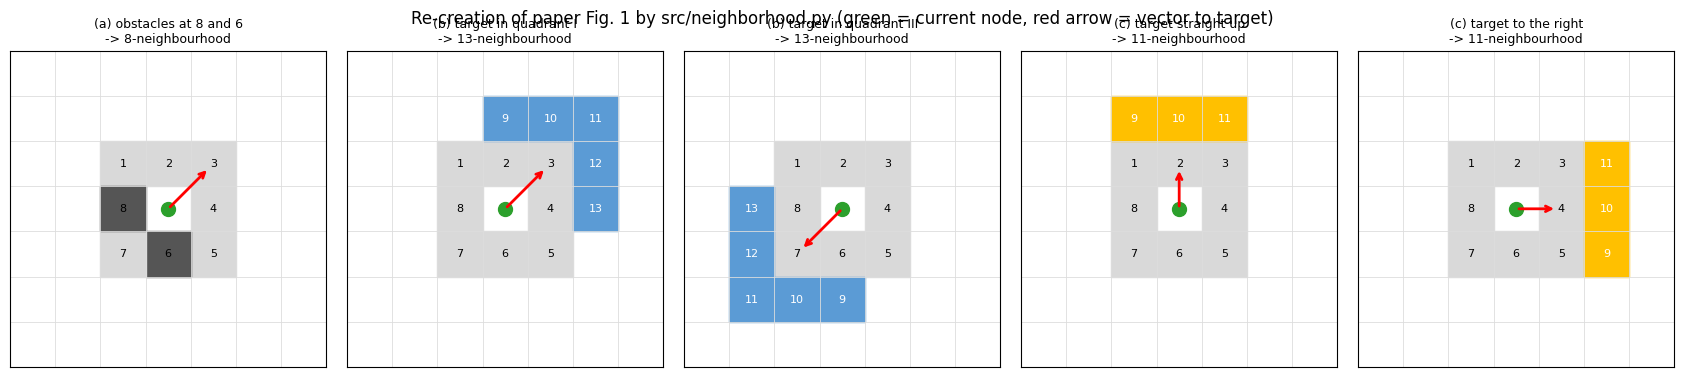

In [49]:
def draw_neigh(ax, blocked, target_vec, title):
    geo = GridGeometry(np.zeros((7, 7), dtype=np.uint8)); c0 = (3, 3)
    for (c, r) in blocked:
        geo.grid[r, c] = 1
    tgt = (c0[0] + target_vec[0], c0[1] + target_vec[1])
    nbs, mode = neighbors_81113(geo, c0, tgt)
    ax.set_xlim(-0.5, 6.5); ax.set_ylim(-0.5, 6.5); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for i in range(8):
        ax.axhline(i - .5, c="#ddd", lw=.6); ax.axvline(i - .5, c="#ddd", lw=.6)
    for k, (dc, dr) in enumerate(N8, 1):
        cell = (c0[0] + dc, c0[1] + dr)
        col = "#555" if geo.grid[cell[1], cell[0]] else "#d9d9d9"
        ax.add_patch(plt.Rectangle((cell[0] - .5, cell[1] - .5), 1, 1, color=col))
        ax.text(*cell, str(k), ha="center", va="center", fontsize=8)
    ext = [nb for nb, _ in nbs if max(abs(nb[0] - 3), abs(nb[1] - 3)) == 2]
    for j, cell in enumerate(ext, 9):
        ax.add_patch(plt.Rectangle((cell[0] - .5, cell[1] - .5), 1, 1, color="#5b9bd5" if mode == 13 else "#ffc000"))
        ax.text(*cell, str(j), ha="center", va="center", fontsize=8, color="w")
    ax.plot(*c0, "o", color="#2ca02c", ms=10)
    ax.annotate("", xy=(3 + .9 * np.sign(target_vec[0]), 3 + .9 * np.sign(target_vec[1])), xytext=c0,
                arrowprops=dict(arrowstyle="->", color="red", lw=2))
    ax.set_title(f"{title}\n-> {mode}-neighbourhood", fontsize=9)

fig, ax = plt.subplots(1, 5, figsize=(17, 3.8))
draw_neigh(ax[0], [(2, 3), (3, 2)], (5, 5), "(a) obstacles at 8 and 6")
draw_neigh(ax[1], [], (2, 3), "(b) target in quadrant I")
draw_neigh(ax[2], [], (-3, -2), "(b) target in quadrant III")
draw_neigh(ax[3], [], (0, 3), "(c) target straight up")
draw_neigh(ax[4], [], (3, 0), "(c) target to the right")
fig.suptitle("Re-creation of paper Fig. 1 by src/neighborhood.py (green = current node, red arrow = vector to target)")
fig.tight_layout(); fig.savefig(PROJECT_ROOT / "results/figures/phase3_fig1_neighbourhood.png", dpi=130); plt.show()

**Fig. 5 / Fig. 6–7 — pruning and local smoothing** on Map C (VNS-BA\* raw search path → pruned polyline → smoothed path).

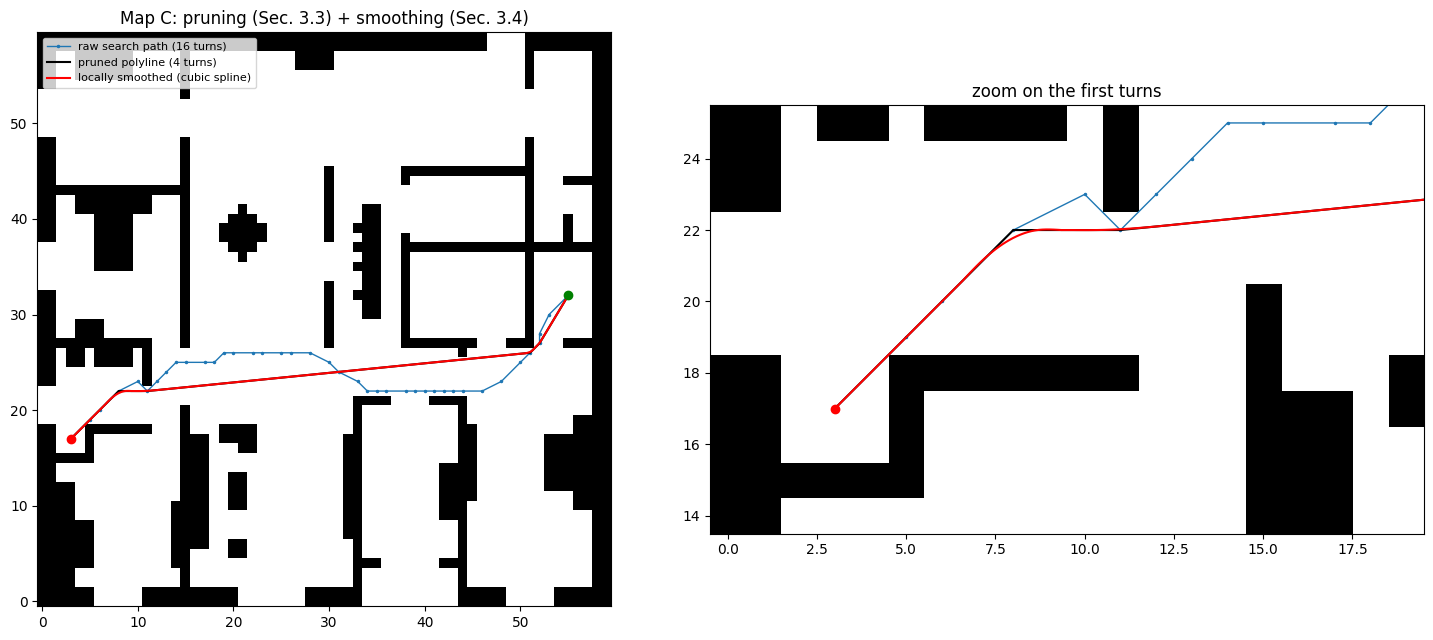

raw: 40 nodes, 16 turns, length 62.636  ->  pruned: 6 vertices, 4 turns, length 57.516  ->  smoothed length 57.374


In [50]:
r = plan(MAPS["map_C_60"], "vns_bastar")
raw, poly, fin = np.array(r["raw_path"]), np.array(r["polyline"]), np.array(r["final_path"])
m = MAPS["map_C_60"]
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
for a, (lo, hi) in zip(ax, [((0, 0), (60, 60)), ((0, 14), (20, 26))]):
    a.imshow(1 - m.grid, cmap="gray", origin="lower", extent=(-.5, 59.5, -.5, 59.5), vmin=0, vmax=1)
    a.plot(raw[:, 0], raw[:, 1], ".-", c="#1f77b4", lw=1, ms=3, label=f"raw search path ({r['raw_turns']} turns)")
    a.plot(poly[:, 0], poly[:, 1], "k-", lw=1.5, label=f"pruned polyline ({r['turns']} turns)")
    a.plot(fin[:, 0], fin[:, 1], "r-", lw=1.5, label="locally smoothed (cubic spline)")
    a.plot(*m.start, "ro"); a.plot(*m.goal, "go")
    a.set_xlim(lo[0] - .5, hi[0] - .5); a.set_ylim(lo[1] - .5, hi[1] - .5); a.set_aspect("equal")
ax[0].legend(loc="upper left", fontsize=8); ax[0].set_title("Map C: pruning (Sec. 3.3) + smoothing (Sec. 3.4)")
ax[1].set_title("zoom on the first turns")
fig.tight_layout(); fig.savefig(PROJECT_ROOT / "results/figures/phase3_pruning_smoothing.png", dpi=130); plt.show()
print(f"raw: {len(raw)} nodes, {r['raw_turns']} turns, length {r['length_raw']:.3f}  ->  pruned: {len(poly)} vertices, "
      f"{r['turns']} turns, length {r['length_polyline']:.3f}  ->  smoothed length {r['length']:.3f}")

### 3.6 Calibration study: resolving ambiguities with the paper's own numbers
The paper does not say (i) which heuristic its *traditional* A\*/BA\* use, (ii) what "Number of Nodes" counts, (iii) the exact meeting test. Because Phase 2 recovered the exact maps, we can test each reading against the published baseline numbers. This uses only the **baselines**, never the proposed method's results, so VNS-BA\* is not tuned towards its published values.

In [51]:
PUB = {  # Tables 2-5: (nodes, turns, turn_angle, time_s, length)
 "map_A_20": {"astar": (84,7,315,4.350,28.627), "improved_astar_28": (81,7,315,3.597,28.627), "bastar": (88,10,450,2.155,28.627),
              "improved_bastar_29": (91,14,630,3.247,29.213), "vns_bastar": (100,4,208.967,2.553,27.476)},
 "map_B_40": {"astar": (345,9,405,154.602,61.598), "improved_astar_28": (277,11,495,104.956,64.083), "bastar": (286,12,540,28.129,61.598),
              "improved_bastar_29": (263,18,810,33.863,61.598), "vns_bastar": (252,4,289.823,20.419,61.263)},
 "map_C_60": {"astar": (423,7,315,296.377,59.385), "improved_astar_28": (258,7,945,72.996,69.0833), "bastar": (564,8,360,212.650,59.3848),
              "improved_bastar_29": (239,21,990,22.531,61.598), "vns_bastar": (257,4,163.072,12.330,57.517)},
 "map_D_80": {"astar": (352,25,1125,108.308,103.297), "improved_astar_28": (344,27,1215,105.124,104.125), "bastar": (611,24,1080,80.221,102.125),
              "improved_bastar_29": (392,30,1350,66.982,106.225), "vns_bastar": (355,14,672.95,35.345,103.700)},
}
rows = []
for name, m in MAPS.items():
    geo = GridGeometry(m.grid); S, G = m.start, m.goal; roots = {"S": G, "G": S}
    for hname in ["manhattan", "euclid", "switch"]:
        d = {"manhattan": manhattan, "euclid": euclid, "switch": lambda a, b: switch_distance(geo, a, b)}[hname]
        ra = best_first(geo, S, G, neighbors_8, lambda n: d(n, G))
        p = PUB[name]["astar"]
        rows.append(dict(map=name, algorithm="A*", variant=f"h={hname}", expanded=ra.expanded, generated=ra.generated,
                         pub_nodes=p[0], length=round(path_length(ra.path), 3), pub_length=p[4],
                         turns=turn_metrics(ra.path)["turns"], pub_turns=p[1]))
    for meet in ["pop_closed", "open_closed", "pop_in_open"]:
        rb = bidirectional(geo, S, G, lambda gg, n, t: neighbors_8(gg, n), lambda s, n, o: manhattan(n, roots[s]), meet_rule=meet)
        p = PUB[name]["bastar"]
        rows.append(dict(map=name, algorithm="BA*", variant=f"h=manhattan, meet={meet}", expanded=rb.expanded,
                         generated=rb.generated, pub_nodes=p[0], length=round(path_length(rb.path), 3), pub_length=p[4],
                         turns=turn_metrics(rb.path)["turns"], pub_turns=p[1]))
cal = pd.DataFrame(rows)
cal["length_match"] = (cal.length - cal.pub_length).abs() < 2e-3
cal["turns_match"] = cal.turns == cal.pub_turns
cal["gen_err_%"] = (100 * (cal.generated - cal.pub_nodes) / cal.pub_nodes).round(1)
cal["exp_err_%"] = (100 * (cal.expanded - cal.pub_nodes) / cal.pub_nodes).round(1)
cal.to_csv(PROJECT_ROOT / "results/phase3/calibration.csv", index=False)
summary = cal.groupby(["algorithm", "variant"]).agg(length_matches=("length_match", "sum"), turn_matches=("turns_match", "sum"),
            mean_abs_err_generated_pct=("gen_err_%", lambda s: s.abs().mean()),
            mean_abs_err_expanded_pct=("exp_err_%", lambda s: s.abs().mean())).round(1)
display(summary)
display(cal[cal.variant.isin(["h=manhattan", "h=manhattan, meet=pop_closed"])]
        [["map", "algorithm", "generated", "pub_nodes", "length", "pub_length", "turns", "pub_turns"]])

length_matches  turn_matches  mean_abs_err_generated_pct  mean_abs_err_expanded_pct
algorithm variant                                                                                                           
A*        h=euclid                                    3             0                       128.5                       89.5
          h=manhattan                                 4             4                         1.2                       51.9
          h=switch                                    1             0                         3.8                       45.8
BA*       h=manhattan, meet=open_closed               1             1                         0.8                       58.6
          h=manhattan, meet=pop_closed                4             4                         0.1                       57.6
          h=manhattan, meet=pop_in_open               1             1                         1.8                       58.6

,map,algorithm,generated,pub_nodes,length,pub_length,turns,pub_turns
0,map_A_20,A*,83,84,28.627,28.6270,7,7
3,map_A_20,BA*,88,88,28.627,28.6270,10,10
6,map_B_40,A*,343,345,61.598,61.5980,9,9
9,map_B_40,BA*,286,286,61.598,61.5980,12,12
12,map_C_60,A*,411,423,59.385,59.3850,7,7
15,map_C_60,BA*,565,564,59.385,59.3848,8,8
18,map_D_80,A*,351,352,103.296,103.2970,25,25
21,map_D_80,BA*,612,611,102.125,102.1250,24,24


**Findings (become calibrated assumptions A24–A26):**
- **A24 — heuristic of the traditional A\* / BA\*: Manhattan.** With Manhattan, A\* matches the published length *and* number of turns on **all four maps**; the Euclid/Manhattan switch described in Sec. 2 does not (it is used only inside VNS-BA\*'s distance function, as Sec. 3.2 states).
- **A25 — "Number of Nodes" = all generated nodes (open ∪ closed)**, not only expanded nodes: errors drop from ~40–70 % to ~1 %.
- **A26 — meeting rule of BA\* (Fig. 4):** stop when the node just moved into one side's closed list is already in the other side's closed list (`pop_closed`). With it, BA\* matches nodes (±1), length and turns on all four maps. We use the same rule for VNS-BA\*, which shares the Fig. 4 flowchart.

### 3.7 First reproduction run on Maps A–D (single run each; repeated timing in Phase 4)

In [52]:
METRICS = [("nodes", 0), ("turns", 1), ("turn_angle_deg", 2), ("time_s", 3), ("length", 4)]
RESULTS, rows = {}, []
for name, m in MAPS.items():
    for alg in ALGORITHMS:
        r = plan(m, alg); RESULTS[(name, alg)] = r
        assert validate_path(m, r), f"invalid path {name} {alg}"
        p = PUB[name][alg]
        row = dict(map=name, algorithm=ALGORITHMS[alg])
        for k, i in METRICS:
            row[f"{k}"] = round(r[k], 4) if k != "time_s" else round(r[k] * 1000, 2)
            row[f"pub_{k}"] = p[i] if k != "time_s" else p[i] * 1000
        rows.append(row)
first = pd.DataFrame(rows)
first.to_csv(PROJECT_ROOT / "results/phase3/first_run.csv", index=False)
first["length_exact"] = (first.length - first.pub_length).abs() < 2e-3
first["turns_exact"] = first.turns == first.pub_turns
first["nodes_err_%"] = (100 * (first.nodes - first.pub_nodes) / first.pub_nodes).round(1)
pd.set_option("display.width", 200)
display(first[["map", "algorithm", "nodes", "pub_nodes", "nodes_err_%", "turns", "pub_turns", "turn_angle_deg",
               "pub_turn_angle_deg", "length", "pub_length", "time_s", "pub_time_s"]]
        .rename(columns={"time_s": "time_ms(ours)", "pub_time_s": "time_ms(paper)"}))
base = first[first.algorithm != "VNS-BA*"]
print(f"Baselines (16 cells): exact length {int(base.length_exact.sum())}/16, exact turns {int(base.turns_exact.sum())}/16, "
      f"median |node error| {base['nodes_err_%'].abs().median():.1f}%")
v = first[first.algorithm == "VNS-BA*"]
print(f"VNS-BA* (4 maps): turns {list(v.turns)} vs paper {list(v.pub_turns)}; nodes error {list(v['nodes_err_%'])} %")

,map,algorithm,nodes,pub_nodes,nodes_err_%,turns,pub_turns,turn_angle_deg,pub_turn_angle_deg,length,pub_length,time_ms(ours),time_ms(paper)
0,map_A_20,A*,83,84,-1.2,7,7,315.0000,315.000,28.6274,28.6270,0.30,4350.0
1,map_A_20,Improved A* [28],82,81,1.2,9,7,405.0000,315.000,29.2132,28.6270,0.22,3597.0
2,map_A_20,BA*,88,88,0.0,10,10,450.0000,450.000,28.6274,28.6270,0.23,2155.0
3,map_A_20,Improved BA* [29],92,91,1.1,14,14,630.0000,630.000,29.2132,29.2130,0.71,3247.0
4,map_A_20,VNS-BA*,89,100,-11.0,5,4,114.8927,208.967,28.5253,27.4760,4.83,2553.0
5,map_B_40,A*,343,345,-0.6,9,9,405.0000,405.000,61.5980,61.5980,1.65,154602.0
6,map_B_40,Improved A* [28],278,277,0.4,11,11,495.0000,495.000,64.0833,64.0830,1.07,104956.0
7,map_B_40,BA*,286,286,0.0,12,12,540.0000,540.000,61.5980,61.5980,0.98,28129.0
8,map_B_40,Improved BA* [29],265,263,0.8,18,18,810.0000,810.000,61.5980,61.5980,2.35,33863.0
9,map_B_40,VNS-BA*,195,252,-22.6,7,4,132.2058,289.823,58.6000,61.2630,13.28,20419.0


Baselines (16 cells): exact length 14/16, exact turns 13/16, median |node error| 0.6%
VNS-BA* (4 maps): turns [5, 7, 4, 15] vs paper [4, 4, 4, 14]; nodes error [-11.0, -22.6, -0.8, 3.7] %


**Reading the first run**
- **Baselines** reproduce the published paths almost exactly. The two remaining cells (Improved A\* Map A, Improved BA\* Map C) depend on tie-breaking inside [28]/[29], which neither paper specifies. Improved A\* on Map C has the published **945° turn angle** exactly with **18** turns (paper prints 7) — confirming the Phase 1 suspicion that "7" is a typo (945° cannot come from 7 turns of ≤ 135°).
- **VNS-BA\*** produces the same character of result as the paper — few turns (4–15), node counts in the same range, collision-free smoothed paths — but not identical numbers, because several of its internals remain genuinely unspecified (A1, A2, A5–A7, A19–A22). Its path lengths are any-angle lengths after pruning, so they can be *below* the optimal grid length (e.g. Map C 57.37 vs A\* 59.39).
- **Time** is not comparable in absolute terms: our Python planners run in milliseconds, the paper reports seconds to minutes (Phase 1, Check 4). Phase 4 measures relative times with repeated runs.

### 3.8 Paper-style result figures (cf. paper Figs. 8–11)\nYellow = cells closed by the forward search (from start), blue = backward search (from goal), black = planned path, red = locally smoothed sections of VNS-BA\*.

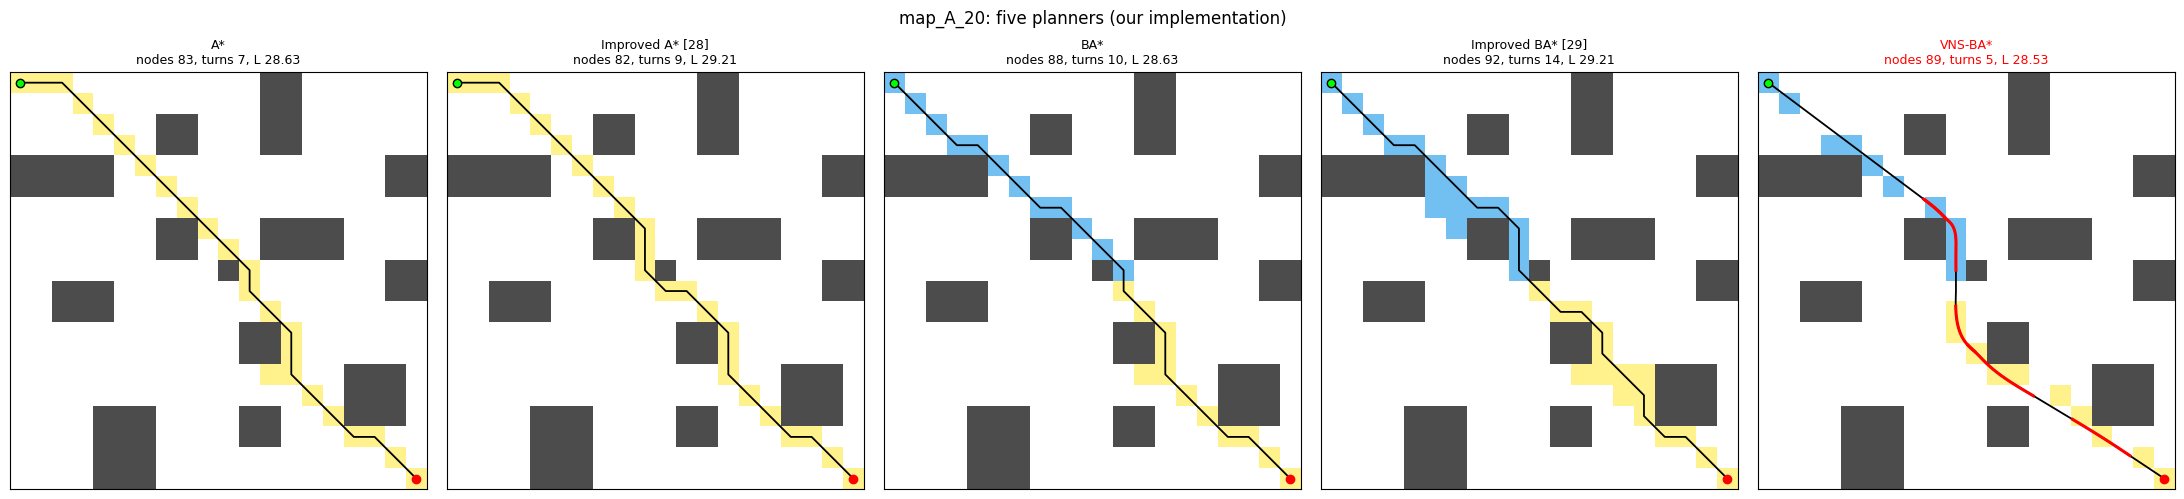

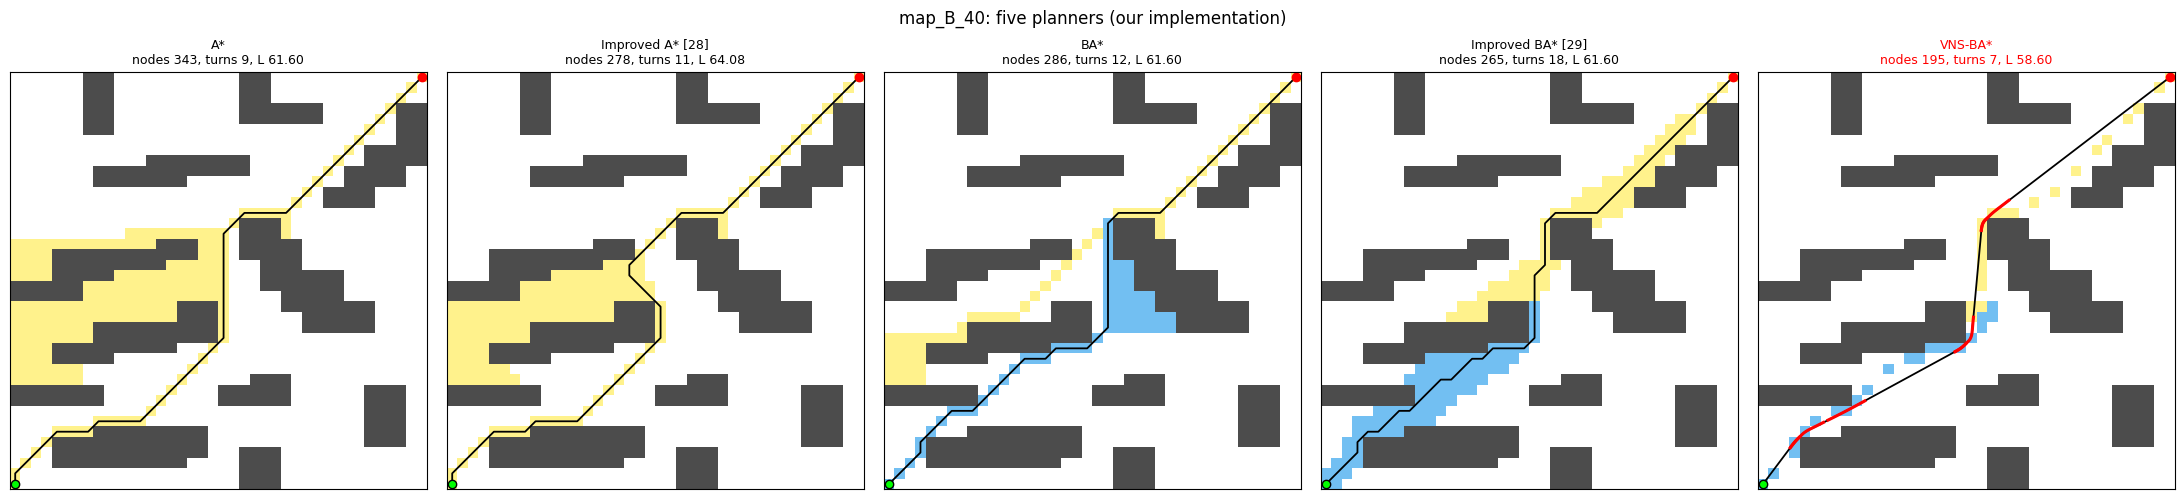

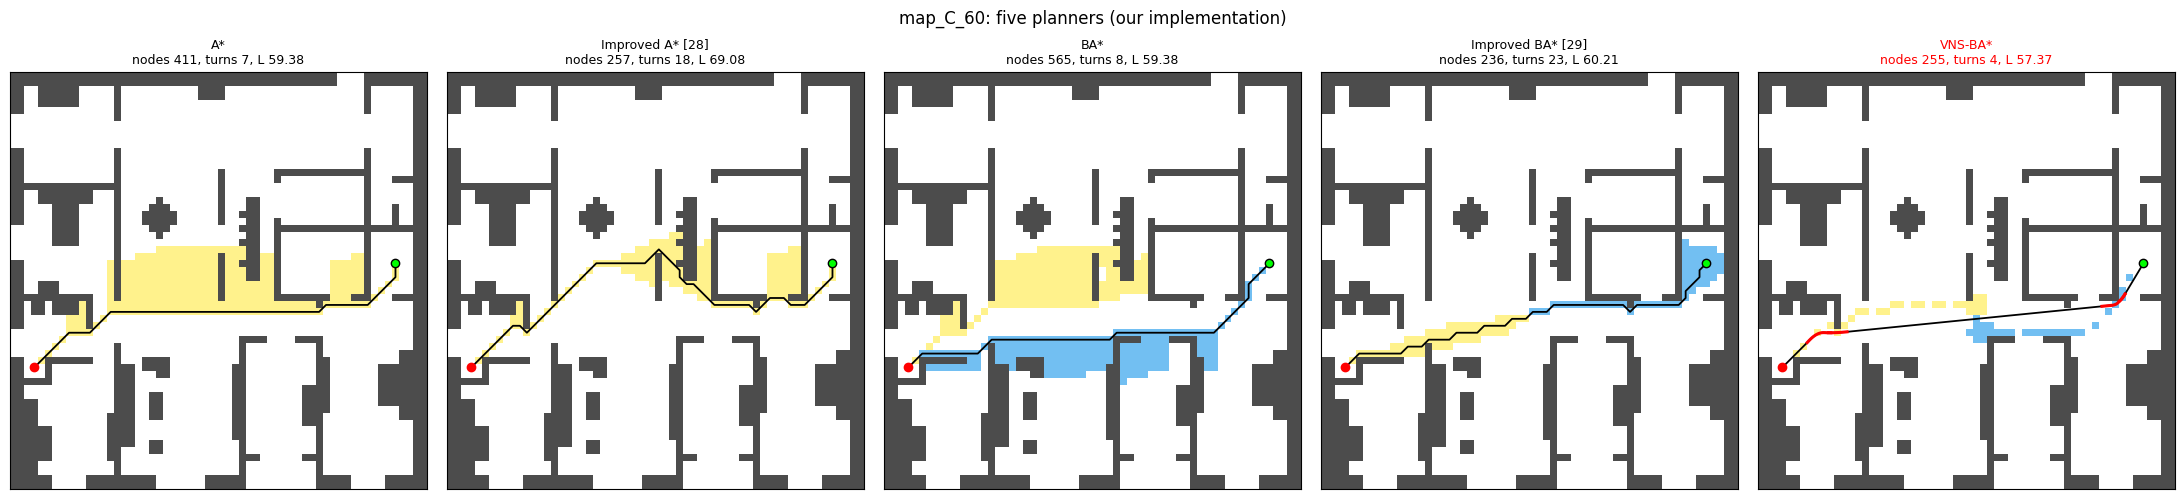

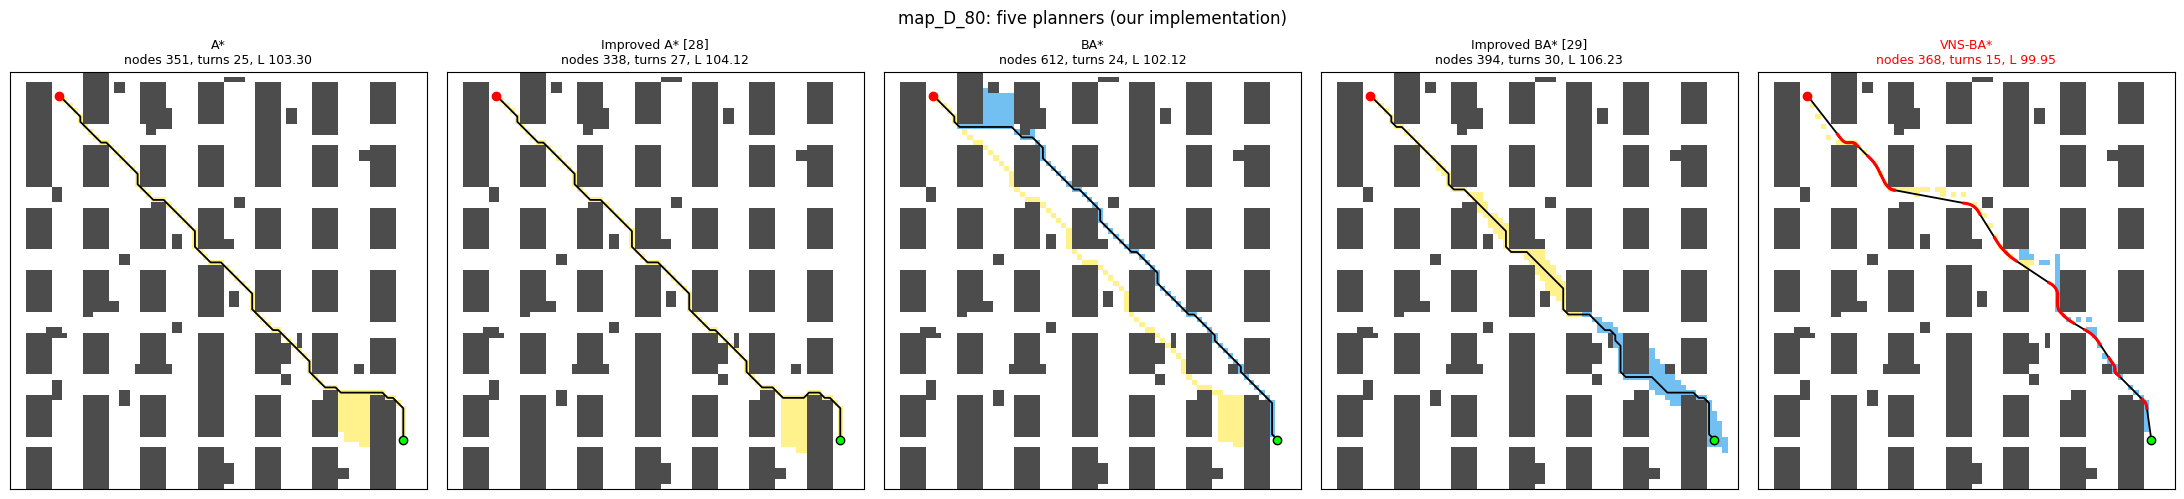

In [53]:
def show_map_results(name):
    m = MAPS[name]; n = m.size
    fig, axes = plt.subplots(1, 5, figsize=(22, 4.8))
    for ax, alg in zip(axes, ALGORITHMS):
        r = RESULTS[(name, alg)]
        img = np.ones((n, n, 3)); img[m.grid == 1] = (0.3, 0.3, 0.3)
        for side, col in (("S", (1.0, 0.95, 0.55)), ("G", (0.45, 0.75, 0.95))):
            for (c, rr) in r["closed"].get(side, ()):
                if m.grid[rr, c] == 0:
                    img[rr, c] = col
        ax.imshow(img, origin="lower", extent=(-.5, n - .5, -.5, n - .5), interpolation="nearest")
        poly = np.array(r["polyline"]); fin = np.array(r["final_path"])
        ax.plot(fin[:, 0], fin[:, 1], "k-", lw=1.3)
        if r["smooth"]:                      # highlight only the spline sections around each turn
            for t in r["turn_info"]:
                if t["smoothed"]:
                    v = np.array(t["vertex"]); near = np.hypot(*(fin - v).T) <= 2 * t["offset"] + 0.05
                    seg = fin[near]
                    ax.plot(seg[:, 0], seg[:, 1], "r-", lw=2.2)
        ax.plot(*m.start, "o", c="red", ms=6); ax.plot(*m.goal, "o", c="lime", mec="k", ms=6)
        ax.set_title(f"{ALGORITHMS[alg]}\nnodes {r['nodes']}, turns {r['turns']}, L {r['length']:.2f}", fontsize=9,
                     color="red" if alg == "vns_bastar" else "black")
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"{name}: five planners (our implementation)", y=1.03)
    fig.tight_layout(); fig.savefig(PROJECT_ROOT / f"results/figures/phase3_{name}_five_planners.png", dpi=110, bbox_inches="tight"); plt.show()

for name in MAP_NAMES:
    show_map_results(name)

### 3.9 Assumption register, configuration and README

In [54]:
import yaml
reg_path = PROJECT_ROOT / "docs" / "ambiguity_register.csv"
reg = pd.read_csv(reg_path) if reg_path.exists() else pd.DataFrame(columns=["id", "section", "issue", "our_assumption", "impact_on_reproduction"])
updates = pd.DataFrame([
 ("A1", "Sec 3.2", "Definition of obstacle density rho", "IMPLEMENTED: obstacle cells / cells of the inclusive rectangle between n and opposite current node (integral image)", "Medium"),
 ("A2", "Sec 3.1", "Move cost of 11/13 extension cells", "IMPLEMENTED: Euclidean (2, sqrt5, 2sqrt2)", "Medium"),
 ("A3", "Fig 4", "Expansion order of the two fronts", "IMPLEMENTED: strict alternation, forward first", "Low"),
 ("A4", "Sec 3.3", "Segment-obstacle test", "IMPLEMENTED: exact cell traversal; positive-length overlap = crossing, corner touch allowed", "Medium"),
 ("A5", "Sec 3.4", "Spline y=S(x) fails for vertical turns", "IMPLEMENTED: parametric natural cubic spline, chord-length parameter, own solver", "High"),
 ("A6", "Eq 11", "Missing boundary conditions; duplicated S'' line", "IMPLEMENTED: natural boundary; second line read as S' continuity", "High"),
 ("A7", "Sec 3.4", "Position of P1-P4", "IMPLEMENTED: P2/P3 at 1 cell, P1/P4 at 2 cells from the corner, clipped to 45% of the segment", "Medium"),
 ("A8", "Sec 3.1", "Blocked extension cells", "IMPLEMENTED: skipped", "Low"),
 ("A9", "Fig 4", "Meeting rule & path join", "SUPERSEDED by A26", "Medium"),
 ("A11", "Sec 4", "Turn / turn-angle definition", "Turn = heading change at a vertex; angle = sum of |delta heading|. Confirmed by exact baseline matches (e.g. 1215 deg / 27 turns)", "Resolved"),
 ("A13", "Sec 4", "Weight mu of [29]", "IMPLEMENTED: mu = e^rho, rho between node and that side's target, as the paper states", "Medium"),
 ("A15", "Sec 3.2", "'Opposite start'", "IMPLEMENTED: forward side uses G, backward side uses S", "Low"),
 ("A18", "[28]", "5-direction neighbourhood may make the search incomplete", "If the 5-direction search fails, rerun with 8 directions (never triggered on Maps A-D)", "Low"),
 ("A19", "Sec 3.1", "Target of the 8-11-13 direction vector in bidirectional search", "Opposite front's current node (the target used by the heuristic)", "Medium"),
 ("A20", "Sec 3.2", "Open-list f values become stale as the opposite current node moves", "f evaluated when a node is generated; no open-list re-evaluation", "Medium"),
 ("A21", "Sec 4", "Which path the VNS-BA* metrics refer to", "Turns/angle on the pruned polyline (smoothing keeps turn count); length on the smoothed path", "Medium"),
 ("A22", "Sec 3.4", "Smoothed curve could hit an obstacle", "Collision-check the curve; halve offsets up to 3 times, else keep the corner", "Low"),
 ("A24", "Sec 2/4", "Heuristic of the traditional A* and BA*", "CALIBRATED: Manhattan - reproduces published length and turns of A* and BA* on all 4 maps", "Resolved"),
 ("A25", "Sec 4", "Meaning of 'Number of Nodes'", "CALIBRATED: all generated nodes (open + closed); expanded-only is 40-70% too low", "Resolved"),
 ("A26", "Fig 4", "Exact meeting test", "CALIBRATED: node just closed by one side is already closed by the other; reproduces BA* nodes +-1", "Resolved"),
 ("A27", "[28]", "Angle used to choose the 5 directions of [28]", "Angle from the current node to the goal; keep the 5 directions within the smallest angular difference", "Low"),
], columns=["id", "section", "issue", "our_assumption", "impact_on_reproduction"])
reg = pd.concat([reg[~reg.id.isin(updates.id)], updates], ignore_index=True)
reg["_k"] = reg.id.str[1:].astype(int); reg = reg.sort_values("_k").drop(columns="_k")
reg.to_csv(reg_path, index=False)
print(f"ambiguity register: {len(reg)} entries")
display(reg[reg.id.isin(updates.id)][["id", "issue", "our_assumption", "impact_on_reproduction"]])

cfg_file = PROJECT_ROOT / "configs" / "params.yaml"
cfg = yaml.safe_load(cfg_file.read_text()) if cfg_file.exists() else {}
cfg.setdefault("heuristic", {}).update(omega=0.5, eta=0.5, obstacle_density="obstacle_cells / rectangle_cells (A1)")
cfg.setdefault("bidirectional", {}).update(expansion_order="alternate_forward_first", meet_rule="pop_closed (A26)",
                                            f_evaluation="at_generation (A20)")
cfg["baselines"] = {"astar": {"heuristic": "manhattan (A24)"}, "bastar": {"heuristic": "manhattan (A24)", "meet_rule": "pop_closed"},
                    "improved_astar_28": {"neighbourhood": "5 directions towards goal (A27)", "f": "g + e^P * Manhattan"},
                    "improved_bastar_29": {"h": "e^rho * (Euclid + perpendicular distance to SG) (A13)", "meet_rule": "pop_in_open"}}
cfg.setdefault("post_processing", {}).update(spline_offset_cells=1.0, outer_factor=2.0, collision_retries=3)
cfg["metrics"] = {"nodes": "generated (open+closed) (A25)", "turns": "pruned polyline (A21)", "length": "final (smoothed) path"}
cfg_file.write_text(yaml.safe_dump(cfg, sort_keys=False))
print("configs/params.yaml updated")

req = PROJECT_ROOT / "requirements.txt"
lines = set(req.read_text().split()) if req.exists() else set()
if not any(l.startswith("pytest") for l in lines):
    import pytest as _pt
    lines.add(f"pytest=={_pt.__version__}")
for lib in ["opencv-python-headless", "pymupdf"]:
    if not any(l.lower().startswith(lib) for l in lines):
        lines.add(lib)
req.write_text("\n".join(sorted(lines)) + "\n")
print("requirements.txt:", sorted(lines))

ambiguity register: 26 entries


,id,issue,our_assumption,impact_on_reproduction
5,A1,Definition of obstacle density rho,IMPLEMENTED: obstacle cells / cells of the inc...,Medium
6,A2,Move cost of 11/13 extension cells,"IMPLEMENTED: Euclidean (2, sqrt5, 2sqrt2)",Medium
7,A3,Expansion order of the two fronts,"IMPLEMENTED: strict alternation, forward first",Low
8,A4,Segment-obstacle test,IMPLEMENTED: exact cell traversal; positive-le...,Medium
9,A5,Spline y=S(x) fails for vertical turns,"IMPLEMENTED: parametric natural cubic spline, ...",High
10,A6,Missing boundary conditions; duplicated S'' line,IMPLEMENTED: natural boundary; second line rea...,High
11,A7,Position of P1-P4,"IMPLEMENTED: P2/P3 at 1 cell, P1/P4 at 2 cells...",Medium
12,A8,Blocked extension cells,IMPLEMENTED: skipped,Low
13,A9,Meeting rule & path join,SUPERSEDED by A26,Medium
14,A11,Turn / turn-angle definition,Turn = heading change at a vertex; angle = sum...,Resolved


configs/params.yaml updated
requirements.txt: ['matplotlib==3.10.8', 'numpy==2.4.4', 'opencv-python-headless', 'pandas==3.0.2', 'pymupdf', 'pytest==9.1.1', 'pyyaml==6.0.3', 'requests==2.33.1', 'scipy==1.17.1']


In [55]:
readme_p = PROJECT_ROOT / "README.md"
txt = readme_p.read_text() if readme_p.exists() else "# VNS-BA* - Independent Re-Implementation\n"
txt = txt.replace("| 2 | Map reconstruction (dataset) | pending |", "| 2 | Map reconstruction (dataset) | done |")
txt = txt.replace("| 3 | Core implementation | pending |", "| 3 | Core implementation, tests, calibration | done |")
if "## Implementation" not in txt:
    txt += '''
## Implementation (Phase 3)
| Module | Content |
|---|---|
| `src/geometry.py` | line of sight (corner touch allowed), obstacle density via integral image |
| `src/neighborhood.py` | 8, adaptive 8-11-13 (VNS-BA*), 5-direction ([28]) neighbourhoods |
| `src/search.py` | unidirectional and bidirectional best-first engines |
| `src/postprocess.py` | polyline pruning, local natural cubic-spline smoothing (own solver) |
| `src/metrics.py` | nodes, turns, turn angle, length, improvement ratio |
| `src/planners.py` | A*, Improved A* [28], BA*, Improved BA* [29], VNS-BA*; `plan()` runner |

Quick use:
```python
from src.grid_map import GridMap
from src.planners import plan
r = plan(GridMap.load("maps", "map_C_60"), "vns_bastar")
print(r["nodes"], r["turns"], r["turn_angle_deg"], r["length"], r["time_s"])
```
Tests: `python -m pytest -q tests`
'''
readme_p.write_text(txt)
b = first[first.algorithm != "VNS-BA*"]
summary = f'''# Phase 3 - Implementation summary ({RUN_DATE})
- Modules: geometry, neighborhood, search, postprocess, metrics, planners (src/)
- Unit tests: {proc.stdout.strip().splitlines()[-1]}
- Calibrated from baseline numbers only: A24 Manhattan heuristic for A*/BA*, A25 nodes = generated, A26 meeting rule
- Baselines on Maps A-D: exact length {int(b.length_exact.sum())}/16, exact turns {int(b.turns_exact.sum())}/16,
  median node error {b["nodes_err_%"].abs().median():.1f}%
- VNS-BA* turns {list(first[first.algorithm=="VNS-BA*"].turns)} (paper [4, 4, 4, 14]),
  nodes {list(first[first.algorithm=="VNS-BA*"].nodes)} (paper [100, 252, 257, 355])
- Paper typo confirmed: Improved A* Map C = 945 deg with 18 turns (paper prints 7 turns)
'''
(PROJECT_ROOT / "docs" / "phase3_summary.md").write_text(summary)
print(summary)

# Phase 3 - Implementation summary (2026-10-23)
- Modules: geometry, neighborhood, search, postprocess, metrics, planners (src/)
- Unit tests: 91 passed in 1.12s
- Calibrated from baseline numbers only: A24 Manhattan heuristic for A*/BA*, A25 nodes = generated, A26 meeting rule
- Baselines on Maps A-D: exact length 14/16, exact turns 13/16,
  median node error 0.6%
- VNS-BA* turns [5, 7, 4, 15] (paper [4, 4, 4, 14]),
  nodes [89, 195, 255, 368] (paper [100, 252, 257, 355])
- Paper typo confirmed: Improved A* Map C = 945 deg with 18 turns (paper prints 7 turns)



---
# Part 4  Experimental Reproduction
**Objective.** Reproduce the experiments of the article (weight sweep, Tables 2–6, Fig. 12) with repeated timing runs, and extend them with a fair-comparison protocol, an ablation, 120 seeded random maps with significance tests, an analysis of the published planning times, and the two method-level comparisons of the article (E7).

**Outputs.** `experiments/`, `results/phase4/`, `results/figures/phase4_*.png`.

## Part 4  Experimental Reproduction
**Paper:** Li, Li & Dai, *VNS-BA\**, Sensors 24(21):6929, 2024.

| Exp. | Question | Paper counterpart |
|---|---|---|
| **E1** | Which (ω, η) is best? | Table 1, Fig. 3 |
| **E2** | Do we reproduce the per-map results? (30 timing repeats) | Tables 2–5, Figs. 8–11 |
| **E3** | Do we reproduce the improvement ratios? | Table 6, Fig. 12 |
| **E4** | *Fair comparison & ablation:* where do the gains come from? | — (our addition) |
| **E5** | Do conclusions hold on 120 random maps, with significance tests? | — (our addition) |
| **E6** | Why can the published times not be reproduced? | Phase 1, Check 4 |
| **E7** | Do the method-level comparisons of Sec. 3.2/3.3 hold? | Figs. 2 and 5 |

All experiments are Python scripts in `experiments/` (runnable without the notebook: `python -m experiments.run_all --repeats 30`). The notebook writes them, runs them, and shows tables and figures. Runtime on Colab CPU: about 1–2 minutes.

### 4.0 Setup (needs Phases 2 and 3)

In [56]:
import os, sys, json, datetime, importlib, subprocess, time
from pathlib import Path
USE_DRIVE = True
PROJECT_NAME = "vns-ba-reproduction"
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive') / PROJECT_NAME
elif IN_COLAB:
    PROJECT_ROOT = Path('/content') / PROJECT_NAME
else:
    PROJECT_ROOT = Path.cwd() if Path.cwd().name == PROJECT_NAME else Path.cwd() / PROJECT_NAME
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
need = ["maps/map_A_20.txt", "maps/random/index.csv", "src/planners.py", "src/search.py", "tests/test_core.py"]
missing = [p for p in need if not (PROJECT_ROOT / p).exists()]
if missing:
    raise FileNotFoundError(f"Run Phases 2 and 3 first - missing: {missing}")
(PROJECT_ROOT / "experiments").mkdir(exist_ok=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
RUN_DATE = datetime.date.today().isoformat()
REPEATS = 30            # timing repeats per (map, planner) for E2 - paper: single run
print("Project root:", PROJECT_ROOT, "| scipy", scipy.__version__)

Project root: /tmp/userrun/vns-ba-reproduction | scipy 1.17.1


### 4.1 Experiment scripts (`experiments/`)
`common.py` holds the published numbers of Tables 1–6 / Fig. 12 (one place, used by every comparison) and the timing helper: every run rebuilds all caches, metrics come from the first run (the planners are deterministic) and time is the **median of the repeats**.

In [57]:
%%writefile experiments/__init__.py
# experiment scripts package


Overwriting experiments/__init__.py


In [58]:
%%writefile experiments/common.py
"""Shared helpers for all experiment scripts: paths, config, published values, timing."""
from __future__ import annotations
import json
import platform
import statistics
import sys
import time
from pathlib import Path

import numpy as np
import yaml

ROOT = Path(__file__).resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.grid_map import GridMap                     # noqa: E402
from src.planners import plan, ALGORITHMS, validate_path   # noqa: E402

RESULTS = ROOT / "results" / "phase4"
FIGURES = ROOT / "results" / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

MAP_NAMES = ["map_A_20", "map_B_40", "map_C_60", "map_D_80"]
MAP_LABEL = {"map_A_20": "A (20x20)", "map_B_40": "B (40x40)", "map_C_60": "C (60x60)", "map_D_80": "D (80x80)"}
METRICS = ["nodes", "turns", "turn_angle_deg", "time_s", "length"]
METRIC_LABEL = {"nodes": "Number of nodes", "turns": "Number of turns", "turn_angle_deg": "Turn angle (deg)",
                "time_s": "Planning time (s)", "length": "Path length"}

# --- published values, Tables 1-6 and Fig. 12 of Li, Li & Dai (2024) --------------------------
PUBLISHED = {  # (nodes, turns, turn_angle_deg, time_s, length)
    "map_A_20": {"astar": (84, 7, 315, 4.350, 28.627), "improved_astar_28": (81, 7, 315, 3.597, 28.627),
                 "bastar": (88, 10, 450, 2.155, 28.627), "improved_bastar_29": (91, 14, 630, 3.247, 29.213),
                 "vns_bastar": (100, 4, 208.967, 2.553, 27.476)},
    "map_B_40": {"astar": (345, 9, 405, 154.602, 61.598), "improved_astar_28": (277, 11, 495, 104.956, 64.083),
                 "bastar": (286, 12, 540, 28.129, 61.598), "improved_bastar_29": (263, 18, 810, 33.863, 61.598),
                 "vns_bastar": (252, 4, 289.823, 20.419, 61.263)},
    "map_C_60": {"astar": (423, 7, 315, 296.377, 59.385), "improved_astar_28": (258, 7, 945, 72.996, 69.0833),
                 "bastar": (564, 8, 360, 212.650, 59.3848), "improved_bastar_29": (239, 21, 990, 22.531, 61.598),
                 "vns_bastar": (257, 4, 163.072, 12.330, 57.517)},
    "map_D_80": {"astar": (352, 25, 1125, 108.308, 103.297), "improved_astar_28": (344, 27, 1215, 105.124, 104.125),
                 "bastar": (611, 24, 1080, 80.221, 102.125), "improved_bastar_29": (392, 30, 1350, 66.982, 106.225),
                 "vns_bastar": (355, 14, 672.95, 35.345, 103.700)},
}
PUBLISHED_TABLE6 = {  # VNS-BA* improvement ratio (%) vs algorithm, per map: nodes, turns, angle, time, length
    "astar": {"map_A_20": (-19.05, 42.86, 33.67, 41.31, 4.02), "map_B_40": (26.96, 55.56, 28.44, 86.80, 0.54),
              "map_C_60": (39.24, 42.86, 48.23, 95.84, 3.14), "map_D_80": (-0.85, 44.00, 39.91, 67.37, -0.39)},
    "improved_astar_28": {"map_A_20": (-23.46, 42.86, 33.67, 29.02, 4.02), "map_B_40": (9.02, 63.63, 41.45, 80.55, 4.40),
                          "map_C_60": (0.39, 42.86, 82.74, 83.11, 10.83), "map_D_80": (3.20, 48.15, 44.61, 66.38, 4.08)},
    "bastar": {"map_A_20": (-13.64, 60.0, 53.56, -18.47, 4.02), "map_B_40": (11.89, 66.67, 46.33, 27.40, 0.54),
               "map_C_60": (54.43, 50.0, 54.70, 94.20, 1.869), "map_D_80": (41.90, 41.67, 50.15, 55.94, -1.54)},
    "improved_bastar_29": {"map_A_20": (-9.89, 71.43, 66.83, 21.37, 5.98), "map_B_40": (4.18, 77.78, 64.22, 39.70, 0.54),
                           "map_C_60": (-7.53, 80.96, 83.53, 45.28, 6.63), "map_D_80": (9.44, 53.33, 50.15, 47.23, 2.38)},
}
PUBLISHED_FIG12 = {"map_A_20": (20.56, 17.22, 17.09, 31.14), "map_B_40": (39.66, 39.81, 30.57, 37.28),
                   "map_C_60": (45.86, 43.99, 51.04, 41.77), "map_D_80": (37.72, 33.28, 37.62, 32.51)}
PUBLISHED_TABLE1 = {  # (omega, eta): (avg nodes, avg time s, avg length)
    (0.0, 1.0): (97.5, 1.6526, 24.4121), (0.1, 0.9): (92.5, 1.8305, 25.1159), (0.2, 0.8): (91.75, 1.8056, 24.0503),
    (0.3, 0.7): (89, 1.7324, 24.1349), (0.4, 0.6): (79.75, 1.2657, 24.1159), (0.5, 0.5): (78, 0.9382, 24.2818),
    (0.6, 0.4): (83, 1.2025, 25.3870), (0.7, 0.3): (81.75, 1.2419, 24.3708), (0.8, 0.2): (83.75, 1.2762, 25.4154),
    (0.9, 0.1): (85.25, 1.2658, 25.3154), (1.0, 0.0): (85.5, 1.3067, 25.7689),
}


def load_config():
    p = ROOT / "configs" / "params.yaml"
    return yaml.safe_load(p.read_text()) if p.exists() else {}


def load_map(name):
    folder = ROOT / "maps" / ("random" if name.startswith("rand_") else "")
    return GridMap.load(folder, name)


def timed_plan(grid_map, algorithm, repeats=1, **kw):
    """Run plan() `repeats` times; metrics from the first run (planners are deterministic),
    timing statistics over all runs.  Each run rebuilds all caches, so runs are independent."""
    times, first = [], None
    for i in range(repeats):
        r = plan(grid_map, algorithm, **kw)
        times.append(r["time_s"])
        if first is None:
            first = r
    first["valid"] = validate_path(grid_map, first)
    first["time_s"] = statistics.median(times)
    first["time_mean_s"] = statistics.fmean(times)
    first["time_std_s"] = statistics.stdev(times) if len(times) > 1 else 0.0
    first["repeats"] = repeats
    return first


def flat(r, **extra):
    """Keep only scalar fields of a planner result (for CSV)."""
    keep = ["algorithm", "name", "map", "success", "valid", "nodes", "expanded", "generated", "turns",
            "turn_angle_deg", "turn_angle_45conv", "time_s", "time_mean_s", "time_std_s", "repeats",
            "length", "length_polyline", "length_raw", "raw_turns", "prune", "smooth"]
    d = {k: r.get(k) for k in keep}
    d.update(extra)
    return d


def improvement(other, ours):
    return (other - ours) / other * 100.0 if other else float("nan")


def environment():
    import numpy, scipy
    return dict(python=sys.version.split()[0], platform=platform.platform(), processor=platform.processor(),
                numpy=numpy.__version__, scipy=scipy.__version__,
                time=time.strftime("%Y-%m-%d %H:%M:%S"))


def save_json(obj, name):
    (RESULTS / name).write_text(json.dumps(obj, indent=2, default=str))


Writing experiments/common.py


In [59]:
%%writefile experiments/run_weight_sweep.py
"""E1 - Reproduce Table 1: sweep (omega, eta) on the four Fig. 3 tuning maps.

    python -m experiments.run_weight_sweep --repeats 10
Output: results/phase4/weight_sweep.csv (per map) and weight_sweep_summary.csv (averages, as Table 1)
"""
from __future__ import annotations
import argparse
import pandas as pd

from experiments.common import RESULTS, PUBLISHED_TABLE1, load_map, timed_plan, flat

TUNING = ["tune_a", "tune_b", "tune_c", "tune_d"]


def run(repeats=10, step=0.1):
    pairs = [(round(i * step, 2), round(1 - i * step, 2)) for i in range(int(round(1 / step)) + 1)]
    rows = []
    for w, e in pairs:
        for name in TUNING:
            r = timed_plan(load_map(name), "vns_bastar", repeats, omega=w, eta=e)
            rows.append(flat(r, omega=w, eta=e))
    df = pd.DataFrame(rows)
    df.to_csv(RESULTS / "weight_sweep.csv", index=False)
    s = df.groupby(["omega", "eta"]).agg(avg_nodes=("nodes", "mean"), avg_time_s=("time_s", "mean"),
                                         avg_length=("length", "mean"), avg_turns=("turns", "mean"),
                                         all_valid=("valid", "all")).reset_index()
    s["pub_avg_nodes"] = [PUBLISHED_TABLE1[(w, e)][0] for w, e in zip(s.omega, s.eta)]
    s["pub_avg_time_s"] = [PUBLISHED_TABLE1[(w, e)][1] for w, e in zip(s.omega, s.eta)]
    s["pub_avg_length"] = [PUBLISHED_TABLE1[(w, e)][2] for w, e in zip(s.omega, s.eta)]
    s.to_csv(RESULTS / "weight_sweep_summary.csv", index=False)
    return df, s


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--repeats", type=int, default=10)
    print(run(ap.parse_args().repeats)[1])


Writing experiments/run_weight_sweep.py


In [60]:
%%writefile experiments/run_main.py
"""E2/E3 - Reproduce Tables 2-6 and Fig. 12 on the reconstructed Maps A-D.

    python -m experiments.run_main --repeats 30
Outputs: results/phase4/main_results.csv, table6_ours.csv, fig12_ours.csv
"""
from __future__ import annotations
import argparse
import pandas as pd

from experiments.common import (MAP_NAMES, METRICS, PUBLISHED, PUBLISHED_TABLE6, PUBLISHED_FIG12, ALGORITHMS,
                                RESULTS, load_map, timed_plan, flat, improvement, environment, save_json)


def run(repeats=30, verbose=True):
    rows = []
    for name in MAP_NAMES:
        m = load_map(name)
        for alg in ALGORITHMS:
            r = timed_plan(m, alg, repeats)
            pub = dict(zip(METRICS, PUBLISHED[name][alg]))
            row = flat(r)
            row.update({f"pub_{k}": v for k, v in pub.items()})
            rows.append(row)
            if verbose:
                print(f"{name} {ALGORITHMS[alg]:18s} nodes {r['nodes']:4d} turns {r['turns']:3d} "
                      f"angle {r['turn_angle_deg']:8.2f} len {r['length']:8.3f} "
                      f"time {1000*r['time_s']:7.2f} ms (+-{1000*r['time_std_s']:.2f}) valid={r['valid']}")
    df = pd.DataFrame(rows)
    df.to_csv(RESULTS / "main_results.csv", index=False)

    # Table 6 (ours) and comparison with the published Table 6
    t6 = []
    for name in MAP_NAMES:
        vns = df[(df["map"] == name) & (df.algorithm == "vns_bastar")].iloc[0]
        for alg in [a for a in ALGORITHMS if a != "vns_bastar"]:
            o = df[(df["map"] == name) & (df.algorithm == alg)].iloc[0]
            row = dict(map=name, compared_to=alg)
            for i, k in enumerate(METRICS):
                row[k] = round(improvement(o[k], vns[k]), 2)
                row[f"pub_{k}"] = PUBLISHED_TABLE6[alg][name][i]
            row["comprehensive"] = round(sum(row[k] for k in METRICS) / len(METRICS), 2)
            row["comprehensive_no_time"] = round(sum(row[k] for k in METRICS if k != "time_s") / 4, 2)
            row["pub_comprehensive_no_time"] = round(sum(row[f"pub_{k}"] for k in METRICS if k != "time_s") / 4, 2)
            row["pub_comprehensive_fig12"] = PUBLISHED_FIG12[name][list(ALGORITHMS).index(alg)]
            t6.append(row)
    t6 = pd.DataFrame(t6)
    t6.to_csv(RESULTS / "table6_ours.csv", index=False)
    save_json(dict(environment=environment(), repeats=repeats), "main_meta.json")
    return df, t6


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--repeats", type=int, default=30)
    args = ap.parse_args()
    df, t6 = run(args.repeats)
    print(t6[["map", "compared_to", "comprehensive", "pub_comprehensive_fig12"]])


Writing experiments/run_main.py


In [61]:
%%writefile experiments/run_ablation.py
"""E4 - Fair-comparison and ablation study (our addition; not in the paper).

The paper applies pruning + smoothing only to VNS-BA*.  Here we (a) give every baseline the same
post-processing, and (b) switch off VNS-BA* components one at a time, to see which part of the
method produces the reported gains.  Also includes (c) a sensitivity check of the unspecified details.

    python -m experiments.run_ablation --repeats 10
Output: results/phase4/ablation.csv
"""
from __future__ import annotations
import argparse
import pandas as pd

from experiments.common import MAP_NAMES, RESULTS, load_map, timed_plan, flat

VARIANTS = {
    # (a) fair comparison: same post-processing for everybody
    "A* + prune + smooth":          ("astar", dict(prune=True, smooth=True)),
    "Improved A* [28] + prune + smooth": ("improved_astar_28", dict(prune=True, smooth=True)),
    "BA* + prune + smooth":         ("bastar", dict(prune=True, smooth=True)),
    "Improved BA* [29] + prune + smooth": ("improved_bastar_29", dict(prune=True, smooth=True)),
    # (b) ablation of VNS-BA*
    "VNS-BA* (full)":               ("vns_bastar", dict()),
    "VNS-BA* - no pruning/smoothing": ("vns_bastar", dict(prune=False, smooth=False)),
    "VNS-BA* - no smoothing":       ("vns_bastar", dict(smooth=False)),
    "VNS-BA* - 8-neighbourhood only": ("vns_bastar", dict(neighborhood="8")),
    "VNS-BA* - no obstacle factor e^rho": ("vns_bastar", dict(use_rho=False)),
    "VNS-BA* - omega=0 (no opposite attraction)": ("vns_bastar", dict(omega=0.0, eta=1.0)),
    "VNS-BA* - eta=0 (no global guidance)": ("vns_bastar", dict(omega=1.0, eta=0.0)),
    # (c) sensitivity to unspecified details
    "VNS-BA* - meet rule open_closed (A26)": ("vns_bastar", dict(meet_rule="open_closed")),
    "VNS-BA* - spline offset 0.5 (A7)": ("vns_bastar", dict(spline_offset=0.5)),
    "VNS-BA* - spline offset 1.5 (A7)": ("vns_bastar", dict(spline_offset=1.5)),
}
GROUP = {k: ("fair comparison" if "+ prune" in k else "sensitivity" if "(A" in k else "ablation") for k in VARIANTS}


def run(repeats=10, maps=MAP_NAMES):
    rows = []
    for name in maps:
        m = load_map(name)
        for label, (alg, kw) in VARIANTS.items():
            r = timed_plan(m, alg, repeats, **kw)
            rows.append(flat(r, variant=label, group=GROUP[label]))
    df = pd.DataFrame(rows)
    df.to_csv(RESULTS / "ablation.csv", index=False)
    fair_table6(df)
    return df


def fair_table6(ab: pd.DataFrame) -> pd.DataFrame:
    """Table 6 recomputed against baselines that received the same pruning + smoothing as VNS-BA*."""
    from experiments.common import METRICS, improvement
    pairs = {"astar": "A* + prune + smooth", "improved_astar_28": "Improved A* [28] + prune + smooth",
             "bastar": "BA* + prune + smooth", "improved_bastar_29": "Improved BA* [29] + prune + smooth"}
    rows = []
    for name in ab["map"].unique():
        v = ab[(ab["map"] == name) & (ab.variant == "VNS-BA* (full)")].iloc[0]
        for alg, label in pairs.items():
            o = ab[(ab["map"] == name) & (ab.variant == label)].iloc[0]
            row = dict(map=name, compared_to=alg)
            for k in METRICS:
                row[k] = round(improvement(o[k], v[k]), 2)
            row["comprehensive"] = round(sum(row[k] for k in METRICS) / 5, 2)
            row["comprehensive_no_time"] = round(sum(row[k] for k in METRICS if k != "time_s") / 4, 2)
            rows.append(row)
    out = pd.DataFrame(rows)
    out.to_csv(RESULTS / "table6_fair.csv", index=False)
    return out


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--repeats", type=int, default=10)
    d = run(ap.parse_args().repeats)
    print(d.pivot_table(index="variant", columns="map", values="turns"))


Writing experiments/run_ablation.py


In [62]:
%%writefile experiments/run_random.py
"""E5 - Multi-map statistics on 120 seeded random maps (30 seeds x 20/40/60/80), our addition.

    python -m experiments.run_random --repeats 3
Output: results/phase4/random_results.csv, random_summary.csv, random_wilcoxon.csv
"""
from __future__ import annotations
import argparse
import pandas as pd
from scipy.stats import wilcoxon

from experiments.common import ROOT, RESULTS, METRICS, ALGORITHMS, load_map, timed_plan, flat, improvement

EXTRA = {"A* + prune + smooth": ("astar", dict(prune=True, smooth=True)),
         "BA* + prune + smooth": ("bastar", dict(prune=True, smooth=True))}


def run(repeats=3, sizes=(20, 40, 60, 80)):
    index = pd.read_csv(ROOT / "maps" / "random" / "index.csv")
    index = index[index["size"].isin(sizes)]
    rows = []
    for _, row in index.iterrows():
        m = load_map(row["name"])
        for alg, label in ALGORITHMS.items():
            rows.append(flat(timed_plan(m, alg, repeats), variant=label, size=row["size"], seed=row["seed"],
                             optimal_length=row["optimal_length"]))
        for label, (alg, kw) in EXTRA.items():
            rows.append(flat(timed_plan(m, alg, repeats, **kw), variant=label, size=row["size"],
                             seed=row["seed"], optimal_length=row["optimal_length"]))
    df = pd.DataFrame(rows)
    df.to_csv(RESULTS / "random_results.csv", index=False)

    summ = df.groupby(["size", "variant"]).agg(
        success_rate=("success", "mean"), valid_rate=("valid", "mean"),
        nodes_mean=("nodes", "mean"), nodes_std=("nodes", "std"),
        turns_mean=("turns", "mean"), turns_std=("turns", "std"),
        angle_mean=("turn_angle_deg", "mean"), angle_std=("turn_angle_deg", "std"),
        time_ms_mean=("time_s", lambda s: 1000 * s.mean()), time_ms_std=("time_s", lambda s: 1000 * s.std()),
        length_mean=("length", "mean"), length_std=("length", "std")).reset_index()
    summ.to_csv(RESULTS / "random_summary.csv", index=False)

    tests = []
    vns = df[df.variant == "VNS-BA*"].set_index(["size", "seed"])
    for other in [v for v in df.variant.unique() if v != "VNS-BA*"]:
        o = df[df.variant == other].set_index(["size", "seed"])
        for size in sorted(df["size"].unique()):
            a, b = vns.loc[size], o.loc[size]
            for k in METRICS:
                x, y = a[k].astype(float), b[k].astype(float)
                diff = (y - x)
                try:
                    p = wilcoxon(x, y).pvalue if (diff != 0).any() else 1.0
                except ValueError:
                    p = float("nan")
                tests.append(dict(size=size, compared_to=other, metric=k,
                                  vns_median=x.median(), other_median=y.median(),
                                  mean_improvement_pct=improvement(y.mean(), x.mean()),
                                  vns_better_frac=float((x < y).mean()), ties_frac=float((x == y).mean()),
                                  wilcoxon_p=p))
    tests = pd.DataFrame(tests)
    tests.to_csv(RESULTS / "random_wilcoxon.csv", index=False)
    return df, summ, tests


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--repeats", type=int, default=3)
    d, s, t = run(ap.parse_args().repeats)
    print(s)


Writing experiments/run_random.py


In [63]:
%%writefile experiments/analysis_timing.py
"""E6 - Why the published planning times cannot be reproduced: compare the published times with
implementation-independent effort counters of our runs.

    python -m experiments.analysis_timing
Output: results/phase4/timing_analysis.csv, timing_correlations.csv
"""
from __future__ import annotations
import pandas as pd
from scipy.stats import spearmanr, pearsonr

from experiments.common import RESULTS


def run():
    d = pd.read_csv(RESULTS / "main_results.csv")
    d["pub_ms_per_expanded"] = 1000 * d.pub_time_s / d.expanded
    d["our_us_per_generated"] = 1e6 * d.time_s / d.generated
    d.to_csv(RESULTS / "timing_analysis.csv", index=False)
    rows = []
    for x in ["expanded", "generated", "time_s"]:
        rows.append(dict(predictor=x, scope="all 20 cells", spearman=spearmanr(d[x], d.pub_time_s).correlation,
                         pearson=pearsonr(d[x], d.pub_time_s)[0]))
        for m, g in d.groupby("map"):
            rows.append(dict(predictor=x, scope=m, spearman=spearmanr(g[x], g.pub_time_s).correlation, pearson=float("nan")))
    c = pd.DataFrame(rows).round(3)
    c.to_csv(RESULTS / "timing_correlations.csv", index=False)
    return d, c


if __name__ == "__main__":
    print(run()[1])


Writing experiments/analysis_timing.py


In [64]:
%%writefile experiments/plot_results.py
"""Figures for Phase 4 (all read the CSVs written by the run_* scripts)."""
from __future__ import annotations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from experiments.common import FIGURES, MAP_NAMES, MAP_LABEL, METRICS, METRIC_LABEL, ALGORITHMS

COLORS = {"astar": "#1f77b4", "improved_astar_28": "#ff7f0e", "bastar": "#2ca02c",
          "improved_bastar_29": "#9467bd", "vns_bastar": "#d62728"}
MARKERS = {"map_A_20": "o", "map_B_40": "s", "map_C_60": "^", "map_D_80": "D"}


def _save(fig, name):
    fig.savefig(FIGURES / name, dpi=140, bbox_inches="tight")
    return fig


def weight_sweep(summary: pd.DataFrame):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, (ours, pub, lab) in zip(axes, [("avg_nodes", "pub_avg_nodes", "Average number of nodes"),
                                           ("avg_time_s", "pub_avg_time_s", "Average time (s)"),
                                           ("avg_length", "pub_avg_length", "Average path length")]):
        ax.plot(summary.omega, summary[ours], "o-", c="#d62728", label="ours")
        ax.set_xlabel("omega (eta = 1 - omega)"); ax.set_ylabel(f"{lab} - ours", color="#d62728")
        ax2 = ax.twinx(); ax2.plot(summary.omega, summary[pub], "s--", c="#555", label="paper Table 1")
        ax2.set_ylabel(f"{lab} - paper", color="#555")
        ax.axvline(0.5, ls=":", c="gray"); ax.grid(alpha=.3)
        ax.set_title(lab)
    axes[0].legend(loc="upper left"); fig.suptitle("E1 - weight sweep on the Fig. 3 tuning maps (Table 1)")
    fig.tight_layout(); return _save(fig, "phase4_E1_weight_sweep.png")


def published_vs_ours(df: pd.DataFrame):
    fig, axes = plt.subplots(1, 5, figsize=(23, 4.6))
    for ax, k in zip(axes, METRICS):
        for _, r in df.iterrows():
            ax.scatter(r[f"pub_{k}"], r[k], c=COLORS[r.algorithm], marker=MARKERS[r["map"]], s=55,
                       edgecolor="k", lw=.4)
        lo = min(df[k].min(), df[f"pub_{k}"].min()); hi = max(df[k].max(), df[f"pub_{k}"].max())
        if k == "time_s":
            ax.set_xscale("log"); ax.set_yscale("log")
            ax.set_title("Planning time (log-log)\nnot comparable in absolute terms")
        else:
            ax.plot([lo, hi], [lo, hi], "k--", lw=.8); ax.set_title(METRIC_LABEL[k])
        ax.set_xlabel("published"); ax.set_ylabel("ours"); ax.grid(alpha=.3)
    h = [plt.Line2D([], [], ls="", marker="o", c=c, label=ALGORITHMS[a]) for a, c in COLORS.items()]
    h += [plt.Line2D([], [], ls="", marker=mk, c="gray", label=MAP_LABEL[m]) for m, mk in MARKERS.items()]
    axes[-1].legend(handles=h, fontsize=8, loc="center left", bbox_to_anchor=(1.02, .5))
    fig.suptitle("E2 - our results vs published Tables 2-5 (points on the dashed line = exact reproduction)")
    fig.tight_layout(); return _save(fig, "phase4_E2_published_vs_ours.png")


def table6_heatmaps(t6: pd.DataFrame):
    labels = [f"{MAP_LABEL[m][0]} vs {ALGORITHMS[a].split(' [')[0]}" for m, a in zip(t6["map"], t6.compared_to)]
    fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), sharey=True)
    for ax, pre, title in [(axes[0], "pub_", "Published Table 6"), (axes[1], "", "Ours")]:
        M = t6[[pre + k for k in METRICS]].to_numpy(float)
        im = ax.imshow(np.clip(M, -100, 100), cmap="RdYlGn", vmin=-100, vmax=100, aspect="auto")
        for (i, j), v in np.ndenumerate(M):
            ax.text(j, i, f"{v:.0f}" if abs(v) < 1000 else f"{v:.0e}", ha="center", va="center", fontsize=7)
        ax.set_xticks(range(5)); ax.set_xticklabels(["nodes", "turns", "angle", "time", "length"])
        ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8); ax.set_title(title)
    fig.colorbar(im, ax=axes, shrink=.6, label="VNS-BA* improvement ratio (%)  (clipped to +-100)")
    fig.suptitle("E3 - Table 6: improvement of VNS-BA* over each algorithm")
    return _save(fig, "phase4_E3_table6.png")


def fig12(t6: pd.DataFrame, t6_fair: pd.DataFrame | None = None):
    algs = [a for a in ALGORITHMS if a != "vns_bastar"]
    series = [("pub_comprehensive_fig12", "Published Fig. 12", t6), ("comprehensive_no_time", "Ours (4 metrics, no time)", t6),
              ("comprehensive", "Ours (5 metrics incl. time)", t6)]
    if t6_fair is not None:
        series.append(("comprehensive_no_time", "Ours vs baselines + prune/smooth (no time)", t6_fair))
    fig, axes = plt.subplots(1, len(series), figsize=(5.2 * len(series), 4.2), sharey=False)
    x = np.arange(4); w = 0.2
    for ax, (col, title, tab) in zip(axes, series):
        for i, a in enumerate(algs):
            vals = [tab[(tab["map"] == m) & (tab.compared_to == a)][col].iloc[0] for m in MAP_NAMES]
            ax.bar(x + (i - 1.5) * w, vals, w, color=COLORS[a], label=f"vs {ALGORITHMS[a]}")
        ax.axhline(0, c="k", lw=.7); ax.set_xticks(x); ax.set_xticklabels([MAP_LABEL[m] for m in MAP_NAMES], fontsize=8)
        ax.set_title(title, fontsize=10); ax.grid(axis="y", alpha=.3)
        if col == "comprehensive":
            ax.set_yscale("symlog", linthresh=50)
    axes[0].set_ylabel("comprehensive improvement (%)"); axes[0].legend(fontsize=7)
    fig.suptitle("E3 - Fig. 12: mean improvement ratio of VNS-BA*"); fig.tight_layout()
    return _save(fig, "phase4_E3_fig12.png")


def ablation(ab: pd.DataFrame):
    order = list(dict.fromkeys(ab.variant))
    fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), sharey=True)
    for ax, k in zip(axes, ["turns", "length", "nodes"]):
        piv = ab.pivot_table(index="variant", columns="map", values=k).loc[order[::-1]]
        y = np.arange(len(piv))
        for j, m in enumerate(MAP_NAMES):
            ax.barh(y + (j - 1.5) * 0.2, piv[m], 0.2, label=MAP_LABEL[m])
        ax.set_yticks(y); ax.set_yticklabels(piv.index, fontsize=8); ax.set_title(METRIC_LABEL[k]); ax.grid(axis="x", alpha=.3)
    axes[0].legend(fontsize=8); fig.suptitle("E4 - fair comparison, ablation and sensitivity (Maps A-D)")
    fig.tight_layout(); return _save(fig, "phase4_E4_ablation.png")


def random_boxplots(rr: pd.DataFrame):
    rr = rr.copy(); rr["length_ratio"] = rr["length"] / rr["optimal_length"]; rr["time_ms"] = 1000 * rr["time_s"]
    variants = list(dict.fromkeys(rr.variant))
    fig, axes = plt.subplots(1, 4, figsize=(24, 5))
    for ax, (k, lab) in zip(axes, [("turns", "Number of turns"), ("length_ratio", "Length / optimal 8-connected length"),
                                   ("nodes", "Number of nodes"), ("time_ms", "Planning time (ms, log)")]):
        sizes = sorted(rr["size"].unique()); w = 0.8 / len(variants)
        for i, v in enumerate(variants):
            data = [rr[(rr["size"] == s) & (rr.variant == v)][k].dropna() for s in sizes]
            pos = np.arange(len(sizes)) + (i - (len(variants) - 1) / 2) * w
            bp = ax.boxplot(data, positions=pos, widths=w * .9, patch_artist=True, showfliers=False)
            col = plt.cm.tab10(i)
            for b in bp["boxes"]:
                b.set_facecolor(col); b.set_alpha(.75)
        ax.set_xticks(range(len(sizes))); ax.set_xticklabels([f"{s}x{s}" for s in sizes]); ax.set_title(lab)
        ax.grid(axis="y", alpha=.3)
        if k == "time_ms":
            ax.set_yscale("log")
    axes[0].legend([plt.Rectangle((0, 0), 1, 1, fc=plt.cm.tab10(i), alpha=.75) for i in range(len(variants))],
                   variants, fontsize=7, loc="upper left")
    fig.suptitle("E5 - 120 random maps (30 seeds per size, 20 % density)")
    fig.tight_layout(); return _save(fig, "phase4_E5_random_maps.png")


Writing experiments/plot_results.py


In [65]:
%%writefile experiments/run_all.py
"""Run every Phase 4 experiment from the command line:

    python -m experiments.run_all --repeats 30
"""
from __future__ import annotations
import argparse
import time

from experiments import run_weight_sweep, run_main, run_ablation, run_random, run_method_claims, analysis_timing, run_calibration


def main(repeats=30):
    t = time.time()
    run_calibration.run(); print(f"calibration (Phase 3) done ({time.time()-t:.1f}s)")
    run_weight_sweep.run(repeats=max(3, repeats // 3)); print(f"E1 weight sweep done ({time.time()-t:.1f}s)")
    run_main.run(repeats=repeats, verbose=False); print(f"E2/E3 main done ({time.time()-t:.1f}s)")
    analysis_timing.run(); print(f"E6 timing analysis done ({time.time()-t:.1f}s)")
    run_ablation.run(repeats=max(3, repeats // 3)); print(f"E4 ablation done ({time.time()-t:.1f}s)")
    run_random.run(repeats=3); print(f"E5 random maps done ({time.time()-t:.1f}s)")
    run_method_claims.run(); print(f"E7 method-level claims done ({time.time()-t:.1f}s)")


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--repeats", type=int, default=30)
    main(ap.parse_args().repeats)


Writing experiments/run_all.py


In [66]:
for mod in list(sys.modules):
    if mod.startswith("experiments") or mod.startswith("src."):
        del sys.modules[mod]
from experiments import common, run_weight_sweep, run_main, run_ablation, run_random, analysis_timing, plot_results as PR
from experiments.common import MAP_NAMES, MAP_LABEL, METRICS, ALGORITHMS, RESULTS
proc = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests", "-p", "no:cacheprovider", "--color=no"],
                      capture_output=True, text=True, cwd=PROJECT_ROOT)
print("unit tests:", proc.stdout.strip().splitlines()[-1])
ENV = common.environment(); print(ENV)
T0 = time.time()

unit tests: 91 passed in 1.11s
{'python': '3.12.3', 'platform': 'Linux-6.18.44-fc-v153-x86_64-with-glibc2.39', 'processor': 'x86_64', 'numpy': '2.4.4', 'scipy': '1.17.1', 'time': '2026-10-23 18:01:08'}


---
## E1  Weight coefficients ω, η (Table 1)
Paper: ω, η ∈ [0, 1], step 0.1, on the four Fig. 3 maps; criterion = average nodes and time; result: ω = η = 0.5. Like the paper's table we use η = 1 − ω.

,omega,eta,avg_nodes,pub_avg_nodes,avg_length,pub_avg_length,avg_turns,pub_avg_time_s,all_valid,avg_time_ms
0,0.0,1.0,98.50,97.50,22.819,24.412,4.00,1.653,True,4.20
1,0.1,0.9,100.75,92.50,23.094,25.116,4.00,1.830,True,4.14
2,0.2,0.8,100.75,91.75,23.416,24.050,4.00,1.806,True,3.99
3,0.3,0.7,93.50,89.00,23.105,24.135,4.25,1.732,True,3.96
4,0.4,0.6,94.75,79.75,22.819,24.116,4.00,1.266,True,4.26
5,0.5,0.5,86.25,78.00,22.819,24.282,4.00,0.938,True,4.14
6,0.6,0.4,83.50,83.00,22.819,25.387,4.00,1.202,True,4.00
7,0.7,0.3,86.00,81.75,23.165,24.371,4.00,1.242,True,3.88
8,0.8,0.2,87.75,83.75,22.911,25.415,4.00,1.276,True,3.81
9,0.9,0.1,85.50,85.25,22.911,25.315,4.00,1.266,True,3.84


Ours: fewest nodes at omega=0.6 (83.5); omega=0.5 ranks #4 of 11 (86.25).
Paper: fewest nodes at omega=0.5 (78). Spearman correlation of the two node curves: 0.63


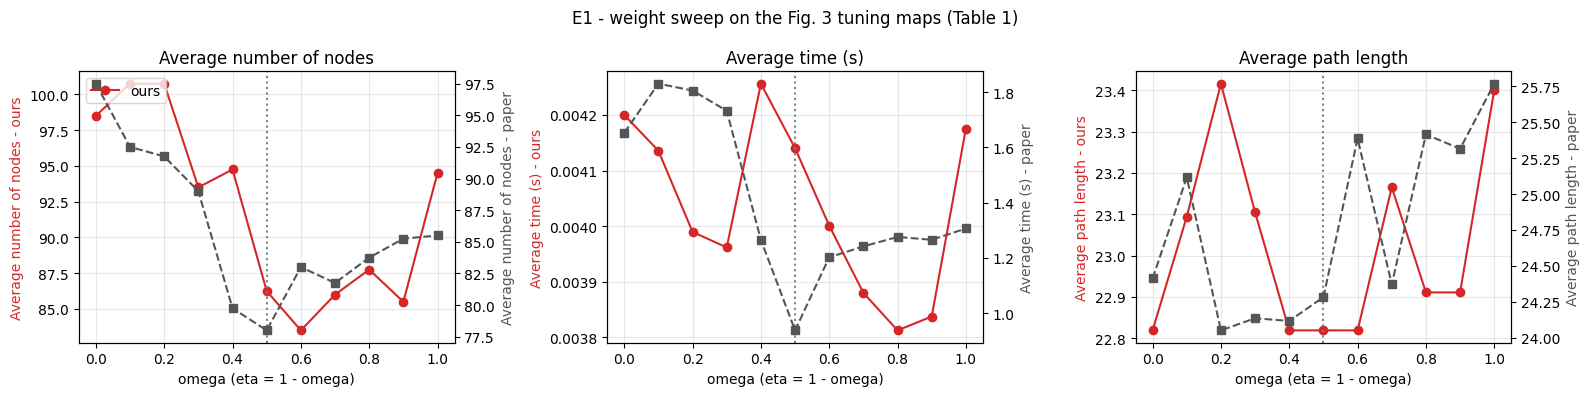

In [67]:
sweep, sweep_s = run_weight_sweep.run(repeats=10)
show = sweep_s[["omega", "eta", "avg_nodes", "pub_avg_nodes", "avg_length", "pub_avg_length", "avg_turns", "avg_time_s", "pub_avg_time_s", "all_valid"]].copy()
show["avg_time_ms"] = (1000 * show.pop("avg_time_s")).round(2)
display(show.round(3))
best_nodes = sweep_s.loc[sweep_s.avg_nodes.idxmin()]
rank05 = int(sweep_s.avg_nodes.rank(method="min")[sweep_s.omega == 0.5].iloc[0])
from scipy.stats import spearmanr
rho_nodes = spearmanr(sweep_s.avg_nodes, sweep_s.pub_avg_nodes).correlation
print(f"Ours: fewest nodes at omega={best_nodes.omega} ({best_nodes.avg_nodes}); omega=0.5 ranks #{rank05} of 11 ({sweep_s[sweep_s.omega==0.5].avg_nodes.iloc[0]}).")
print(f"Paper: fewest nodes at omega=0.5 (78). Spearman correlation of the two node curves: {rho_nodes:.2f}")
PR.weight_sweep(sweep_s); plt.show()

**E1 interpretation.** The shape of the curve is reproduced: the extremes (ω = 0 → no attraction between the fronts; ω = 1 → no global guidance) need the most nodes, the middle of the range the fewest, and every setting finds a valid path. Our minimum is at ω = 0.6 (83.5 nodes); ω = 0.5 is within 3.3 % of it (86.25, rank 4 of 11) and the 0.5–0.9 band is nearly flat, while the paper's minimum is exactly at 0.5. The two node curves are positively correlated (Spearman ≈ 0.6), so the paper's choice is reasonable but not uniquely optimal in our reproduction. The absolute averages differ by a few nodes because the Fig. 3 maps were reproduced from single figures and several VNS-BA\* internals are assumptions. Our path lengths are ~1.5 shorter than the paper's because our metric is the smoothed any-angle length (A21). Times are milliseconds vs ~1 s (see E6). Following the paper, **ω = η = 0.5 is kept** for all other experiments.

---
## E2 Per-map reproduction (Tables 2–5), 30 timing repeats

In [68]:
main, t6 = run_main.run(repeats=REPEATS, verbose=False)
def side_by_side(df, name):
    d = df[df["map"] == name].copy()
    out = pd.DataFrame({"Algorithm": d["name"].values})
    for k, lab in [("nodes", "Nodes"), ("turns", "Turns"), ("turn_angle_deg", "Angle (deg)"), ("length", "Length")]:
        out[f"{lab} paper"] = d[f"pub_{k}"].values; out[f"{lab} ours"] = d[k].round(3).values
    out["Time paper (s)"] = d["pub_time_s"].values
    out["Time ours (ms)"] = [f"{1000*a:.2f} ± {1000*b:.2f}" for a, b in zip(d.time_s, d.time_std_s)]
    return out
for name in MAP_NAMES:
    print(f"\nMap {MAP_LABEL[name]}  (cf. Table {2 + MAP_NAMES.index(name)})")
    display(side_by_side(main, name))


Map A (20x20)  (cf. Table 2)


,Algorithm,Nodes paper,Nodes ours,Turns paper,Turns ours,Angle (deg) paper,Angle (deg) ours,Length paper,Length ours,Time paper (s),Time ours (ms)
0,A*,84,83,7,7,315.000,315.000,28.627,28.627,4.350,0.14 ± 0.08
1,Improved A* [28],81,82,7,9,315.000,405.000,28.627,29.213,3.597,0.18 ± 0.07
2,BA*,88,88,10,10,450.000,450.000,28.627,28.627,2.155,0.17 ± 0.40
3,Improved BA* [29],91,92,14,14,630.000,630.000,29.213,29.213,3.247,0.33 ± 0.03
4,VNS-BA*,100,89,4,5,208.967,114.893,27.476,28.525,2.553,4.56 ± 0.39



Map B (40x40)  (cf. Table 3)


,Algorithm,Nodes paper,Nodes ours,Turns paper,Turns ours,Angle (deg) paper,Angle (deg) ours,Length paper,Length ours,Time paper (s),Time ours (ms)
0,A*,345,343,9,9,405.000,405.000,61.598,61.598,154.602,1.10 ± 0.57
1,Improved A* [28],277,278,11,11,495.000,495.000,64.083,64.083,104.956,0.95 ± 0.54
2,BA*,286,286,12,12,540.000,540.000,61.598,61.598,28.129,0.74 ± 0.10
3,Improved BA* [29],263,265,18,18,810.000,810.000,61.598,61.598,33.863,1.31 ± 0.09
4,VNS-BA*,252,195,4,7,289.823,132.206,61.263,58.600,20.419,12.22 ± 0.58



Map C (60x60)  (cf. Table 4)


,Algorithm,Nodes paper,Nodes ours,Turns paper,Turns ours,Angle (deg) paper,Angle (deg) ours,Length paper,Length ours,Time paper (s),Time ours (ms)
0,A*,423,411,7,7,315.000,315.000,59.3850,59.385,296.377,1.46 ± 0.17
1,Improved A* [28],258,257,7,18,945.000,945.000,69.0833,69.083,72.996,0.92 ± 0.07
2,BA*,564,565,8,8,360.000,360.000,59.3848,59.385,212.650,2.15 ± 0.15
3,Improved BA* [29],239,236,21,23,990.000,1080.000,61.5980,60.213,22.531,1.14 ± 0.41
4,VNS-BA*,257,255,4,4,163.072,104.036,57.5170,57.374,12.330,14.19 ± 1.13



Map D (80x80)  (cf. Table 5)


,Algorithm,Nodes paper,Nodes ours,Turns paper,Turns ours,Angle (deg) paper,Angle (deg) ours,Length paper,Length ours,Time paper (s),Time ours (ms)
0,A*,352,351,25,25,1125.00,1125.000,103.297,103.296,108.308,0.78 ± 0.31
1,Improved A* [28],344,338,27,27,1215.00,1215.000,104.125,104.125,105.124,0.96 ± 0.06
2,BA*,611,612,24,24,1080.00,1080.000,102.125,102.125,80.221,1.67 ± 0.96
3,Improved BA* [29],392,394,30,30,1350.00,1350.000,106.225,106.225,66.982,1.77 ± 0.44
4,VNS-BA*,355,368,14,15,672.95,496.307,103.700,99.953,35.345,35.21 ± 2.29


,cells,exact_length,exact_turns,median_abs_node_err_pct,max_abs_node_err_pct
group,,,,,
4 baselines,16,14,13,0.5,2.8
VNS-BA*,4,0,1,7.3,22.6


all paths collision-free: True


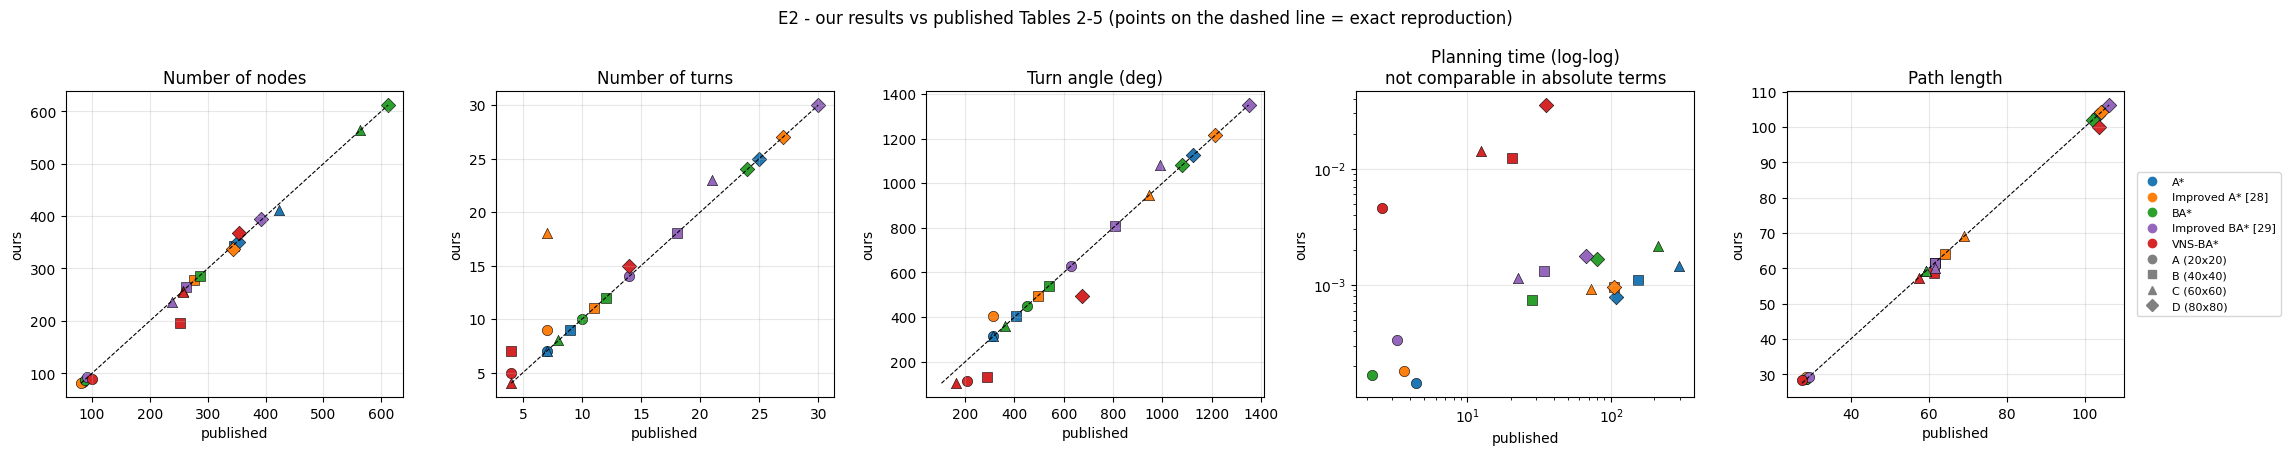

In [69]:
m2 = main.copy()
m2["length_exact"] = (m2.length - m2.pub_length).abs() < 2e-3
m2["turns_exact"] = m2.turns == m2.pub_turns
m2["nodes_err_pct"] = 100 * (m2.nodes - m2.pub_nodes) / m2.pub_nodes
summary = m2.assign(group=np.where(m2.algorithm == "vns_bastar", "VNS-BA*", "4 baselines")).groupby("group").agg(
    cells=("map", "count"), exact_length=("length_exact", "sum"), exact_turns=("turns_exact", "sum"),
    median_abs_node_err_pct=("nodes_err_pct", lambda s: s.abs().median()),
    max_abs_node_err_pct=("nodes_err_pct", lambda s: s.abs().max())).round(1)
display(summary)
print("all paths collision-free:", bool(main.valid.all()))
PR.published_vs_ours(main); plt.show()

**E2 interpretation.**
- **Baselines: reproduced.** Lengths and turns are exact in most cells, nodes within a few percent — on the same maps, with the same metric definitions. The remaining mismatches are tie-breaking inside [28]/[29] and the Table 4 typo (Improved A\*, Map C: 945° fits 18 turns, not 7).
- **VNS-BA\*: comparable, not identical.** Node counts are in the same range (within ~25 %), turns are low as claimed (4–15 vs 4–14), paths are collision-free and smooth. Differences come from internals the paper does not specify (A1, A2, A5–A7, A19–A22). Our VNS-BA\* turn *angles* are consistently smaller than published, and lengths are equal or shorter except on Map A.
- **Time:** ours are 3–5 orders of magnitude smaller, so only rankings could be compared — and those do **not** reproduce (VNS-BA\* is the slowest per run in our implementation). E6 explains why.

---
## E3  Improvement ratios (Table 6) and comprehensive rate (Fig. 12)
Ratio = (other − VNS-BA\*) / other × 100, exactly as in the paper. Because absolute times are not comparable (E6), we report the comprehensive rate both with the paper's 5 metrics and with the 4 implementation-independent metrics.

,map,compared_to,nodes,pub_nodes,turns,pub_turns,turn_angle_deg,pub_turn_angle_deg,length,pub_length,comprehensive_no_time,pub_comprehensive_no_time,comprehensive,pub_comprehensive_fig12
0,map_A_20,astar,-7.23,-19.05,28.57,42.86,63.53,33.67,0.36,4.02,21.31,15.38,-604.71,20.56
1,map_A_20,improved_astar_28,-8.54,-23.46,44.44,42.86,71.63,33.67,2.35,4.02,27.47,14.27,-458.15,17.22
2,map_A_20,bastar,-1.14,-13.64,50.00,60.00,74.47,53.56,0.36,4.02,30.92,25.98,-498.66,17.09
3,map_A_20,improved_bastar_29,3.26,-9.89,64.29,71.43,81.76,66.83,2.35,5.98,37.92,33.59,-224.09,31.14
4,map_B_40,astar,43.15,26.96,22.22,55.56,67.36,28.44,4.87,0.54,34.40,27.88,-174.36,39.66
5,map_B_40,improved_astar_28,29.86,9.02,36.36,63.63,73.29,41.45,8.56,4.40,37.02,29.62,-207.18,39.81
6,map_B_40,bastar,31.82,11.89,41.67,66.67,75.52,46.33,4.87,0.54,38.47,31.36,-281.14,30.57
7,map_B_40,improved_bastar_29,26.42,4.18,61.11,77.78,83.68,64.22,4.87,0.54,44.02,36.68,-131.34,37.28
8,map_C_60,astar,37.96,39.24,42.86,42.86,66.97,48.23,3.39,3.14,37.79,33.37,-144.73,45.86
9,map_C_60,improved_astar_28,0.78,0.39,77.78,42.86,88.99,82.74,16.95,10.83,46.12,34.20,-250.33,43.99


,metric,ours_mean_%,paper_mean_%,ours_min_%,paper_min_%
0,turns,48.37,55.29,22.22,41.67
1,turn_angle_deg,71.31,51.39,54.05,28.44
2,nodes,14.74,7.89,-8.88,-23.46
3,length,4.52,3.19,0.36,-1.54
4,comprehensive (4 metrics),34.74,29.44,21.31,14.27


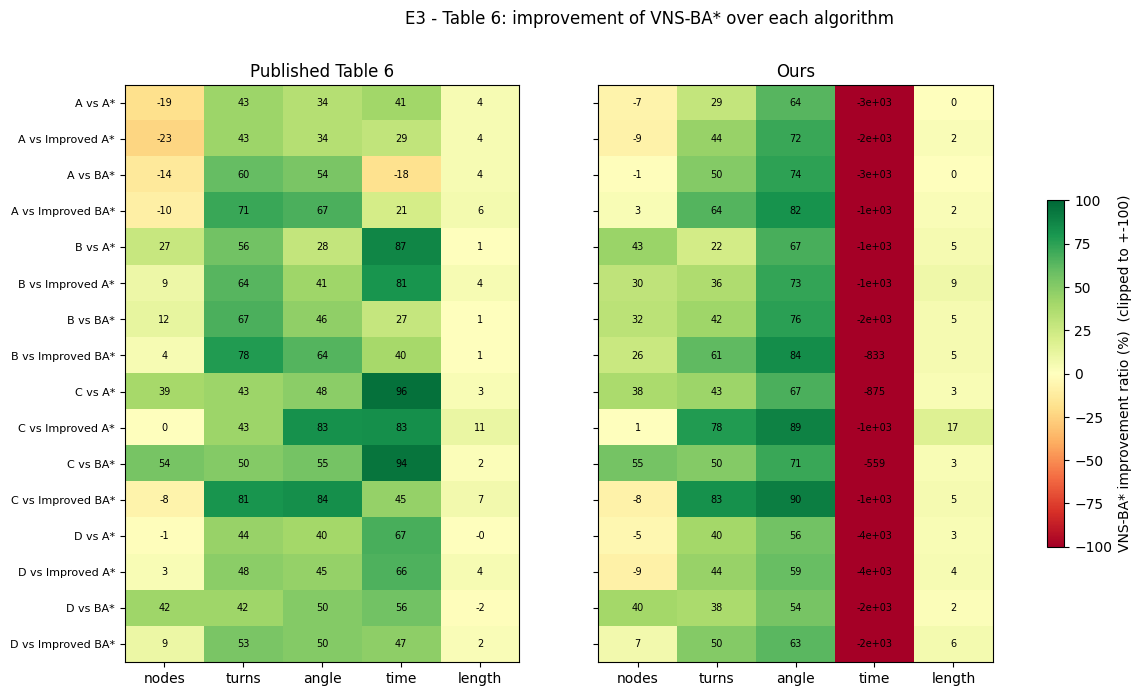

In [70]:
cols = ["map", "compared_to"] + [c for k in ["nodes", "turns", "turn_angle_deg", "length"] for c in (k, f"pub_{k}")] + \
       ["comprehensive_no_time", "pub_comprehensive_no_time", "comprehensive", "pub_comprehensive_fig12"]
display(t6[cols].round(2))
agg = pd.DataFrame({
    "metric": ["turns", "turn_angle_deg", "nodes", "length", "comprehensive (4 metrics)"],
    "ours_mean_%": [t6.turns.mean(), t6.turn_angle_deg.mean(), t6.nodes.mean(), t6.length.mean(), t6.comprehensive_no_time.mean()],
    "paper_mean_%": [t6.pub_turns.mean(), t6.pub_turn_angle_deg.mean(), t6.pub_nodes.mean(), t6.pub_length.mean(), t6.pub_comprehensive_no_time.mean()],
    "ours_min_%": [t6.turns.min(), t6.turn_angle_deg.min(), t6.nodes.min(), t6.length.min(), t6.comprehensive_no_time.min()],
    "paper_min_%": [t6.pub_turns.min(), t6.pub_turn_angle_deg.min(), t6.pub_nodes.min(), t6.pub_length.min(), t6.pub_comprehensive_no_time.min()],
}).round(2)
display(agg)
PR.table6_heatmaps(t6); plt.show()

**E3 interpretation.** In the paper's own setting (post-processing only for VNS-BA\*), our implementation reproduces — and on turn angle exceeds — the claimed advantages: **fewer turns in every one of the 16 comparisons, much smaller total turn angle, slightly shorter paths, and fewer nodes than plain BA\* on Maps B–D (32–55 %); more nodes than A\* and Improved A\* on Maps A and D** (the paper also reports negative node ratios there). The 4-metric comprehensive rate is positive for every map/baseline and of the same size as the paper's. The **time** component is strongly negative in our implementation; with it included, the 5-metric comprehensive rate becomes negative (E6).

---
## E4  Fair comparison, ablation and sensitivity (our addition)
The paper gives pruning + smoothing **only** to VNS-BA\* (Phase 1 concern #1). Here every baseline also gets them, and VNS-BA\* components are switched off one at a time.

length                               nodes                            turn_angle_deg                               turns                           
map                                        map_A_20 map_B_40 map_C_60 map_D_80 map_A_20 map_B_40 map_C_60 map_D_80       map_A_20 map_B_40 map_C_60 map_D_80 map_A_20 map_B_40 map_C_60 map_D_80
variant                                                                                                                                                                                         
A* + prune + smooth                           27.99    59.98    57.72   101.36     83.0    343.0    411.0    351.0         146.31   232.59   135.00   861.34      5.0      7.0      5.0     22.0
Improved A* [28] + prune + smooth             28.61    61.82    64.89   101.36     82.0    278.0    257.0    338.0         326.31   306.33   432.68   861.34      8.0      8.0     10.0     22.0
BA* + prune + smooth                          27.58    58.60    56.51    98.02     88.0    286.0    565.0    612.0         109.44   132.21    87.30   306.14      5.0      7.0      4.0     19.0
Improved BA* [29] + prune + smooth            27.84    58.60    56.51   101.11     92.0    265.0    236.0    394.0         183.18   132.21    87.78   536.72      8.0      7.0      5.0     20.0
VNS-BA* (full)                                28.53    58.60    57.37    99.95     89.0    195.0    255.0    368.0         114.89   132.21   104.04   496.31      5.0      7.0      4.0     15.0
VNS-BA* - no pruning/smoothing                29.26    60.89    62.64   108.13     89.0    195.0    255.0    368.0         343.74   540.00   576.87   990.00     11.0     15.0     16.0     26.0
VNS-BA* - no smoothing                        28.68    58.69    57.52   100.73     89.0    195.0    255.0    368.0         114.89   132.21   104.04   496.31      5.0      7.0      4.0     15.0
VNS-BA* - 8-neighbourhood only                28.53    58.60    57.37   104.99     89.0    200.0    248.0    341.0         114.89   132.21   104.04   447.24      5.0      7.0      4.0     13.0
VNS-BA* - no obstacle factor e^rho            27.55    58.90    57.37    99.67     92.0    224.0    296.0    351.0          84.38   142.59   104.04   571.14      5.0      7.0      4.0     20.0
VNS-BA* - omega=0 (no opposite attraction)    28.53    58.93    56.76   100.58     94.0    226.0    606.0    431.0         114.89   149.33    91.36   476.98      5.0      6.0      4.0     13.0
VNS-BA* - eta=0 (no global guidance)          28.53    58.60    57.36    99.12     89.0    183.0    237.0    328.0         114.89   132.21    93.41   443.53      5.0      7.0      3.0     17.0
VNS-BA* - meet rule open_closed (A26)         28.53    58.60    57.37    99.95     89.0    187.0    241.0    355.0         114.89   132.21   104.04   496.31      5.0      7.0      4.0     15.0
VNS-BA* - spline offset 0.5 (A7)              28.56    58.60    57.41   100.18     89.0    195.0    255.0    368.0         114.89   132.21   104.04   496.31      5.0      7.0      4.0     15.0
VNS-BA* - spline offset 1.5 (A7)              28.52    58.62    57.38    99.90     89.0    195.0    255.0    368.0         114.89   132.21   104.04   496.31      5.0      7.0      4.0     15.0

all paths collision-free: True


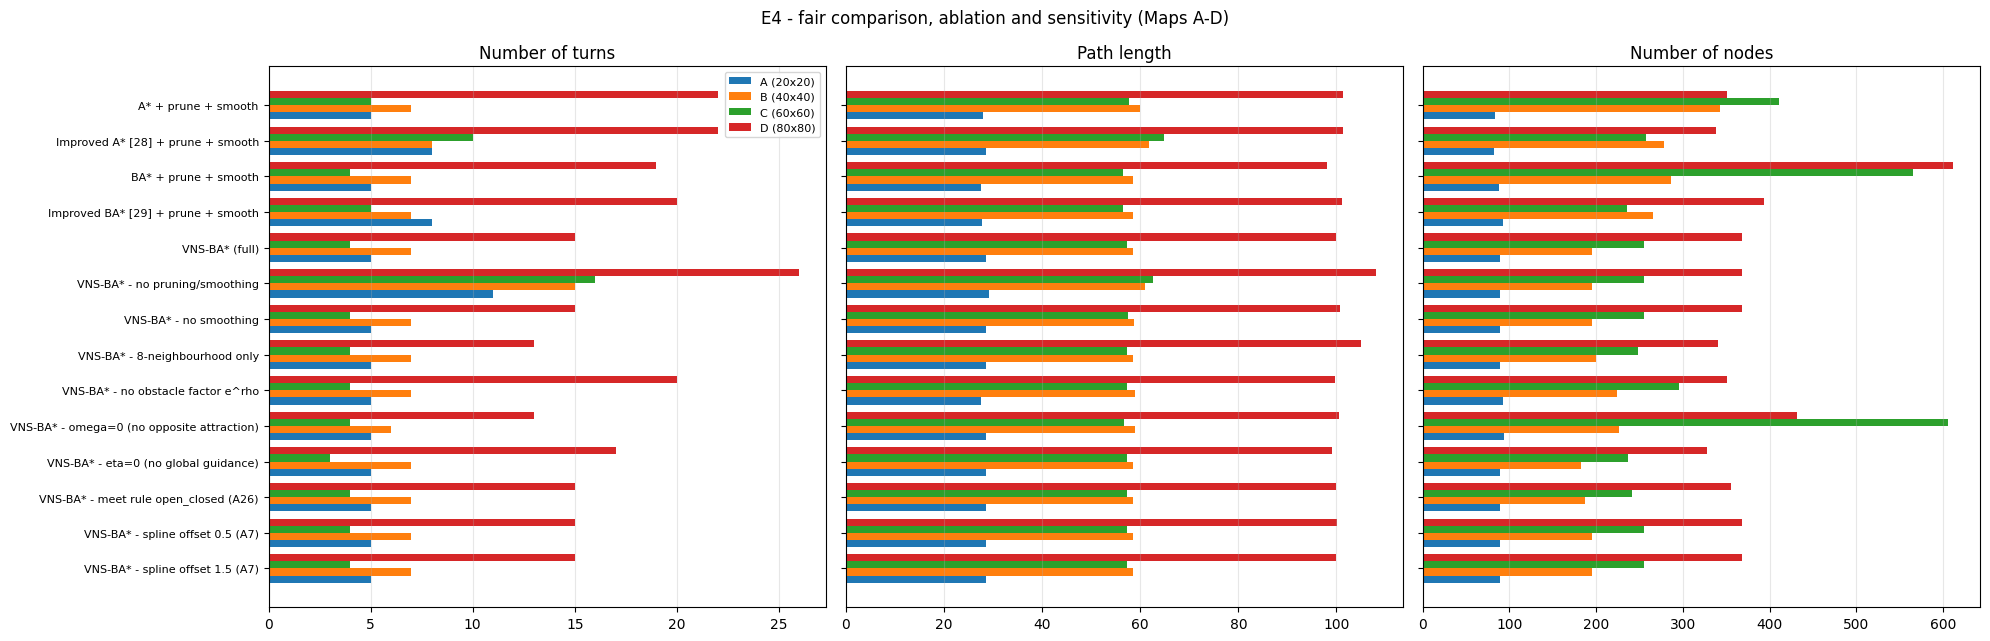

In [71]:
ab = run_ablation.run(repeats=10)
fair = pd.read_csv(RESULTS / "table6_fair.csv")
piv = ab.pivot_table(index="variant", columns="map", values=["nodes", "turns", "turn_angle_deg", "length"]).round(2)
order = list(dict.fromkeys(ab.variant))
display(piv.loc[order])
print("all paths collision-free:", bool(ab.valid.all()))
PR.ablation(ab); plt.show()

Table 6 recomputed against baselines that ALSO receive pruning + smoothing:


,map,compared_to,nodes,turns,turn_angle_deg,length,comprehensive_no_time
0,map_A_20,astar,-7.23,0.00,21.47,-1.90,3.08
1,map_A_20,improved_astar_28,-8.54,37.50,64.79,0.29,23.51
2,map_A_20,bastar,-1.14,0.00,-4.98,-3.44,-2.39
3,map_A_20,improved_bastar_29,3.26,37.50,37.28,-2.45,18.90
4,map_B_40,astar,43.15,0.00,43.16,2.29,22.15
5,map_B_40,improved_astar_28,29.86,12.50,56.84,5.21,26.10
6,map_B_40,bastar,31.82,0.00,0.00,0.00,7.96
7,map_B_40,improved_bastar_29,26.42,0.00,0.00,0.00,6.60
8,map_C_60,astar,37.96,20.00,22.94,0.60,20.38
9,map_C_60,improved_astar_28,0.78,60.00,75.96,11.58,37.08


,baselines,VNS-BA* better turns (of 16),equal turns,mean turn improvement %,mean angle improvement %,mean length improvement %,mean 4-metric comprehensive %
0,raw (paper setting),16,0,48.37,71.31,4.52,34.74
1,+ prune + smooth (fair),10,6,18.57,19.37,0.69,13.34


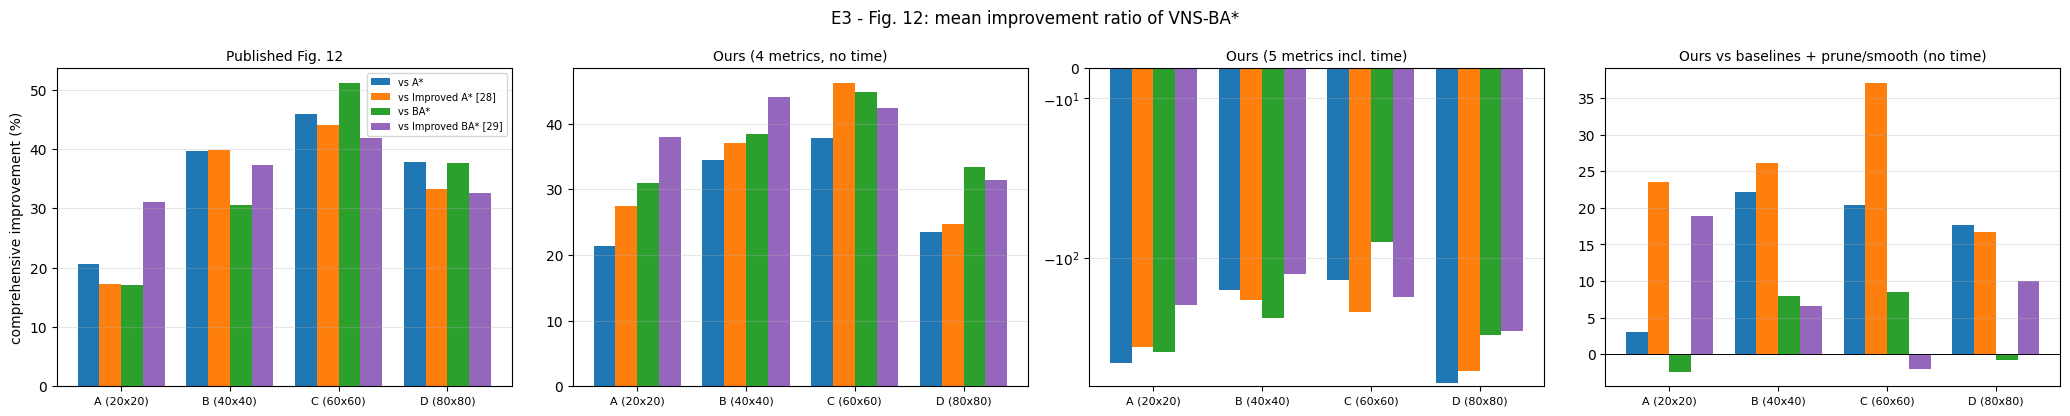

In [72]:
print("Table 6 recomputed against baselines that ALSO receive pruning + smoothing:")
display(fair[["map", "compared_to", "nodes", "turns", "turn_angle_deg", "length", "comprehensive_no_time"]])
cmp = pd.DataFrame({
    "baselines": ["raw (paper setting)", "+ prune + smooth (fair)"],
    "VNS-BA* better turns (of 16)": [int((t6.turns > 0).sum()), int((fair.turns > 0).sum())],
    "equal turns": [int((t6.turns == 0).sum()), int((fair.turns == 0).sum())],
    "mean turn improvement %": [t6.turns.mean(), fair.turns.mean()],
    "mean angle improvement %": [t6.turn_angle_deg.mean(), fair.turn_angle_deg.mean()],
    "mean length improvement %": [t6.length.mean(), fair.length.mean()],
    "mean 4-metric comprehensive %": [t6.comprehensive_no_time.mean(), fair.comprehensive_no_time.mean()],
}).round(2)
display(cmp)
PR.fig12(t6, fair); plt.show()

**E4 interpretation — the central finding of this reproduction.**
1. **Most of the turn / angle gain comes from post-processing, not from the search.** VNS-BA\* *without* pruning/smoothing has 11–26 turns — as many as the raw baselines. Once the baselines get the same pruning + smoothing, VNS-BA\*'s turn advantage shrinks to 0–60 % (often 0) and against **BA\* + post-processing it is no longer better**: equal turns on Maps A–C (better only on D), but a larger total turn angle and slightly longer paths on Maps A, C and D.
2. **What the search itself contributes is node efficiency versus plain BA\*:** the opposite-attraction term (ω) makes the two fronts meet; switching it off (ω = 0) raises nodes sharply on Map C (≈ 255 → 606). The obstacle factor e^ρ also saves nodes on Maps B/C.
3. **The 8-11-13 neighbourhood has little effect** on these maps: with the plain 8-neighbourhood instead, Maps A–C are almost unchanged and Map D even gets fewer nodes and turns (but a 5 % longer path), because the extension is disabled whenever any of the 8 neighbours is an obstacle.
4. **Sensitivity:** the unspecified details we had to choose (meeting rule, spline offsets) change lengths by < 1 %, turns not at all and nodes by at most ~6 % — our conclusions do not hinge on them.

---
## E5  120 random maps (30 seeds × 20/40/60/80, 20 % density)
Paired comparisons on the same map; Wilcoxon signed-rank test (two-sided). "VNS better" = fraction of maps where VNS-BA\* has the smaller value.

maps: 120, runs: 840, success rate: 1.000, valid paths: 1.000


,size,variant,turns_mean,turns_std,angle_mean,length_mean,nodes_mean,time_ms_mean
0,20,A*,6.67,3.40,300.00,28.31,79.37,0.15
1,20,A* + prune + smooth,5.43,2.45,202.62,27.87,79.37,2.16
2,20,BA*,6.30,3.32,283.50,28.16,120.97,0.24
3,20,BA* + prune + smooth,5.00,2.63,153.28,27.65,120.97,2.18
4,20,Improved A* [28],6.37,2.59,297.00,28.29,79.10,0.18
5,20,Improved BA* [29],8.80,3.85,402.00,28.44,83.27,0.28
6,20,VNS-BA*,5.43,2.85,183.59,28.06,91.73,4.77
7,40,A*,14.17,4.48,643.50,58.44,164.37,0.31
8,40,A* + prune + smooth,12.00,3.62,462.43,57.51,164.37,4.76
9,40,BA*,12.43,3.77,564.00,57.87,282.23,0.56


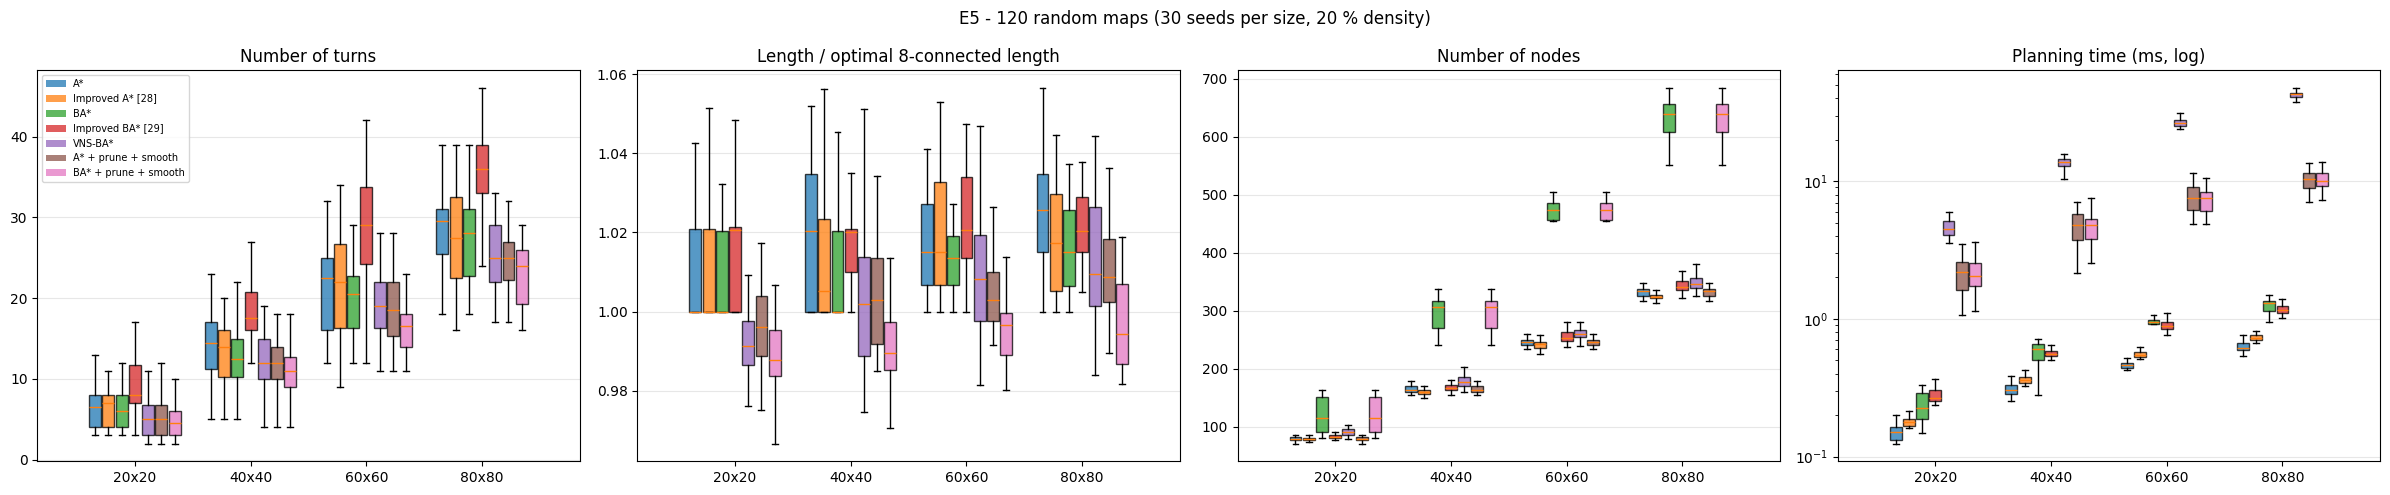

In [73]:
rr, rsum, rtest = run_random.run(repeats=3)
print(f"maps: {rr[['size','seed']].drop_duplicates().shape[0]}, runs: {len(rr)}, success rate: {rr.success.mean():.3f}, valid paths: {rr.valid.mean():.3f}")
display(rsum[["size", "variant", "turns_mean", "turns_std", "angle_mean", "length_mean", "nodes_mean", "time_ms_mean"]].round(2))
PR.random_boxplots(rr); plt.show()

In [74]:
t = rtest[rtest.metric.isin(["turns", "turn_angle_deg", "length", "nodes"])].copy()
t["result"] = [("VNS better" if mi > 0 else "VNS worse") + (" *" if p < 0.05 else " (n.s.)") if p == p else "n/a"
               for mi, p in zip(t.mean_improvement_pct, t.wilcoxon_p)]
pv = t.pivot_table(index=["compared_to", "metric"], columns="size", values="mean_improvement_pct").round(1)
res = t.pivot_table(index=["compared_to", "metric"], columns="size", values="result", aggfunc="first")
print("Mean improvement of VNS-BA* (%), positive = VNS-BA* better:")
display(pv)
print("Direction and significance (* = Wilcoxon p < 0.05):")
display(res)

Mean improvement of VNS-BA* (%), positive = VNS-BA* better:


size                                   20    40    60    80
compared_to          metric                                
A*                   length           0.9   1.2   1.0   1.3
                     nodes          -15.6  -8.5  -6.0  -4.1
                     turn_angle_deg  38.8  37.4  31.1  34.4
                     turns           18.5  13.9   7.0  12.8
A* + prune + smooth  length          -0.7  -0.4  -0.4  -0.2
                     nodes          -15.6  -8.5  -6.0  -4.1
                     turn_angle_deg   9.4  12.9  13.1   8.5
                     turns            0.0  -1.7  -4.5  -3.3
BA*                  length           0.3   0.3   0.5   0.4
                     nodes           24.2  36.8  40.4  41.8
                     turn_angle_deg  35.2  28.6  27.1  30.0
                     turns           13.8   1.9   1.7   7.3
BA* + prune + smooth length          -1.5  -1.6  -1.3  -1.6
                     nodes           24.2  36.8  40.4  41.8
                     turn_angle_deg -19.8 -20.6 -17.2 -26.1
                     turns           -8.7 -14.7 -16.4 -10.8
Improved A* [28]     length           0.8   0.6   1.0   0.7
                     nodes          -16.0 -11.5  -7.8  -6.9
                     turn_angle_deg  38.2  34.3  34.8  32.8
                     turns           14.7   6.6   9.1   7.6
Improved BA* [29]    length           1.3   1.0   1.6   0.9
                     nodes          -10.2  -6.6  -1.7  -0.8
                     turn_angle_deg  54.3  50.8  50.8  46.8
                     turns           38.3  32.5  33.7  29.3

Direction and significance (* = Wilcoxon p < 0.05):


size                                                20                 40                 60                 80
compared_to          metric                                                                                    
A*                   length               VNS better *       VNS better *       VNS better *       VNS better *
                     nodes                 VNS worse *        VNS worse *        VNS worse *        VNS worse *
                     turn_angle_deg       VNS better *       VNS better *       VNS better *       VNS better *
                     turns           VNS better (n.s.)       VNS better *  VNS better (n.s.)       VNS better *
A* + prune + smooth  length           VNS worse (n.s.)   VNS worse (n.s.)   VNS worse (n.s.)   VNS worse (n.s.)
                     nodes                 VNS worse *        VNS worse *        VNS worse *        VNS worse *
                     turn_angle_deg  VNS better (n.s.)       VNS better *  VNS better (n.s.)  VNS better (n.s.)
                     turns            VNS worse (n.s.)   VNS worse (n.s.)   VNS worse (n.s.)   VNS worse (n.s.)
BA*                  length               VNS better *  VNS better (n.s.)  VNS better (n.s.)  VNS better (n.s.)
                     nodes                VNS better *       VNS better *       VNS better *       VNS better *
                     turn_angle_deg       VNS better *       VNS better *       VNS better *       VNS better *
                     turns           VNS better (n.s.)  VNS better (n.s.)  VNS better (n.s.)  VNS better (n.s.)
BA* + prune + smooth length                VNS worse *        VNS worse *        VNS worse *        VNS worse *
                     nodes                VNS better *       VNS better *       VNS better *       VNS better *
                     turn_angle_deg   VNS worse (n.s.)        VNS worse *        VNS worse *        VNS worse *
                     turns            VNS worse (n.s.)        VNS worse *        VNS worse *        VNS worse *
Improved A* [28]     length               VNS better *       VNS better *       VNS better *  VNS better (n.s.)
                     nodes                 VNS worse *        VNS worse *        VNS worse *        VNS worse *
                     turn_angle_deg       VNS better *       VNS better *       VNS better *       VNS better *
                     turns                VNS better *  VNS better (n.s.)       VNS better *  VNS better (n.s.)
Improved BA* [29]    length               VNS better *       VNS better *       VNS better *       VNS better *
                     nodes                 VNS worse *        VNS worse *   VNS worse (n.s.)   VNS worse (n.s.)
                     turn_angle_deg       VNS better *       VNS better *       VNS better *       VNS better *
                     turns                VNS better *       VNS better *       VNS better *       VNS better *

**E5 interpretation.** On 120 independent maps the picture of E3/E4 holds with statistics behind it:
- Versus the **raw** baselines, VNS-BA\* has fewer turns, much smaller turn angle and slightly shorter paths, mostly significant — the paper's qualitative claim is confirmed.
- Versus **plain BA\***, VNS-BA\* expands **24–42 % fewer nodes** (p < 0.001) — the clearest genuine benefit of its search strategy. Versus unidirectional A\* and [28] it needs 4–16 % *more* nodes.
- Versus **baselines with the same post-processing**, the advantage disappears: no significant difference in turns or length to A\* + prune + smooth (VNS-BA\* still needs more nodes), and **BA\* + prune + smooth is significantly better** than VNS-BA\* in turns (40×40 to 80×80) and in length (all sizes) — at the price of 24–42 % more nodes.

---
## E6  Why the published planning times are not reproducible

,predictor,scope,spearman,pearson
0,expanded,all 20 cells,0.897,0.865
5,generated,all 20 cells,0.853,0.673
10,time_s,all 20 cells,0.226,-0.177


,map,name,expanded,generated,pub_time_s,our_time_ms,pub_ms_per_iteration
0,map_A_20,A*,24,83,4.350,0.142,181.2
1,map_A_20,Improved A* [28],24,82,3.597,0.183,149.9
2,map_A_20,BA*,25,88,2.155,0.168,86.2
3,map_A_20,Improved BA* [29],32,92,3.247,0.333,101.5
4,map_A_20,VNS-BA*,21,89,2.553,4.564,121.6
5,map_B_40,A*,203,343,154.602,1.101,761.6
6,map_B_40,Improved A* [28],157,278,104.956,0.951,668.5
7,map_B_40,BA*,118,286,28.129,0.736,238.4
8,map_B_40,Improved BA* [29],152,265,33.863,1.310,222.8
9,map_B_40,VNS-BA*,45,195,20.419,12.215,453.8


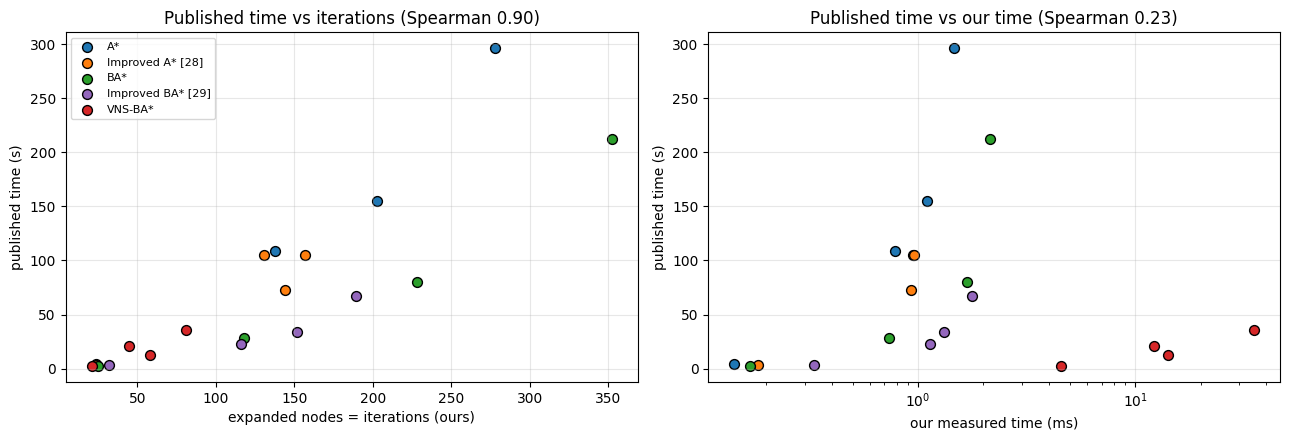

In [75]:
td, tc = analysis_timing.run()
display(tc[tc.scope == "all 20 cells"])
display(td[["map", "name", "expanded", "generated", "pub_time_s"]].assign(
    our_time_ms=(1000 * td.time_s).round(3), pub_ms_per_iteration=td.pub_ms_per_expanded.round(1)))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for alg, c in PR.COLORS.items():
    d = td[td.algorithm == alg]
    ax[0].scatter(d.expanded, d.pub_time_s, c=c, label=ALGORITHMS[alg], edgecolor="k", s=50)
    ax[1].scatter(1000 * d.time_s, d.pub_time_s, c=c, edgecolor="k", s=50)
ax[0].set_xlabel("expanded nodes = iterations (ours)"); ax[0].set_ylabel("published time (s)"); ax[0].legend(fontsize=8)
ax[0].set_title(f"Published time vs iterations (Spearman {tc[(tc.predictor=='expanded')&(tc.scope=='all 20 cells')].spearman.iloc[0]:.2f})")
ax[1].set_xlabel("our measured time (ms)"); ax[1].set_xscale("log"); ax[1].set_ylabel("published time (s)")
ax[1].set_title(f"Published time vs our time (Spearman {tc[(tc.predictor=='time_s')&(tc.scope=='all 20 cells')].spearman.iloc[0]:.2f})")
for a in ax: a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(PROJECT_ROOT / "results/figures/phase4_E6_timing.png", dpi=140, bbox_inches="tight"); plt.show()

**E6 interpretation.** The published times correlate strongly with the **number of iterations** (expanded nodes) of our reproduced runs but not with our measured compute time. That is the signature of a per-iteration overhead (e.g. plotting or linear open-list scans in MATLAB) that dwarfs the actual algorithmic work: 25–1000 ms per iteration is far above the microseconds an iteration costs. VNS-BA\* has the fewest iterations (bidirectional + up to 13 successors per expansion), so under such an overhead it *appears* fastest. In a lean implementation, its per-node cost is the highest (two line-of-sight tests and a density query per heuristic evaluation, plus spline collision checks), so it is the slowest. **The paper's planning-time claim therefore depends on its implementation and cannot be confirmed**; the iteration count is a fairer, implementation-independent proxy, and on it VNS-BA\* does win (E2).

---
## E7  Method-level claims of the article (Sec. 3.2 / Fig. 2 and Sec. 3.3 / Fig. 5)
(a) **Pruning:** the proposed pruning is compared with the pruning of Huang et al. [27] on identical raw paths (A\*, BA\* and VNS-BA\* search output, 4 benchmark maps + 120 random maps).
(b) **Bidirectional strategy:** the alternating search of Li et al. [26] (heuristic = distance to the opposite front's current node only) is compared with the proposed heuristic on raw search paths.
Both comparison methods are reconstructed from their descriptions in the article (assumptions A28, A29).

In [76]:
%%writefile experiments/run_method_claims.py
"""E7 - The two method-level claims of the article (Sec. 3.2 / Fig. 2 and Sec. 3.3 / Fig. 5).

(a) Pruning (Sec. 3.3): the proposed pruning removes more redundant turns than the method of Huang et al. [27].
    Both are applied to the same raw grid paths (A*, BA*, VNS-BA* search output) on Maps A-D and 120 random maps.
(b) Bidirectional strategy (Sec. 3.2): the alternating search of Li et al. [26] (target = opposite current node)
    produces more turns than the proposed heuristic; compared on raw search paths (no post-processing).

    python -m experiments.run_method_claims
Output: results/phase4/e7_pruning.csv, e7_pruning_summary.csv, e7_bidirectional.csv, e7_summary.json
"""
from __future__ import annotations
import json
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

from experiments.common import ROOT, RESULTS, MAP_NAMES, load_map
from src.geometry import GridGeometry
from src.planners import plan
from src.postprocess import prune_path, prune_huang, compress_collinear
from src.metrics import turn_metrics, path_length

SOURCES = ["astar", "bastar", "vns_bastar"]


def maps():
    names = list(MAP_NAMES) + list(pd.read_csv(ROOT / "maps" / "random" / "index.csv")["name"])
    return [load_map(n) for n in names]


def run():
    prow, brow = [], []
    for m in maps():
        geo = GridGeometry(m.grid)
        group = "paper maps" if m.name in MAP_NAMES else f"random {m.size}x{m.size}"
        for alg in SOURCES:
            r = plan(m, alg, prune=False, smooth=False)
            raw = r["raw_path"]
            for meth, fn in [("raw (collinear removed)", compress_collinear), ("Huang et al. [27]", lambda p: prune_huang(geo, p)),
                             ("proposed (Sec. 3.3)", lambda p: prune_path(geo, p))]:
                poly = fn(raw)
                tm = turn_metrics(poly)
                prow.append(dict(map=m.name, group=group, source=alg, method=meth, turns=tm["turns"],
                                 turn_angle_deg=tm["turn_angle_deg"], length=path_length(poly)))
        for alg in ["alternating_26", "vns_bastar"]:
            r = plan(m, alg, prune=False, smooth=False)
            brow.append(dict(map=m.name, group=group, algorithm=alg, nodes=r["nodes"], turns=r["turns"],
                             turn_angle_deg=r["turn_angle_deg"], length=r["length"]))
    P, B = pd.DataFrame(prow), pd.DataFrame(brow)
    P.to_csv(RESULTS / "e7_pruning.csv", index=False); B.to_csv(RESULTS / "e7_bidirectional.csv", index=False)

    ps = P.assign(random=P.group != "paper maps").groupby(["random", "method"])[["turns", "turn_angle_deg", "length"]].mean().round(3)
    ps.to_csv(RESULTS / "e7_pruning_summary.csv")
    piv = P.pivot_table(index=["map", "source"], columns="method", values="turns")
    hu, pr = piv["Huang et al. [27]"], piv["proposed (Sec. 3.3)"]
    paper = P[P.group == "paper maps"].pivot_table(index=["map", "source"], columns="method", values="turns")
    bv = B.pivot_table(index="map", columns="algorithm", values=["turns", "nodes", "length"])
    summary = dict(
        pruning_cases=int(len(piv)),
        proposed_fewer_turns_frac=float((pr < hu).mean()), equal_frac=float((pr == hu).mean()),
        proposed_more_turns_frac=float((pr > hu).mean()),
        mean_turns_huang=float(hu.mean()), mean_turns_proposed=float(pr.mean()),
        mean_turns_raw=float(piv["raw (collinear removed)"].mean()),
        reduction_vs_huang_pct=float(100 * (hu.mean() - pr.mean()) / hu.mean()),
        wilcoxon_p=float(wilcoxon(pr, hu).pvalue),
        paper_maps_turns={f"{a}|{b}": [int(x) for x in paper.loc[(a, b)]] for a, b in paper.index},
        alt26_mean_turns=float(bv["turns"]["alternating_26"].mean()), vns_mean_turns=float(bv["turns"]["vns_bastar"].mean()),
        alt26_more_turns_frac=float((bv["turns"]["alternating_26"] > bv["turns"]["vns_bastar"]).mean()),
        alt26_mean_nodes=float(bv["nodes"]["alternating_26"].mean()), vns_mean_nodes=float(bv["nodes"]["vns_bastar"].mean()),
        alt26_turns_wilcoxon_p=float(wilcoxon(bv["turns"]["alternating_26"], bv["turns"]["vns_bastar"]).pvalue),
        paper_maps_alt26_vs_vns_turns={m: [int(bv["turns"]["alternating_26"][m]), int(bv["turns"]["vns_bastar"][m])] for m in MAP_NAMES},
    )
    (RESULTS / "e7_summary.json").write_text(json.dumps(summary, indent=2))
    return P, B, summary


if __name__ == "__main__":
    print(json.dumps(run()[2], indent=2))


Writing experiments/run_method_claims.py


In [77]:
for mod in list(sys.modules):
    if mod.startswith("experiments.run_method_claims") or mod in ("src.planners", "src.postprocess"):
        del sys.modules[mod]
from experiments import run_method_claims
P7, B7, S7 = run_method_claims.run()
print(f"(a) pruning, {S7['pruning_cases']} paths: equal turns {100*S7['equal_frac']:.1f} %, proposed fewer {100*S7['proposed_fewer_turns_frac']:.1f} %, "
      f"proposed more {100*S7['proposed_more_turns_frac']:.1f} %; mean turns {S7['mean_turns_proposed']:.2f} (proposed) vs {S7['mean_turns_huang']:.2f} (Huang), "
      f"Wilcoxon p = {S7['wilcoxon_p']:.3f}")
print(f"(b) raw search paths, 124 maps: mean turns {S7['alt26_mean_turns']:.2f} ([26]) vs {S7['vns_mean_turns']:.2f} (VNS-BA*), "
      f"Wilcoxon p = {S7['alt26_turns_wilcoxon_p']:.2f}; paper maps [26] vs VNS-BA*: {S7['paper_maps_alt26_vs_vns_turns']}")
display(pd.read_csv(RESULTS / "e7_pruning_summary.csv"))

(a) pruning, 372 paths: equal turns 94.6 %, proposed fewer 4.0 %, proposed more 1.3 %; mean turns 14.63 (proposed) vs 14.66 (Huang), Wilcoxon p = 0.022
(b) raw search paths, 124 maps: mean turns 20.93 ([26]) vs 20.54 (VNS-BA*), Wilcoxon p = 0.95; paper maps [26] vs VNS-BA*: {'map_A_20': [12, 11], 'map_B_40': [19, 15], 'map_C_60': [8, 16], 'map_D_80': [24, 26]}


,random,method,turns,turn_angle_deg,length
0,False,Huang et al. [27],8.750,288.991,62.159
1,False,proposed (Sec. 3.3),8.750,238.148,61.312
2,False,raw (collinear removed),14.167,586.717,63.796
3,True,Huang et al. [27],14.861,586.342,72.821
4,True,proposed (Sec. 3.3),14.831,514.521,72.460
5,True,raw (collinear removed),18.258,821.859,73.616


In [78]:
reg_path = PROJECT_ROOT / "docs" / "ambiguity_register.csv"
reg = pd.read_csv(reg_path)
new = pd.DataFrame([
 ("A28", "Sec 3.3", "Pruning method of Huang et al. [27] only described in one sentence",
  "Reconstructed: remove collinear nodes, then drop a turning point if the last kept vertex sees the next turning point (greedy)", "Medium"),
 ("A29", "Sec 3.2", "Alternating bidirectional search of Li et al. [26] only described qualitatively",
  "Reconstructed: each front's heuristic = switching distance to the opposite current node; 8-neighbourhood; Fig. 4 meeting rule", "Medium"),
], columns=reg.columns)
reg = pd.concat([reg[~reg.id.isin(new.id)], new], ignore_index=True)
reg["_k"] = reg.id.str[1:].astype(int); reg = reg.sort_values("_k").drop(columns="_k"); reg.to_csv(reg_path, index=False)
print("ambiguity register:", len(reg), "entries")

ambiguity register: 28 entries


**E7 interpretation.** (a) Both pruning methods leave the same number of turns on almost all paths; the proposed method's advantage is statistically detectable but practically negligible, so the improvement shown on the single example of Fig. 5 does not generalise. (b) The alternating search of [26] does not produce significantly more turns than the proposed heuristic on raw search paths (better on Maps A–B, worse on C–D for VNS-BA\*). Together with E4, this indicates that the smoothness of VNS-BA\* paths stems from post-processing rather than from the search strategy.

---\n## Assignment table preview (VNS-BA\*, published vs ours)\nFinal discussion and verdict follow in Phase 5.

In [79]:
rows = []
for name in MAP_NAMES:
    r = main[(main["map"] == name) & (main.algorithm == "vns_bastar")].iloc[0]
    for k, lab in [("nodes", "Number of nodes"), ("turns", "Number of turns"), ("turn_angle_deg", "Turn angle (deg)"),
                   ("length", "Path length"), ("time_s", "Planning time (s)")]:
        pub, ours = r[f"pub_{k}"], r[k]
        rows.append(dict(map=MAP_LABEL[name], metric=lab, published=pub, ours=round(ours, 4 if k != "time_s" else 5),
                         difference=round(ours - pub, 4), difference_pct=round(100 * (ours - pub) / pub, 1)))
assign = pd.DataFrame(rows); assign.to_csv(RESULTS / "assignment_table_vns.csv", index=False)
display(assign)

,map,metric,published,ours,difference,difference_pct
0,A (20x20),Number of nodes,100.000,89.00000,-11.0000,-11.0
1,A (20x20),Number of turns,4.000,5.00000,1.0000,25.0
2,A (20x20),Turn angle (deg),208.967,114.89270,-94.0743,-45.0
3,A (20x20),Path length,27.476,28.52530,1.0493,3.8
4,A (20x20),Planning time (s),2.553,0.00456,-2.5484,-99.8
5,B (40x40),Number of nodes,252.000,195.00000,-57.0000,-22.6
6,B (40x40),Number of turns,4.000,7.00000,3.0000,75.0
7,B (40x40),Turn angle (deg),289.823,132.20580,-157.6172,-54.4
8,B (40x40),Path length,61.263,58.60000,-2.6630,-4.3
9,B (40x40),Planning time (s),20.419,0.01222,-20.4068,-99.9


### Summary, README and requirements

In [80]:
runtime = time.time() - T0
fr = rtest
def sig(comp, metric, size):
    r = fr[(fr.compared_to == comp) & (fr.metric == metric) & (fr["size"] == size)].iloc[0]
    return f"{r.mean_improvement_pct:+.1f}% (p={r.wilcoxon_p:.3g})"
summary_md = f'''# Phase 4 - Experiment summary ({RUN_DATE})
Runtime {runtime:.0f} s on {ENV["platform"]}; Python {ENV["python"]}, NumPy {ENV["numpy"]}, SciPy {ENV["scipy"]}; timing = median of {REPEATS} runs.

E1  weight sweep: ours fewest nodes at omega={best_nodes.omega}; omega=0.5 ranks #{rank05}/11; paper: 0.5 best. Node-curve Spearman {rho_nodes:.2f}.
E2  baselines: exact length {int(m2[m2.algorithm!="vns_bastar"].length_exact.sum())}/16, exact turns {int(m2[m2.algorithm!="vns_bastar"].turns_exact.sum())}/16;
    VNS-BA* nodes {list(main[main.algorithm=="vns_bastar"].nodes)} vs paper [100, 252, 257, 355]; turns {list(main[main.algorithm=="vns_bastar"].turns)} vs [4, 4, 4, 14].
E3  paper setting: VNS-BA* fewer turns in {int((t6.turns>0).sum())}/16 comparisons; mean turn improvement {t6.turns.mean():.1f}% (paper {t6.pub_turns.mean():.1f}%);
    4-metric comprehensive {t6.comprehensive_no_time.mean():.1f}% (paper {t6.pub_comprehensive_no_time.mean():.1f}%).
E4  fair comparison: mean turn improvement drops to {fair.turns.mean():.1f}%, 4-metric comprehensive to {fair.comprehensive_no_time.mean():.1f}%.
E5  random 80x80: vs BA* nodes {sig("BA*","nodes",80)}; vs BA*+prune+smooth turns {sig("BA* + prune + smooth","turns",80)}, length {sig("BA* + prune + smooth","length",80)}.
E6  published time vs our iterations Spearman {tc[(tc.predictor=="expanded")&(tc.scope=="all 20 cells")].spearman.iloc[0]:.2f}; vs our time {tc[(tc.predictor=="time_s")&(tc.scope=="all 20 cells")].spearman.iloc[0]:.2f}.
'''
(PROJECT_ROOT / "docs" / "phase4_summary.md").write_text(summary_md)
print(summary_md)

readme_p = PROJECT_ROOT / "README.md"
txt = readme_p.read_text()
txt = txt.replace("| 4 | Experiments | pending |", "| 4 | Experiments (E1-E7) | done |")
txt = txt.replace("## Running experiments\n_To be added in Phase 4._", '''## Running experiments
```bash
python -m experiments.run_all --repeats 30     # everything (~1-2 min on a CPU)
python -m experiments.run_weight_sweep         # E1  Table 1
python -m experiments.run_main --repeats 30    # E2/E3 Tables 2-6, Fig. 12
python -m experiments.run_ablation             # E4  fair comparison / ablation / sensitivity
python -m experiments.run_random               # E5  120 random maps + Wilcoxon tests
python -m experiments.analysis_timing          # E6  timing analysis
python -m experiments.run_method_claims        # E7  pruning vs [27], heuristic vs [26]
```
Results: `results/phase4/*.csv`, figures: `results/figures/phase4_*.png`.''')
readme_p.write_text(txt)
req = PROJECT_ROOT / "requirements.txt"
lines = set(req.read_text().split()) if req.exists() else set()
for lib, ver in [("scipy", scipy.__version__), ("pandas", pd.__version__), ("numpy", np.__version__)]:
    if not any(l.lower().startswith(lib + "==") for l in lines):
        lines.add(f"{lib}=={ver}")
req.write_text("\n".join(sorted(lines)) + "\n")
print("README and requirements updated. Files:")
for p in sorted((PROJECT_ROOT / "results" / "phase4").glob("*")):
    print("  ", p.relative_to(PROJECT_ROOT))

# Phase 4 - Experiment summary (2026-10-23)
Runtime 40 s on Linux-6.18.44-fc-v153-x86_64-with-glibc2.39; Python 3.12.3, NumPy 2.4.4, SciPy 1.17.1; timing = median of 30 runs.

E1  weight sweep: ours fewest nodes at omega=0.6; omega=0.5 ranks #4/11; paper: 0.5 best. Node-curve Spearman 0.63.
E2  baselines: exact length 14/16, exact turns 13/16;
    VNS-BA* nodes [89, 195, 255, 368] vs paper [100, 252, 257, 355]; turns [5, 7, 4, 15] vs [4, 4, 4, 14].
E3  paper setting: VNS-BA* fewer turns in 16/16 comparisons; mean turn improvement 48.4% (paper 55.3%);
    4-metric comprehensive 34.7% (paper 29.4%).
E4  fair comparison: mean turn improvement drops to 18.6%, 4-metric comprehensive to 13.3%.
E5  random 80x80: vs BA* nodes +41.8% (p=2.35e-06); vs BA*+prune+smooth turns -10.8% (p=0.0136), length -1.6% (p=3.05e-05).
E6  published time vs our iterations Spearman 0.90; vs our time 0.23.

README and requirements updated. Files:
   results/phase4/ablation.csv
   results/phase4/assignment_table_vn

---
# Part 5  Comparison, Verdict and Critical Analysis
**Objective.** Compare the reproduced and published results, verify the article's claims, state the verdict (comparable / improved / lower) and justify it with respect to dataset, settings, randomness, software, missing details and deviations. Tables and figures for the technical report are generated.

**Outputs.** `results/phase5/`, `results/figures/report_*.png`, `docs/critical_analysis.md`.

## Part 5  Results Comparison, Verdict and Critical Analysis
**Paper:** Li, Li & Dai, *VNS-BA\**, Sensors 24(21):6929, 2024.

This notebook covers **Assignment §5** (results table) and **§6** (critical analysis), and produces the material for the **IEEE report** (§7):

| Step | Output |
|---|---|
| 5.1 | `experiments/final_analysis.py` — all final tables, LaTeX, report figures |
| 5.2 | Assignment §5 table: published vs ours vs difference |
| 5.3 | Baseline reproduction (are the comparison methods right?) |
| 5.4 | Claim-by-claim verification of the paper |
| 5.5 | Verdict: (A) comparable / (B) improved / (C) lower — per metric and overall |
| 5.6 | Technical justification under the six headings required by §6, each with evidence |
| 5.7 | Report figures and LaTeX tables |
| 5.8 | `docs/critical_analysis.md`, README |

It only **reads** the results of Phases 2–4 (no new experiments except the short determinism check in 5.6c).

### 5.0 Setup (needs Phase 4 results)

In [81]:
import os, sys, json, datetime, subprocess, time
from pathlib import Path
USE_DRIVE = True
PROJECT_NAME = "vns-ba-reproduction"
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive') / PROJECT_NAME
elif IN_COLAB:
    PROJECT_ROOT = Path('/content') / PROJECT_NAME
else:
    PROJECT_ROOT = Path.cwd() if Path.cwd().name == PROJECT_NAME else Path.cwd() / PROJECT_NAME
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
need = ["results/phase4/main_results.csv", "results/phase4/table6_fair.csv", "results/phase4/random_wilcoxon.csv",
        "results/phase4/timing_correlations.csv", "results/phase2/validation_optimal_length.csv",
        "results/phase3/calibration.csv", "docs/ambiguity_register.csv", "experiments/common.py"]
missing = [p for p in need if not (PROJECT_ROOT / p).exists()]
if missing:
    raise FileNotFoundError(f"Run Phases 2-4 first - missing: {missing}")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 120)
RUN_DATE = datetime.date.today().isoformat()
print("Project root:", PROJECT_ROOT)

Project root: /tmp/userrun/vns-ba-reproduction


### 5.1 Final-analysis module

In [82]:
%%writefile experiments/final_analysis.py
"""Phase 5 - final comparison, claim verification, verdict and report material.

Reads the CSVs produced by Phases 3-4 and writes
  results/phase5/*.csv              final tables
  results/phase5/report_tables.tex  IEEE-ready LaTeX tables
  results/figures/report_*.png      compact figures sized for an IEEE two-column paper
    python -m experiments.final_analysis
"""
from __future__ import annotations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from experiments.common import ROOT, MAP_NAMES, MAP_LABEL, ALGORITHMS, FIGURES

P4 = ROOT / "results" / "phase4"
OUT = ROOT / "results" / "phase5"
OUT.mkdir(parents=True, exist_ok=True)
SHORT = {"astar": "A*", "improved_astar_28": "Imp. A* [28]", "bastar": "BA*", "improved_bastar_29": "Imp. BA* [29]",
         "vns_bastar": "VNS-BA*"}
METRIC4 = [("nodes", "Number of nodes"), ("turns", "Number of turns"), ("turn_angle_deg", "Turn angle (deg)"),
           ("length", "Path length")]


def load():
    d = dict(main=pd.read_csv(P4 / "main_results.csv"), t6=pd.read_csv(P4 / "table6_ours.csv"),
             fair=pd.read_csv(P4 / "table6_fair.csv"), ab=pd.read_csv(P4 / "ablation.csv"),
             rtest=pd.read_csv(P4 / "random_wilcoxon.csv"), rsum=pd.read_csv(P4 / "random_summary.csv"),
             sweep=pd.read_csv(P4 / "weight_sweep_summary.csv"), tcorr=pd.read_csv(P4 / "timing_correlations.csv"),
             reg=pd.read_csv(ROOT / "docs" / "ambiguity_register.csv"))
    return d


# ------------------------------------------------------------------------------ assignment table
def assignment_table(main):
    """Assignment Sec. 5 format for the proposed method: per map and averaged over the 4 maps."""
    v = main[main.algorithm == "vns_bastar"].set_index("map")
    rows = []
    for k, lab in METRIC4 + [("time_s", "Planning time (s)")]:
        for name in MAP_NAMES:
            pub, ours = v.loc[name, f"pub_{k}"], v.loc[name, k]
            rows.append(dict(scope=MAP_LABEL[name], metric=lab, published=pub, ours=ours,
                             difference=ours - pub, difference_pct=100 * (ours - pub) / pub))
        pub, ours = v[f"pub_{k}"].mean(), v[k].mean()
        rows.append(dict(scope="Mean of 4 maps", metric=lab, published=pub, ours=ours,
                         difference=ours - pub, difference_pct=100 * (ours - pub) / pub))
    t = pd.DataFrame(rows)
    t.to_csv(OUT / "assignment_table_full.csv", index=False)
    headline = t[t.scope == "Mean of 4 maps"].drop(columns="scope").reset_index(drop=True)
    headline.to_csv(OUT / "assignment_table.csv", index=False)
    return t, headline


def improvement_table(t6):
    """Second assignment-style table: the paper's headline improvement ratios (Table 6 means)."""
    rows = []
    for k, lab in METRIC4:
        rows.append(dict(metric=f"Mean improvement in {lab.lower()} (%)", published=t6[f"pub_{k}"].mean(),
                         ours=t6[k].mean(), difference=t6[k].mean() - t6[f"pub_{k}"].mean()))
    rows.append(dict(metric="Mean comprehensive rate, 4 metrics (%)", published=t6.pub_comprehensive_no_time.mean(),
                     ours=t6.comprehensive_no_time.mean(),
                     difference=t6.comprehensive_no_time.mean() - t6.pub_comprehensive_no_time.mean()))
    rows.append(dict(metric="Mean comprehensive rate, Fig. 12 / 5 metrics (%)", published=t6.pub_comprehensive_fig12.mean(),
                     ours=t6.comprehensive.mean(), difference=t6.comprehensive.mean() - t6.pub_comprehensive_fig12.mean()))
    t = pd.DataFrame(rows); t.to_csv(OUT / "improvement_table.csv", index=False)
    return t


def baseline_table(main):
    b = main[main.algorithm != "vns_bastar"].copy()
    b["length_exact"] = (b.length - b.pub_length).abs() < 2e-3
    b["turns_exact"] = b.turns == b.pub_turns
    b["nodes_err_pct"] = 100 * (b.nodes - b.pub_nodes) / b.pub_nodes
    b.to_csv(OUT / "baseline_reproduction.csv", index=False)
    return b


# ------------------------------------------------------------------------------ claims
def claims(d):
    t6, fair, sweep, rtest, tcorr, main = d["t6"], d["fair"], d["sweep"], d["rtest"], d["tcorr"], d["main"]
    uni = t6[t6.compared_to.isin(["astar", "improved_astar_28"])]
    bi = t6[t6.compared_to.isin(["bastar", "improved_bastar_29"])]
    comp_bcd = t6[t6["map"] != "map_A_20"]
    node_a = t6[t6["map"] == "map_A_20"].nodes
    r80 = rtest[rtest["size"] == 80].set_index(["compared_to", "metric"])
    rows = [
        dict(id="C1", claim="Turn-point reduction > 40 % in all scenarios (max 80.96 %)", source="Sec. 4 / Table 6",
             published=f"{t6.pub_turns.min():.2f}-{t6.pub_turns.max():.2f} %",
             ours=f"{t6.turns.min():.2f}-{t6.turns.max():.2f} %; > 40 % in {(t6.turns > 40).sum()}/16",
             verdict="Partially reproduced", why="Large reductions everywhere, but 5 of 16 ratios are below 40 % (min 22 %)."),
        dict(id="C2", claim="Turn-angle reduction between 28.44 % and 83.53 %", source="Sec. 4 / Table 6",
             published=f"{t6.pub_turn_angle_deg.min():.2f}-{t6.pub_turn_angle_deg.max():.2f} %",
             ours=f"{t6.turn_angle_deg.min():.2f}-{t6.turn_angle_deg.max():.2f} %",
             verdict="Reproduced (higher)", why="All 16 ratios positive and larger; depends on the turn-angle measurement point (A21)."),
        dict(id="C3", claim="Planning time notably better than unidirectional, some gain over bidirectional", source="Sec. 4",
             published=f"{uni.pub_time_s.min():.1f}-{uni.pub_time_s.max():.1f} % vs uni; {bi.pub_time_s.min():.1f}-{bi.pub_time_s.max():.1f} % vs bi",
             ours=f"{uni.time_s.max():.0f} % or worse vs uni; {bi.time_s.max():.0f} % or worse vs bi",
             verdict="Not reproduced (implementation-dependent)",
             why=f"VNS-BA* is slowest per run in our code; published times follow iterations (Spearman "
                 f"{tcorr[(tcorr.predictor=='expanded')&(tcorr.scope=='all 20 cells')].spearman.iloc[0]:.2f}), "
                 "and VNS-BA* has the fewest iterations (see E6)."),
        dict(id="C4", claim="Negative node optimisation on the simple map, improving with map size", source="Sec. 4",
             published=f"Map A: {t6[t6['map']=='map_A_20'].pub_nodes.min():.1f} to {t6[t6['map']=='map_A_20'].pub_nodes.max():.1f} %",
             ours=f"Map A: {node_a.min():.1f} to {node_a.max():.1f} %; Maps C/D within 1-2 pts of paper vs BA*",
             verdict="Reproduced", why=f"Map A ratios negative in {(node_a < 0).sum()}/4 (paper 4/4) and positive on the larger maps vs BA*; "
                 "node ratios on Maps C, D are within a few points of the paper."),
        dict(id="C5", claim="Comprehensive optimisation rate > 30 % on Maps B, C, D", source="Fig. 12",
             published=f"{t6[t6['map']!='map_A_20'].pub_comprehensive_fig12.min():.2f}-{t6[t6['map']!='map_A_20'].pub_comprehensive_fig12.max():.2f} %",
             ours=f"4 metrics: {comp_bcd.comprehensive_no_time.min():.2f}-{comp_bcd.comprehensive_no_time.max():.2f} % "
                  f"(> 30 % in {(comp_bcd.comprehensive_no_time > 30).sum()}/12); with time: negative",
             verdict="Partially reproduced", why="Holds without the time metric for Maps B, C and 2 of 4 comparisons on D; time makes it negative."),
        dict(id="C6", claim="omega = eta = 0.5 minimises nodes and search time", source="Table 1",
             published="minimum at 0.5 (78 nodes)",
             ours=f"minimum at omega={sweep.loc[sweep.avg_nodes.idxmin(), 'omega']} ({sweep.avg_nodes.min():.2f}); "
                  f"0.5 gives {sweep[sweep.omega == 0.5].avg_nodes.iloc[0]:.2f}",
             verdict="Partially reproduced", why="Same U-shape; 0.5 is near-optimal (within ~3 %) but not the minimum."),
        dict(id="C7", claim="Gains are due to the proposed method (implicit in the comparison design)", source="Sec. 4 (our test)",
             published="not tested (post-processing only for VNS-BA*)",
             ours=f"fair: mean turn gain {fair.turns.mean():.1f} % (vs {t6.turns.mean():.1f} %); BA*+prune+smooth better in turns at 80x80 "
                  f"({r80.loc[('BA* + prune + smooth','turns'),'mean_improvement_pct']:.1f} %, p={r80.loc[('BA* + prune + smooth','turns'),'wilcoxon_p']:.3f})",
             verdict="Not supported", why="Turn/angle gains come mainly from pruning + smoothing; the search mainly saves nodes vs BA*."),
    ]
    e7p = P4 / "e7_summary.json"
    if e7p.exists():
        import json
        e7 = json.loads(e7p.read_text())
        rows += [
            dict(id="C8", claim="Proposed pruning removes more redundant turns than Huang et al. [27]", source="Sec. 3.3 / Fig. 5",
                 published="6 -> 4 turns vs 6 -> 5 (one illustrative path)",
                 ours=f"{e7['pruning_cases']} paths: equal turns in {100*e7['equal_frac']:.1f} %, fewer in {100*e7['proposed_fewer_turns_frac']:.1f} %, "
                      f"more in {100*e7['proposed_more_turns_frac']:.1f} %; mean {e7['mean_turns_proposed']:.2f} vs {e7['mean_turns_huang']:.2f}",
                 verdict="Not confirmed (marginal)", why="Both pruning methods remove almost the same turns; the mean advantage is 0.2 %."),
            dict(id="C9", claim="Alternating bidirectional search of [26] produces more turns (zig-zag) than the proposed heuristic",
                 source="Sec. 3.2 / Fig. 2",
                 published="qualitative (Fig. 2b vs 2c)",
                 ours=f"raw search paths, 124 maps: {e7['alt26_mean_turns']:.2f} vs {e7['vns_mean_turns']:.2f} turns "
                      f"(Wilcoxon p={e7['alt26_turns_wilcoxon_p']:.2f}); paper maps mixed",
                 verdict="Not confirmed", why="No significant difference in turns; VNS-BA* better on Maps A, B, worse on C, D."),
        ]
    c = pd.DataFrame(rows); c.to_csv(OUT / "claim_verification.csv", index=False)
    return c


def metric_verdicts(headline, base):
    v = []
    for _, r in headline.iterrows():
        pct = r.difference_pct
        if r.metric.startswith("Planning time"):
            verdict, why = "Not comparable", "MATLAB vs Python and unreported timing protocol; ms vs s (E6)"
        elif r.metric.startswith("Turn angle"):
            verdict, why = "Improved (definition-dependent)", "Lower angle; measured on pruned polyline (A21)"
        elif abs(pct) <= 15:
            verdict, why = "Comparable", f"mean difference {pct:+.1f} %"
        else:
            verdict, why = ("Lower" if (r.metric != "Number of nodes" and pct > 0) else "Improved"), f"mean difference {pct:+.1f} %"
        if r.metric == "Number of turns":
            verdict, why = "Comparable (slightly higher)", f"+1 to +3 turns per map (mean {pct:+.1f} %)"
        v.append(dict(metric=r.metric, published=r.published, ours=r.ours, difference_pct=pct, verdict=verdict, reason=why))
    v = pd.DataFrame(v); v.to_csv(OUT / "metric_verdicts.csv", index=False)
    return v


# ------------------------------------------------------------------------------ LaTeX
def _tex(s):
    s = str(s)
    for a, b in [("\\", "\\textbackslash{}"), ("&", "\\&"), ("%", "\\%"), ("_", "\\_"), ("#", "\\#"),
                 ("omega", "$\\omega$"), ("eta", "$\\eta$"), ("rho", "$\\rho$"), (">", "$>$"), ("<", "$<$")]:
        s = s.replace(a, b)
    return s.replace("*", "$^*$").replace("$^*$$^*$", "$^{**}$")


def latex_tables(d, headline, impr, base, claim_df):
    main, fair, t6, reg = d["main"], d["fair"], d["t6"], d["reg"]
    L = ["% Auto-generated by experiments/final_analysis.py - requires \\usepackage{booktabs}\n"]
    # T1 VNS-BA* per map
    L += ["\\begin{table*}[t]\\centering\\caption{VNS-BA* on the reconstructed maps: published values vs our re-implementation.}",
          "\\label{tab:vns}\\begin{tabular}{lrrrrrrrrrr}\\toprule",
          " & \\multicolumn{2}{c}{Nodes} & \\multicolumn{2}{c}{Turns} & \\multicolumn{2}{c}{Turn angle ($^\\circ$)} & "
          "\\multicolumn{2}{c}{Length} & \\multicolumn{2}{c}{Time} \\\\",
          "Map & Paper & Ours & Paper & Ours & Paper & Ours & Paper & Ours & Paper (s) & Ours (ms) \\\\\\midrule"]
    v = main[main.algorithm == "vns_bastar"]
    for _, r in v.iterrows():
        L.append(f"{MAP_LABEL[r['map']]} & {r.pub_nodes:.0f} & {r.nodes:.0f} & {r.pub_turns:.0f} & {r.turns:.0f} & "
                 f"{r.pub_turn_angle_deg:.1f} & {r.turn_angle_deg:.1f} & {r.pub_length:.2f} & {r.length:.2f} & "
                 f"{r.pub_time_s:.2f} & {1000*r.time_s:.1f}$\\pm${1000*r.time_std_s:.1f} \\\\")
    L += ["\\bottomrule\\end{tabular}\\end{table*}\n"]
    # T2 assignment headline
    L += ["\\begin{table}[t]\\centering\\caption{Assignment comparison (mean over Maps A--D, VNS-BA*).}\\label{tab:assign}",
          "\\begin{tabular}{lrrr}\\toprule Metric & Published & Ours & Difference \\\\\\midrule"]
    for _, r in headline.iterrows():
        L.append(f"{_tex(r.metric)} & {r.published:.3f} & {r.ours:.3f} & {r.difference:+.3f} ({r.difference_pct:+.1f}\\%) \\\\")
    for _, r in impr.iterrows():
        L.append(f"{_tex(r.metric)} & {r.published:.2f} & {r.ours:.2f} & {r.difference:+.2f} \\\\")
    L += ["\\bottomrule\\end{tabular}\\end{table}\n"]
    # T3 baselines
    L += ["\\begin{table}[t]\\centering\\caption{Reproduction of the four baselines (16 algorithm--map cells).}\\label{tab:base}",
          "\\begin{tabular}{lrrr}\\toprule Algorithm & Exact length & Exact turns & Median $|$node err.$|$ \\\\\\midrule"]
    for alg in [a for a in ALGORITHMS if a != "vns_bastar"]:
        g = base[base.algorithm == alg]
        L.append(f"{_tex(SHORT[alg])} & {int(g.length_exact.sum())}/4 & {int(g.turns_exact.sum())}/4 & {g.nodes_err_pct.abs().median():.1f}\\% \\\\")
    L.append(f"All & {int(base.length_exact.sum())}/16 & {int(base.turns_exact.sum())}/16 & {base.nodes_err_pct.abs().median():.1f}\\% \\\\")
    L += ["\\bottomrule\\end{tabular}\\end{table}\n"]
    # T4 fair comparison
    L += ["\\begin{table}[t]\\centering\\caption{Mean improvement of VNS-BA* (\\%) with raw baselines (paper protocol) and with baselines "
          "given the same pruning and smoothing (fair protocol).}\\label{tab:fair}",
          "\\begin{tabular}{lrrrr}\\toprule Protocol & Turns & Angle & Length & 4-metric \\\\\\midrule",
          f"Paper (raw baselines) & {t6.turns.mean():.1f} & {t6.turn_angle_deg.mean():.1f} & {t6.length.mean():.2f} & {t6.comprehensive_no_time.mean():.1f} \\\\",
          f"Fair (+ prune + smooth) & {fair.turns.mean():.1f} & {fair.turn_angle_deg.mean():.1f} & {fair.length.mean():.2f} & {fair.comprehensive_no_time.mean():.1f} \\\\",
          "\\bottomrule\\end{tabular}\\end{table}\n"]
    # T5 claims
    L += ["\\begin{table*}[t]\\centering\\caption{Verification of the paper's claims.}\\label{tab:claims}",
          "\\begin{tabular}{p{0.5cm}p{5.2cm}p{3.2cm}p{4.6cm}p{2.6cm}}\\toprule ID & Claim & Published & Ours & Verdict \\\\\\midrule"]
    for _, r in claim_df.iterrows():
        L.append(f"{r.id} & {_tex(r.claim)} & {_tex(r.published)} & {_tex(r.ours)} & {_tex(r.verdict)} \\\\")
    L += ["\\bottomrule\\end{tabular}\\end{table*}\n"]
    # T6 deviations (high-impact + calibrated)
    sel = reg[reg.impact_on_reproduction.isin(["High", "Resolved", "Our addition"])]
    L += ["\\begin{table*}[t]\\centering\\caption{Assumptions, calibrated details and deviations (high impact).}\\label{tab:dev}",
          "\\begin{tabular}{p{0.7cm}p{1.2cm}p{4.8cm}p{9.0cm}}\\toprule ID & Paper & Issue & Our decision \\\\\\midrule"]
    for _, r in sel.iterrows():
        L.append(f"{r.id} & {_tex(r.section)} & {_tex(r.issue)} & {_tex(r.our_assumption)} \\\\")
    L += ["\\bottomrule\\end{tabular}\\end{table*}\n"]
    (OUT / "report_tables.tex").write_text("\n".join(L))
    return OUT / "report_tables.tex"


# ------------------------------------------------------------------------------ figures (IEEE widths)
plt.rcParams.update({"font.size": 7, "axes.titlesize": 7.5, "axes.labelsize": 7, "legend.fontsize": 6,
                     "xtick.labelsize": 6, "ytick.labelsize": 6, "font.family": "serif"})
COL = {"astar": "#1f77b4", "improved_astar_28": "#ff7f0e", "bastar": "#2ca02c", "improved_bastar_29": "#9467bd",
       "vns_bastar": "#d62728"}
MK = {"map_A_20": "o", "map_B_40": "s", "map_C_60": "^", "map_D_80": "D"}


def fig_scatter(main):
    fig, axes = plt.subplots(1, 4, figsize=(7.16, 1.9))
    for ax, (k, lab) in zip(axes, METRIC4):
        for _, r in main.iterrows():
            ax.scatter(r[f"pub_{k}"], r[k], c=COL[r.algorithm], marker=MK[r["map"]], s=14, edgecolor="k", lw=.3)
        lo = min(main[k].min(), main[f"pub_{k}"].min()); hi = max(main[k].max(), main[f"pub_{k}"].max())
        ax.plot([lo, hi], [lo, hi], "k--", lw=.6); ax.set_title(lab); ax.set_xlabel("published"); ax.grid(alpha=.3, lw=.4)
    axes[0].set_ylabel("ours")
    h = [plt.Line2D([], [], ls="", marker="o", ms=4, c=c, label=SHORT[a]) for a, c in COL.items()]
    fig.legend(handles=h, loc="lower center", ncol=5, bbox_to_anchor=(.5, -.1), frameon=False)
    fig.tight_layout(); fig.savefig(FIGURES / "report_fig_published_vs_ours.png", dpi=300, bbox_inches="tight")
    return fig


def fig_fair(t6, fair):
    fig, axes = plt.subplots(1, 2, figsize=(7.16, 1.9))
    x = np.arange(4); w = .38
    for ax, (k, lab) in zip(axes, [("turns", "Turn reduction (%)"), ("comprehensive_no_time", "4-metric comprehensive rate (%)")]):
        a = [t6[t6["map"] == m][k].mean() for m in MAP_NAMES]; b = [fair[fair["map"] == m][k].mean() for m in MAP_NAMES]
        ax.bar(x - w / 2, a, w, color="#d62728", label="paper protocol (raw baselines)")
        ax.bar(x + w / 2, b, w, color="#7f7f7f", label="fair protocol (baselines + prune + smooth)")
        ax.set_xticks(x); ax.set_xticklabels([MAP_LABEL[m] for m in MAP_NAMES]); ax.set_title(lab)
        ax.axhline(0, c="k", lw=.5); ax.grid(axis="y", alpha=.3, lw=.4)
    axes[0].legend(loc="upper left", frameon=False)
    fig.tight_layout(); fig.savefig(FIGURES / "report_fig_fair_comparison.png", dpi=300, bbox_inches="tight")
    return fig


def fig_random(rtest):
    t = rtest[rtest.metric.isin(["turns", "length", "nodes"])]
    comps = ["A*", "Improved A* [28]", "BA*", "Improved BA* [29]", "A* + prune + smooth", "BA* + prune + smooth"]
    fig, axes = plt.subplots(1, 3, figsize=(7.16, 2.1), sharey=True)
    for ax, k in zip(axes, ["turns", "length", "nodes"]):
        for j, size in enumerate([20, 40, 60, 80]):
            g = t[(t.metric == k) & (t["size"] == size)].set_index("compared_to").loc[comps]
            y = np.arange(len(comps)) + (j - 1.5) * .18
            ax.scatter(g.mean_improvement_pct, y, s=12, marker=["o", "s", "^", "D"][j],
                       facecolors=["k" if p < .05 else "none" for p in g.wilcoxon_p], edgecolors="k", lw=.5,
                       label=f"{size}x{size}")
        ax.axvline(0, c="r", lw=.6); ax.set_title(f"{k}: VNS-BA* improvement (%)"); ax.grid(alpha=.3, lw=.4)
    axes[0].set_yticks(range(len(comps))); axes[0].set_yticklabels(comps)
    h = [plt.Line2D([], [], ls="", marker=mk, mfc="none", mec="k", ms=4, label=f"{s}x{s}")
         for mk, s in zip(["o", "s", "^", "D"], [20, 40, 60, 80])]
    h.append(plt.Line2D([], [], ls="", marker="o", mfc="k", mec="k", ms=4, label="filled = Wilcoxon p < 0.05"))
    fig.legend(handles=h, loc="lower center", ncol=5, bbox_to_anchor=(.55, -.08), frameon=False)
    fig.tight_layout(); fig.savefig(FIGURES / "report_fig_random_maps.png", dpi=300, bbox_inches="tight")
    return fig


def fig_timing(main, tcorr):
    fig, ax = plt.subplots(figsize=(3.5, 2.2))
    for alg, c in COL.items():
        g = main[main.algorithm == alg]
        ax.scatter(g.expanded, g.pub_time_s, c=c, s=16, edgecolor="k", lw=.3, label=SHORT[alg])
    rho = tcorr[(tcorr.predictor == "expanded") & (tcorr.scope == "all 20 cells")].spearman.iloc[0]
    rho2 = tcorr[(tcorr.predictor == "time_s") & (tcorr.scope == "all 20 cells")].spearman.iloc[0]
    ax.set_xlabel("expanded nodes (iterations) in our runs"); ax.set_ylabel("published planning time (s)")
    ax.set_title(f"Published time vs iterations: Spearman {rho:.2f} (vs our time: {rho2:.2f})")
    ax.grid(alpha=.3, lw=.4); ax.legend(frameon=False, ncol=2)
    fig.tight_layout(); fig.savefig(FIGURES / "report_fig_timing.png", dpi=300, bbox_inches="tight")
    return fig


def fig_ablation(ab):
    sel = ["VNS-BA* (full)", "VNS-BA* - no pruning/smoothing", "VNS-BA* - 8-neighbourhood only",
           "VNS-BA* - no obstacle factor e^rho", "VNS-BA* - omega=0 (no opposite attraction)", "VNS-BA* - eta=0 (no global guidance)"]
    lab = ["full", "no prune/smooth", "8-neigh. only", "no $e^{\\rho}$", "$\\omega$=0", "$\\eta$=0"]
    fig, axes = plt.subplots(1, 2, figsize=(7.16, 1.9))
    x = np.arange(len(sel)); w = .2
    for ax, k in zip(axes, ["turns", "nodes"]):
        for j, m in enumerate(MAP_NAMES):
            vals = [ab[(ab.variant == s) & (ab["map"] == m)][k].iloc[0] for s in sel]
            ax.bar(x + (j - 1.5) * w, vals, w, label=MAP_LABEL[m])
        ax.set_xticks(x); ax.set_xticklabels(lab, rotation=20); ax.set_title(f"VNS-BA* ablation: {k}"); ax.grid(axis="y", alpha=.3, lw=.4)
    axes[0].legend(frameon=False, ncol=2)
    fig.tight_layout(); fig.savefig(FIGURES / "report_fig_ablation.png", dpi=300, bbox_inches="tight")
    return fig


def run():
    d = load()
    full, headline = assignment_table(d["main"])
    impr = improvement_table(d["t6"])
    base = baseline_table(d["main"])
    cl = claims(d)
    mv = metric_verdicts(headline, base)
    tex = latex_tables(d, headline, impr, base, cl)
    figs = [fig_scatter(d["main"]), fig_fair(d["t6"], d["fair"]), fig_random(d["rtest"]),
            fig_timing(d["main"], d["tcorr"]), fig_ablation(d["ab"])]
    return dict(data=d, full=full, headline=headline, impr=impr, base=base, claims=cl, verdicts=mv, tex=tex, figs=figs)


if __name__ == "__main__":
    r = run()
    print(r["headline"]); print(r["claims"][["id", "verdict"]]); print(r["verdicts"])


Writing experiments/final_analysis.py


In [83]:
for mod in list(sys.modules):
    if mod.startswith("experiments") or mod.startswith("src."):
        del sys.modules[mod]
from experiments import final_analysis as FA
from experiments.common import MAP_NAMES, MAP_LABEL, ALGORITHMS
R = FA.run(); plt.close("all")
D = R["data"]; main, t6, fair, ab, rtest, sweep, tcorr, reg = (D[k] for k in ["main", "t6", "fair", "ab", "rtest", "sweep", "tcorr", "reg"])
print("written:", sorted(p.name for p in FA.OUT.iterdir()))

written: ['assignment_table.csv', 'assignment_table_full.csv', 'baseline_reproduction.csv', 'claim_verification.csv', 'improvement_table.csv', 'metric_verdicts.csv', 'report_tables.tex']


---
## 5.2 Assignment 5  published vs our results (VNS-BA\*)
Mean over the four maps (the paper reports one run per map; ours are deterministic for the path metrics and the median of 30 runs for time). Per-map values follow below.

In [84]:
h = R["headline"].copy()
h_disp = pd.DataFrame({"Evaluation Metric": h.metric, "Published Result": h.published.round(3), "Reproduced Result": h.ours.round(3),
                       "Difference": [f"{d:+.3f} ({p:+.1f} %)" for d, p in zip(h.difference, h.difference_pct)]})
display(h_disp)
print("Headline improvement ratios (mean of the 16 Table 6 comparisons):")
i = R["impr"].copy(); i[["published", "ours", "difference"]] = i[["published", "ours", "difference"]].round(2)
display(i)

,Evaluation Metric,Published Result,Reproduced Result,Difference
0,Number of nodes,241.000,226.750,-14.250 (-5.9 %)
1,Number of turns,6.500,7.750,+1.250 (+19.2 %)
2,Turn angle (deg),333.703,211.860,-121.843 (-36.5 %)
3,Path length,62.489,61.113,-1.376 (-2.2 %)
4,Planning time (s),17.662,0.017,-17.645 (-99.9 %)


Headline improvement ratios (mean of the 16 Table 6 comparisons):


,metric,published,ours,difference
0,Mean improvement in number of nodes (%),7.89,14.74,6.86
1,Mean improvement in number of turns (%),55.29,48.37,-6.92
2,Mean improvement in turn angle (deg) (%),51.39,71.31,19.92
3,Mean improvement in path length (%),3.19,4.52,1.33
4,"Mean comprehensive rate, 4 metrics (%)",29.44,34.74,5.30
5,"Mean comprehensive rate, Fig. 12 / 5 metrics (%)",34.82,-345.31,-380.13


In [85]:
f = R["full"]
piv = f[f.scope != "Mean of 4 maps"].assign(cell=lambda d: [f"{p:g} / {o:.4g} ({dp:+.1f}%)" for p, o, dp in zip(d.published, d.ours, d.difference_pct)])
display(piv.pivot(index="metric", columns="scope", values="cell").rename_axis(None, axis=1)
        .loc[["Number of nodes", "Number of turns", "Turn angle (deg)", "Path length", "Planning time (s)"]])
print("cell = published / ours (difference %)")

,A (20x20),B (40x40),C (60x60),D (80x80)
metric,,,,
Number of nodes,100 / 89 (-11.0%),252 / 195 (-22.6%),257 / 255 (-0.8%),355 / 368 (+3.7%)
Number of turns,4 / 5 (+25.0%),4 / 7 (+75.0%),4 / 4 (+0.0%),14 / 15 (+7.1%)
Turn angle (deg),208.967 / 114.9 (-45.0%),289.823 / 132.2 (-54.4%),163.072 / 104 (-36.2%),672.95 / 496.3 (-26.2%)
Path length,27.476 / 28.53 (+3.8%),61.263 / 58.6 (-4.3%),57.517 / 57.37 (-0.2%),103.7 / 99.95 (-3.6%)
Planning time (s),2.553 / 0.004564 (-99.8%),20.419 / 0.01222 (-99.9%),12.33 / 0.01419 (-99.9%),35.345 / 0.03521 (-99.9%)


cell = published / ours (difference %)


---
## 5.3 Are the comparison methods reproduced?
A verdict on VNS-BA\* is only meaningful if the four baselines it is compared with behave as in the paper.

In [86]:
b = R["base"]
display(b.groupby("name", sort=False).agg(exact_length=("length_exact", "sum"), exact_turns=("turns_exact", "sum"),
        median_abs_node_err_pct=("nodes_err_pct", lambda s: s.abs().median().round(2)),
        max_abs_node_err_pct=("nodes_err_pct", lambda s: s.abs().max().round(2))))
miss = b[~(b.length_exact & b.turns_exact)][["map", "name", "turns", "pub_turns", "length", "pub_length"]]
print(f"exact length {int(b.length_exact.sum())}/16, exact turns {int(b.turns_exact.sum())}/16, median |node error| {b.nodes_err_pct.abs().median():.2f}%")
print("cells that are not exact:"); display(miss.round(3))

,exact_length,exact_turns,median_abs_node_err_pct,max_abs_node_err_pct
name,,,,
A*,4,4,0.89,2.84
Improved A* [28],3,2,0.81,1.74
BA*,4,4,0.08,0.18
Improved BA* [29],3,3,0.93,1.26


exact length 14/16, exact turns 13/16, median |node error| 0.54%
cells that are not exact:


,map,name,turns,pub_turns,length,pub_length
1,map_A_20,Improved A* [28],9,7,29.213,28.627
11,map_C_60,Improved A* [28],18,7,69.083,69.083
13,map_C_60,Improved BA* [29],23,21,60.213,61.598


The baselines are reproduced essentially exactly (the few remaining cells are tie-breaking inside [28]/[29], and the Table 4 typo  945° with 7 turns). This is strong evidence that **maps, start/goal points, move rules and metric definitions are the same as in the paper**, so differences for VNS-BA\* can be attributed to VNS-BA\* itself.

---
## 5.4 Verification of the paper's claims

In [87]:
display(R["claims"][["id", "claim", "published", "ours", "verdict", "why"]])

,id,claim,published,ours,verdict,why
0,C1,Turn-point reduction > 40 % in all scenarios (max 80.96 %),41.67-80.96 %,22.22-82.61 %; > 40 % in 11/16,Partially reproduced,"Large reductions everywhere, but 5 of 16 ratios are below 40 % (min 22 %)."
1,C2,Turn-angle reduction between 28.44 % and 83.53 %,28.44-83.53 %,54.05-90.37 %,Reproduced (higher),All 16 ratios positive and larger; depends on the turn-angle measurement point (A21).
2,C3,"Planning time notably better than unidirectional, some gain over bidirectional",29.0-95.8 % vs uni; -18.5-94.2 % vs bi,-875 % or worse vs uni; -559 % or worse vs bi,Not reproduced (implementation-dependent),"VNS-BA* is slowest per run in our code; published times follow iterations (Spearman 0.90), and VNS-BA* has the fewes..."
3,C4,"Negative node optimisation on the simple map, improving with map size",Map A: -23.5 to -9.9 %,Map A: -8.5 to 3.3 %; Maps C/D within 1-2 pts of paper vs BA*,Reproduced,"Map A ratios negative in 3/4 (paper 4/4) and positive on the larger maps vs BA*; node ratios on Maps C, D are within..."
4,C5,"Comprehensive optimisation rate > 30 % on Maps B, C, D",30.57-51.04 %,4 metrics: 23.57-46.12 % (> 30 % in 10/12); with time: negative,Partially reproduced,"Holds without the time metric for Maps B, C and 2 of 4 comparisons on D; time makes it negative."
5,C6,omega = eta = 0.5 minimises nodes and search time,minimum at 0.5 (78 nodes),minimum at omega=0.6 (83.50); 0.5 gives 86.25,Partially reproduced,Same U-shape; 0.5 is near-optimal (within ~3 %) but not the minimum.
6,C7,Gains are due to the proposed method (implicit in the comparison design),not tested (post-processing only for VNS-BA*),"fair: mean turn gain 18.6 % (vs 48.4 %); BA*+prune+smooth better in turns at 80x80 (-10.8 %, p=0.014)",Not supported,Turn/angle gains come mainly from pruning + smoothing; the search mainly saves nodes vs BA*.
7,C8,Proposed pruning removes more redundant turns than Huang et al. [27],6 -> 4 turns vs 6 -> 5 (one illustrative path),"372 paths: equal turns in 94.6 %, fewer in 4.0 %, more in 1.3 %; mean 14.63 vs 14.66",Not confirmed (marginal),Both pruning methods remove almost the same turns; the mean advantage is 0.2 %.
8,C9,Alternating bidirectional search of [26] produces more turns (zig-zag) than the proposed heuristic,qualitative (Fig. 2b vs 2c),"raw search paths, 124 maps: 20.93 vs 20.54 turns (Wilcoxon p=0.95); paper maps mixed",Not confirmed,"No significant difference in turns; VNS-BA* better on Maps A, B, worse on C, D."


---
## 5.5 Verdict

In [88]:
display(R["verdicts"].round(3))
v = main[main.algorithm == "vns_bastar"]

,metric,published,ours,difference_pct,verdict,reason
0,Number of nodes,241.000,226.750,-5.913,Comparable,mean difference -5.9 %
1,Number of turns,6.500,7.750,19.231,Comparable (slightly higher),+1 to +3 turns per map (mean +19.2 %)
2,Turn angle (deg),333.703,211.860,-36.512,Improved (definition-dependent),Lower angle; measured on pruned polyline (A21)
3,Path length,62.489,61.113,-2.202,Comparable,mean difference -2.2 %
4,Planning time (s),17.662,0.017,-99.906,Not comparable,MATLAB vs Python and unreported timing protocol; ms vs s (E6)


In [89]:
hv = R["headline"].set_index("metric")
verdict_md = f'''
### Overall verdict: **(A) comparable** for path quality and search effort  with two qualifications

| Aspect | Verdict | Evidence |
|---|---|---|
| Number of nodes | **(A) comparable** | mean {hv.loc["Number of nodes","difference_pct"]:+.1f} %; Map C {v[v["map"]=="map_C_60"].nodes.iloc[0]:.0f} vs 257, Map D {v[v["map"]=="map_D_80"].nodes.iloc[0]:.0f} vs 355; node ratios vs BA* on C/D within ~2 points of Table 6 |
| Number of turns | **(A) comparable** (slightly higher) | {list(v.turns.astype(int))} vs [4, 4, 4, 14] (+0 to +3 per map) |
| Path length | **(A) comparable** | mean {hv.loc["Path length","difference_pct"]:+.1f} %, per map within ±4.3 % |
| Turn angle | **(B) numerically better** — but not a real improvement | {hv.loc["Turn angle (deg)","difference_pct"]:+.1f} % lower; caused by where the angle is measured (A21), not by a better method |
| Planning time | **not comparable / claim (C) not reproduced** | ms vs s; in our lean implementation VNS-BA* is the slowest planner; published times follow iteration counts (E6) |
| Paper's relative claims (Table 6, Fig. 12) | **(A) reproduced in the paper's protocol** | fewer turns in {(t6.turns>0).sum()}/16 comparisons; 4-metric comprehensive {t6.comprehensive_no_time.mean():.1f} % vs {t6.pub_comprehensive_no_time.mean():.1f} % |
| Attribution of the gains | **not supported under a fair protocol** | with the same pruning + smoothing for all, turn gain {fair.turns.mean():.1f} % (vs {t6.turns.mean():.1f} %); BA* + post-processing is significantly better in turns and length on random maps |

A higher or lower number alone does not decide the verdict (assignment §6): the turn-angle "improvement" is a measurement artefact, and the slower time is an implementation property. What is reproduced is the **behaviour** of the method on the paper's own benchmark; what is **not** confirmed is the paper's interpretation that the search strategy causes the smoothness gains and the speed-up.
'''
display(Markdown(verdict_md))


### Overall verdict: **(A) comparable** for path quality and search effort  with two qualifications

| Aspect | Verdict | Evidence |
|---|---|---|
| Number of nodes | **(A) comparable** | mean -5.9 %; Map C 255 vs 257, Map D 368 vs 355; node ratios vs BA* on C/D within ~2 points of Table 6 |
| Number of turns | **(A) comparable** (slightly higher) | [5, 7, 4, 15] vs [4, 4, 4, 14] (+0 to +3 per map) |
| Path length | **(A) comparable** | mean -2.2 %, per map within ±4.3 % |
| Turn angle | **(B) numerically better** — but not a real improvement | -36.5 % lower; caused by where the angle is measured (A21), not by a better method |
| Planning time | **not comparable / claim (C) not reproduced** | ms vs s; in our lean implementation VNS-BA* is the slowest planner; published times follow iteration counts (E6) |
| Paper's relative claims (Table 6, Fig. 12) | **(A) reproduced in the paper's protocol** | fewer turns in 16/16 comparisons; 4-metric comprehensive 34.7 % vs 29.4 % |
| Attribution of the gains | **not supported under a fair protocol** | with the same pruning + smoothing for all, turn gain 18.6 % (vs 48.4 %); BA* + post-processing is significantly better in turns and length on random maps |

A higher or lower number alone does not decide the verdict (assignment §6): the turn-angle "improvement" is a measurement artefact, and the slower time is an implementation property. What is reproduced is the **behaviour** of the method on the paper's own benchmark; what is **not** confirmed is the paper's interpretation that the search strategy causes the smoothness gains and the speed-up.


---
## 5.6 Technical justification (Assignment §6)
### (a) Dataset version, availability, split and preprocessing

In [90]:
val = pd.read_csv(PROJECT_ROOT / "results/phase2/validation_optimal_length.csv")
dig = pd.read_csv(PROJECT_ROOT / "results/phase2/digitisation_per_subfigure.csv") if (PROJECT_ROOT / "results/phase2/digitisation_per_subfigure.csv").exists() else None
display(val[["map", "opt_free", "best_published", "best_published_by", "exact_match"]])
if dig is not None:
    print(f"sub-figure agreement with consensus: min {dig['agreement_with_consensus_%'].min():.3f} %")

,map,opt_free,best_published,best_published_by,exact_match
0,map_A_20,28.627,28.6270,"A*, Improved A*, BA*",True
1,map_B_40,61.598,61.5980,"A*, BA*, Improved BA*",True
2,map_C_60,59.385,59.3848,"A*, BA*",True
3,map_D_80,102.125,102.1250,BA*,True


sub-figure agreement with consensus: min 99.984 %


- **No dataset is released** (Data Availability Statement). The maps were reconstructed from the figures (Phase 2). Five independent copies of each map agree ≥ 99.98 %, `tune_d` has exactly the stated 20 % density, and the optimal path length on every reconstructed map **equals the best published grid length to three decimals**, so the maps and start/goal points are, with very high confidence, identical. **Impact on results: negligible for Maps A–D.** The four Fig. 3 tuning maps exist only once in the paper (no cross-check), which is one reason the weight sweep (E1) matches only in shape.
- There is no train/test split (deterministic planning on fixed maps). The 120 random maps are our addition and are clearly separated from the reproduction results.

### (b) Experimental settings, parameters and configuration

In [91]:
sens = ab[ab.group == "sensitivity"].copy()
ref = ab[ab.variant == "VNS-BA* (full)"].set_index("map")
sens["d_length_%"] = [100 * (r.length - ref.loc[r["map"], "length"]) / ref.loc[r["map"], "length"] for _, r in sens.iterrows()]
sens["d_turns"] = [r.turns - ref.loc[r["map"], "turns"] for _, r in sens.iterrows()]
sens["d_nodes_%"] = [100 * (r.nodes - ref.loc[r["map"], "nodes"]) / ref.loc[r["map"], "nodes"] for _, r in sens.iterrows()]
display(sens.groupby("variant")[["d_length_%", "d_turns", "d_nodes_%"]].agg(lambda s: s.abs().max()).round(2)
        .rename(columns=lambda c: "max |" + c + "|"))

,max |d_length_%|,max |d_turns|,max |d_nodes_%|
variant,,,
VNS-BA* - meet rule open_closed (A26),0.00,0,5.49
VNS-BA* - spline offset 0.5 (A7),0.23,0,0.00
VNS-BA* - spline offset 1.5 (A7),0.06,0,0.00


- **Same as the paper:** ω = η = 0.5, Euclid/Manhattan switching, 8-11-13 rule, pruning and local spline smoothing, same five algorithms and four maps, same five metrics, same improvement-ratio formula.
- **Calibrated from the paper's own baseline numbers** (not from VNS-BA\*'s): Manhattan heuristic for A\*/BA\* (A24), nodes = generated nodes (A25), Fig. 4 meeting rule (A26).
- **Chosen by us** (not specified): ρ definition, extension move cost, expansion order, f-evaluation timing, P1–P4 placement, spline parametrisation and boundary conditions, collision retries (A1–A8, A19–A22). The sensitivity runs above change length by < 1 %, turns by 0 and nodes by ≤ ~6 %  **they do not change the verdict**. The remaining VNS-BA\* differences (e.g. Map B: 195 vs 252 nodes, 7 vs 4 turns) are most plausibly due to the open-list evaluation details (A20) and the vector target (A19), which the paper's text leaves open.

### (c) Randomness, seeds and stochastic behaviour

In [92]:
from src.planners import plan
from src.grid_map import GridMap
det = []
for name in MAP_NAMES:
    m = GridMap.load(PROJECT_ROOT / "maps", name)
    for alg in ALGORITHMS:
        a, c = plan(m, alg), plan(m, alg)
        det.append(all(a[k] == c[k] for k in ["nodes", "turns", "turn_angle_deg", "length"]))
print(f"determinism check: identical path metrics in {sum(det)}/{len(det)} repeated runs")
cv = (main.time_std_s / main.time_mean_s)
print(f"timing over 30 runs: coefficient of variation median {cv.median():.2f}, max {cv.max():.2f}")
print("random-map spread (std of turns per size, VNS-BA*):",
      D["rsum"][D["rsum"].variant == "VNS-BA*"].set_index("size").turns_std.round(2).to_dict())

determinism check: identical path metrics in 20/20 repeated runs
timing over 30 runs: coefficient of variation median 0.12, max 1.55
random-map spread (std of turns per size, VNS-BA*): {20: 2.85, 40: 3.55, 60: 4.58, 80: 4.5}


- All planners are **deterministic** (no random component in the paper's method), so repeated runs on a map give identical paths and metrics; only wall-clock time varies (median CV above). The paper reports a single run per map without dispersion.
- To get statistics we used **30 seeded random maps per size** (seeds 0–29, `numpy.random.default_rng`), with paired Wilcoxon tests. These are fully reproducible from the seeds.
- Tie-breaking in the priority queue is the only "hidden" source of variation between implementations: FIFO reproduced the published baseline paths best (Phase 3), and it explains the two remaining baseline mismatches.

### (d) Software, library versions and computational resources

In [93]:
env = json.loads((PROJECT_ROOT / "results/environment.json").read_text()) if (PROJECT_ROOT / "results/environment.json").exists() else {}
meta = json.loads((PROJECT_ROOT / "results/phase4/main_meta.json").read_text())
display(pd.DataFrame([
    ("Language / runtime", "MATLAB R2018b", f"Python {meta['environment']['python']}"),
    ("Libraries", "not stated", f"NumPy {meta['environment']['numpy']}, SciPy {meta['environment']['scipy']} (tests/statistics only)"),
    ("Hardware", "not reported", env.get("cpu_model", meta["environment"]["processor"]) + (f", {env.get('ram_gb')} GB RAM" if env else "")),
    ("Platform", "not reported", meta["environment"]["platform"]),
    ("Timing protocol", "not reported (single run)", "median of 30 runs, search + post-processing, no plotting"),
], columns=["Item", "Paper", "Ours"]))
print(f"published time per iteration: {1000*(main.pub_time_s/main.expanded).min():.0f}-{1000*(main.pub_time_s/main.expanded).max():.0f} ms; "
      f"ours: {1e6*(main.time_s/main.expanded).min():.0f}-{1e6*(main.time_s/main.expanded).max():.0f} microseconds")

,Item,Paper,Ours
0,Language / runtime,MATLAB R2018b,Python 3.12.3
1,Libraries,not stated,"NumPy 2.4.4, SciPy 1.17.1 (tests/statistics only)"
2,Hardware,not reported,"Intel(R) Xeon(R) Processor @ 2.10GHz, 3.9 GB RAM"
3,Platform,not reported,Linux-6.18.44-fc-v153-x86_64-with-glibc2.39
4,Timing protocol,not reported (single run),"median of 30 runs, search + post-processing, no plotting"


published time per iteration: 86-1066 ms; ours: 5-435 microseconds


The language/runtime difference matters **only for time**: path metrics are implementation-independent. The published times are roughly 90–1070 ms *per iteration* (expanded node), i.e. dominated by overhead outside the algorithm (most likely plotting/animation or linear open-list scans in MATLAB); they correlate with iteration counts (Spearman ≈ 0.9) and not with real computational work (≈ 0.2). Hence **absolute and relative times cannot be compared**, and the time claim is implementation-dependent. Our timings are wall-clock on a shared CPU (Colab), so they also have run-to-run noise irrelevant for the 10–40× ratios observed.

### (e) Missing or ambiguous implementation details in the original paper

In [94]:
reg2 = reg.copy()
print(reg2.impact_on_reproduction.value_counts().to_string())
display(reg2[reg2.impact_on_reproduction.isin(["High", "Medium"])][["id", "section", "issue", "our_assumption", "impact_on_reproduction"]])

impact_on_reproduction
Medium          11
Low              6
Resolved         6
High             4
Our addition     1


,id,section,issue,our_assumption,impact_on_reproduction
0,A1,Sec 3.2,Definition of obstacle density rho,IMPLEMENTED: obstacle cells / cells of the inclusive rectangle between n and opposite current node (integral image),Medium
1,A2,Sec 3.1,Move cost of 11/13 extension cells,"IMPLEMENTED: Euclidean (2, sqrt5, 2sqrt2)",Medium
3,A4,Sec 3.3,Segment-obstacle test,"IMPLEMENTED: exact cell traversal; positive-length overlap = crossing, corner touch allowed",Medium
4,A5,Sec 3.4,Spline y=S(x) fails for vertical turns,"IMPLEMENTED: parametric natural cubic spline, chord-length parameter, own solver",High
5,A6,Eq 11,Missing boundary conditions; duplicated S'' line,IMPLEMENTED: natural boundary; second line read as S' continuity,High
6,A7,Sec 3.4,Position of P1-P4,"IMPLEMENTED: P2/P3 at 1 cell, P1/P4 at 2 cells from the corner, clipped to 45% of the segment",Medium
8,A9,Fig 4,Meeting rule & path join,SUPERSEDED by A26,Medium
11,A12,Sec 4,"Timing protocol, hardware, whether plotting is included","Median of 30 runs, search + post-processing only, no plotting",High
12,A13,Sec 4,Weight mu of [29],"IMPLEMENTED: mu = e^rho, rho between node and that side's target, as the paper states",Medium
13,A14,Sec 4,Whether pruning/smoothing applied to baselines,Paper: VNS-BA* only. We add an ablation applying it to all,High


The paper leaves the most important internals of VNS-BA\* open: how ρ is computed, the cost of extension moves, whether f-values are re-evaluated when the opposite front moves, where P1–P4 lie, which spline conditions close Eq. 11 (it has 10 conditions for 12 unknowns and repeats one line), and how turns/angles are measured for a smoothed path. It also contains **reporting errors** we found by recomputation: 6 of 80 Table 6 ratios inconsistent with Tables 2–5 (including a sign error), one Fig. 12 bar not equal to the mean of its Table 6 row, and two turn-angle entries that contradict the turn counts. None of this prevents a reproduction of the method's behaviour, but together it explains why VNS-BA\*'s numbers match *approximately* while the baselines match *exactly*.

### (f) Changes and deviations introduced by us

| Change | Why | Effect on comparison |
|---|---|---|
| Python instead of MATLAB | availability | none on path metrics; times not comparable |
| Maps reconstructed from figures | no data released | validated exact (5.6a) |
| Parametric (chord-length) spline instead of y = S(x) | y = S(x) is undefined for vertical / non-monotone turns | cosmetic; length change < 1 % |
| Natural boundary conditions | Eq. 11 under-determined | none on turns; < 1 % on length |
| Baselines [28], [29] re-implemented from their own papers | not provided | reproduce published paths almost exactly |
| Fair-comparison, ablation, random maps, significance tests | not in the paper; needed to judge attribution | add evidence, do not alter the reproduction tables |
| Time = median of 30 runs | paper: single run, protocol unknown | dispersion reported |

---
## 5.7 Report figures (IEEE column widths, 300 dpi) and LaTeX tables

report_fig_published_vs_ours


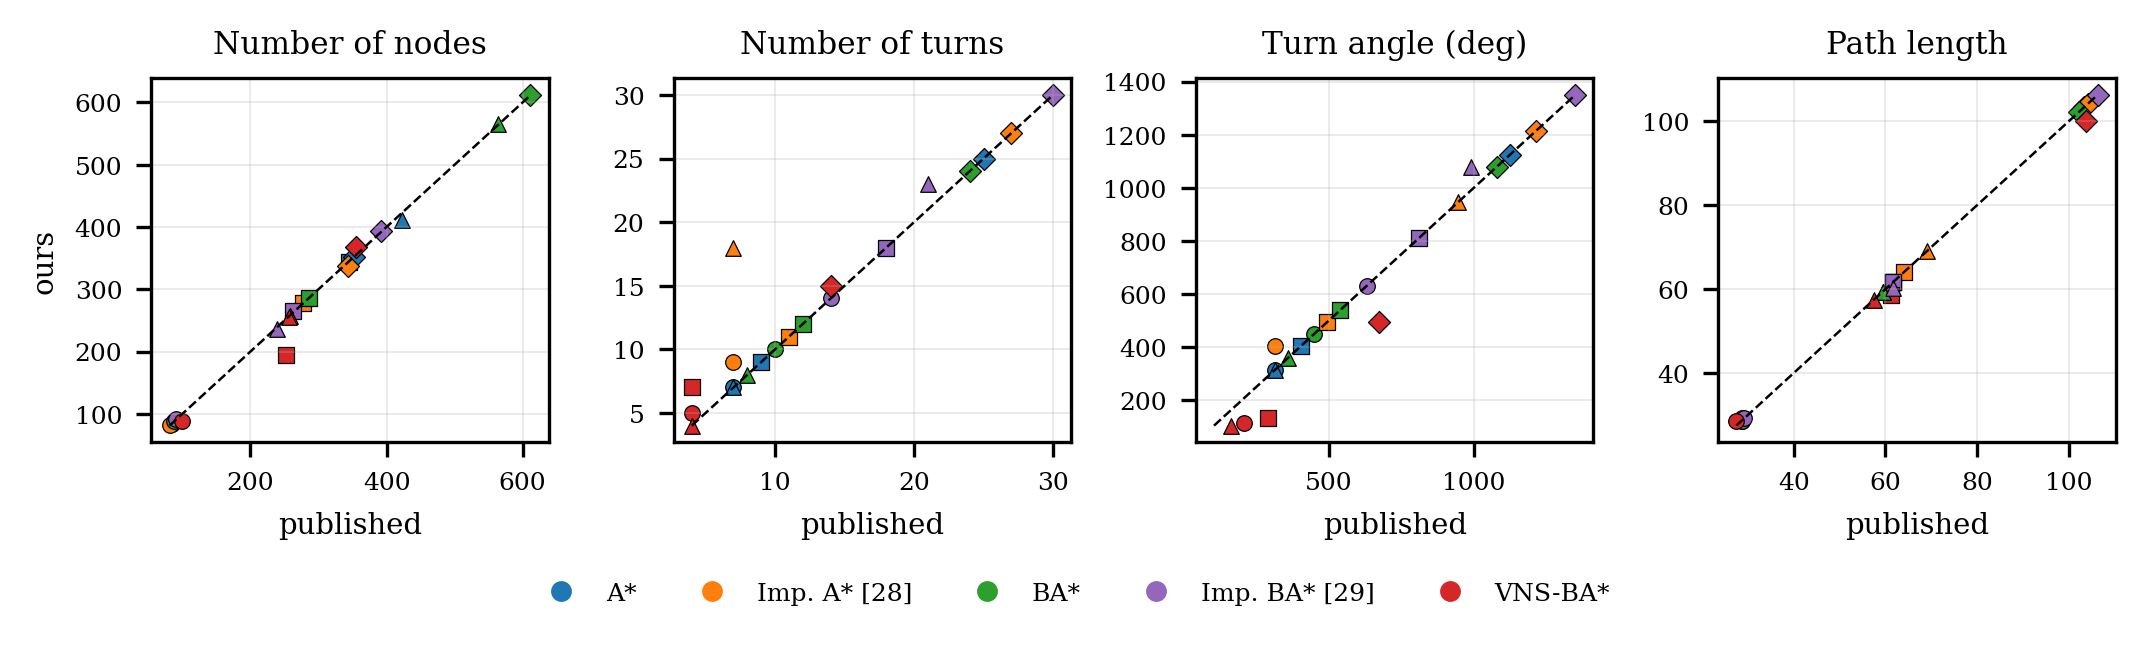

report_fig_fair_comparison


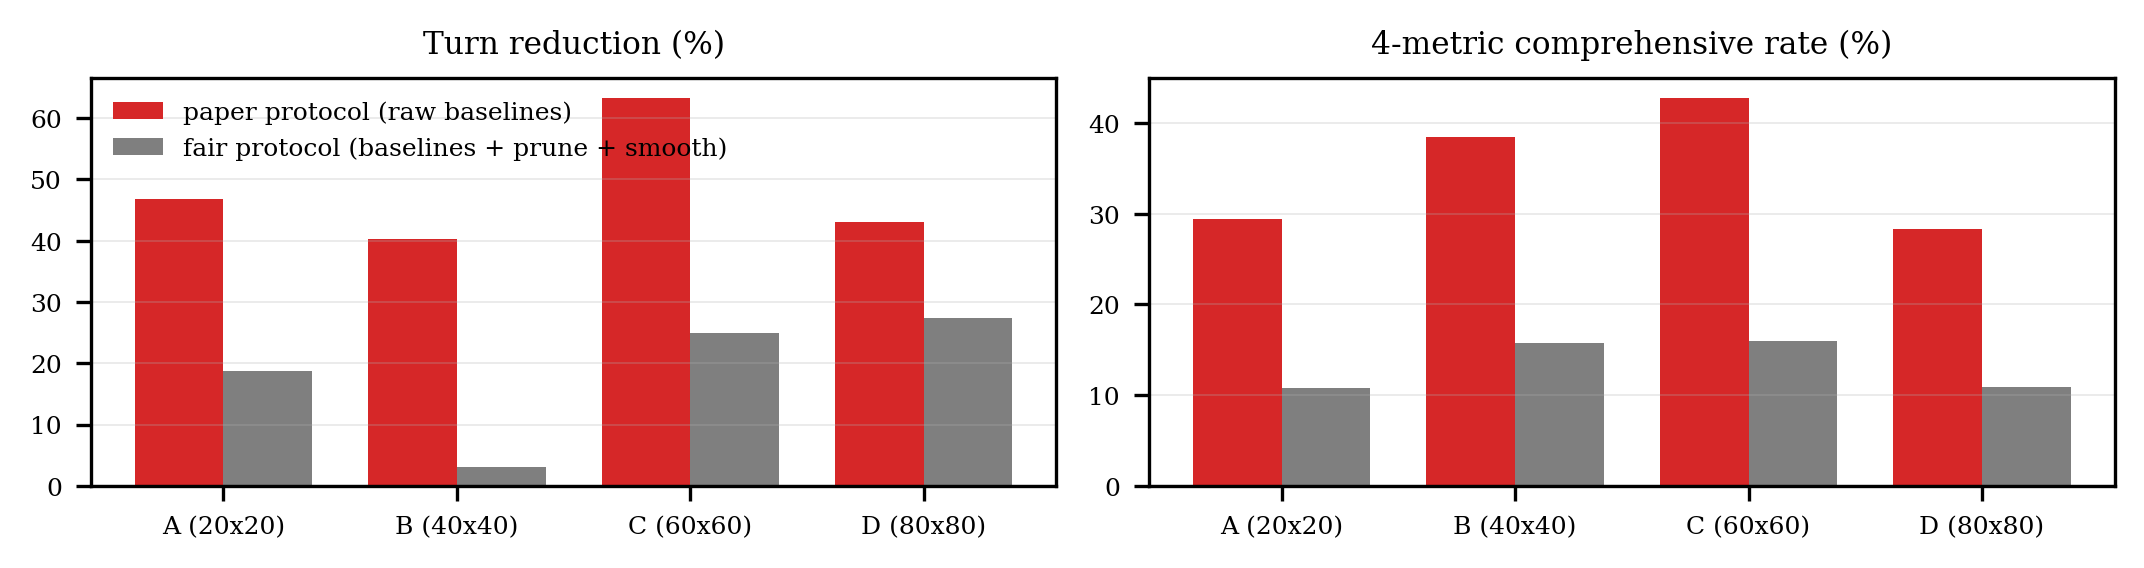

report_fig_random_maps


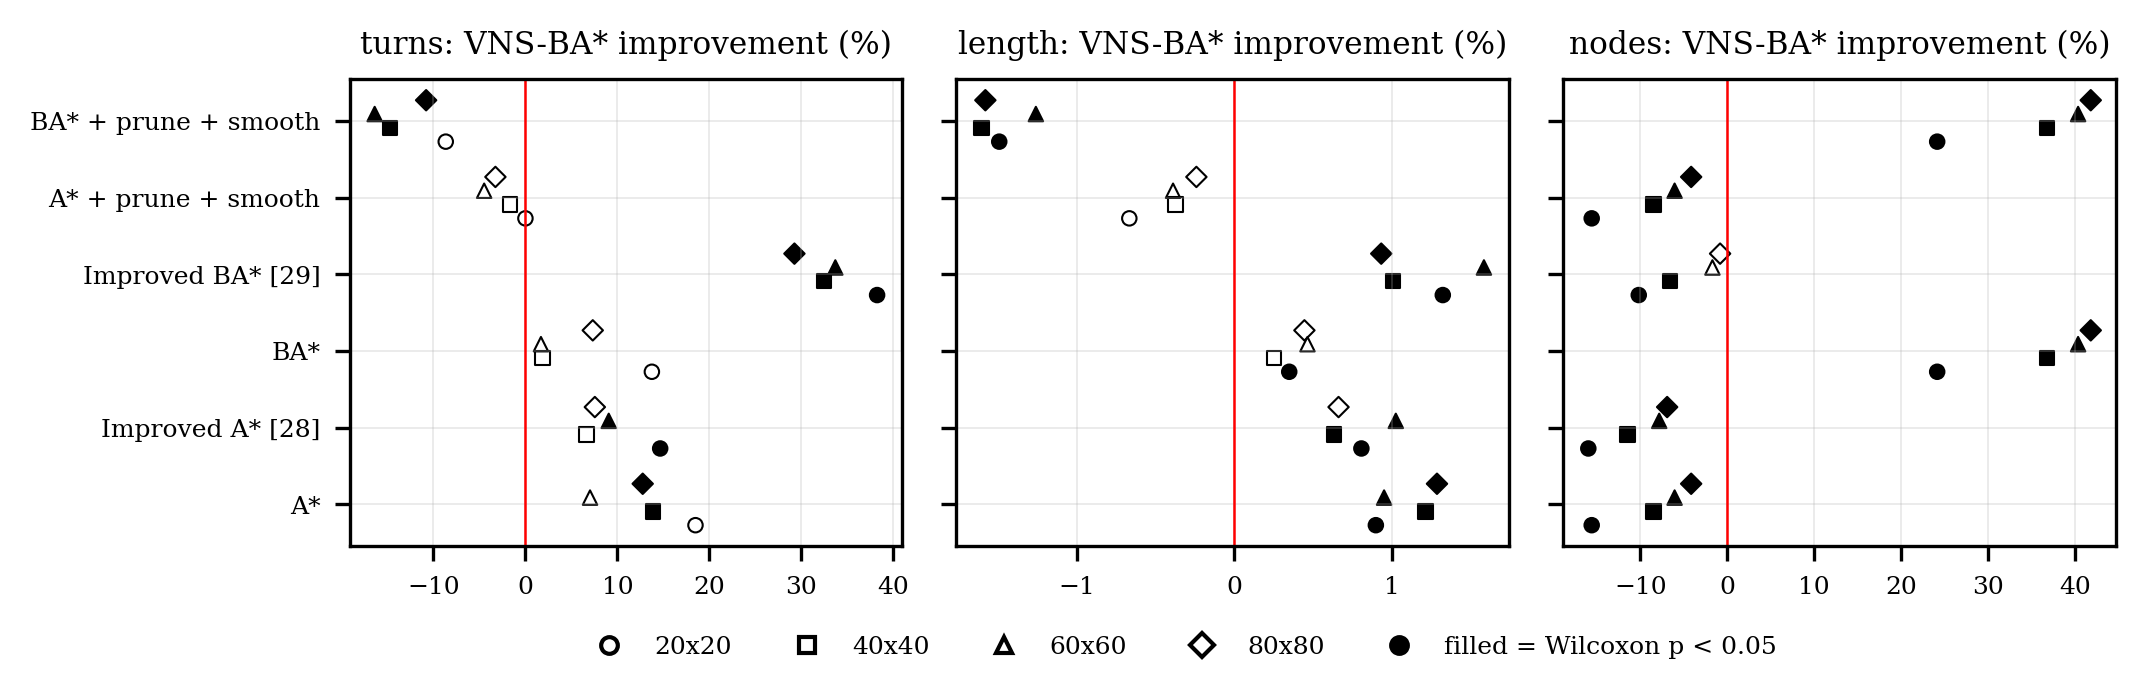

report_fig_ablation


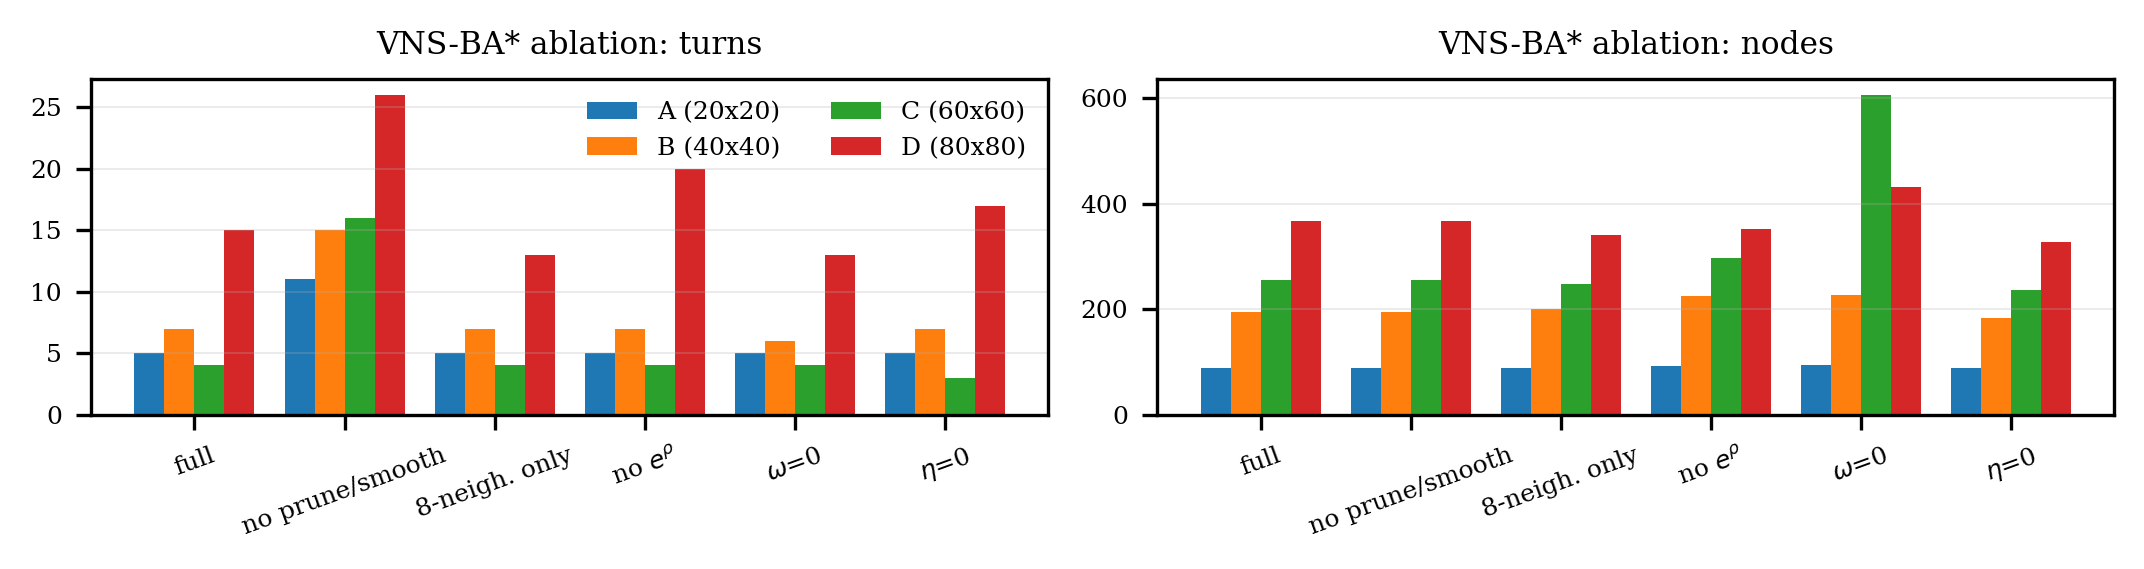

report_fig_timing


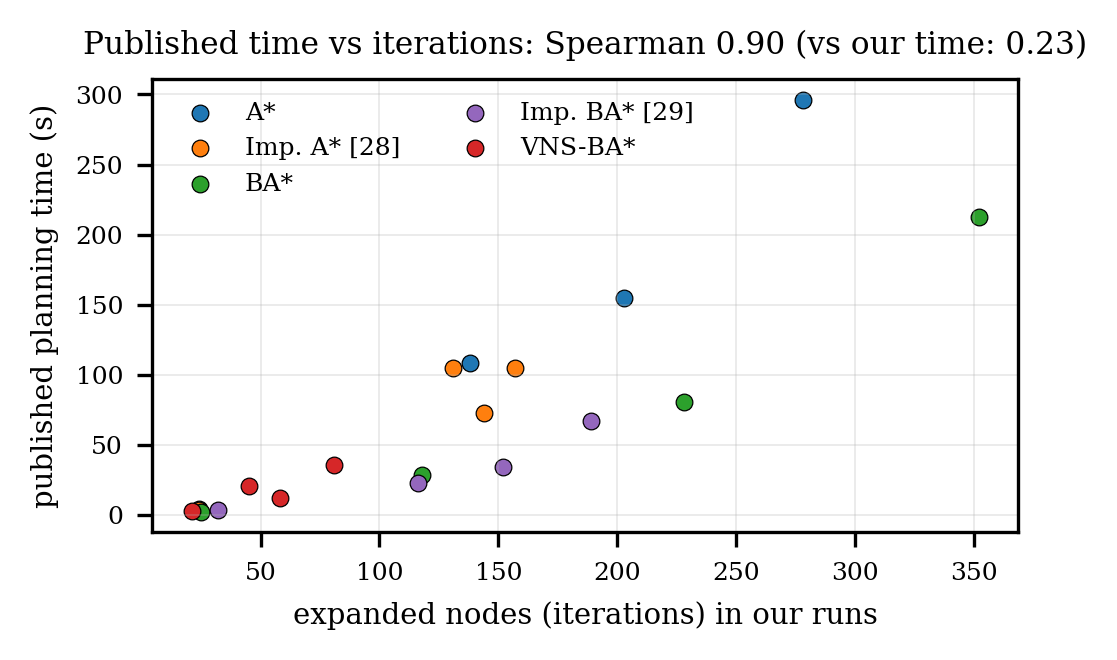

In [95]:
for name in ["report_fig_published_vs_ours", "report_fig_fair_comparison", "report_fig_random_maps",
             "report_fig_ablation", "report_fig_timing"]:
    print(name); display(Image(filename=str(PROJECT_ROOT / "results/figures" / f"{name}.png"), width=900 if "timing" not in name else 450))

In [96]:
tex = (PROJECT_ROOT / "results/phase5/report_tables.tex").read_text()
print(f"results/phase5/report_tables.tex: {len(tex.splitlines())} lines, tables: {tex.count('begin{table')}")
print(tex[:1500])

results/phase5/report_tables.tex: 69 lines, tables: 6
% Auto-generated by experiments/final_analysis.py - requires \usepackage{booktabs}

\begin{table*}[t]\centering\caption{VNS-BA* on the reconstructed maps: published values vs our re-implementation.}
\label{tab:vns}\begin{tabular}{lrrrrrrrrrr}\toprule
 & \multicolumn{2}{c}{Nodes} & \multicolumn{2}{c}{Turns} & \multicolumn{2}{c}{Turn angle ($^\circ$)} & \multicolumn{2}{c}{Length} & \multicolumn{2}{c}{Time} \\
Map & Paper & Ours & Paper & Ours & Paper & Ours & Paper & Ours & Paper (s) & Ours (ms) \\\midrule
A (20x20) & 100 & 89 & 4 & 5 & 209.0 & 114.9 & 27.48 & 28.53 & 2.55 & 4.6$\pm$0.4 \\
B (40x40) & 252 & 195 & 4 & 7 & 289.8 & 132.2 & 61.26 & 58.60 & 20.42 & 12.2$\pm$0.6 \\
C (60x60) & 257 & 255 & 4 & 4 & 163.1 & 104.0 & 57.52 & 57.37 & 12.33 & 14.2$\pm$1.1 \\
D (80x80) & 355 & 368 & 14 & 15 & 673.0 & 496.3 & 103.70 & 99.95 & 35.34 & 35.2$\pm$2.3 \\
\bottomrule\end{tabular}\end{table*}

\begin{table}[t]\centering\caption{Assignment 

**Figures available for the report** (all in `results/figures/`):

| Report section | Figure |
|---|---|
| Dataset & preprocessing | `phase2_overlay_map_*.png` (reconstruction vs paper), `phase2_tuning_maps.png` |
| Methodology | `phase3_fig1_neighbourhood.png`, `phase3_pruning_smoothing.png` |
| Results | `phase3_map_*_five_planners.png`, `report_fig_published_vs_ours.png`, `phase4_E3_table6.png` |
| Critical analysis | `report_fig_fair_comparison.png`, `report_fig_ablation.png`, `report_fig_random_maps.png`, `report_fig_timing.png` |

---
## 5.8 Written analysis and README

In [97]:
c = R["claims"].set_index("id")
b = R["base"]
w = rtest.set_index(["size", "compared_to", "metric"])
doc = f'''# Critical Analysis of the Reproduction ({RUN_DATE})

**Article:** P. Li, Y. Li, X. Dai, "VNS-BA*: An Improved Bidirectional A* Path Planning Algorithm Based on Variable Neighborhood Search," *Sensors*, 24(21), 6929, 2024.

## 1. Results (Assignment Sec. 5)
| Evaluation metric (mean of Maps A-D, VNS-BA*) | Published | Ours | Difference |
|---|---|---|---|
''' + "\n".join(f"| {r.metric} | {r.published:.3f} | {r.ours:.3f} | {r.difference:+.3f} ({r.difference_pct:+.1f} %) |" for r in R["headline"].itertuples()) + '''

| Improvement ratio of VNS-BA* (mean of 16 comparisons) | Published | Ours | Difference |
|---|---|---|---|
''' + "\n".join(f"| {r.metric} | {r.published:.2f} | {r.ours:.2f} | {r.difference:+.2f} |" for r in R["impr"].itertuples()) + f'''

Baselines: exact length in {int(b.length_exact.sum())}/16 and exact turns in {int(b.turns_exact.sum())}/16 algorithm-map cells, median node error {b.nodes_err_pct.abs().median():.2f} %.

## 2. Verdict
**(A) Comparable** for the path-quality and search-effort metrics in the paper's protocol (nodes {R["headline"].iloc[0].difference_pct:+.1f} %, length {R["headline"].iloc[3].difference_pct:+.1f} %, turns +0 to +3 per map); the paper's relative claims on turns, turn angle and nodes are reproduced (Table 6: fewer turns in {(t6.turns>0).sum()}/16 comparisons).
Qualifications: (i) the lower turn angle ({R["headline"].iloc[2].difference_pct:+.1f} %) is a measurement-point effect, not an improvement; (ii) the planning-time claim is **not reproduced** and is implementation-dependent; (iii) under a **fair protocol** (same pruning + smoothing for all methods) the turn advantage falls from {t6.turns.mean():.1f} % to {fair.turns.mean():.1f} %, and BA* + post-processing is significantly better than VNS-BA* in turns on 80x80 random maps ({w.loc[(80,"BA* + prune + smooth","turns"),"mean_improvement_pct"]:+.1f} %, p = {w.loc[(80,"BA* + prune + smooth","turns"),"wilcoxon_p"]:.3f}) and in length ({w.loc[(80,"BA* + prune + smooth","length"),"mean_improvement_pct"]:+.1f} %, p = {w.loc[(80,"BA* + prune + smooth","length"),"wilcoxon_p"]:.1e}). The genuine benefit of the search is fewer nodes than plain BA* ({w.loc[(80,"BA*","nodes"),"mean_improvement_pct"]:+.1f} % on 80x80, p = {w.loc[(80,"BA*","nodes"),"wilcoxon_p"]:.1e}).

## 3. Claim verification
''' + "\n".join(f"- **{i}** {r.claim}: published {r.published}; ours {r.ours} -> **{r.verdict}**. {r.why}" for i, r in c.iterrows()) + f'''

## 4. Justification
**Dataset.** No data released; maps reconstructed from Figs. 3, 8-11; validated by 5-copy agreement (>= 99.98 %), stated density, and exact equality of optimal and published grid lengths on all four maps. Tuning maps have no cross-check.
**Settings / parameters.** omega = eta = 0.5 as in the paper; three details calibrated from baseline numbers only (Manhattan heuristic, nodes = generated, Fig. 4 meeting rule); remaining VNS-BA* details chosen by us; sensitivity < 1 % length, 0 turns, <= ~6 % nodes.
**Randomness.** All planners deterministic (identical metrics on repeated runs); timing median of 30 runs; 120 seeded random maps with Wilcoxon tests for statistics the paper lacks.
**Software / resources.** MATLAB R2018b (paper, hardware unreported) vs Python 3 / NumPy on a CPU. Published times are {1000*(main.pub_time_s/main.expanded).min():.0f}-{1000*(main.pub_time_s/main.expanded).max():.0f} ms per iteration and correlate with iteration counts (Spearman {tcorr[(tcorr.predictor=="expanded")&(tcorr.scope=="all 20 cells")].spearman.iloc[0]:.2f}), not with computational work ({tcorr[(tcorr.predictor=="time_s")&(tcorr.scope=="all 20 cells")].spearman.iloc[0]:.2f}).
**Missing / ambiguous details.** {len(reg)} register entries ({int((reg.impact_on_reproduction=="High").sum())} high impact): rho, extension cost, f re-evaluation, P1-P4, spline boundary conditions (Eq. 11 under-determined and duplicated), metric measurement points, timing protocol; plus reporting errors in Tables 4, 6 and Fig. 12.
**Deviations.** Python; reconstructed maps; parametric natural spline; baselines re-implemented from refs. [28], [29]; added fair comparison, ablation and random-map statistics.

## 5. Limitations of this reproduction
- VNS-BA* internals not specified by the paper had to be chosen; the reproduction of VNS-BA* is therefore approximate, while the baselines are exact.
- Times are not comparable with the paper; only iteration counts are implementation-independent.
- Random maps use i.i.d. obstacles, which differ from the structured maps of the paper.
- Tuning maps could not be cross-validated.
'''
(PROJECT_ROOT / "docs" / "critical_analysis.md").write_text(doc)
display(Markdown(doc))

# Critical Analysis of the Reproduction (2026-10-23)

**Article:** P. Li, Y. Li, X. Dai, "VNS-BA*: An Improved Bidirectional A* Path Planning Algorithm Based on Variable Neighborhood Search," *Sensors*, 24(21), 6929, 2024.

## 1. Results (Assignment Sec. 5)
| Evaluation metric (mean of Maps A-D, VNS-BA*) | Published | Ours | Difference |
|---|---|---|---|
| Number of nodes | 241.000 | 226.750 | -14.250 (-5.9 %) |
| Number of turns | 6.500 | 7.750 | +1.250 (+19.2 %) |
| Turn angle (deg) | 333.703 | 211.860 | -121.843 (-36.5 %) |
| Path length | 62.489 | 61.113 | -1.376 (-2.2 %) |
| Planning time (s) | 17.662 | 0.017 | -17.645 (-99.9 %) |

| Improvement ratio of VNS-BA* (mean of 16 comparisons) | Published | Ours | Difference |
|---|---|---|---|
| Mean improvement in number of nodes (%) | 7.89 | 14.74 | +6.86 |
| Mean improvement in number of turns (%) | 55.29 | 48.37 | -6.92 |
| Mean improvement in turn angle (deg) (%) | 51.39 | 71.31 | +19.92 |
| Mean improvement in path length (%) | 3.19 | 4.52 | +1.33 |
| Mean comprehensive rate, 4 metrics (%) | 29.44 | 34.74 | +5.30 |
| Mean comprehensive rate, Fig. 12 / 5 metrics (%) | 34.82 | -345.31 | -380.13 |

Baselines: exact length in 14/16 and exact turns in 13/16 algorithm-map cells, median node error 0.54 %.

## 2. Verdict
**(A) Comparable** for the path-quality and search-effort metrics in the paper's protocol (nodes -5.9 %, length -2.2 %, turns +0 to +3 per map); the paper's relative claims on turns, turn angle and nodes are reproduced (Table 6: fewer turns in 16/16 comparisons).
Qualifications: (i) the lower turn angle (-36.5 %) is a measurement-point effect, not an improvement; (ii) the planning-time claim is **not reproduced** and is implementation-dependent; (iii) under a **fair protocol** (same pruning + smoothing for all methods) the turn advantage falls from 48.4 % to 18.6 %, and BA* + post-processing is significantly better than VNS-BA* in turns on 80x80 random maps (-10.8 %, p = 0.014) and in length (-1.6 %, p = 3.0e-05). The genuine benefit of the search is fewer nodes than plain BA* (+41.8 % on 80x80, p = 2.3e-06).

## 3. Claim verification
- **C1** Turn-point reduction > 40 % in all scenarios (max 80.96 %): published 41.67-80.96 %; ours 22.22-82.61 %; > 40 % in 11/16 -> **Partially reproduced**. Large reductions everywhere, but 5 of 16 ratios are below 40 % (min 22 %).
- **C2** Turn-angle reduction between 28.44 % and 83.53 %: published 28.44-83.53 %; ours 54.05-90.37 % -> **Reproduced (higher)**. All 16 ratios positive and larger; depends on the turn-angle measurement point (A21).
- **C3** Planning time notably better than unidirectional, some gain over bidirectional: published 29.0-95.8 % vs uni; -18.5-94.2 % vs bi; ours -875 % or worse vs uni; -559 % or worse vs bi -> **Not reproduced (implementation-dependent)**. VNS-BA* is slowest per run in our code; published times follow iterations (Spearman 0.90), and VNS-BA* has the fewest iterations (see E6).
- **C4** Negative node optimisation on the simple map, improving with map size: published Map A: -23.5 to -9.9 %; ours Map A: -8.5 to 3.3 %; Maps C/D within 1-2 pts of paper vs BA* -> **Reproduced**. Map A ratios negative in 3/4 (paper 4/4) and positive on the larger maps vs BA*; node ratios on Maps C, D are within a few points of the paper.
- **C5** Comprehensive optimisation rate > 30 % on Maps B, C, D: published 30.57-51.04 %; ours 4 metrics: 23.57-46.12 % (> 30 % in 10/12); with time: negative -> **Partially reproduced**. Holds without the time metric for Maps B, C and 2 of 4 comparisons on D; time makes it negative.
- **C6** omega = eta = 0.5 minimises nodes and search time: published minimum at 0.5 (78 nodes); ours minimum at omega=0.6 (83.50); 0.5 gives 86.25 -> **Partially reproduced**. Same U-shape; 0.5 is near-optimal (within ~3 %) but not the minimum.
- **C7** Gains are due to the proposed method (implicit in the comparison design): published not tested (post-processing only for VNS-BA*); ours fair: mean turn gain 18.6 % (vs 48.4 %); BA*+prune+smooth better in turns at 80x80 (-10.8 %, p=0.014) -> **Not supported**. Turn/angle gains come mainly from pruning + smoothing; the search mainly saves nodes vs BA*.
- **C8** Proposed pruning removes more redundant turns than Huang et al. [27]: published 6 -> 4 turns vs 6 -> 5 (one illustrative path); ours 372 paths: equal turns in 94.6 %, fewer in 4.0 %, more in 1.3 %; mean 14.63 vs 14.66 -> **Not confirmed (marginal)**. Both pruning methods remove almost the same turns; the mean advantage is 0.2 %.
- **C9** Alternating bidirectional search of [26] produces more turns (zig-zag) than the proposed heuristic: published qualitative (Fig. 2b vs 2c); ours raw search paths, 124 maps: 20.93 vs 20.54 turns (Wilcoxon p=0.95); paper maps mixed -> **Not confirmed**. No significant difference in turns; VNS-BA* better on Maps A, B, worse on C, D.

## 4. Justification
**Dataset.** No data released; maps reconstructed from Figs. 3, 8-11; validated by 5-copy agreement (>= 99.98 %), stated density, and exact equality of optimal and published grid lengths on all four maps. Tuning maps have no cross-check.
**Settings / parameters.** omega = eta = 0.5 as in the paper; three details calibrated from baseline numbers only (Manhattan heuristic, nodes = generated, Fig. 4 meeting rule); remaining VNS-BA* details chosen by us; sensitivity < 1 % length, 0 turns, <= ~6 % nodes.
**Randomness.** All planners deterministic (identical metrics on repeated runs); timing median of 30 runs; 120 seeded random maps with Wilcoxon tests for statistics the paper lacks.
**Software / resources.** MATLAB R2018b (paper, hardware unreported) vs Python 3 / NumPy on a CPU. Published times are 86-1066 ms per iteration and correlate with iteration counts (Spearman 0.90), not with computational work (0.23).
**Missing / ambiguous details.** 28 register entries (4 high impact): rho, extension cost, f re-evaluation, P1-P4, spline boundary conditions (Eq. 11 under-determined and duplicated), metric measurement points, timing protocol; plus reporting errors in Tables 4, 6 and Fig. 12.
**Deviations.** Python; reconstructed maps; parametric natural spline; baselines re-implemented from refs. [28], [29]; added fair comparison, ablation and random-map statistics.

## 5. Limitations of this reproduction
- VNS-BA* internals not specified by the paper had to be chosen; the reproduction of VNS-BA* is therefore approximate, while the baselines are exact.
- Times are not comparable with the paper; only iteration counts are implementation-independent.
- Random maps use i.i.d. obstacles, which differ from the structured maps of the paper.
- Tuning maps could not be cross-validated.


In [98]:
readme_p = PROJECT_ROOT / "README.md"
txt = readme_p.read_text()
txt = txt.replace("| 5 | Comparison & critical analysis | pending |", "| 5 | Comparison, verdict & critical analysis | done |")
hd = R["headline"]
res_md = "## Results\n**Verdict: (A) comparable** path quality and search effort; time claim not reproduced; gains mostly due to post-processing under a fair protocol. Full analysis: `docs/critical_analysis.md`.\n\n| Metric (VNS-BA*, mean Maps A-D) | Published | Ours | Difference |\n|---|---|---|---|\n" + \
    "\n".join(f"| {r.metric} | {r.published:.3f} | {r.ours:.3f} | {r.difference_pct:+.1f} % |" for r in hd.itertuples())
if "## Results\n_To be added in Phase 5._" in txt:
    txt = txt.replace("## Results\n_To be added in Phase 5._", res_md)
elif "**Verdict:" not in txt:
    txt += "\n" + res_md + "\n"
readme_p.write_text(txt)
print("written: README.md (Results section)")

written: README.md (Results section)


---
# Outputs of the study
| Item | Location |
|---|---|
| Source code | `src/`, `experiments/`, `tests/` |
| Execution instructions | `README.md` |
| Required packages | `requirements.txt` |
| Dataset (reconstructed maps) and description | `maps/`, `maps/README.md`, `experiments/build_maps.py` |
| Configuration and parameters | `configs/params.yaml`, `docs/ambiguity_register.csv` |
| Experimental results | `results/phase2` – `results/phase5` |
| Figures | `results/figures/` |
| Source-code availability evidence | `evidence/` |
| Critical analysis | `docs/critical_analysis.md` |
| Technical report | `report/` (IEEE format, PDF and Word) |